In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/shristibose/crime-dataset/Crime_Data_from_2010_to_2019_20260318.csv
/kaggle/input/datasets/shristibose/crime-dataset/Crimes_-_2001_to_Present_20260318.csv
/kaggle/input/datasets/shristibose/new-york-dataset/NYPD_Complaint_Data_Historic_20260327.csv


In [2]:
# CELL 1 — Install / Import Requirements


# If running on Kaggle, most packages are already available.
# Uncomment if needed:
# !pip install shap pmdarima xgboost --quiet

import os
import gc
import json
import math
import random
import warnings
import itertools
from collections import defaultdict

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    matthews_corrcoef, cohen_kappa_score,
    mean_squared_error, mean_absolute_error, median_absolute_error, r2_score,
    explained_variance_score
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier

from xgboost import XGBClassifier

import shap
import joblib

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    import pmdarima as pm
    PMDARIMA_AVAILABLE = True
except Exception:
    PMDARIMA_AVAILABLE = False

import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Dense, Dropout, LSTM, GRU, Conv1D, GlobalAveragePooling1D,
    LayerNormalization, MultiHeadAttention, Add
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("All imports ready.")


2026-04-03 20:43:45.573106: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775249025.804417      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775249025.871099      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775249026.417358      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775249026.417401      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775249026.417404      23 computation_placer.cc:177] computation placer alr

All imports ready.


In [3]:
# CELL 2 — Output Directories


BASE_OUT = "/kaggle/working/crime_project_outputs"
PLOT_DIR = os.path.join(BASE_OUT, "plots")
TABLE_DIR = os.path.join(BASE_OUT, "tables")
MODEL_DIR = os.path.join(BASE_OUT, "models")
REPORT_DIR = os.path.join(BASE_OUT, "reports")

for folder in [BASE_OUT, PLOT_DIR, TABLE_DIR, MODEL_DIR, REPORT_DIR]:
    os.makedirs(folder, exist_ok=True)

for city in ["chicago", "los_angeles", "new_york"]:
    for sub in ["plots", "tables", "models", "reports"]:
        os.makedirs(os.path.join(BASE_OUT, city, sub), exist_ok=True)

print("Folders created successfully.")


Folders created successfully.


In [4]:
# CELL 3 — Dataset Paths


CHICAGO_PATH = "/kaggle/input/datasets/shristibose/crime-dataset/Crimes_-_2001_to_Present_20260318.csv"
LA_PATH      = "/kaggle/input/datasets/shristibose/crime-dataset/Crime_Data_from_2010_to_2019_20260318.csv"
NYC_PATH     = "/kaggle/input/datasets/shristibose/new-york-dataset/NYPD_Complaint_Data_Historic_20260327.csv"

print(CHICAGO_PATH)
print(LA_PATH)
print(NYC_PATH)


/kaggle/input/datasets/shristibose/crime-dataset/Crimes_-_2001_to_Present_20260318.csv
/kaggle/input/datasets/shristibose/crime-dataset/Crime_Data_from_2010_to_2019_20260318.csv
/kaggle/input/datasets/shristibose/new-york-dataset/NYPD_Complaint_Data_Historic_20260327.csv


In [5]:
# CELL 4 — Read Raw Data


df_chi_raw = pd.read_csv(CHICAGO_PATH)
df_la_raw  = pd.read_csv(LA_PATH)
df_nyc_raw = pd.read_csv(NYC_PATH)

print("Chicago raw shape:", df_chi_raw.shape)
print("LA raw shape:", df_la_raw.shape)
print("NYC raw shape:", df_nyc_raw.shape)


Chicago raw shape: (8513457, 22)
LA raw shape: (2133137, 28)
NYC raw shape: (9491946, 35)


In [6]:
# CELL 5 — Standardize Columns Across All 3 Datasets


def standardize_chicago(df):
    out = df[["Date", "Primary Type", "Latitude", "Longitude", "District"]].copy()
    out.columns = ["date", "crime_type", "lat", "lon", "area"]
    out["city"] = "Chicago"
    return out


def standardize_la(df):
    out = df[["DATE OCC", "Crm Cd Desc", "LAT", "LON", "AREA NAME"]].copy()
    out.columns = ["date", "crime_type", "lat", "lon", "area"]
    out["city"] = "Los_Angeles"
    return out


def standardize_nyc(df):
    df = df.copy()
    df.columns = [c.lower() for c in df.columns]
    rename_map = {
        "cmplnt_fr_dt": "date",
        "ofns_desc": "crime_type",
        "latitude": "lat",
        "longitude": "lon",
        "boro_nm": "area"
    }
    df = df.rename(columns=rename_map)
    out = df[["date", "crime_type", "lat", "lon", "area"]].copy()
    out["city"] = "New_York"
    return out


df_chi = standardize_chicago(df_chi_raw)
df_la  = standardize_la(df_la_raw)
df_nyc = standardize_nyc(df_nyc_raw)

print(df_chi.head())
print(df_la.head())
print(df_nyc.head())


                     date crime_type        lat        lon  area     city
0  03/09/2026 12:00:00 AM    BATTERY  41.865381 -87.717831  10.0  Chicago
1  03/09/2026 12:00:00 AM    ASSAULT        NaN        NaN  15.0  Chicago
2  03/09/2026 12:00:00 AM    ROBBERY  41.851997 -87.688782  10.0  Chicago
3  03/09/2026 12:00:00 AM   BURGLARY  41.755963 -87.552318   4.0  Chicago
4  03/09/2026 12:00:00 AM    ASSAULT  41.958286 -87.742637  17.0  Chicago
                      date                                         crime_type  \
0  2010 Feb 20 12:00:00 AM                           VIOLATION OF COURT ORDER   
1  2010 Sep 12 12:00:00 AM  VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...   
2  2010 Aug 09 12:00:00 AM                          OTHER MISCELLANEOUS CRIME   
3  2010 Jan 05 12:00:00 AM                           VIOLATION OF COURT ORDER   
4  2010 Jan 02 12:00:00 AM                                    RAPE, ATTEMPTED   

       lat       lon       area         city  
0  33.9825 -118.2695  

In [7]:
# CELL 6 — Common Preprocessing Function (STRICT NYC DATE FIX)

def parse_dates_citywise(date_series, city_name):
    s = date_series.astype(str).str.strip()

    if city_name == "Chicago":
        dt = pd.to_datetime(s, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
        if dt.isna().mean() > 0.10:
            dt = pd.to_datetime(s, errors="coerce")

    elif city_name == "Los_Angeles":
        dt = pd.to_datetime(s, format="%Y %b %d %I:%M:%S %p", errors="coerce")
        if dt.isna().mean() > 0.10:
            dt = pd.to_datetime(s, errors="coerce")

    elif city_name == "New_York":
        # NYC complaint date should be a pure calendar date
        dt = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")

        # If anything weird still remains, try generic parse only on failed rows
        bad_mask = dt.isna()
        if bad_mask.any():
            dt2 = pd.to_datetime(s[bad_mask], errors="coerce")
            dt.loc[bad_mask] = dt2

        # HARD FILTER: remove impossible / accidental parsed historical dates
        # This is the key fix for the 1900 issue.
        dt = dt.where((dt.dt.year >= 2000) & (dt.dt.year <= 2025))

    else:
        dt = pd.to_datetime(s, errors="coerce")

    return dt


def common_preprocess(df, city_name):
    df = df.copy()

    df["date"] = parse_dates_citywise(df["date"], city_name)

    # Basic cleaning
    df = df.dropna(subset=["date", "crime_type", "lat", "lon"])

    # Remove obvious invalid coordinates
    df = df[(df["lat"] != 0) & (df["lon"] != 0)]

    # City-specific bounding boxes
    if city_name == "Chicago":
        df = df[(df["lat"].between(41.0, 42.5)) & (df["lon"].between(-88.5, -87.0))]
    elif city_name == "Los_Angeles":
        df = df[(df["lat"].between(33.3, 34.9)) & (df["lon"].between(-119.0, -117.0))]
    elif city_name == "New_York":
        df = df[(df["lat"].between(40.4, 41.0)) & (df["lon"].between(-74.3, -73.6))]

    # Time features
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day
    df["hour"] = df["date"].dt.hour.fillna(0).astype(int)
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_name"] = df["date"].dt.day_name()
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
    df["year_month"] = df["date"].dt.to_period("M").astype(str)
    df["date_only"] = pd.to_datetime(df["date"].dt.date)

    # Label cleaning
    df["crime_type"] = df["crime_type"].astype(str).str.strip().str.upper()
    df["area"] = df["area"].astype(str).str.strip()

    # Final city-specific sanity filter on year
    if city_name == "New_York":
        df = df[df["year"].between(2000, 2025)]

    return df.reset_index(drop=True)


df_chi = common_preprocess(df_chi, "Chicago")
df_la  = common_preprocess(df_la, "Los_Angeles")
df_nyc = common_preprocess(df_nyc, "New_York")

print("Chicago cleaned:", df_chi.shape, df_chi["date_only"].min(), "to", df_chi["date_only"].max())
print("LA cleaned:", df_la.shape, df_la["date_only"].min(), "to", df_la["date_only"].max())
print("NYC cleaned:", df_nyc.shape, df_nyc["date_only"].min(), "to", df_nyc["date_only"].max())

Chicago cleaned: (8417844, 15) 2001-01-01 00:00:00 to 2026-03-09 00:00:00
LA cleaned: (2132229, 15) 2010-01-01 00:00:00 to 2019-12-31 00:00:00
NYC cleaned: (9488208, 15) 2000-01-01 00:00:00 to 2024-12-31 00:00:00


In [8]:
# CELL 7 — Save Dataset Summaries

def save_dataset_summary(df, city_key):
    city_report = os.path.join(BASE_OUT, city_key, "reports")
    city_table  = os.path.join(BASE_OUT, city_key, "tables")

    summary = {
        "shape": df.shape,
        "date_min": str(df["date"].min()),
        "date_max": str(df["date"].max()),
        "n_crime_types": int(df["crime_type"].nunique()),
        "n_areas": int(df["area"].nunique()),
        "lat_min": float(df["lat"].min()),
        "lat_max": float(df["lat"].max()),
        "lon_min": float(df["lon"].min()),
        "lon_max": float(df["lon"].max())
    }

    with open(os.path.join(city_report, f"{city_key}_dataset_summary.json"), "w") as f:
        json.dump(summary, f, indent=2)

    df.head(20).to_csv(os.path.join(city_table, f"{city_key}_head.csv"), index=False)
    df.describe(include="all").to_csv(os.path.join(city_table, f"{city_key}_describe.csv"))

save_dataset_summary(df_chi, "chicago")
save_dataset_summary(df_la, "los_angeles")
save_dataset_summary(df_nyc, "new_york")

print("Dataset summaries saved.")


Dataset summaries saved.


# *PART 1 — EDA FOR ALL THREE DATASETS*

In [9]:
# CELL 8 — Common EDA Helper Functions

def plot_yearly_trend(df, city_key, city_title):
    yearly = df.groupby("year").size().reset_index(name="crime_count")
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=yearly, x="year", y="crime_count", marker="o")
    plt.title(f"{city_title} — Yearly Crime Trend", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_yearly_trend.png"), dpi=300)
    plt.show()
    yearly.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_yearly_trend.csv"), index=False)


def plot_monthly_distribution(df, city_key, city_title):
    month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    monthly = df.groupby("month").size().reset_index(name="crime_count")
    monthly["month_name"] = monthly["month"].apply(lambda x: month_names[x-1])
    plt.figure(figsize=(10, 5))
    sns.barplot(data=monthly, x="month_name", y="crime_count")
    plt.title(f"{city_title} — Monthly Crime Distribution", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_monthly_distribution.png"), dpi=300)
    plt.show()
    monthly.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_monthly_distribution.csv"), index=False)


def plot_dayofweek_distribution(df, city_key, city_title):
    order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    dow = df["day_name"].value_counts().reindex(order).reset_index()
    dow.columns = ["day_name", "crime_count"]
    plt.figure(figsize=(10, 5))
    sns.barplot(data=dow, x="day_name", y="crime_count")
    plt.xticks(rotation=30)
    plt.title(f"{city_title} — Day-of-Week Crime Distribution", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_dayofweek_distribution.png"), dpi=300)
    plt.show()
    dow.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_dayofweek_distribution.csv"), index=False)


def plot_hourly_distribution(df, city_key, city_title):
    hourly = df.groupby("hour").size().reset_index(name="crime_count")
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=hourly, x="hour", y="crime_count", marker="o")
    plt.title(f"{city_title} — Hourly Crime Pattern", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_hourly_distribution.png"), dpi=300)
    plt.show()
    hourly.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_hourly_distribution.csv"), index=False)


def plot_top_crime_types(df, city_key, city_title, top_n=20):
    top = df["crime_type"].value_counts().head(top_n).reset_index()
    top.columns = ["crime_type", "crime_count"]
    plt.figure(figsize=(12, 7))
    sns.barplot(data=top, y="crime_type", x="crime_count")
    plt.title(f"Top {top_n} Crime Types — {city_title}", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_top{top_n}_crime_types.png"), dpi=300)
    plt.show()
    top.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_top{top_n}_crime_types.csv"), index=False)


def plot_area_distribution(df, city_key, city_title, top_n=20):
    area_counts = df["area"].value_counts().head(top_n).reset_index()
    area_counts.columns = ["area", "crime_count"]
    plt.figure(figsize=(12, 7))
    sns.barplot(data=area_counts, y="area", x="crime_count")
    plt.title(f"Top {top_n} Areas by Crime Count — {city_title}", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_top{top_n}_areas.png"), dpi=300)
    plt.show()
    area_counts.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_top{top_n}_areas.csv"), index=False)


def plot_month_day_heatmap(df, city_key, city_title):
    heat = pd.crosstab(df["month"], df["day_of_week"])
    plt.figure(figsize=(10, 6))
    sns.heatmap(heat, cmap="YlGnBu")
    plt.title(f"{city_title} — Month vs Day-of-Week Heatmap", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_month_day_heatmap.png"), dpi=300)
    plt.show()
    heat.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_month_day_heatmap.csv"))


def plot_year_month_heatmap(df, city_key, city_title):
    heat = pd.crosstab(df["year"], df["month"])
    plt.figure(figsize=(12, 6))
    sns.heatmap(heat, cmap="magma")
    plt.title(f"{city_title} — Year vs Month Heatmap", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_year_month_heatmap.png"), dpi=300)
    plt.show()
    heat.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_year_month_heatmap.csv"))


def plot_weekday_weekend(df, city_key, city_title):
    tmp = df.groupby("is_weekend").size().reset_index(name="crime_count")
    tmp["label"] = tmp["is_weekend"].map({0: "Weekday", 1: "Weekend"})
    plt.figure(figsize=(6, 4))
    sns.barplot(data=tmp, x="label", y="crime_count")
    plt.title(f"{city_title} — Weekday vs Weekend", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_weekday_vs_weekend.png"), dpi=300)
    plt.show()
    tmp.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_weekday_vs_weekend.csv"), index=False)


def plot_spatial_kde(df, city_key, city_title, sample_n=150000):
    tmp = df[["lon", "lat"]].dropna()
    if len(tmp) > sample_n:
        tmp = tmp.sample(sample_n, random_state=SEED)
    plt.figure(figsize=(8, 8))
    sns.kdeplot(data=tmp, x="lon", y="lat", fill=True, cmap="Reds", thresh=0.05)
    plt.title(f"{city_title} — Spatial Crime Density KDE", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_spatial_kde.png"), dpi=300)
    plt.show()


def run_full_eda(df, city_key, city_title):
    plot_yearly_trend(df, city_key, city_title)
    plot_monthly_distribution(df, city_key, city_title)
    plot_dayofweek_distribution(df, city_key, city_title)
    plot_hourly_distribution(df, city_key, city_title)
    plot_top_crime_types(df, city_key, city_title, top_n=20)
    plot_area_distribution(df, city_key, city_title, top_n=20)
    plot_month_day_heatmap(df, city_key, city_title)
    plot_year_month_heatmap(df, city_key, city_title)
    plot_weekday_weekend(df, city_key, city_title)
    plot_spatial_kde(df, city_key, city_title)


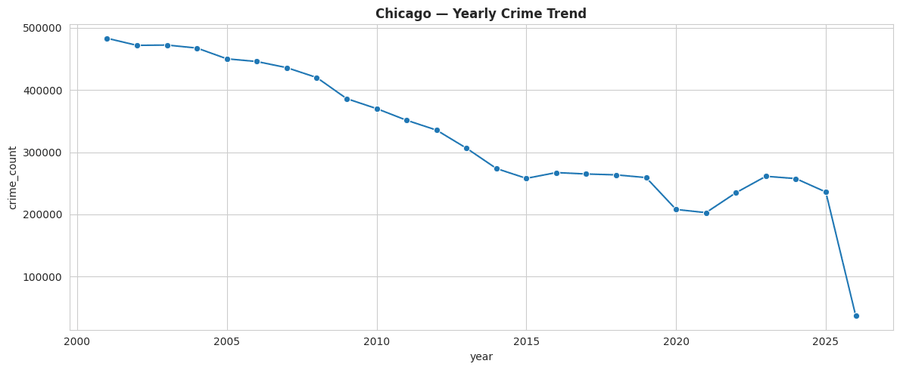

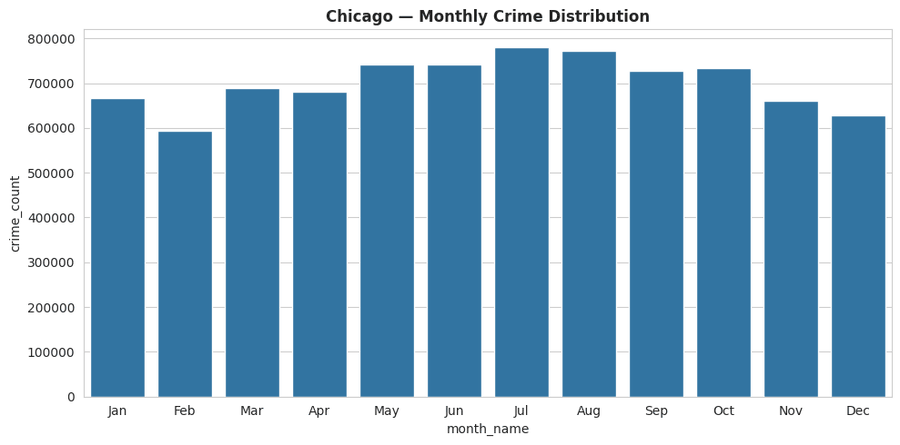

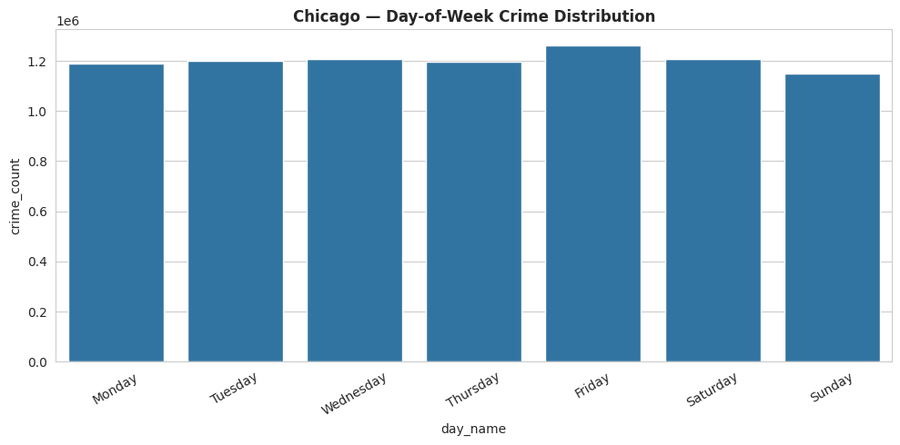

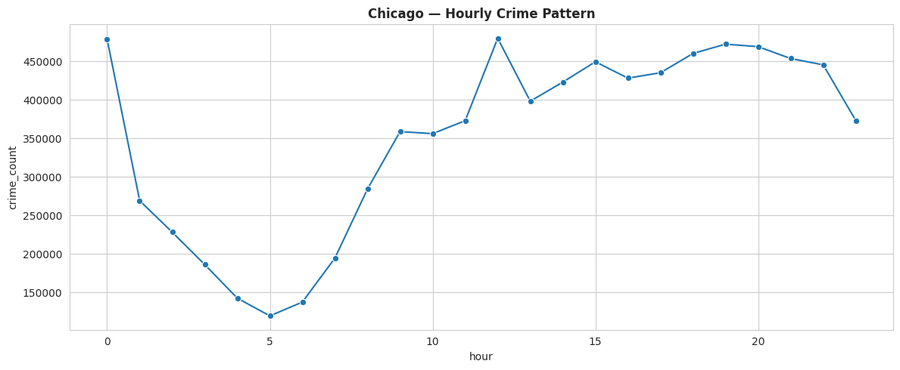

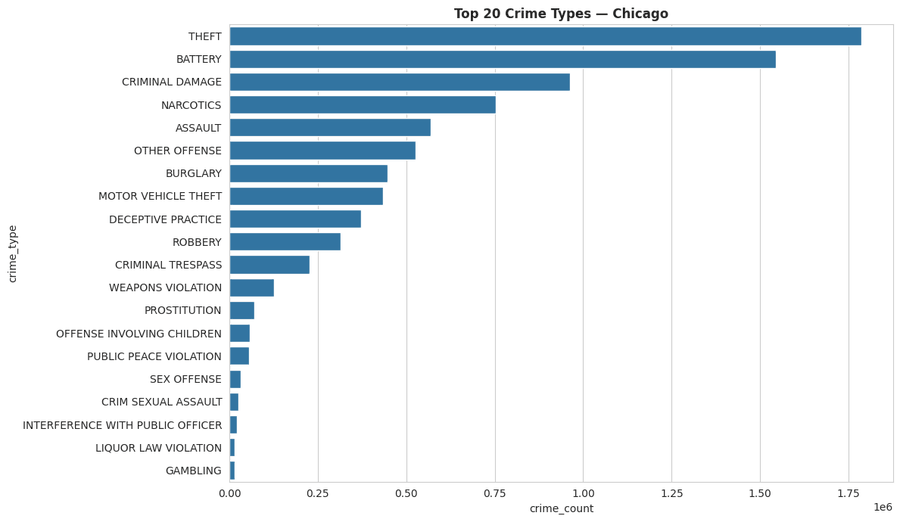

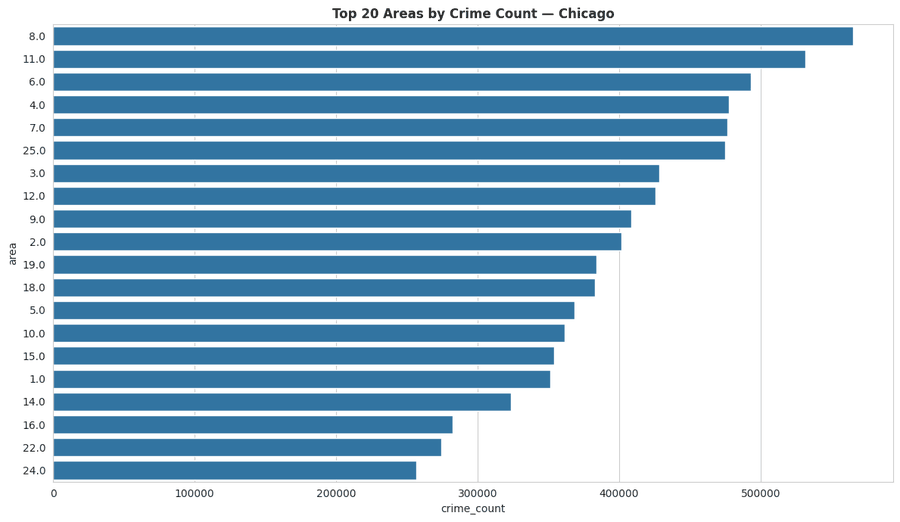

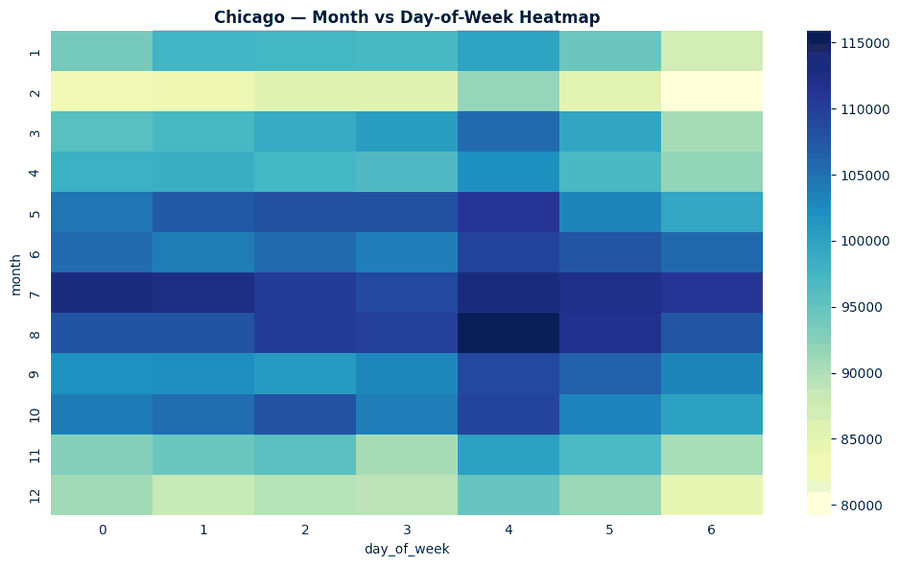

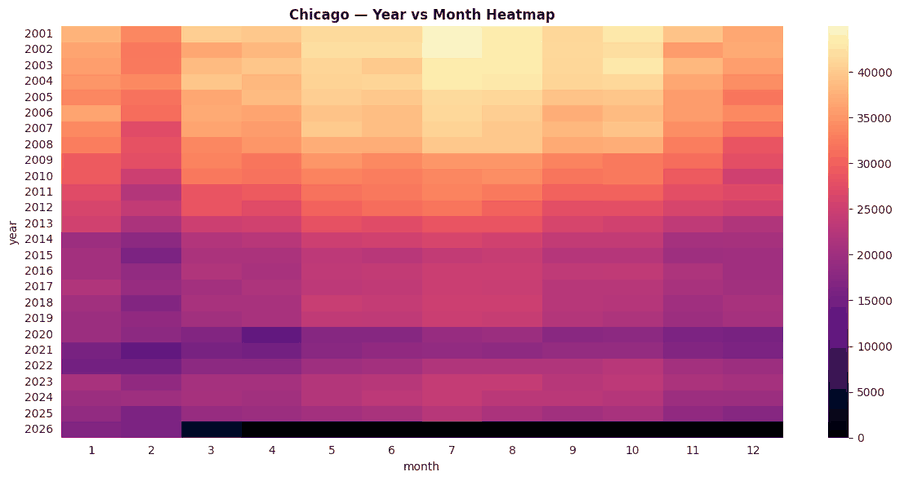

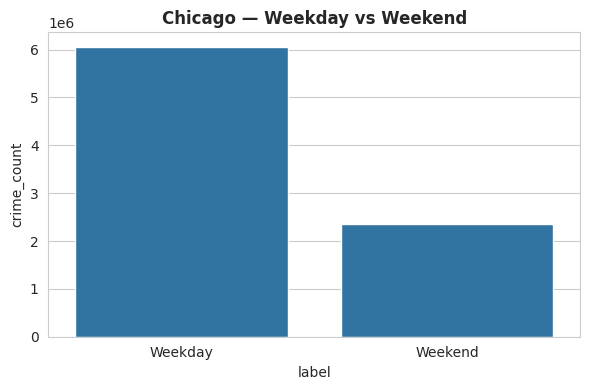

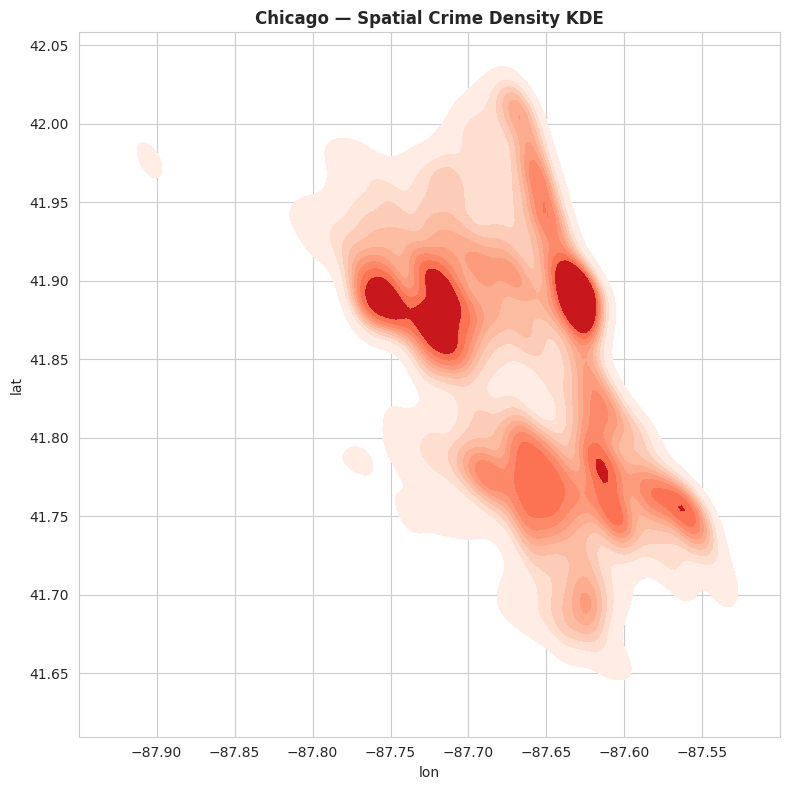

In [10]:
# CELL 9 — Run EDA for Chicago

run_full_eda(df_chi, "chicago", "Chicago")


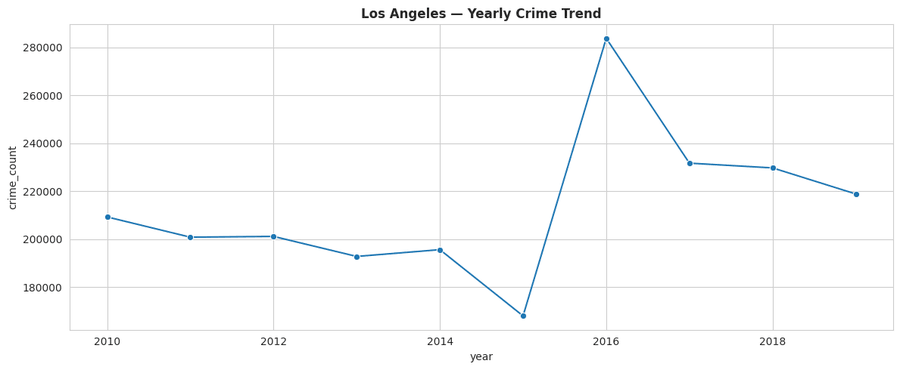

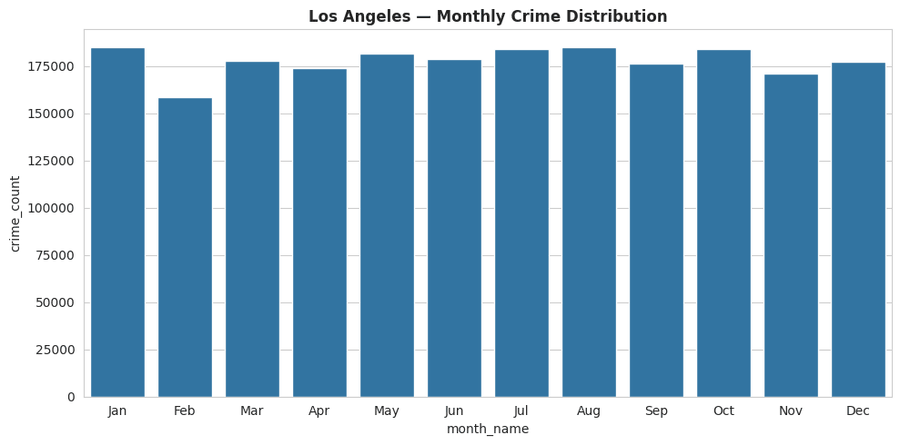

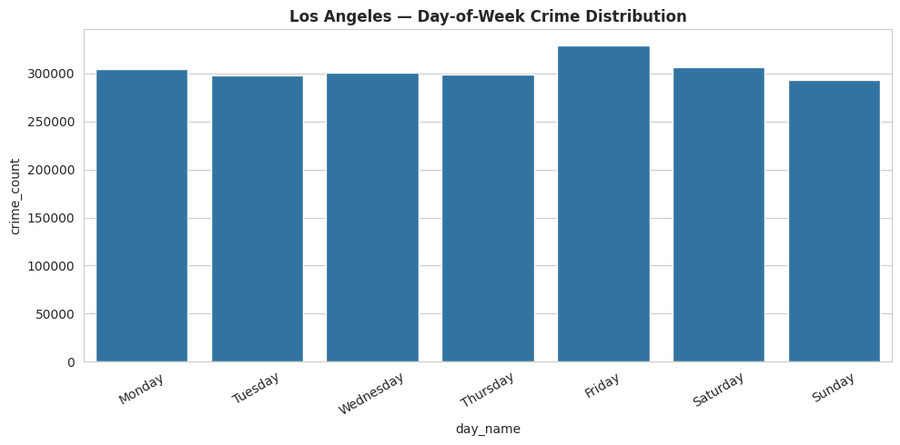

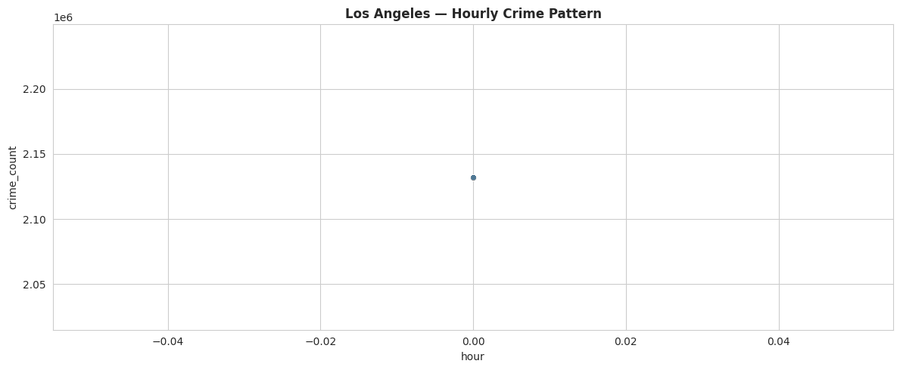

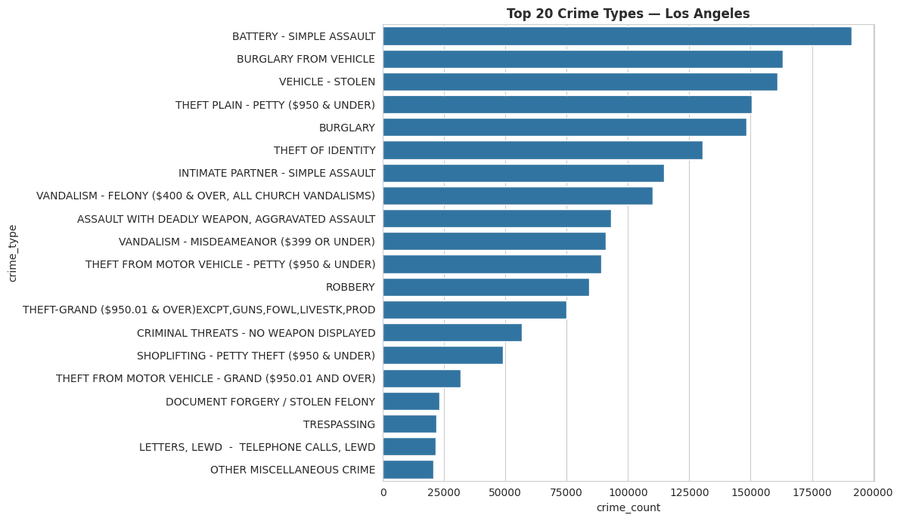

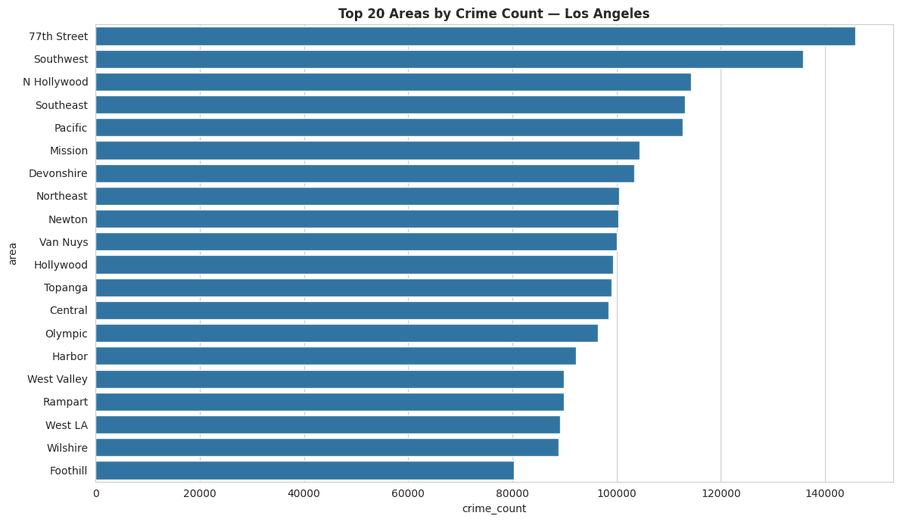

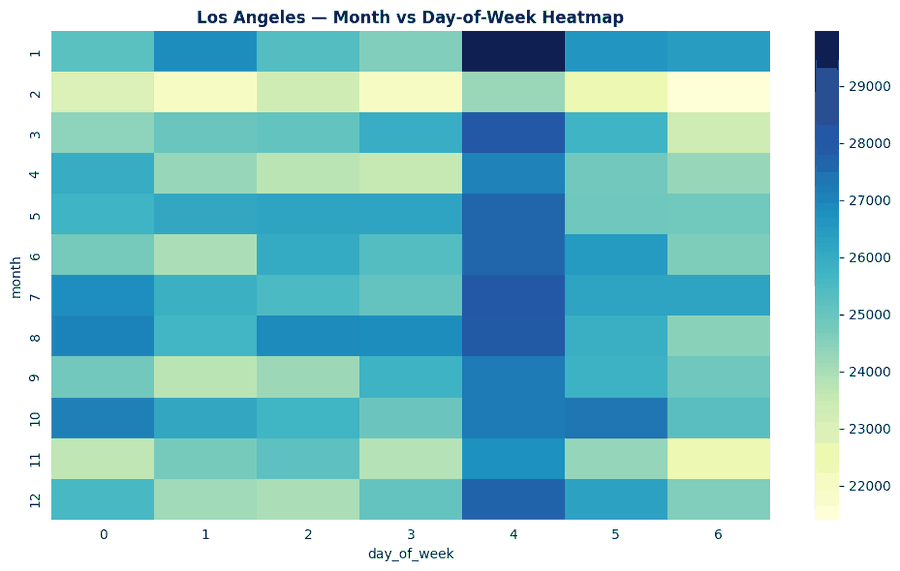

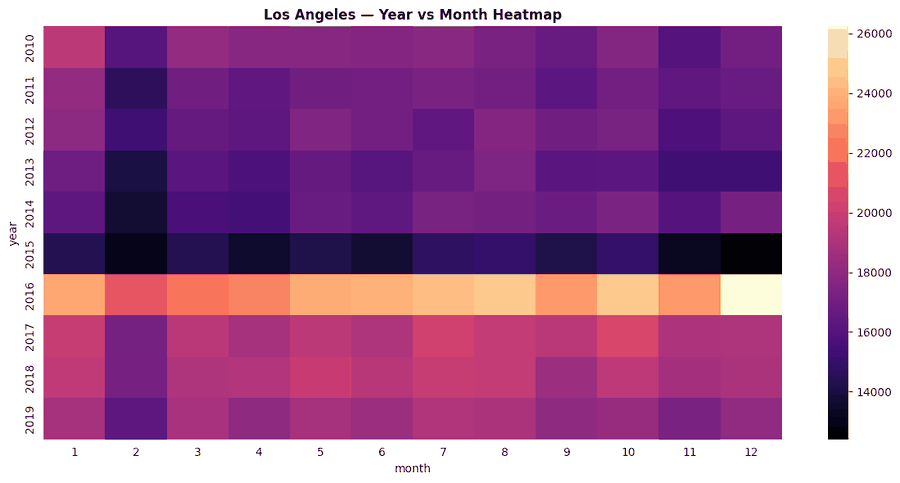

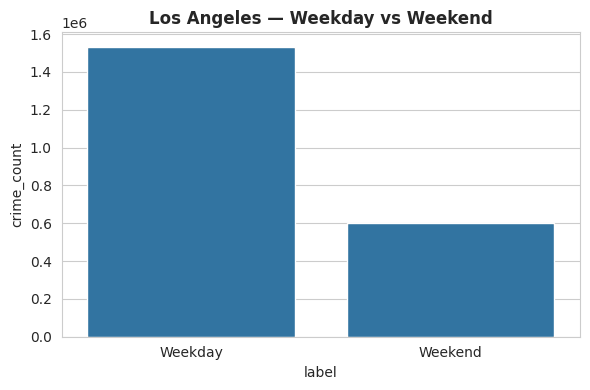

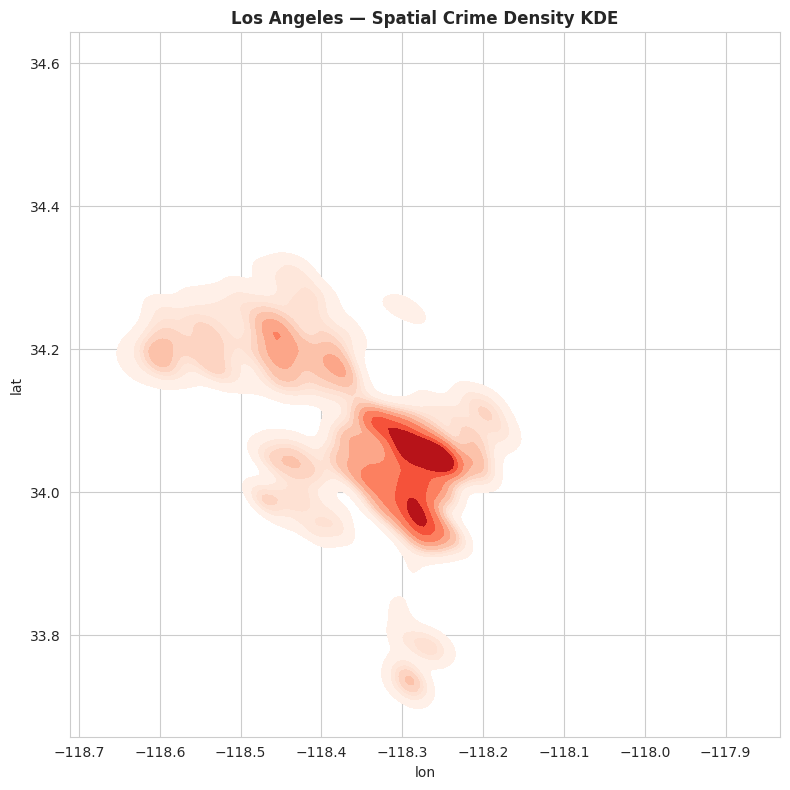

In [11]:
# CELL 10 — Run EDA for Los Angeles

run_full_eda(df_la, "los_angeles", "Los Angeles")


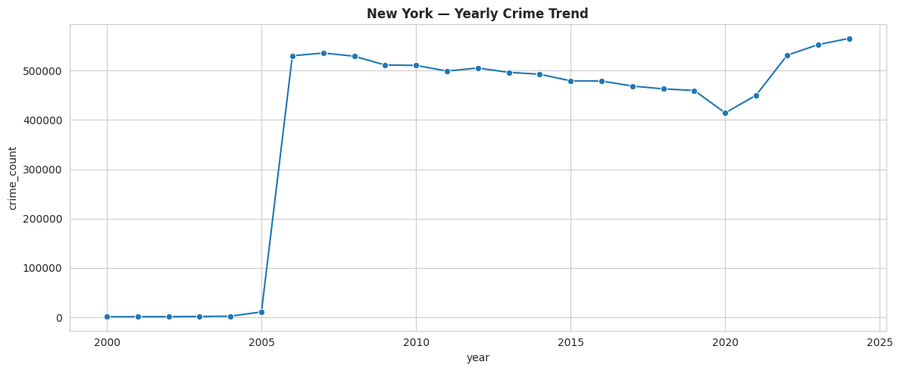

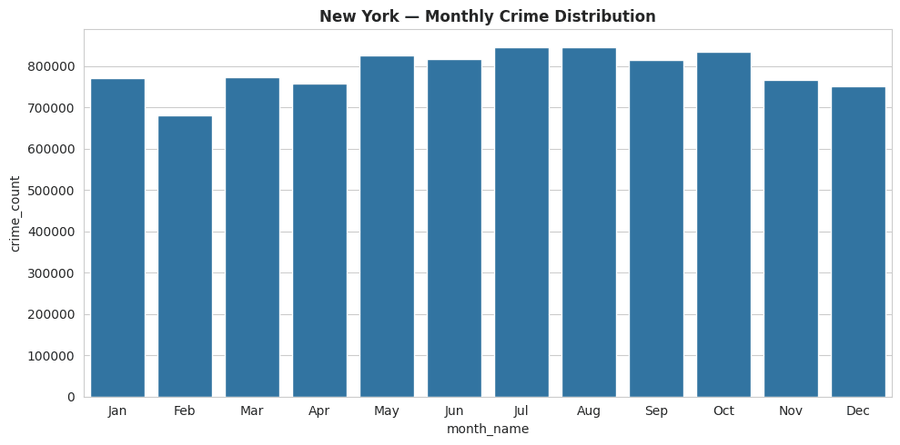

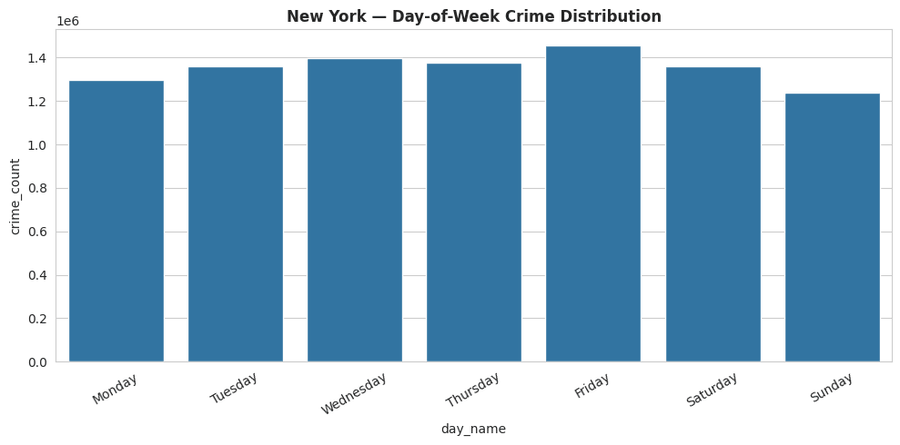

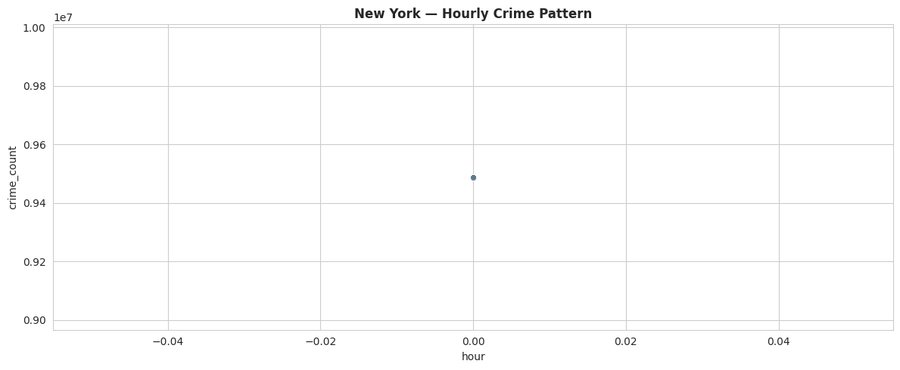

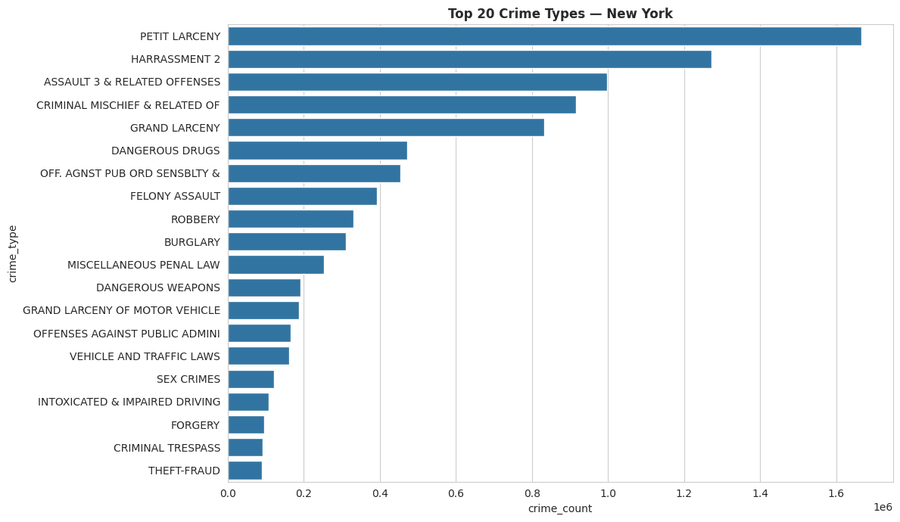

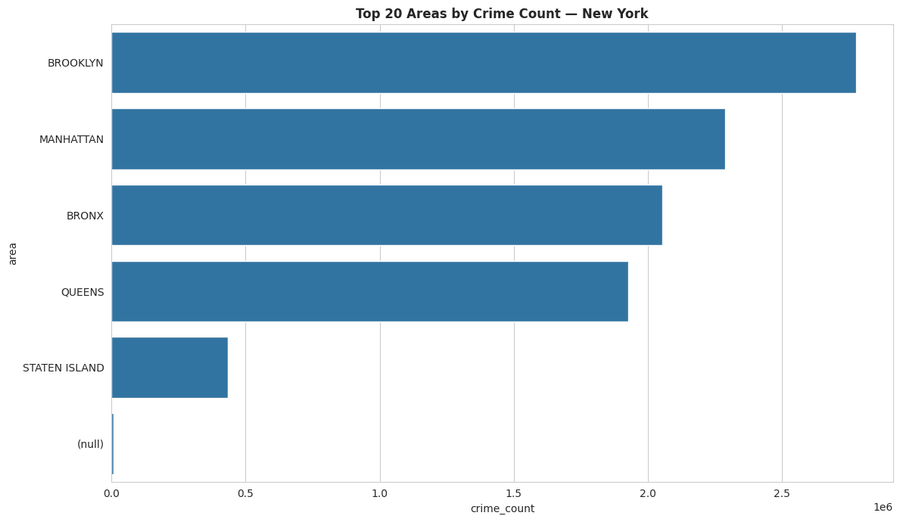

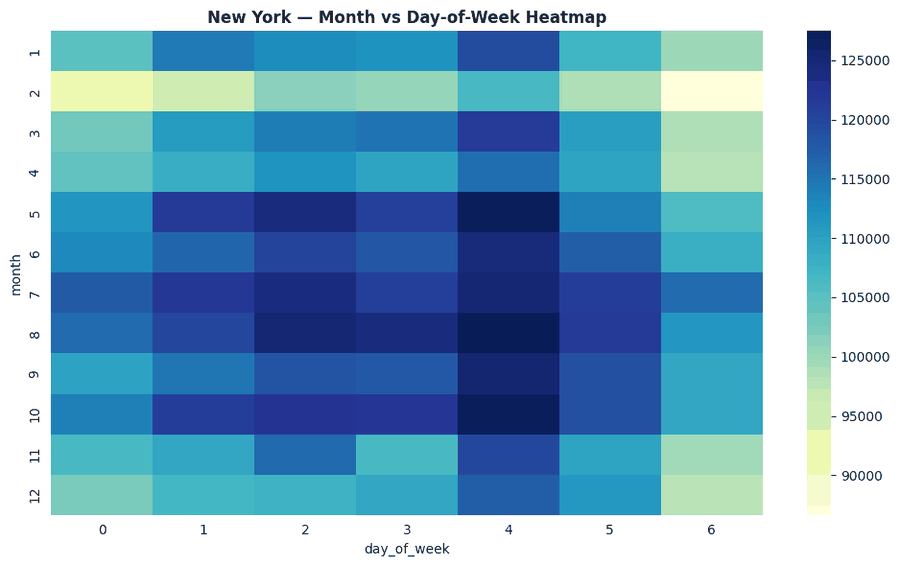

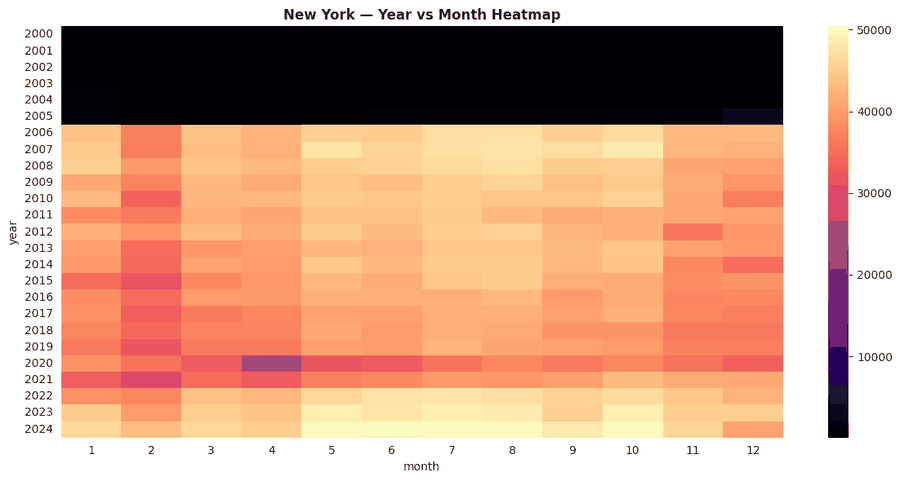

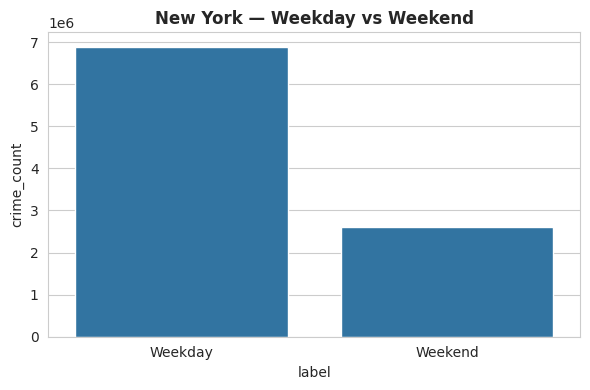

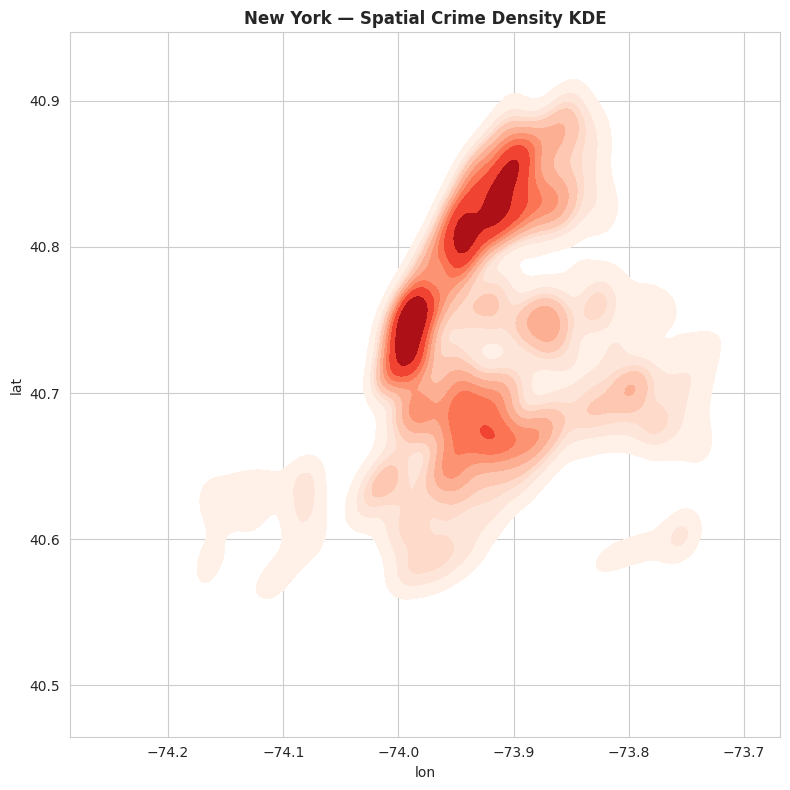

In [12]:
# CELL 11 — Run EDA for New York

run_full_eda(df_nyc, "new_york", "New York")


# *PART 2 — HOTSPOT MODELLING*

In [13]:
# CELL 12 — Hotspot Configuration

HOTSPOT_START_YEARS = {
    "Chicago": 2020,
    "Los_Angeles": 2015,
    "New_York": 2019
}
GRID_SIZE = 0.01   # ~1 km-ish grid

FEATURE_COLS_HOTSPOT = [
    "lag_1", "lag_7", "rolling_mean_7", "rolling_std_7", "day_of_week", "month"
]
TARGET_COL = "hotspot"

print(HOTSPOT_START_YEARS)
print(FEATURE_COLS_HOTSPOT)


{'Chicago': 2020, 'Los_Angeles': 2015, 'New_York': 2019}
['lag_1', 'lag_7', 'rolling_mean_7', 'rolling_std_7', 'day_of_week', 'month']


In [14]:
# CELL 13 — Grid Creation + Daily Grid Aggregation

def create_grid(df, grid_size=0.01):
    df = df.copy()
    df["lat_grid"] = (df["lat"] // grid_size) * grid_size
    df["lon_grid"] = (df["lon"] // grid_size) * grid_size
    df["grid_id"] = df["lat_grid"].astype(str) + "_" + df["lon_grid"].astype(str)
    return df


def build_hotspot_frame(df, city_name, city_key, start_year, grid_size=0.01):
    tmp = df[df["year"] >= start_year].copy()
    tmp = create_grid(tmp, grid_size=grid_size)

    daily = tmp.groupby(["date_only", "grid_id"]).size().reset_index(name="crime_count")
    daily["date_only"] = pd.to_datetime(daily["date_only"])

    all_dates = pd.date_range(daily["date_only"].min(), daily["date_only"].max(), freq="D")
    all_grids = daily["grid_id"].unique()
    full_idx = pd.MultiIndex.from_product([all_dates, all_grids], names=["date_only", "grid_id"])

    full = (
        daily.set_index(["date_only", "grid_id"])
        .reindex(full_idx, fill_value=0)
        .reset_index()
        .sort_values(["grid_id", "date_only"])
        .reset_index(drop=True)
    )

    full["lag_1"] = full.groupby("grid_id")["crime_count"].shift(1)
    full["lag_7"] = full.groupby("grid_id")["crime_count"].shift(7)
    full["rolling_mean_7"] = (
        full.groupby("grid_id")["crime_count"].shift(1).rolling(7).mean().reset_index(level=0, drop=True)
    )
    full["rolling_std_7"] = (
        full.groupby("grid_id")["crime_count"].shift(1).rolling(7).std().reset_index(level=0, drop=True)
    )
    full["day_of_week"] = full["date_only"].dt.dayofweek
    full["month"] = full["date_only"].dt.month

    full = full.dropna().reset_index(drop=True)

    threshold = full["crime_count"].median()
    full["hotspot"] = (full["crime_count"] > threshold).astype(int)

    city_table = os.path.join(BASE_OUT, city_key, "tables")
    city_report = os.path.join(BASE_OUT, city_key, "reports")

    full.head(20).to_csv(os.path.join(city_table, f"{city_key}_hotspot_frame_head.csv"), index=False)
    with open(os.path.join(city_report, f"{city_key}_hotspot_info.txt"), "w") as f:
        f.write(f"city={city_name}\n")
        f.write(f"start_year={start_year}\n")
        f.write(f"grid_size={grid_size}\n")
        f.write(f"unique_grids={full['grid_id'].nunique()}\n")
        f.write(f"shape={full.shape}\n")
        f.write(f"median_threshold={threshold}\n")

    return full


chi_hot = build_hotspot_frame(df_chi, "Chicago", "chicago", HOTSPOT_START_YEARS["Chicago"], GRID_SIZE)
la_hot  = build_hotspot_frame(df_la, "Los_Angeles", "los_angeles", HOTSPOT_START_YEARS["Los_Angeles"], GRID_SIZE)
nyc_hot = build_hotspot_frame(df_nyc, "New_York", "new_york", HOTSPOT_START_YEARS["New_York"], GRID_SIZE)

print("Chicago hotspot frame:", chi_hot.shape)
print("LA hotspot frame:", la_hot.shape)
print("NYC hotspot frame:", nyc_hot.shape)


Chicago hotspot frame: (1633425, 10)
LA hotspot frame: (2331958, 10)
NYC hotspot frame: (2047345, 10)


In [15]:
# CELL 14 — Train/Test Split for Hotspot Models

def time_based_split_hotspot(full_df, feature_cols, target_col="hotspot", split_ratio=0.8):
    full_df = full_df.sort_values("date_only").reset_index(drop=True)
    split_date = full_df["date_only"].sort_values().iloc[int(len(full_df) * split_ratio)]

    train_df = full_df[full_df["date_only"] < split_date].copy()
    test_df  = full_df[full_df["date_only"] >= split_date].copy()

    X_train = train_df[feature_cols].copy()
    y_train = train_df[target_col].copy()
    X_test  = test_df[feature_cols].copy()
    y_test  = test_df[target_col].copy()

    return X_train, X_test, y_train, y_test, train_df, test_df, split_date


chi_Xtr, chi_Xte, chi_ytr, chi_yte, chi_train_df, chi_test_df, chi_split = time_based_split_hotspot(chi_hot, FEATURE_COLS_HOTSPOT)
la_Xtr, la_Xte, la_ytr, la_yte, la_train_df, la_test_df, la_split = time_based_split_hotspot(la_hot, FEATURE_COLS_HOTSPOT)
nyc_Xtr, nyc_Xte, nyc_ytr, nyc_yte, nyc_train_df, nyc_test_df, nyc_split = time_based_split_hotspot(nyc_hot, FEATURE_COLS_HOTSPOT)

print("Chicago split date:", chi_split)
print("LA split date:", la_split)
print("NYC split date:", nyc_split)


Chicago split date: 2024-12-14 00:00:00
LA split date: 2019-01-02 00:00:00
NYC split date: 2023-10-22 00:00:00


In [16]:
# CELL 15 — Standardized Hotspot Models

def get_hotspot_models():
    models = {
        "KNN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=7))
        ]),
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, random_state=SEED))
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(max_depth=10, min_samples_split=20, random_state=SEED))
        ]),
        "Naive Bayes": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GaussianNB())
        ]),
        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                n_estimators=250,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        "MLP": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=SEED))
        ]),
        "Linear SVM": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", CalibratedClassifierCV(
                estimator=LinearSVC(random_state=SEED, max_iter=5000),
                cv=3,
                method="sigmoid"
            ))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=250,
                max_depth=12,
                min_samples_split=10,
                class_weight="balanced",
                random_state=SEED,
                n_jobs=-1
            ))
        ])
    }
    return models

models_dict = get_hotspot_models()
print(list(models_dict.keys()))


['KNN', 'Logistic Regression', 'Decision Tree', 'Naive Bayes', 'XGBoost', 'MLP', 'Linear SVM', 'Random Forest']


In [17]:
# CELL 16 — Unified Binary Evaluation Function (FIXED FOR ROC STORAGE)

from sklearn.metrics import roc_curve, auc

def safe_predict_score(model, X):
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X)
        return prob[:, 1] if prob.ndim == 2 else prob
    elif hasattr(model, "decision_function"):
        score = np.asarray(model.decision_function(X)).reshape(-1)
        score = (score - score.min()) / (score.max() - score.min() + 1e-9)
        return score
    else:
        return model.predict(X).astype(float)


def evaluate_binary_model(model, X_train, y_train, X_test, y_test, model_name, city_key):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_score = safe_predict_score(model, X_test)

    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    metrics = {
        "City": city_key,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc,
        "PR_AUC": average_precision_score(y_test, y_score),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Kappa": cohen_kappa_score(y_test, y_pred)
    }

    cm = confusion_matrix(y_test, y_pred)

    city_plot  = os.path.join(BASE_OUT, city_key, "plots")
    city_table = os.path.join(BASE_OUT, city_key, "tables")
    city_model = os.path.join(BASE_OUT, city_key, "models")

    safe_name = model_name.lower().replace(" ", "_")

    # Save model
    joblib.dump(model, os.path.join(city_model, f"{safe_name}_hotspot_model.joblib"))

    # Confusion matrix
    plt.figure(figsize=(4, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{city_key} — {model_name} Confusion Matrix", fontweight="bold")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{safe_name}_confusion_matrix.png"), dpi=300)
    plt.show()

    # Individual ROC
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc:.3f})", linewidth=2)
    plt.plot([0, 1], [0, 1], "r--", alpha=0.7)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{city_key} — {model_name} ROC Curve", fontweight="bold")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{safe_name}_roc_curve.png"), dpi=300)
    plt.show()

    pd.DataFrame([metrics]).to_csv(
        os.path.join(city_table, f"{safe_name}_metrics.csv"), index=False
    )

    roc_df = pd.DataFrame({"fpr": fpr, "tpr": tpr})
    roc_df.to_csv(os.path.join(city_table, f"{safe_name}_roc_points.csv"), index=False)

    return metrics, model, y_pred, {"fpr": fpr, "tpr": tpr, "auc": roc_auc, "model": model_name, "city": city_key}

In [18]:
# CELL 17 — Run Hotspot Models for a City (FIXED FOR ROC STORAGE)

def run_hotspot_experiments(city_key, X_train, y_train, X_test, y_test):
    models = get_hotspot_models()
    results = []
    fitted_models = {}
    roc_curves = {}

    for model_name, model in models.items():
        print(f"\nRunning {city_key} — {model_name}")
        metrics, fitted_model, y_pred, roc_info = evaluate_binary_model(
            model, X_train, y_train, X_test, y_test, model_name, city_key
        )
        results.append(metrics)
        fitted_models[model_name] = fitted_model
        roc_curves[model_name] = roc_info

    results_df = pd.DataFrame(results).sort_values(
        ["ROC_AUC", "F1", "Accuracy"], ascending=False
    ).reset_index(drop=True)

    results_df.to_csv(
        os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_all_hotspot_model_metrics.csv"),
        index=False
    )

    display(results_df)
    return results_df, fitted_models, roc_curves


Running chicago — KNN


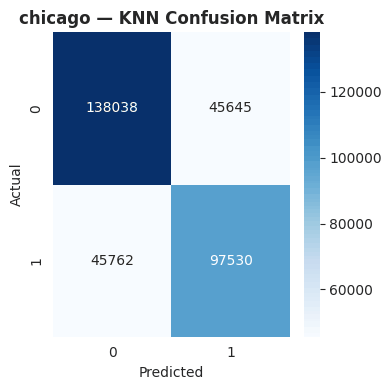

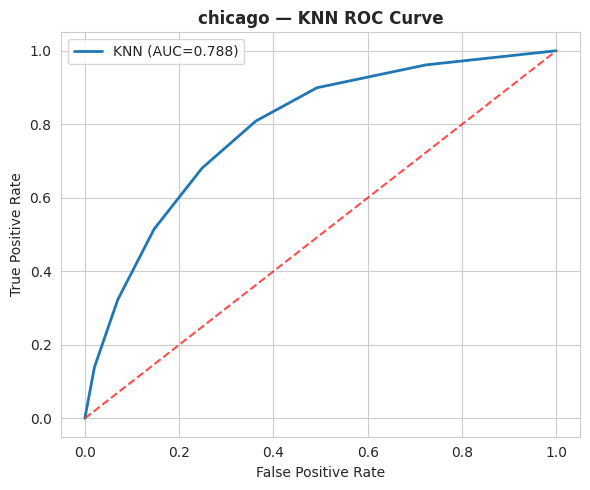


Running chicago — Logistic Regression


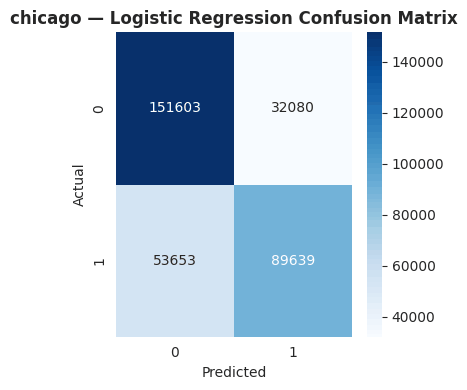

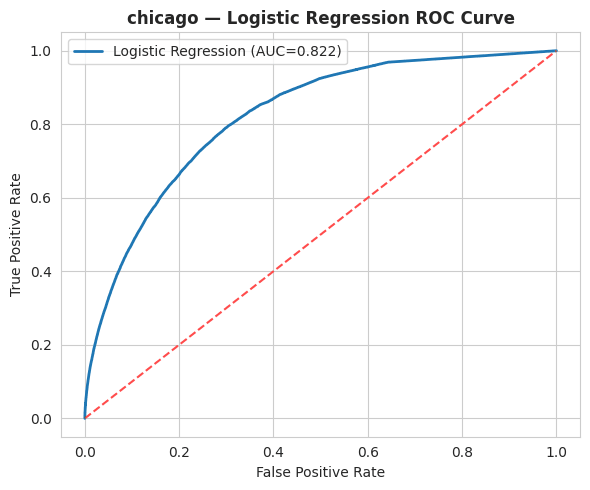


Running chicago — Decision Tree


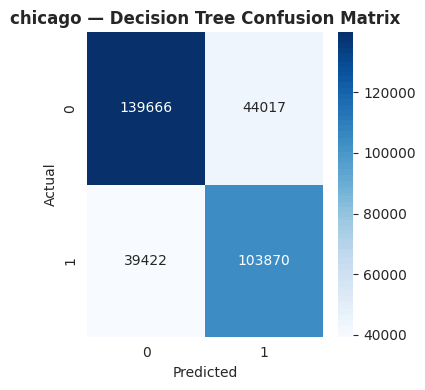

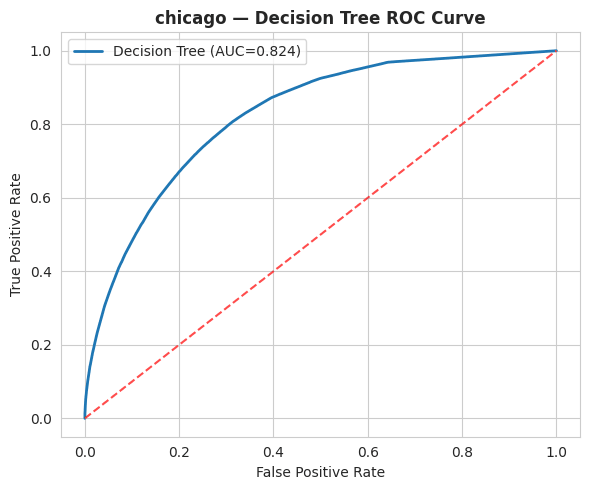


Running chicago — Naive Bayes


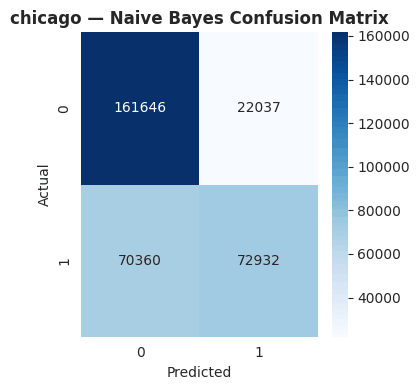

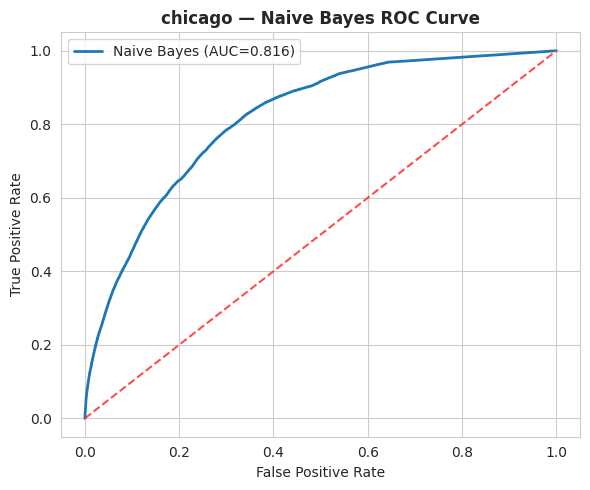


Running chicago — XGBoost


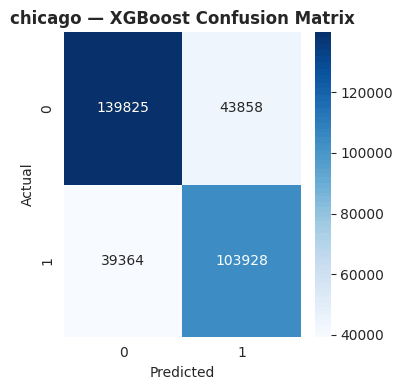

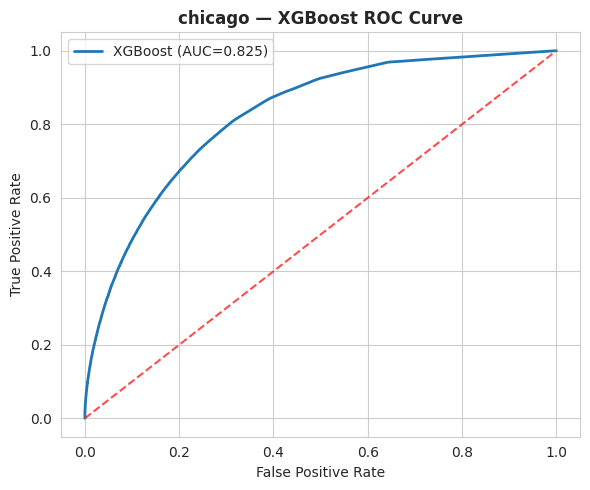


Running chicago — MLP


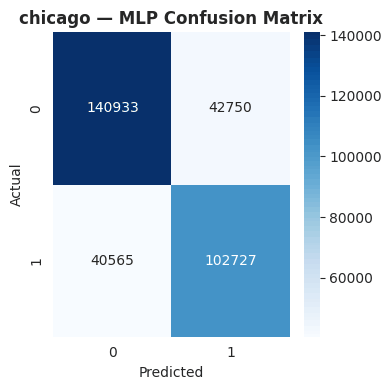

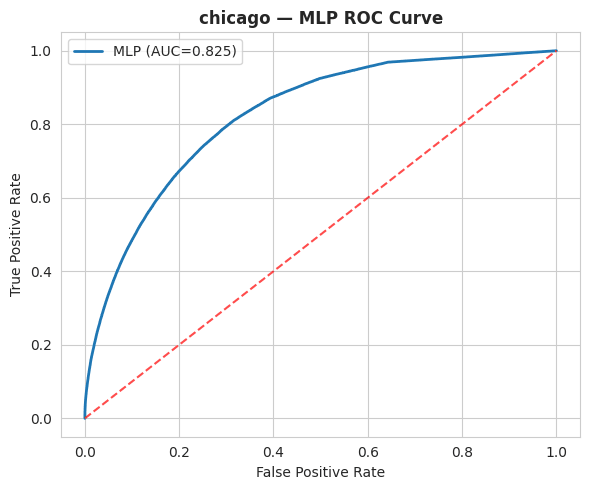


Running chicago — Linear SVM


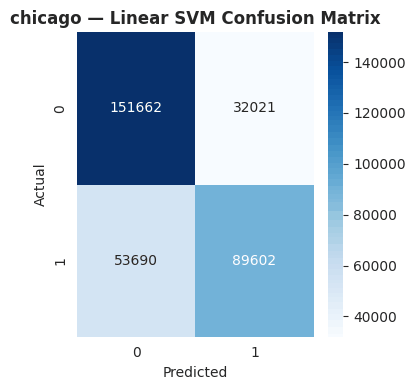

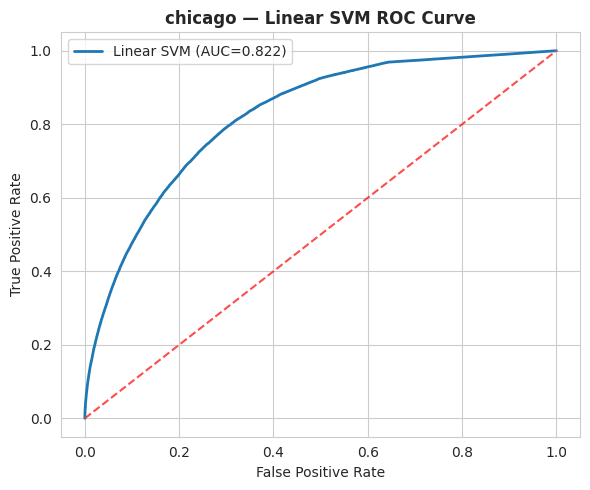


Running chicago — Random Forest


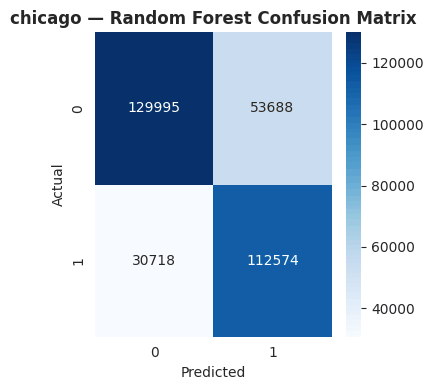

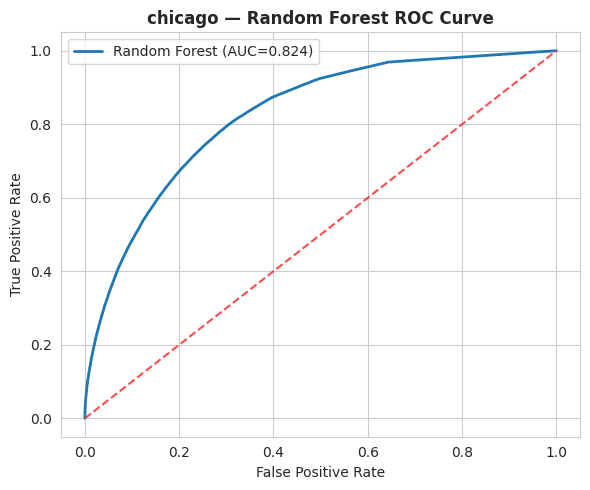

,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,chicago,XGBoost,0.745479,0.743259,0.703233,0.725288,0.714090,0.824704,0.776322,0.485034,0.484846
1,chicago,MLP,0.745195,0.742084,0.706139,0.716907,0.711482,0.824534,0.776496,0.483403,0.483358
2,chicago,Random Forest,0.741858,0.746670,0.677088,0.785627,0.727330,0.824385,0.775872,0.489632,0.484796
3,chicago,Decision Tree,0.744815,0.742624,0.702361,0.724883,0.713444,0.824015,0.773268,0.483739,0.483543
4,chicago,Linear SVM,0.737867,0.725492,0.736719,0.625311,0.676458,0.822048,0.771378,0.462965,0.458608
5,chicago,Logistic Regression,0.737800,0.725460,0.736442,0.625569,0.676493,0.821804,0.770901,0.462826,0.458510
6,chicago,Naive Bayes,0.717419,0.694501,0.767956,0.508975,0.612203,0.816435,0.761367,0.425164,0.403981
7,chicago,KNN,0.720447,0.716070,0.681194,0.680638,0.680916,0.787868,0.697637,0.432178,0.432178


In [19]:
# CELL 18 — Run Hotspot Models: Chicago

chi_hotspot_results, chi_fitted_models, chi_roc_curves = run_hotspot_experiments(
    "chicago", chi_Xtr, chi_ytr, chi_Xte, chi_yte
)


Running los_angeles — KNN


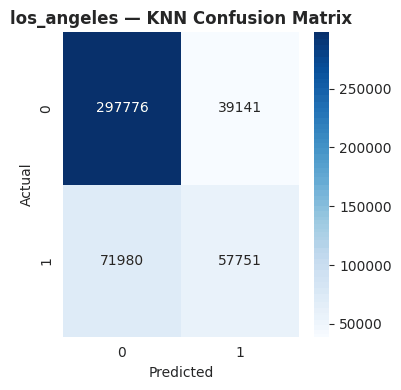

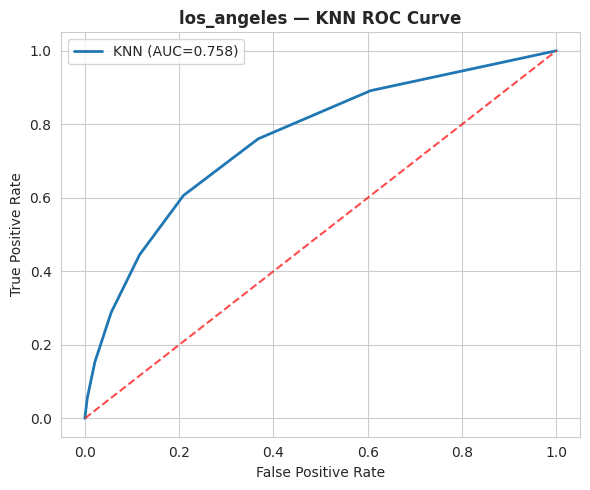


Running los_angeles — Logistic Regression


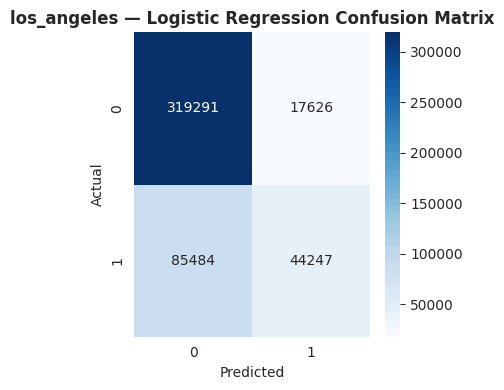

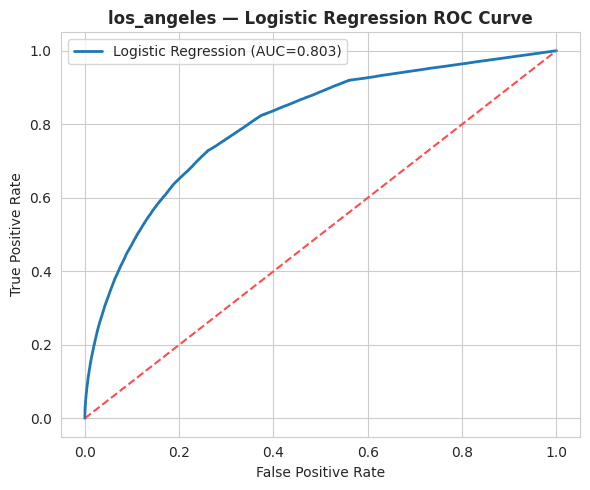


Running los_angeles — Decision Tree


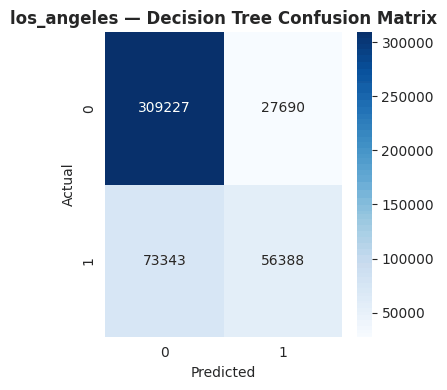

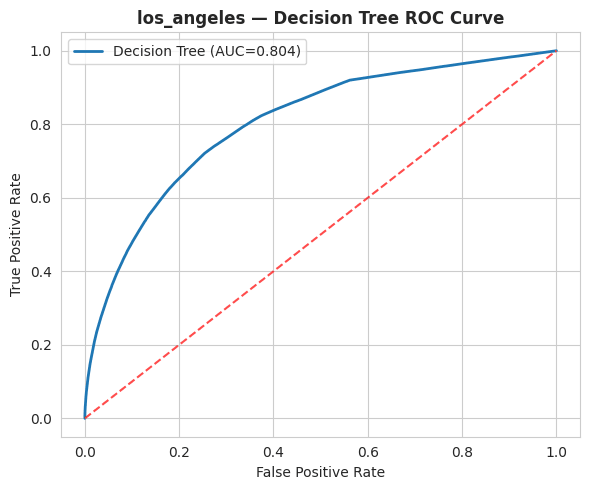


Running los_angeles — Naive Bayes


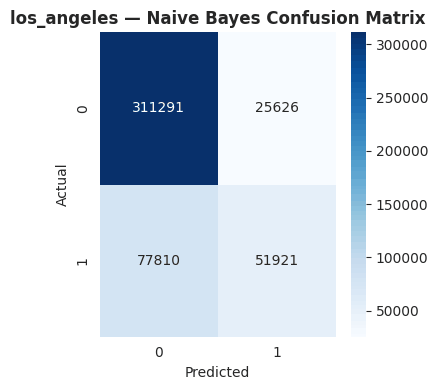

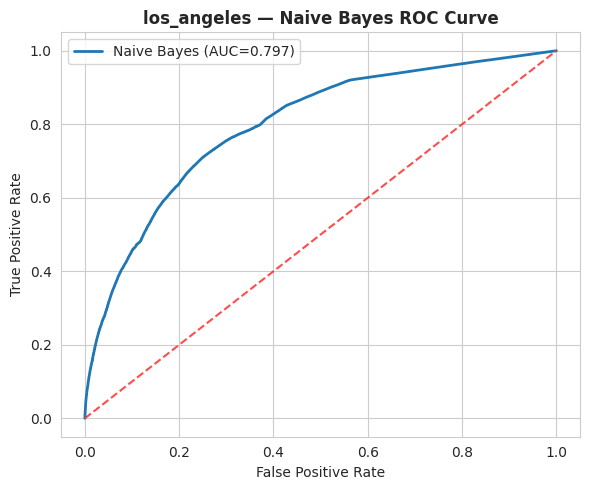


Running los_angeles — XGBoost


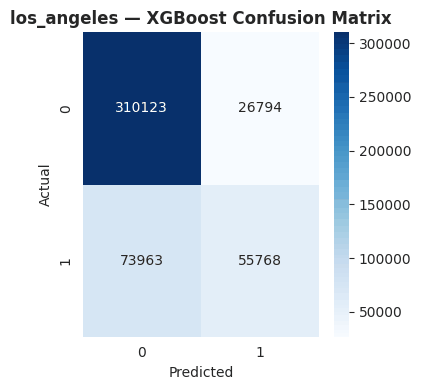

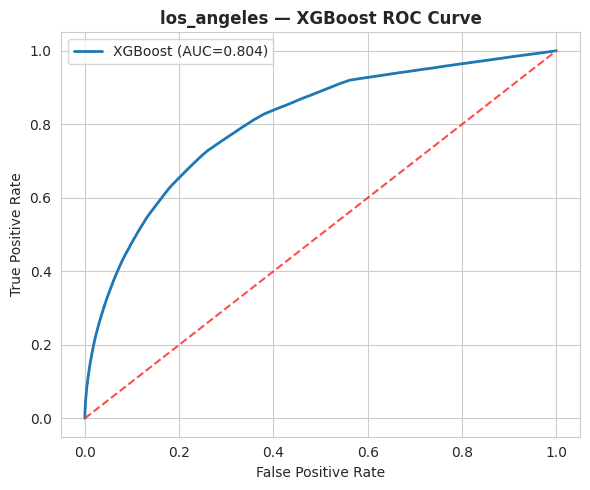


Running los_angeles — MLP


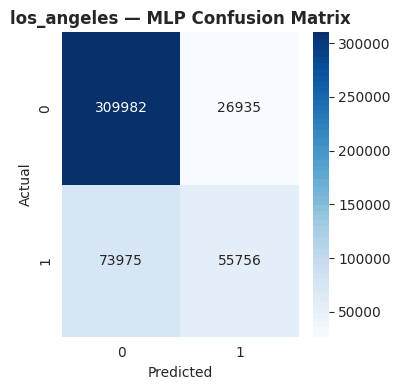

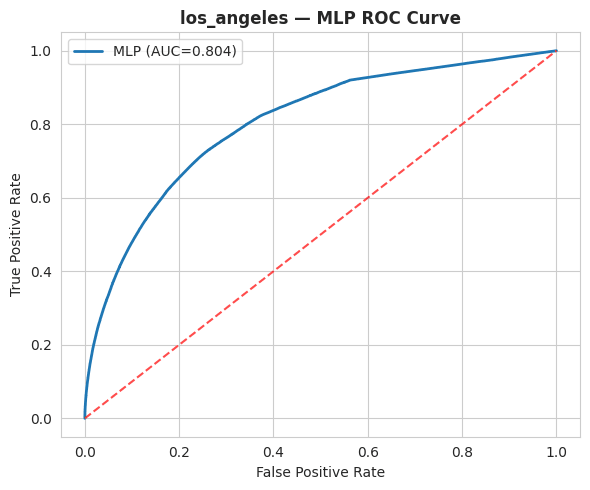


Running los_angeles — Linear SVM


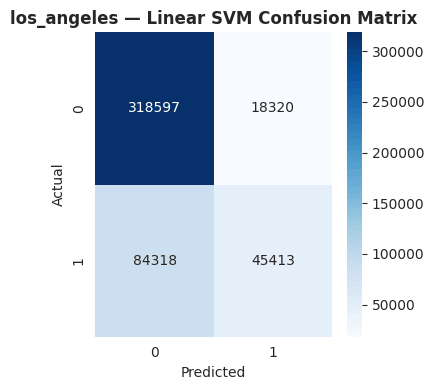

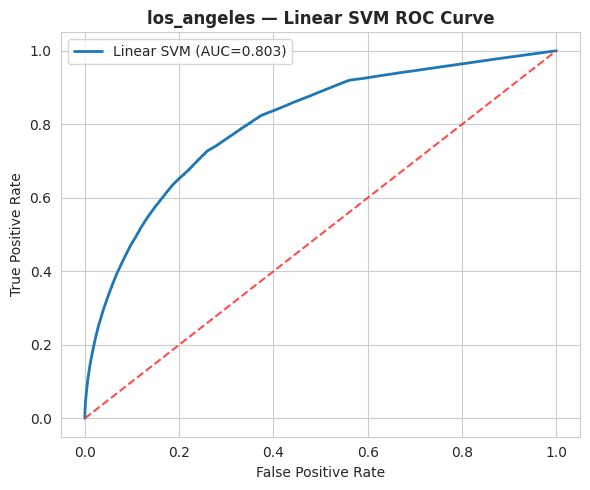


Running los_angeles — Random Forest


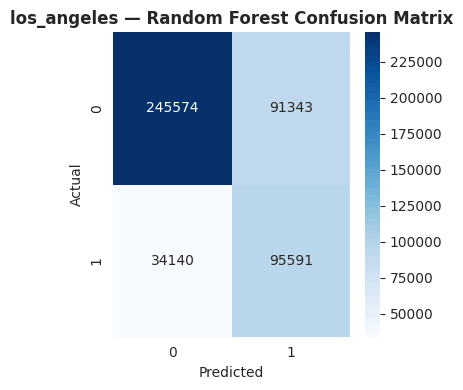

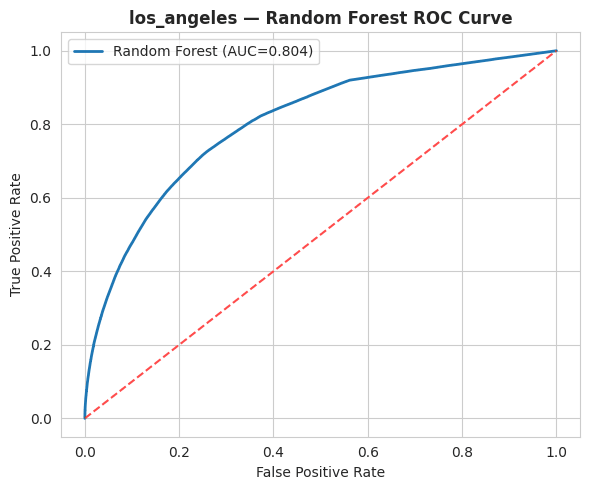

,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,los_angeles,XGBoost,0.784084,0.675174,0.675468,0.429874,0.525387,0.804233,0.636641,0.411318,0.394444
1,los_angeles,MLP,0.783756,0.674918,0.674269,0.429782,0.524955,0.803939,0.636485,0.410466,0.393733
2,los_angeles,Random Forest,0.731097,0.732863,0.511362,0.736840,0.603736,0.803881,0.636110,0.425807,0.410123
3,los_angeles,Decision Tree,0.783492,0.676233,0.670663,0.434653,0.527461,0.803680,0.633502,0.410870,0.395231
4,los_angeles,Linear SVM,0.780053,0.647840,0.712551,0.350055,0.469472,0.803112,0.634343,0.385759,0.350506
5,los_angeles,Logistic Regression,0.779041,0.644376,0.715126,0.341067,0.461859,0.802641,0.632864,0.381461,0.344092
6,los_angeles,Naive Bayes,0.778343,0.662080,0.669542,0.400220,0.500979,0.797171,0.616388,0.390148,0.369911
7,los_angeles,KNN,0.761874,0.664493,0.596035,0.445160,0.509666,0.758212,0.530689,0.363378,0.356752


In [20]:
# CELL 19 — Run Hotspot Models: Los Angeles

la_hotspot_results, la_fitted_models, la_roc_curves = run_hotspot_experiments(
    "los_angeles", la_Xtr, la_ytr, la_Xte, la_yte
)


Running new_york — KNN


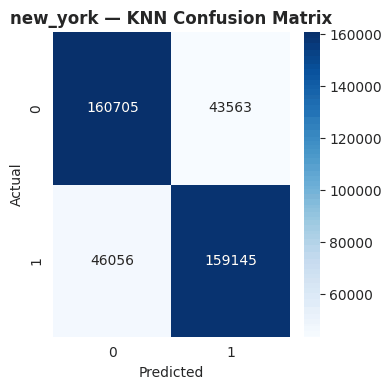

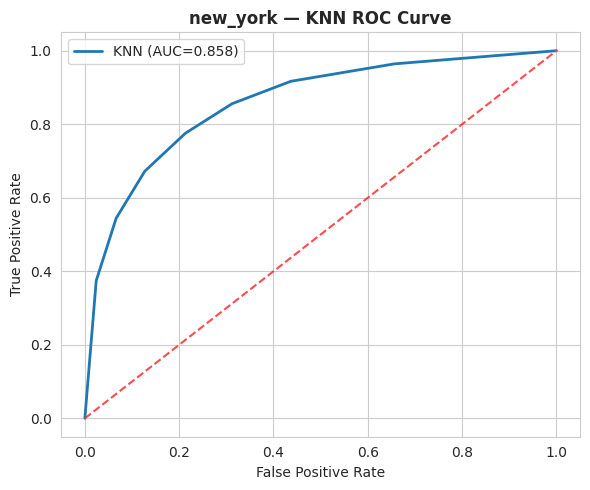


Running new_york — Logistic Regression


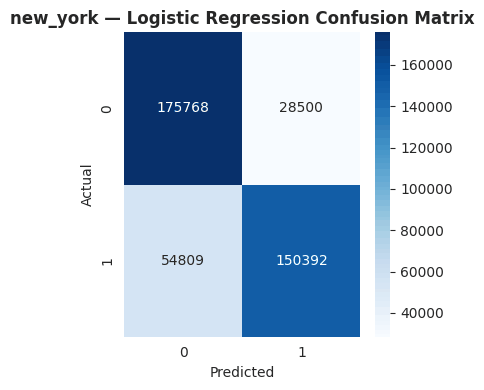

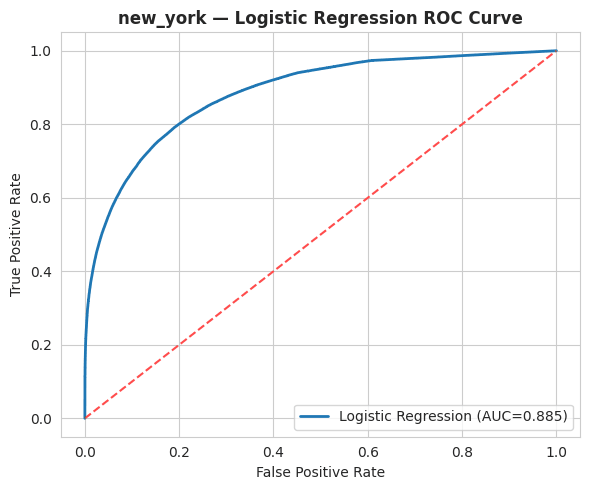


Running new_york — Decision Tree


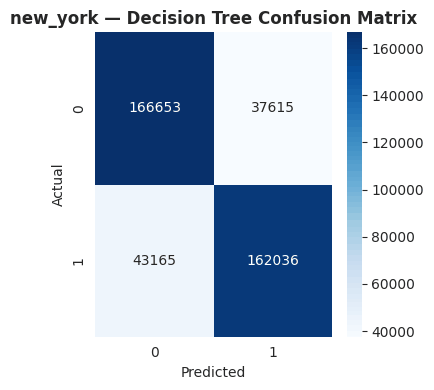

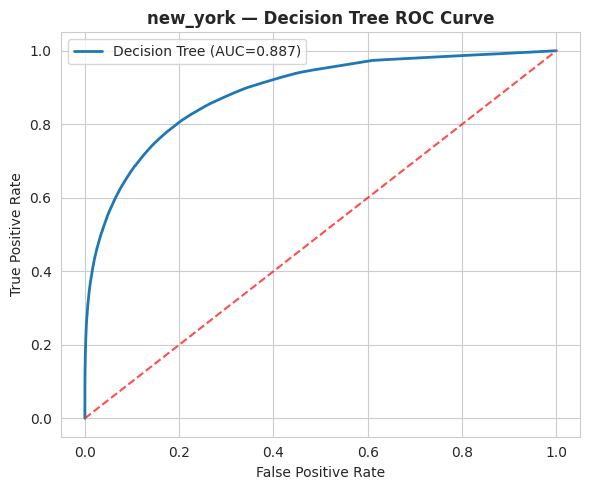


Running new_york — Naive Bayes


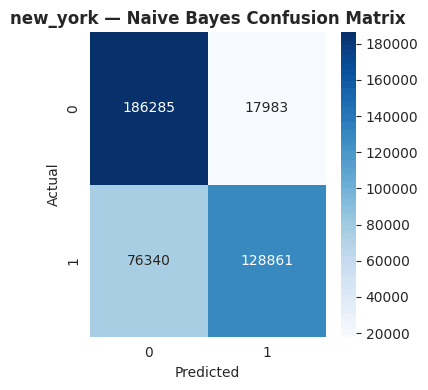

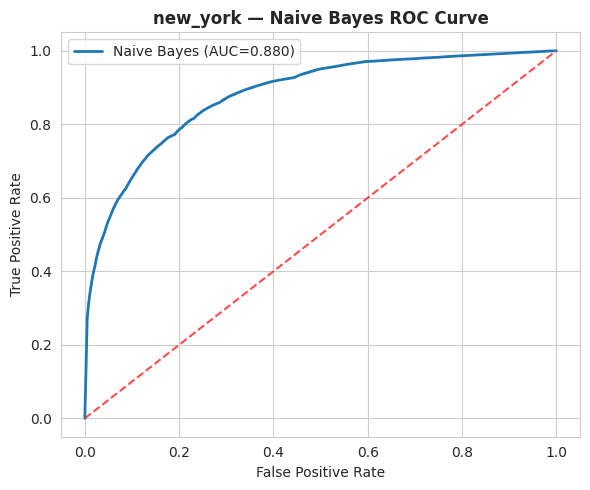


Running new_york — XGBoost


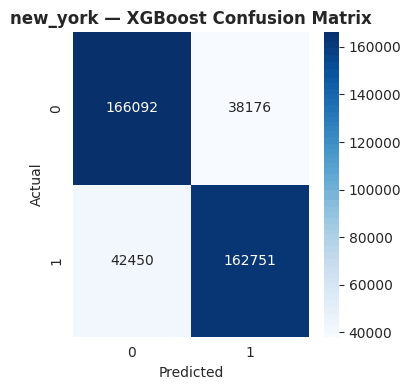

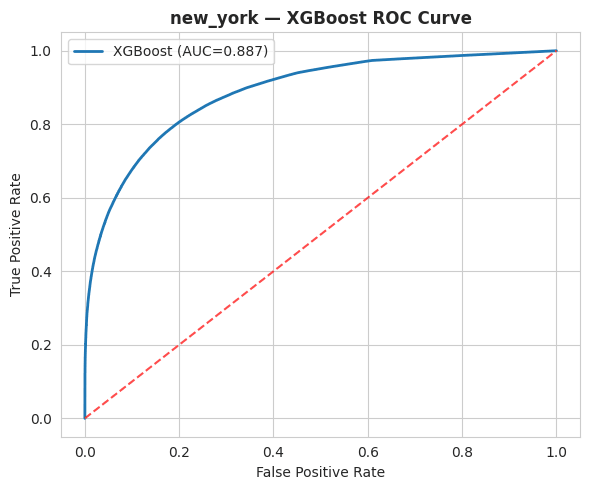


Running new_york — MLP


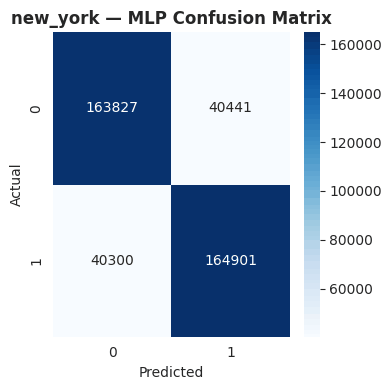

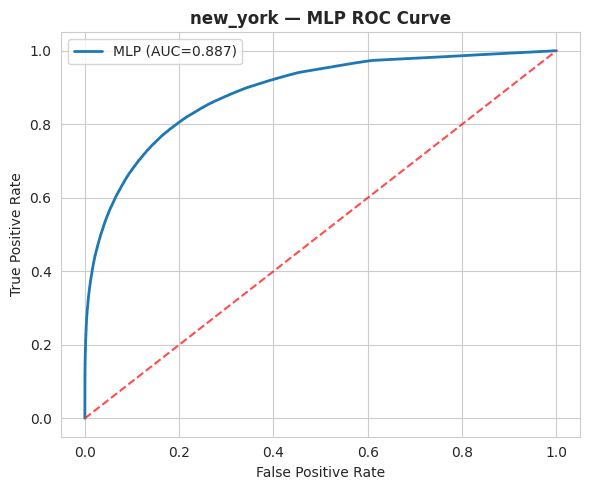


Running new_york — Linear SVM


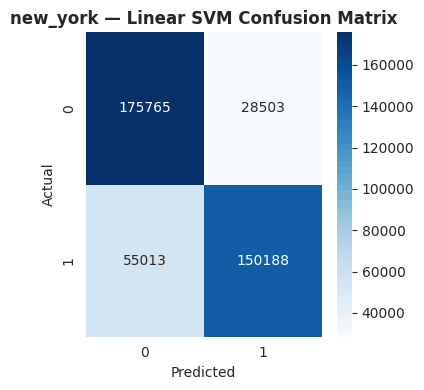

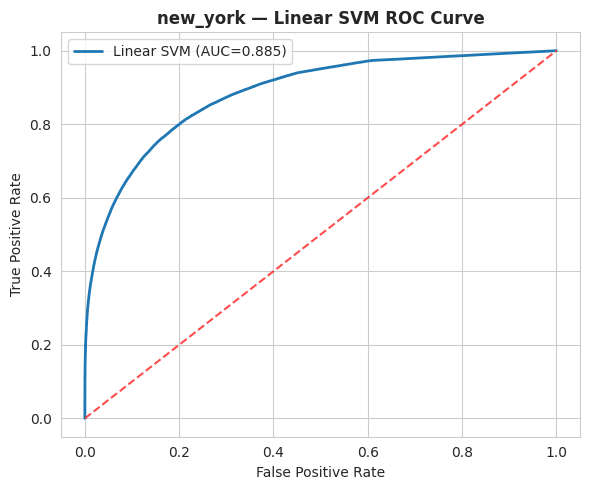


Running new_york — Random Forest


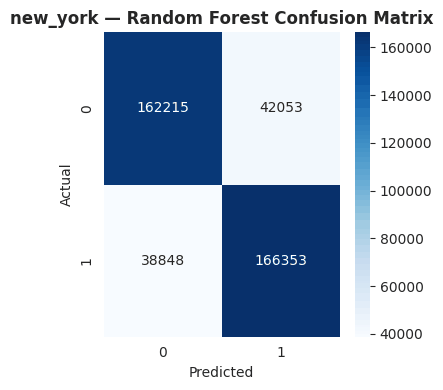

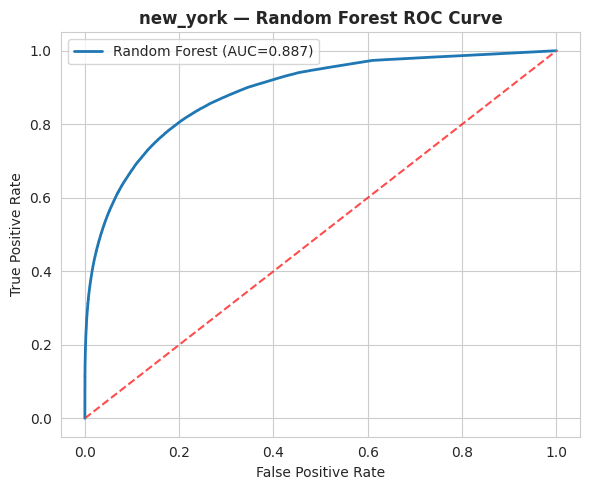

,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,new_york,XGBoost,0.803096,0.803119,0.810001,0.793130,0.801476,0.886989,0.895724,0.606341,0.606209
1,new_york,MLP,0.802815,0.802814,0.803055,0.803607,0.803331,0.886859,0.895734,0.605628,0.605628
2,new_york,Random Forest,0.802425,0.802406,0.798216,0.810683,0.804401,0.886690,0.895470,0.604907,0.604833
3,new_york,Decision Tree,0.802720,0.802750,0.811596,0.789645,0.800470,0.886531,0.894138,0.605685,0.605463
4,new_york,Logistic Regression,0.796544,0.796689,0.840686,0.732901,0.783102,0.884882,0.893412,0.598161,0.593205
5,new_york,Linear SVM,0.796038,0.796185,0.840490,0.731907,0.782449,0.884579,0.893060,0.597220,0.592195
6,new_york,Naive Bayes,0.769646,0.769969,0.877537,0.627975,0.732071,0.879967,0.885482,0.562909,0.539588
7,new_york,KNN,0.781134,0.781146,0.785095,0.775557,0.780297,0.858377,0.838598,0.562319,0.562277


In [21]:
# CELL 20 — Run Hotspot Models: New York

nyc_hotspot_results, nyc_fitted_models, nyc_roc_curves = run_hotspot_experiments(
    "new_york", nyc_Xtr, nyc_ytr, nyc_Xte, nyc_yte
)

In [22]:
# CELL 21 — Stronger Ensemble from Top Hotspot Models

def build_ensemble_from_top(results_df, fitted_models, X_train, y_train, top_k=5):
    top_models = results_df.head(top_k)["Model"].tolist()
    fresh_models = get_hotspot_models()

    estimators = []
    for name in top_models:
        estimators.append((name.replace(" ", "_"), fresh_models[name]))

    ensemble = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
        stack_method="predict_proba",
        cv=3,
        passthrough=False,
        n_jobs=-1
    )

    ensemble.fit(X_train, y_train)
    return ensemble, top_models


chi_ensemble, chi_top_models = build_ensemble_from_top(chi_hotspot_results, chi_fitted_models, chi_Xtr, chi_ytr, top_k=5)
la_ensemble, la_top_models   = build_ensemble_from_top(la_hotspot_results, la_fitted_models, la_Xtr, la_ytr, top_k=5)
nyc_ensemble, nyc_top_models = build_ensemble_from_top(nyc_hotspot_results, nyc_fitted_models, nyc_Xtr, nyc_ytr, top_k=5)

print("Chicago top models:", chi_top_models)
print("LA top models:", la_top_models)
print("NYC top models:", nyc_top_models)

Chicago top models: ['XGBoost', 'MLP', 'Random Forest', 'Decision Tree', 'Linear SVM']
LA top models: ['XGBoost', 'MLP', 'Random Forest', 'Decision Tree', 'Linear SVM']
NYC top models: ['XGBoost', 'MLP', 'Random Forest', 'Decision Tree', 'Logistic Regression']


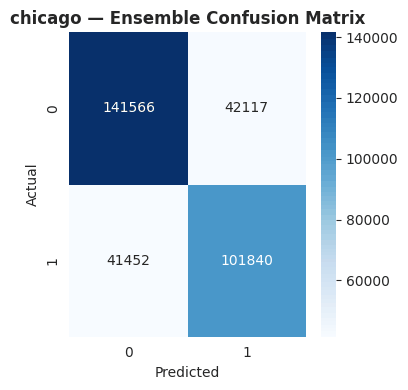

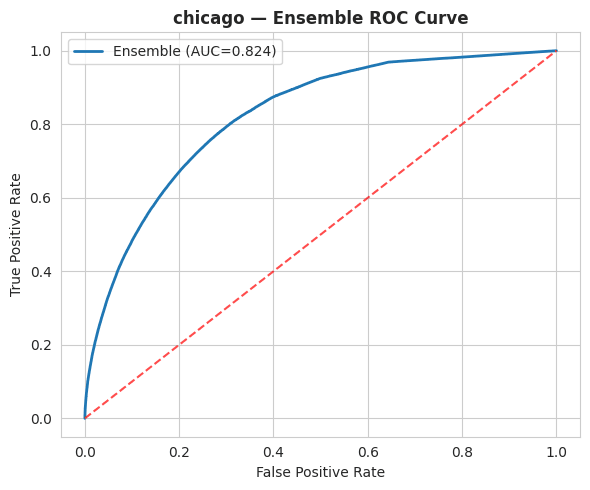

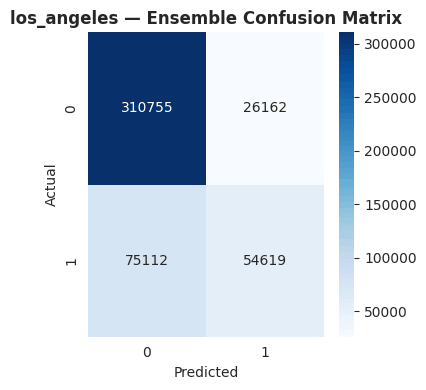

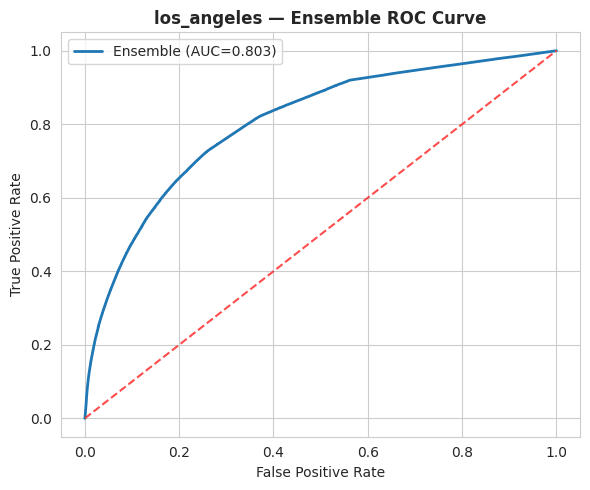

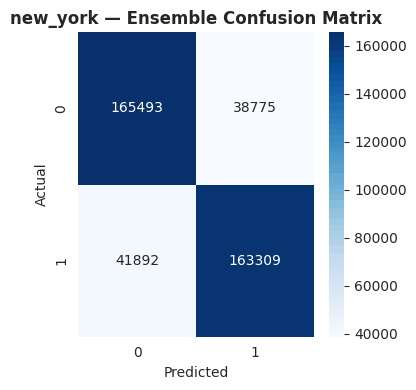

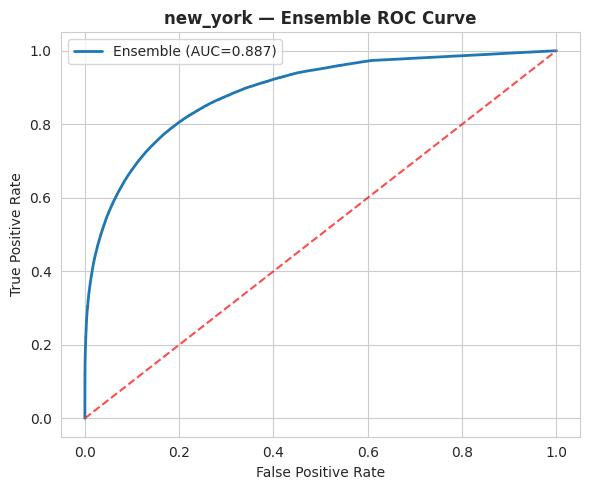

,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,chicago,Ensemble,0.744418,0.740712,0.707433,0.710717,0.709071,0.823716,0.773266,0.481183,0.481179
1,los_angeles,Ensemble,0.782976,0.671683,0.676137,0.421017,0.518916,0.803334,0.626423,0.406600,0.388430
2,new_york,Ensemble,0.802996,0.803012,0.808124,0.795849,0.801940,0.886781,0.895592,0.606074,0.606004


In [23]:
# CELL 22 — Evaluate Ensemble Models

chi_ensemble_metrics, _, _, chi_ensemble_roc = evaluate_binary_model(
    chi_ensemble, chi_Xtr, chi_ytr, chi_Xte, chi_yte, "Ensemble", "chicago"
)
la_ensemble_metrics, _, _, la_ensemble_roc = evaluate_binary_model(
    la_ensemble, la_Xtr, la_ytr, la_Xte, la_yte, "Ensemble", "los_angeles"
)
nyc_ensemble_metrics, _, _, nyc_ensemble_roc = evaluate_binary_model(
    nyc_ensemble, nyc_Xtr, nyc_ytr, nyc_Xte, nyc_yte, "Ensemble", "new_york"
)

chi_roc_curves["Ensemble"] = chi_ensemble_roc
la_roc_curves["Ensemble"] = la_ensemble_roc
nyc_roc_curves["Ensemble"] = nyc_ensemble_roc

ensemble_df = pd.DataFrame([chi_ensemble_metrics, la_ensemble_metrics, nyc_ensemble_metrics])
display(ensemble_df)

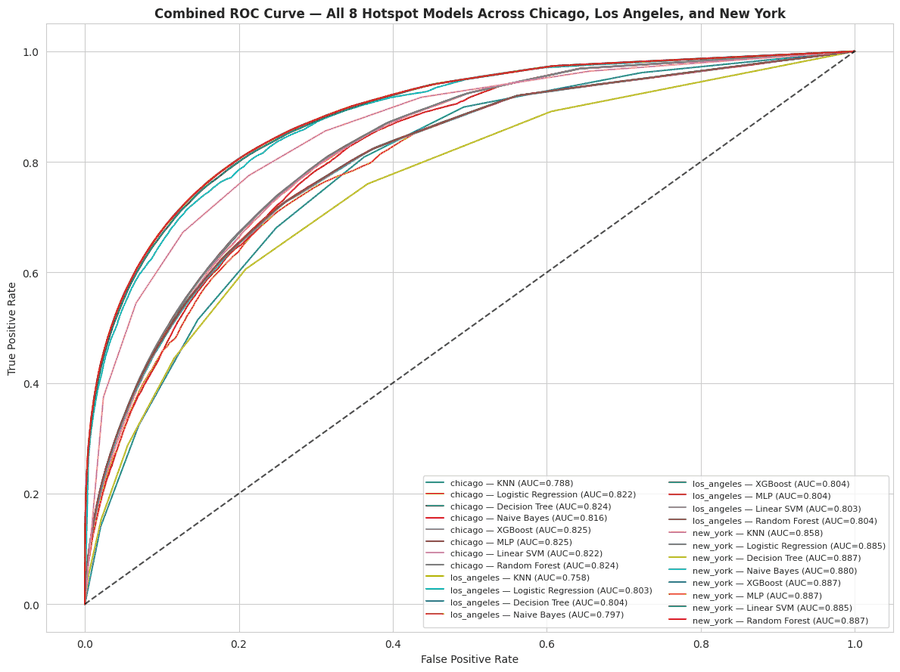

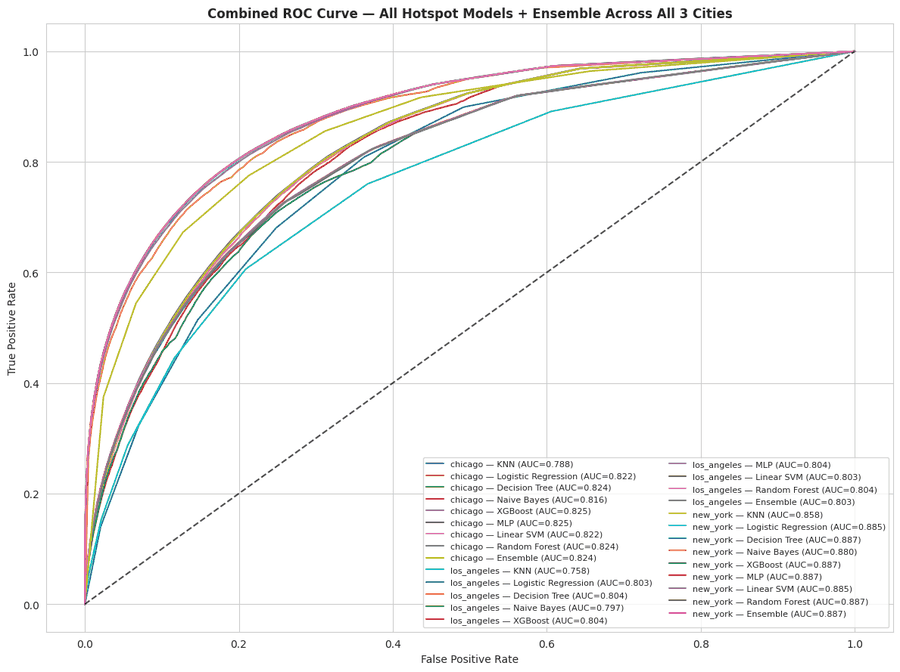

,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,chicago,XGBoost,0.745479,0.743259,0.703233,0.725288,0.714090,0.824704,0.776322,0.485034,0.484846
1,chicago,MLP,0.745195,0.742084,0.706139,0.716907,0.711482,0.824534,0.776496,0.483403,0.483358
2,chicago,Random Forest,0.741858,0.746670,0.677088,0.785627,0.727330,0.824385,0.775872,0.489632,0.484796
3,chicago,Decision Tree,0.744815,0.742624,0.702361,0.724883,0.713444,0.824015,0.773268,0.483739,0.483543
4,chicago,Ensemble,0.744418,0.740712,0.707433,0.710717,0.709071,0.823716,0.773266,0.481183,0.481179
5,chicago,Linear SVM,0.737867,0.725492,0.736719,0.625311,0.676458,0.822048,0.771378,0.462965,0.458608
6,chicago,Logistic Regression,0.737800,0.725460,0.736442,0.625569,0.676493,0.821804,0.770901,0.462826,0.458510
7,chicago,Naive Bayes,0.717419,0.694501,0.767956,0.508975,0.612203,0.816435,0.761367,0.425164,0.403981
8,chicago,KNN,0.720447,0.716070,0.681194,0.680638,0.680916,0.787868,0.697637,0.432178,0.432178
9,los_angeles,XGBoost,0.784084,0.675174,0.675468,0.429874,0.525387,0.804233,0.636641,0.411318,0.394444


In [24]:
# CELL 23 — Combined ROC Curves + Full Hotspot Results Table

def plot_combined_roc_all_8_models(city_roc_dict, save_name="combined_roc_8models_3cities.png"):
    plt.figure(figsize=(12, 9))

    for city_key, roc_pack in city_roc_dict.items():
        for model_name, roc_info in roc_pack.items():
            if model_name == "Ensemble":
                continue
            plt.plot(
                roc_info["fpr"], roc_info["tpr"],
                label=f"{city_key} — {model_name} (AUC={roc_info['auc']:.3f})",
                linewidth=1.5
            )

    plt.plot([0, 1], [0, 1], "k--", alpha=0.7)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Combined ROC Curve — All 8 Hotspot Models Across Chicago, Los Angeles, and New York", fontweight="bold")
    plt.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=300)
    plt.show()


def plot_combined_roc_with_ensemble(city_roc_dict, save_name="combined_roc_allmodels_plus_ensemble_3cities.png"):
    plt.figure(figsize=(12, 9))

    for city_key, roc_pack in city_roc_dict.items():
        for model_name, roc_info in roc_pack.items():
            plt.plot(
                roc_info["fpr"], roc_info["tpr"],
                label=f"{city_key} — {model_name} (AUC={roc_info['auc']:.3f})",
                linewidth=1.5
            )

    plt.plot([0, 1], [0, 1], "k--", alpha=0.7)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Combined ROC Curve — All Hotspot Models + Ensemble Across All 3 Cities", fontweight="bold")
    plt.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, save_name), dpi=300)
    plt.show()


city_roc_dict = {
    "chicago": chi_roc_curves,
    "los_angeles": la_roc_curves,
    "new_york": nyc_roc_curves
}

plot_combined_roc_all_8_models(city_roc_dict)
plot_combined_roc_with_ensemble(city_roc_dict)

# Proper full table for all cities and all hotspot models
chi_all = pd.concat([chi_hotspot_results, pd.DataFrame([chi_ensemble_metrics])], ignore_index=True)
la_all  = pd.concat([la_hotspot_results, pd.DataFrame([la_ensemble_metrics])], ignore_index=True)
nyc_all = pd.concat([nyc_hotspot_results, pd.DataFrame([nyc_ensemble_metrics])], ignore_index=True)

all_hotspot = pd.concat([chi_all, la_all, nyc_all], ignore_index=True)
all_hotspot = all_hotspot[
    ["City", "Model", "Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC", "MCC", "Kappa"]
].sort_values(["City", "ROC_AUC", "F1"], ascending=[True, False, False]).reset_index(drop=True)

all_hotspot.to_csv(os.path.join(TABLE_DIR, "all_cities_all_hotspot_models_table.csv"), index=False)
display(all_hotspot)

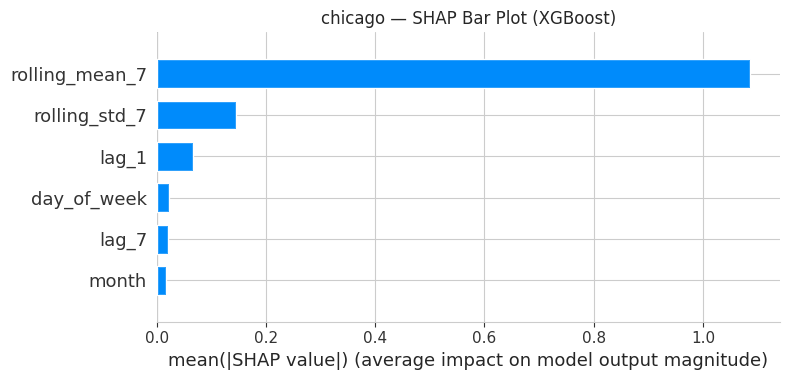

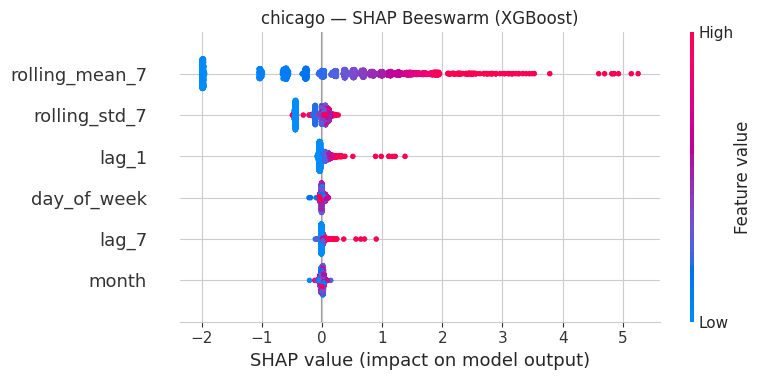

<Figure size 640x480 with 0 Axes>

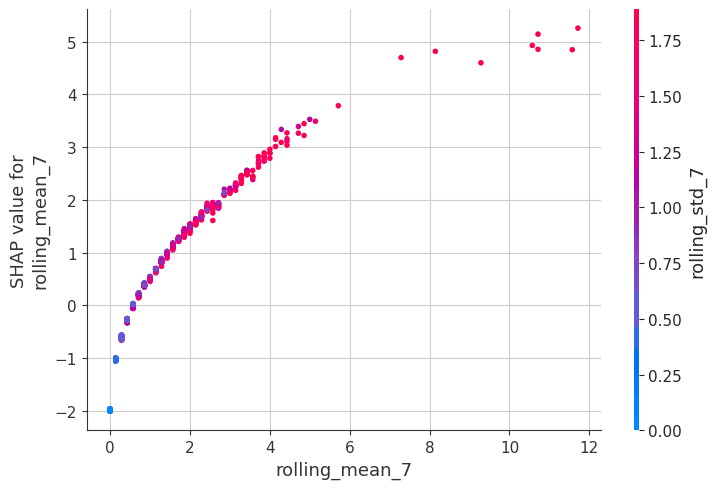

<Figure size 640x480 with 0 Axes>

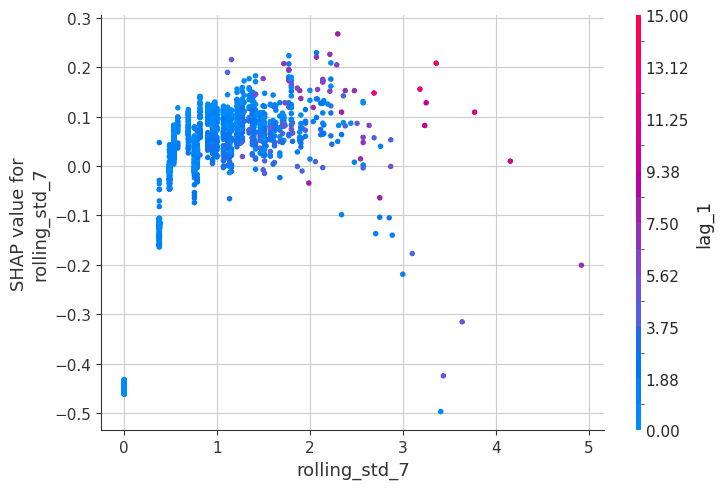

<Figure size 640x480 with 0 Axes>

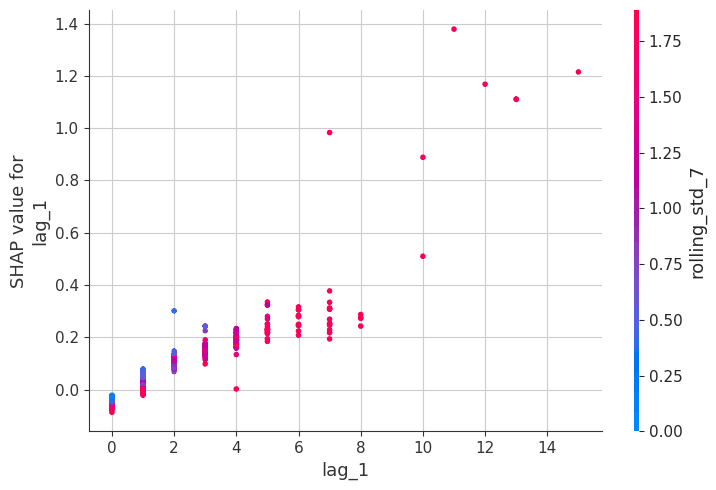

SHAP completed for chicago — best model: XGBoost


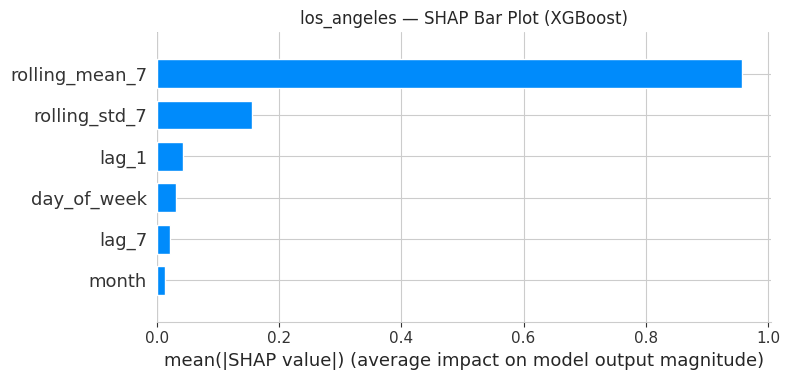

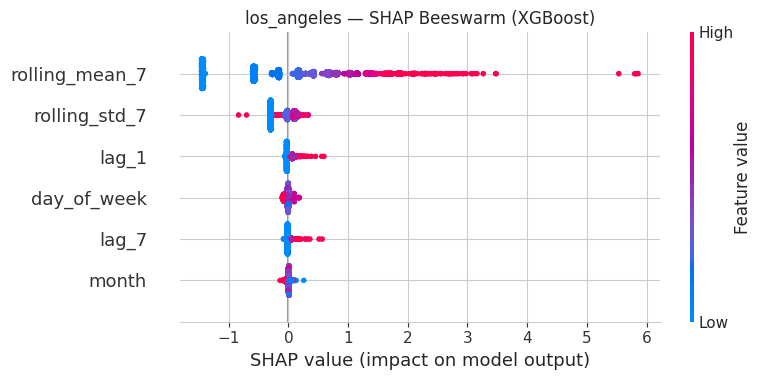

<Figure size 640x480 with 0 Axes>

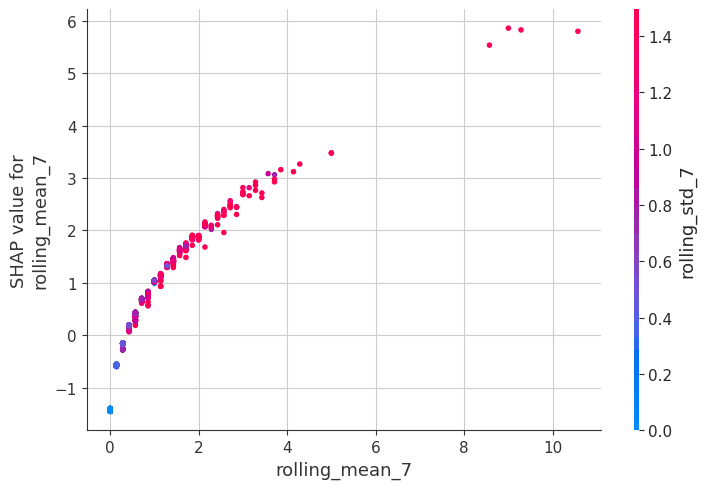

<Figure size 640x480 with 0 Axes>

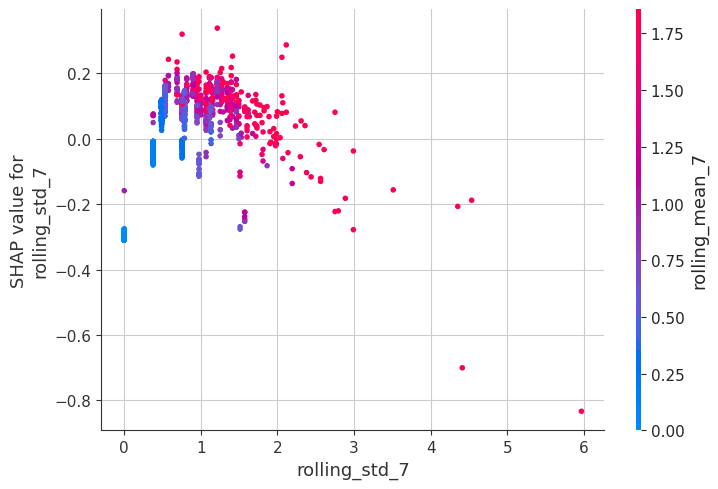

<Figure size 640x480 with 0 Axes>

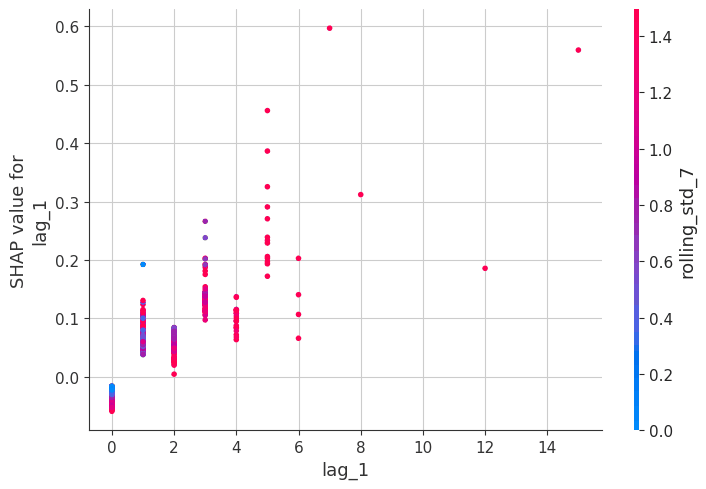

SHAP completed for los_angeles — best model: XGBoost


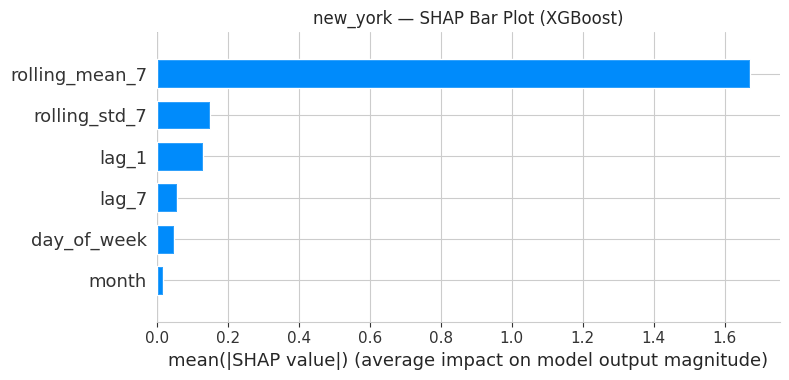

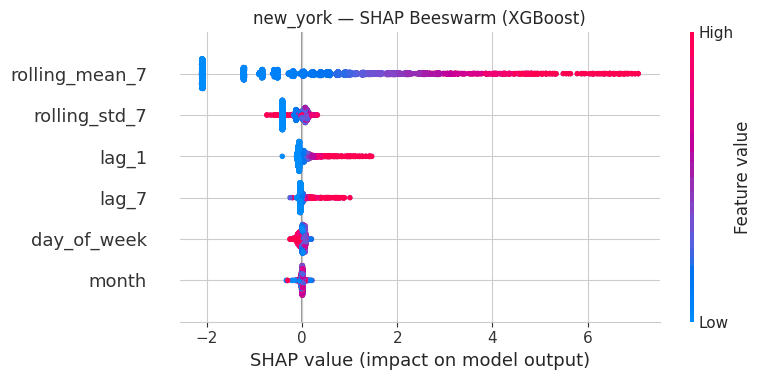

<Figure size 640x480 with 0 Axes>

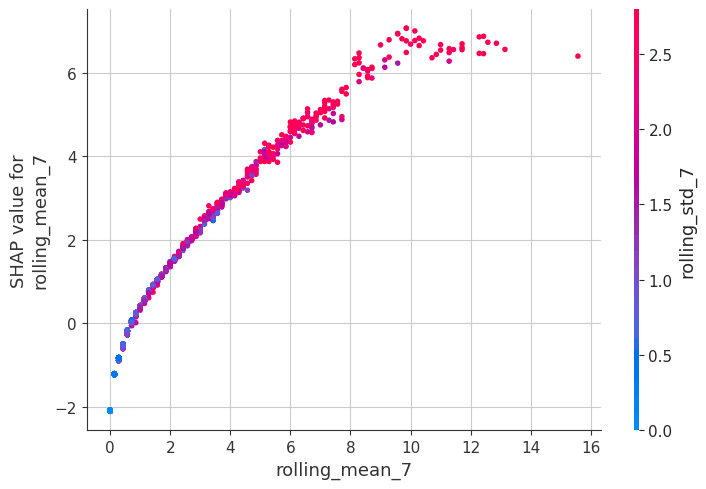

<Figure size 640x480 with 0 Axes>

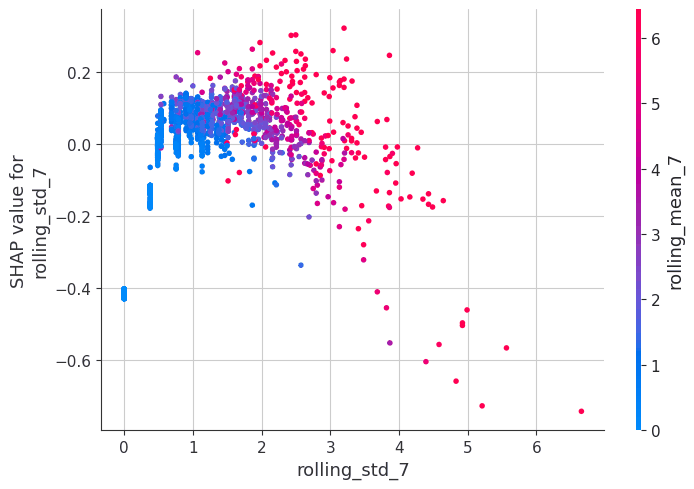

<Figure size 640x480 with 0 Axes>

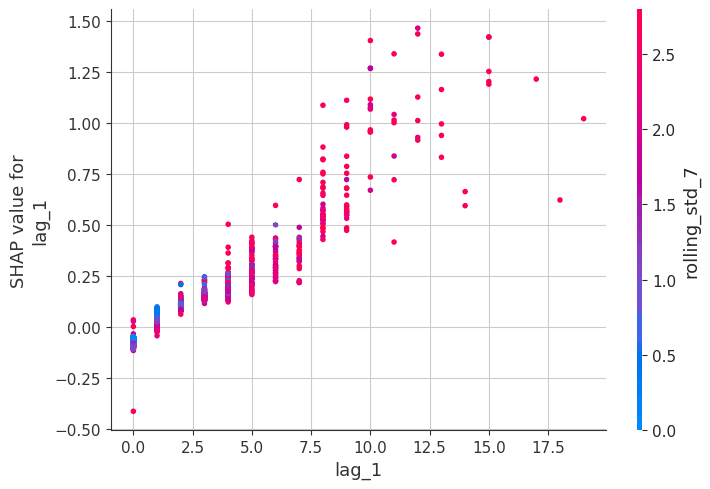

SHAP completed for new_york — best model: XGBoost


In [25]:
# Cell 24 - SHAP CELL — FIXED FEATURE NAMES

def run_shap_for_best_tree_model(results_df, fitted_models, X_train, X_test, city_key, feature_names):
    tree_priority = ["XGBoost", "Random Forest", "Decision Tree"]

    available = results_df.sort_values(["ROC_AUC", "F1"], ascending=False)["Model"].tolist()
    best_model_name = None
    for m in available:
        if m in tree_priority:
            best_model_name = m
            break

    if best_model_name is None:
        print(f"No tree-based model available for SHAP in {city_key}")
        return

    model = fitted_models[best_model_name]

    # If pipeline exists, transform X through preprocessing but keep true names
    if isinstance(model, Pipeline):
        Xt_train = X_train.copy()
        Xt_test = X_test.copy()

        if "imputer" in model.named_steps:
            Xt_train = model.named_steps["imputer"].transform(Xt_train)
            Xt_test = model.named_steps["imputer"].transform(Xt_test)

        core_model = model.named_steps["model"]
    else:
        Xt_train = X_train.values
        Xt_test = X_test.values
        core_model = model

    # Sample for speed
    bg_idx = np.random.choice(len(Xt_train), size=min(1000, len(Xt_train)), replace=False)
    te_idx = np.random.choice(len(Xt_test), size=min(2000, len(Xt_test)), replace=False)

    X_bg = Xt_train[bg_idx]
    X_te = Xt_test[te_idx]

    X_te_df = pd.DataFrame(X_te, columns=feature_names)

    explainer = shap.TreeExplainer(core_model)
    shap_values = explainer.shap_values(X_te)

    city_plot = os.path.join(BASE_OUT, city_key, "plots")

    # Bar plot
    plt.figure()
    shap.summary_plot(shap_values, X_te_df, plot_type="bar", show=False)
    plt.title(f"{city_key} — SHAP Bar Plot ({best_model_name})")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_shap_bar_{best_model_name.lower().replace(' ', '_')}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # Beeswarm
    plt.figure()
    shap.summary_plot(shap_values, X_te_df, show=False)
    plt.title(f"{city_key} — SHAP Beeswarm ({best_model_name})")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_shap_beeswarm_{best_model_name.lower().replace(' ', '_')}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # Dependence for top features
    mean_abs = np.abs(shap_values).mean(axis=0)
    top_idx = np.argsort(mean_abs)[::-1][:3]
    for idx in top_idx:
        fname = feature_names[idx]
        plt.figure()
        shap.dependence_plot(fname, shap_values, X_te_df, show=False)
        plt.tight_layout()
        plt.savefig(os.path.join(city_plot, f"{city_key}_shap_dependence_{fname}.png"), dpi=300, bbox_inches="tight")
        plt.show()

    print(f"SHAP completed for {city_key} — best model: {best_model_name}")


run_shap_for_best_tree_model(chi_hotspot_results, chi_fitted_models, chi_Xtr, chi_Xte, "chicago", FEATURE_COLS_HOTSPOT)
run_shap_for_best_tree_model(la_hotspot_results, la_fitted_models, la_Xtr, la_Xte, "los_angeles", FEATURE_COLS_HOTSPOT)
run_shap_for_best_tree_model(nyc_hotspot_results, nyc_fitted_models, nyc_Xtr, nyc_Xte, "new_york", FEATURE_COLS_HOTSPOT)

# *PART 3 — TIME SERIES ANALYSIS + FORECASTING*

In [26]:
# CELL 25 — Build Daily / Monthly Total Time Series (FIXED FOR NYC STABILITY)

FORECAST_START_YEAR_BY_CITY = {
    "chicago": 2010,
    "los_angeles": 2010,
    "new_york": 2019
}

def build_time_series_frames(df, city_key):
    tmp = df.copy()

    # Keep a modern, comparable forecasting window
    start_year = FORECAST_START_YEAR_BY_CITY[city_key]
    tmp = tmp[tmp["year"] >= start_year].copy()

    daily_total = (
        tmp.groupby("date_only")
        .size()
        .reset_index(name="crime_count")
        .sort_values("date_only")
        .reset_index(drop=True)
    )

    # Fill missing dates so the series is continuous
    full_dates = pd.date_range(daily_total["date_only"].min(), daily_total["date_only"].max(), freq="D")
    daily_total = (
        daily_total.set_index("date_only")
        .reindex(full_dates, fill_value=0)
        .rename_axis("date_only")
        .reset_index()
    )

    monthly_total = (
        daily_total.set_index("date_only")["crime_count"]
        .resample("M")
        .sum()
        .reset_index()
    )

    daily_total.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_daily_total_series.csv"), index=False)
    monthly_total.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_monthly_total_series.csv"), index=False)

    return daily_total, monthly_total


chi_daily_total, chi_monthly_total = build_time_series_frames(df_chi, "chicago")
la_daily_total, la_monthly_total   = build_time_series_frames(df_la, "los_angeles")
nyc_daily_total, nyc_monthly_total = build_time_series_frames(df_nyc, "new_york")

print(chi_daily_total.head())
print(la_daily_total.head())
print(nyc_daily_total.head())

print("Chicago daily starts:", chi_daily_total["date_only"].min(), "ends:", chi_daily_total["date_only"].max())
print("LA daily starts:", la_daily_total["date_only"].min(), "ends:", la_daily_total["date_only"].max())
print("NYC daily starts:", nyc_daily_total["date_only"].min(), "ends:", nyc_daily_total["date_only"].max())

   date_only  crime_count
0 2010-01-01         1354
1 2010-01-02          792
2 2010-01-03          759
3 2010-01-04          855
4 2010-01-05          910
   date_only  crime_count
0 2010-01-01         2351
1 2010-01-02          535
2 2010-01-03          539
3 2010-01-04          559
4 2010-01-05          548
   date_only  crime_count
0 2019-01-01         2212
1 2019-01-02         1250
2 2019-01-03         1268
3 2019-01-04         1354
4 2019-01-05         1162
Chicago daily starts: 2010-01-01 00:00:00 ends: 2026-03-09 00:00:00
LA daily starts: 2010-01-01 00:00:00 ends: 2019-12-31 00:00:00
NYC daily starts: 2019-01-01 00:00:00 ends: 2024-12-31 00:00:00


In [27]:
# CELL 26 — Choose Forecast Granularity Properly (FIXED FOR COMPARABILITY)

FORECAST_LOOK_BACK = 30
EPOCHS = 80
BATCH_SIZE = 32
PATIENCE = 10

# IMPORTANT:
# To make models comparable, use DAILY forecasting for DL and classical time-series too.
FORECAST_FREQ = "DAILY"

print("All total-forecast models will use DAILY series for comparability.")
print("Look-back:", FORECAST_LOOK_BACK)

All total-forecast models will use DAILY series for comparability.
Look-back: 30


In [28]:
# CELL 27 — Feature Engineering for DL Forecasting

def make_temporal_features_from_daily(daily_df):
    df = daily_df.copy()
    df["day_of_week"] = df["date_only"].dt.dayofweek
    df["month"] = df["date_only"].dt.month
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
    df["lag_1"] = df["crime_count"].shift(1)
    df["lag_7"] = df["crime_count"].shift(7)
    df["rolling_mean_7"] = df["crime_count"].shift(1).rolling(7).mean()
    df["rolling_std_7"] = df["crime_count"].shift(1).rolling(7).std()
    df = df.dropna().reset_index(drop=True)
    return df


chi_daily_feat = make_temporal_features_from_daily(chi_daily_total)
la_daily_feat  = make_temporal_features_from_daily(la_daily_total)
nyc_daily_feat = make_temporal_features_from_daily(nyc_daily_total)

print(chi_daily_feat.head())


   date_only  crime_count  day_of_week  month  is_weekend  lag_1   lag_7  \
0 2010-01-08          931            4      1           0  862.0  1354.0   
1 2010-01-09          818            5      1           1  931.0   792.0   
2 2010-01-10          779            6      1           1  818.0   759.0   
3 2010-01-11          953            0      1           0  779.0   855.0   
4 2010-01-12         1002            1      1           0  953.0   910.0   

   rolling_mean_7  rolling_std_7  
0      916.857143     199.765219  
1      856.428571      61.889302  
2      860.142857      58.038575  
3      863.000000      52.453154  
4      877.000000      62.144992  


In [29]:
# CELL 28 — Sequence Builder / DL Data Prep (COMPATIBLE + STABLE)

def create_sequences(feature_array, target_array, look_back=30):
    X, y = [], []
    for i in range(look_back, len(feature_array)):
        X.append(feature_array[i-look_back:i])
        y.append(target_array[i])
    return np.array(X), np.array(y)


def prepare_dl_data(daily_feat_df, look_back=30, split_ratio=0.8):
    df = daily_feat_df.copy().sort_values("date_only").reset_index(drop=True)

    df = df.dropna().copy()
    df = df[np.isfinite(df["crime_count"])].copy()
    df = df[df["crime_count"] >= 0].copy()

    feature_cols = [
        "crime_count", "day_of_week", "month", "is_weekend",
        "lag_1", "lag_7", "rolling_mean_7", "rolling_std_7"
    ]
    target_col = "crime_count"

    n = len(df)
    split_idx = int(n * split_ratio)

    train_df = df.iloc[:split_idx].copy()
    test_df  = df.iloc[split_idx:].copy()

    X_train_raw = train_df[feature_cols].values.astype(float)
    X_test_raw  = test_df[feature_cols].values.astype(float)

    y_train_raw = train_df[[target_col]].values.astype(float)
    y_test_raw  = test_df[[target_col]].values.astype(float)

    feature_scaler = StandardScaler()
    X_train_scaled = feature_scaler.fit_transform(X_train_raw)
    X_test_scaled  = feature_scaler.transform(X_test_raw)

    target_scaler = StandardScaler()
    y_train_log = np.log1p(y_train_raw)
    y_test_log  = np.log1p(y_test_raw)

    y_train_scaled = target_scaler.fit_transform(y_train_log).reshape(-1)
    y_test_scaled  = target_scaler.transform(y_test_log).reshape(-1)

    Xtr_seq, ytr_seq = create_sequences(X_train_scaled, y_train_scaled, look_back)

    X_test_mix = np.vstack([X_train_scaled[-look_back:], X_test_scaled])
    y_test_mix = np.concatenate([y_train_scaled[-look_back:], y_test_scaled])

    Xte_seq, yte_seq = create_sequences(X_test_mix, y_test_mix, look_back)

    y_test_raw_seq = y_test_raw.reshape(-1)[-len(Xte_seq):]
    test_dates = test_df["date_only"].values[-len(Xte_seq):]

    return {
        "train_df": train_df,
        "test_df": test_df,
        "feature_scaler": feature_scaler,
        "target_scaler": target_scaler,
        "X_train_seq": Xtr_seq,
        "y_train_seq": ytr_seq,
        "X_test_seq": Xte_seq,
        "y_test_seq": yte_seq,
        "y_test_raw": y_test_raw_seq,
        "test_dates": test_dates,
        "feature_cols": feature_cols
    }


chi_dl = prepare_dl_data(chi_daily_feat, look_back=FORECAST_LOOK_BACK)
la_dl  = prepare_dl_data(la_daily_feat,  look_back=FORECAST_LOOK_BACK)
nyc_dl = prepare_dl_data(nyc_daily_feat, look_back=FORECAST_LOOK_BACK)

print("Chicago X_train_seq:", chi_dl["X_train_seq"].shape)
print("LA X_train_seq:", la_dl["X_train_seq"].shape)
print("NYC X_train_seq:", nyc_dl["X_train_seq"].shape)

Chicago X_train_seq: (4694, 30, 8)
LA X_train_seq: (2886, 30, 8)
NYC X_train_seq: (1718, 30, 8)


In [30]:
# CELL 29 — Deep Learning Models: LSTM, GRU, CNN, Transformer

def build_lstm_model(input_shape):
    inp = Input(shape=input_shape)
    x = LSTM(64, return_sequences=False)(inp)
    x = Dropout(0.2)(x)
    x = Dense(32, activation="relu")(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def build_gru_model(input_shape):
    inp = Input(shape=input_shape)
    x = GRU(64, return_sequences=False)(inp)
    x = Dropout(0.2)(x)
    x = Dense(32, activation="relu")(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def build_cnn_model(input_shape):
    inp = Input(shape=input_shape)
    x = Conv1D(64, kernel_size=3, activation="relu", padding="causal")(inp)
    x = Conv1D(64, kernel_size=3, activation="relu", padding="causal")(x)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation="relu")(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def transformer_encoder(x, head_size=32, num_heads=2, ff_dim=64, dropout=0.1):
    attn = MultiHeadAttention(num_heads=num_heads, key_dim=head_size, dropout=dropout)(x, x)
    x = Add()([x, attn])
    x = LayerNormalization(epsilon=1e-6)(x)

    ff = Dense(ff_dim, activation="relu")(x)
    ff = Dropout(dropout)(ff)
    ff = Dense(x.shape[-1])(ff)
    x = Add()([x, ff])
    x = LayerNormalization(epsilon=1e-6)(x)
    return x


def build_transformer_model(input_shape):
    inp = Input(shape=input_shape)
    x = transformer_encoder(inp, head_size=32, num_heads=2, ff_dim=64, dropout=0.1)
    x = transformer_encoder(x, head_size=32, num_heads=2, ff_dim=64, dropout=0.1)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation="relu")(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


In [31]:
# CELL 30 — Forecast Metrics Function

def forecast_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    evs = explained_variance_score(y_true, y_pred)

    mean_actual = np.mean(y_true)
    nrmse_pct = (rmse / (mean_actual + 1e-9)) * 100
    cvrmse_pct = nrmse_pct

    mape_safe = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-9, None))) * 100
    smape = np.mean(2*np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-9)) * 100
    wape = (np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + 1e-9)) * 100

    naive_denom = np.mean(np.abs(np.diff(y_true))) + 1e-9
    mase = mae / naive_denom

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MedAE": medae,
        "R2": r2,
        "Explained_Variance": evs,
        "Mean_Actual": mean_actual,
        "NRMSE_pct": nrmse_pct,
        "CVRMSE_pct": cvrmse_pct,
        "MAPE_safe": mape_safe,
        "sMAPE": smape,
        "WAPE_pct": wape,
        "MASE": mase,
    }


In [32]:
# CELL 31 — Train & Evaluate One DL Forecast Model (STABILIZED)

def fit_predict_dl_model(model_builder, model_name, dl_pack, city_key, epochs=80, batch_size=32, patience=10):
    X_train_full = dl_pack["X_train_seq"]
    y_train_full = dl_pack["y_train_seq"]
    X_test       = dl_pack["X_test_seq"]
    y_test_raw   = dl_pack["y_test_raw"]
    test_dates   = dl_pack["test_dates"]
    target_scaler = dl_pack["target_scaler"]

    val_size = max(1, int(len(X_train_full) * 0.15))
    X_train = X_train_full[:-val_size]
    y_train = y_train_full[:-val_size]
    X_val   = X_train_full[-val_size:]
    y_val   = y_train_full[-val_size:]

    tf.keras.backend.clear_session()

    model = model_builder(input_shape=(X_train.shape[1], X_train.shape[2]))

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 2), min_lr=1e-5, verbose=1)
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=callbacks,
        shuffle=False
    )

    y_pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)

    # inverse back to original count scale
    y_pred_log = target_scaler.inverse_transform(y_pred_scaled).reshape(-1)
    y_pred = np.expm1(y_pred_log)

    # keep sane
    y_pred = np.nan_to_num(y_pred, nan=0.0, posinf=np.max(y_test_raw), neginf=0.0)
    y_pred = np.clip(y_pred, 0, np.percentile(y_test_raw, 99.5) * 1.25)

    metrics = forecast_metrics(y_test_raw, y_pred)
    metrics["Model"] = model_name
    metrics["City"] = city_key

    stopped_epoch = len(history.history["loss"])
    final_train_loss = float(history.history["loss"][-1])
    final_val_loss   = float(history.history["val_loss"][-1])
    ratio = final_val_loss / (final_train_loss + 1e-12)

    metrics["Stopped_Epoch"] = stopped_epoch
    metrics["Final_Train_Loss"] = final_train_loss
    metrics["Final_Val_Loss"] = final_val_loss
    metrics["Val_Train_Ratio"] = ratio
    metrics["Healthy_Comment"] = "Healthy" if 0.7 <= ratio <= 3.5 else "Check overfitting/underfitting"

    city_plot = os.path.join(BASE_OUT, city_key, "plots")
    city_table = os.path.join(BASE_OUT, city_key, "tables")
    city_model = os.path.join(BASE_OUT, city_key, "models")

    safe_name = model_name.lower().replace(" ", "_")

    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(f"{city_key.upper()} {model_name} — Training vs Validation Loss", fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{safe_name}_training_curve.png"), dpi=300)
    plt.show()

    print(f"{city_key.upper()} {model_name}")
    print(f"Stopped at epoch {stopped_epoch}")
    print(f"Final train loss: {final_train_loss:.6f}")
    print(f"Final val loss: {final_val_loss:.6f}")
    print(f"Ratio (val/train): {ratio:.2f}")
    print("Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(y_test_raw, y_pred, alpha=0.35, s=10)
    lo = min(y_test_raw.min(), y_pred.min())
    hi = max(y_test_raw.max(), y_pred.max())
    axes[0].plot([lo, hi], [lo, hi], "r--", linewidth=1.5)
    axes[0].set_title(f"{city_key.upper()} {model_name}: Actual vs Predicted", fontweight="bold")
    axes[0].set_xlabel("Actual")
    axes[0].set_ylabel("Predicted")

    axes[1].plot(test_dates, y_test_raw, label="Actual", linewidth=1.6)
    axes[1].plot(test_dates, y_pred, label="Predicted", linestyle="--", linewidth=1.4)
    axes[1].set_title(f"{city_key.upper()} {model_name}: Time-Series Overlay", fontweight="bold")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("Crime Count")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{safe_name}_scatter_overlay.png"), dpi=300)
    plt.show()

    residuals = y_test_raw - y_pred

    pd.DataFrame({
        "City": city_key,
        "Model": model_name,
        "date_only": test_dates,
        "actual": y_test_raw,
        "predicted": y_pred,
        "residual": residuals
    }).to_csv(
        os.path.join(city_table, f"{safe_name}_predictions.csv"), index=False
    )

    pd.DataFrame([metrics]).to_csv(
        os.path.join(city_table, f"{safe_name}_metrics.csv"), index=False
    )

    model.save(os.path.join(city_model, f"{safe_name}_forecast_model.keras"))

    return metrics, model, y_pred, history

In [33]:
# CELL 32 — Run All DL Forecast Models for One City (FIXED OUTPUT TABLES)

def run_all_dl_models(dl_pack, city_key):
    results = []
    preds = {}
    histories = {}

    model_builders = {
        "LSTM": build_lstm_model,
        "GRU": build_gru_model,
        "CNN": build_cnn_model,
        "Transformer": build_transformer_model
    }

    for model_name, builder in model_builders.items():
        print(f"\nRunning {city_key} — {model_name}")
        metrics, model, pred, history = fit_predict_dl_model(
            builder, model_name, dl_pack, city_key,
            epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE
        )
        results.append(metrics)
        preds[model_name] = pred
        histories[model_name] = history

    res_df = pd.DataFrame(results)
    res_df = res_df[
        [
            "City", "Model", "RMSE", "MAE", "MedAE", "R2", "Explained_Variance",
            "Mean_Actual", "NRMSE_pct", "CVRMSE_pct", "MAPE_safe", "sMAPE",
            "WAPE_pct", "MASE", "Stopped_Epoch", "Final_Train_Loss",
            "Final_Val_Loss", "Val_Train_Ratio", "Healthy_Comment"
        ]
    ].sort_values("RMSE").reset_index(drop=True)

    res_df.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_all_dl_results.csv"), index=False)
    display(res_df)

    return res_df, preds, histories


Running chicago — LSTM


I0000 00:00:1775256184.207170      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1775256184.215507      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/80


I0000 00:00:1775256188.078909     530 cuda_dnn.cc:529] Loaded cuDNN version 91002


125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.4756 - val_loss: 0.3150 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2187 - val_loss: 0.1930 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2012 - val_loss: 0.1896 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1987 - val_loss: 0.1789 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1921 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1907 - val_loss: 0.2613 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1798 - val_loss: 0.2248 - learning_rate: 0.0010
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1808 - val_loss: 0.2133 - learning_rate: 0.0010
Epoch 9/80
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1808
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.00050000

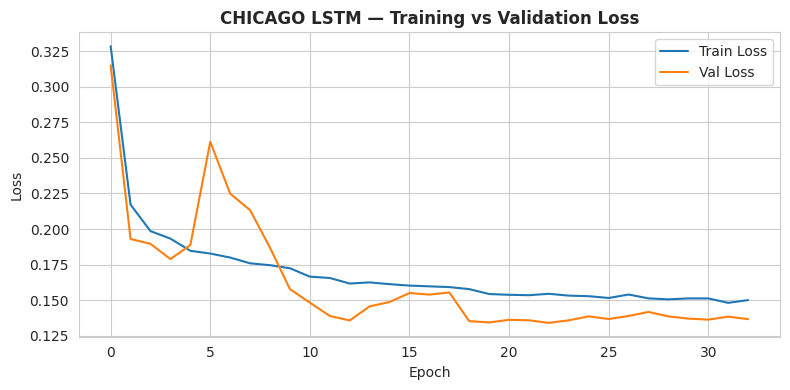

CHICAGO LSTM
Stopped at epoch 33
Final train loss: 0.150056
Final val loss: 0.136654
Ratio (val/train): 0.91
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


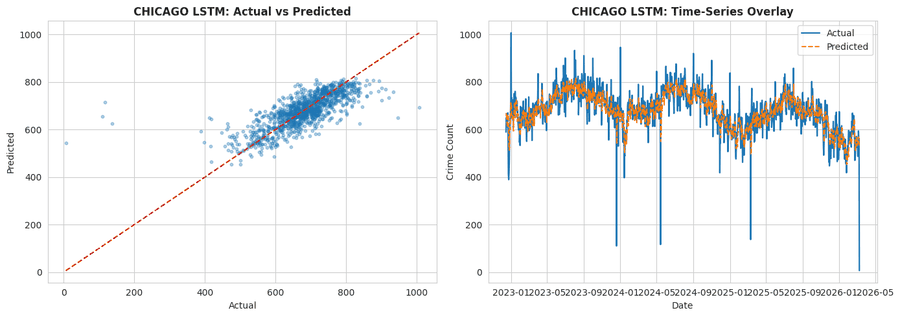


Running chicago — GRU
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.1280 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2161 - val_loss: 0.1601 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2064 - val_loss: 0.1563 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1976 - val_loss: 0.1721 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1887 - val_loss: 0.1541 - learning_rate: 0.0010
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1783 - val_loss: 0.1771 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1726 - val_loss: 0.1677 - learning_rate: 0.0010
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1696 - val_loss: 0.1663 - learning_rate: 0.0010
Epoch 9/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1686 - val_loss: 0.1710 - learning_

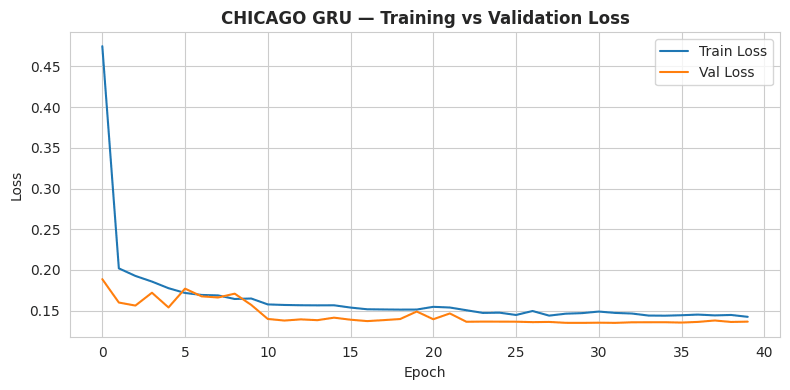

CHICAGO GRU
Stopped at epoch 40
Final train loss: 0.142516
Final val loss: 0.136612
Ratio (val/train): 0.96
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


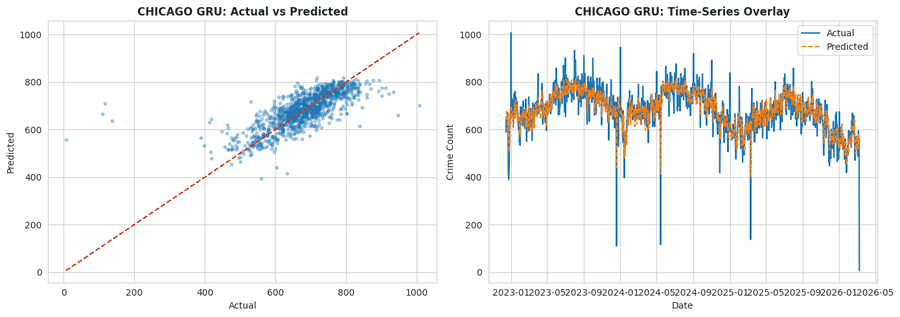


Running chicago — CNN
Epoch 1/80


I0000 00:00:1775256254.856539     529 service.cc:152] XLA service 0x7ce3040f6ef0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775256254.856583     529 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775256254.856588     529 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


 65/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7601

I0000 00:00:1775256257.602796     529 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.5704 - val_loss: 0.2439 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2492 - val_loss: 0.2361 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2347 - val_loss: 0.2280 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2357 - val_loss: 0.2462 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2272 - val_loss: 0.2495 - learning_rate: 0.0010
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2314 - val_loss: 0.2474 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2218 - val_loss: 0.2241 - learning_rate: 0.0010
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2222 - val_loss: 0.2290 - learning_rate: 0.0010
Epoch 9/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2215 - val_loss: 0.2288 - learning_rate: 0.0010
Epoch 10/80
125/125 

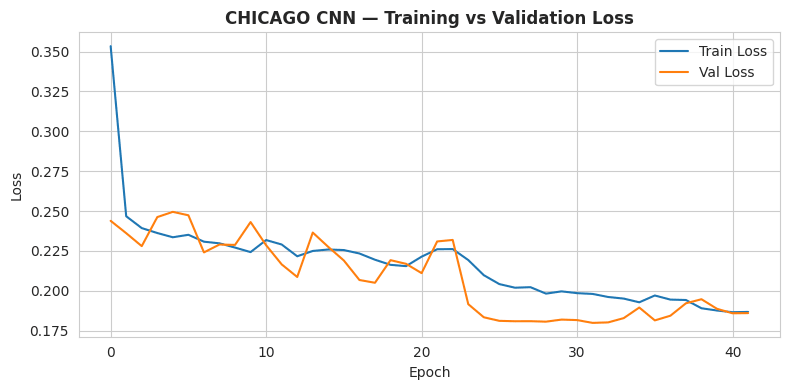

CHICAGO CNN
Stopped at epoch 42
Final train loss: 0.186763
Final val loss: 0.186025
Ratio (val/train): 1.00
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


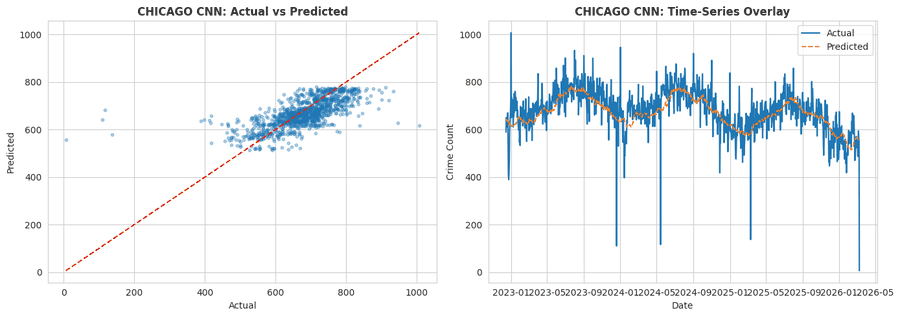


Running chicago — Transformer
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step - loss: 0.9012 - val_loss: 0.3056 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4473 - val_loss: 0.2844 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3851 - val_loss: 0.2598 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3311 - val_loss: 0.2614 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2675 - val_loss: 0.2341 - learning_rate: 0.0010
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2508 - val_loss: 0.2278 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2557 - val_loss: 0.2174 - learning_rate: 0.0010
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2526 - val_loss: 0.2148 - learning_rate: 0.0010
Epoch 9/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2482 - val_loss: 0.1987 -

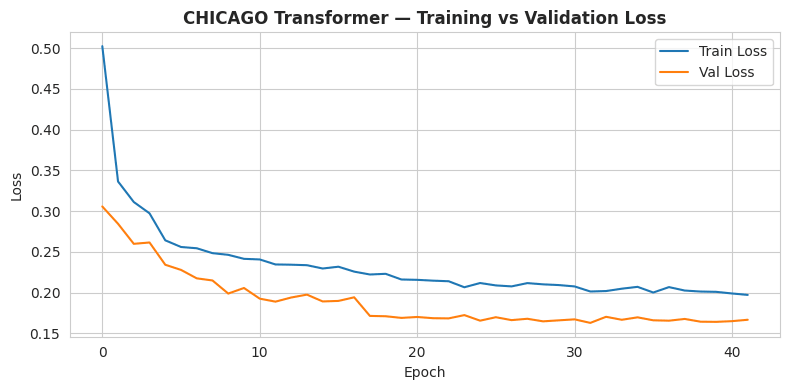

CHICAGO Transformer
Stopped at epoch 42
Final train loss: 0.197041
Final val loss: 0.166538
Ratio (val/train): 0.85
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


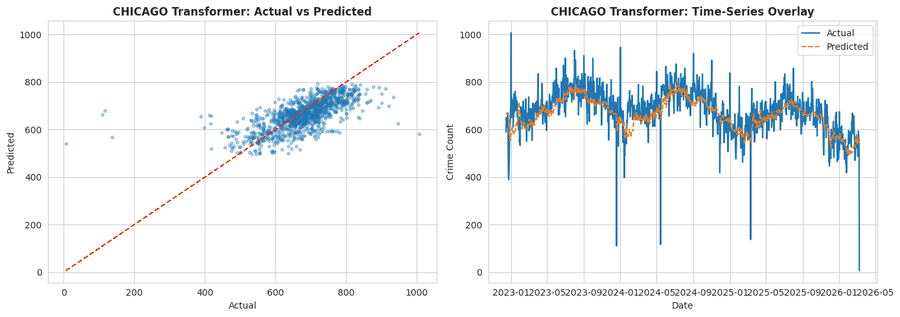

,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,14.642355,6.358405,6.026386,0.824800,33,0.150056,0.136654,0.910688,Healthy
1,chicago,GRU,61.158163,40.721643,31.078674,0.541631,0.542319,678.906859,9.008329,9.008329,14.824343,6.333754,5.998119,0.820931,40,0.142516,0.136612,0.958567,Healthy
2,chicago,CNN,67.175238,46.606100,36.609741,0.447001,0.460722,678.906859,9.894618,9.894618,15.584130,7.237335,6.864874,0.939559,42,0.186763,0.186025,0.996047,Healthy
3,chicago,Transformer,69.469179,48.358224,37.325317,0.408587,0.440743,678.906859,10.232505,10.232505,15.578690,7.522882,7.122954,0.974881,42,0.197041,0.166538,0.845193,Healthy


In [34]:
# CELL 33 — Run DL Forecast Models: Chicago
chi_dl_results, chi_dl_preds, chi_dl_histories = run_all_dl_models(chi_dl, "chicago")


Running los_angeles — LSTM
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4836 - val_loss: 0.5789 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5845 - val_loss: 0.4468 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4641 - val_loss: 0.4075 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4705 - val_loss: 0.4610 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4510 - val_loss: 0.3933 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4367 - val_loss: 0.3708 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4163 - val_loss: 0.3581 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4109 - val_loss: 0.3568 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4122 - val_loss: 0.3601 - learning_rate: 0.0010

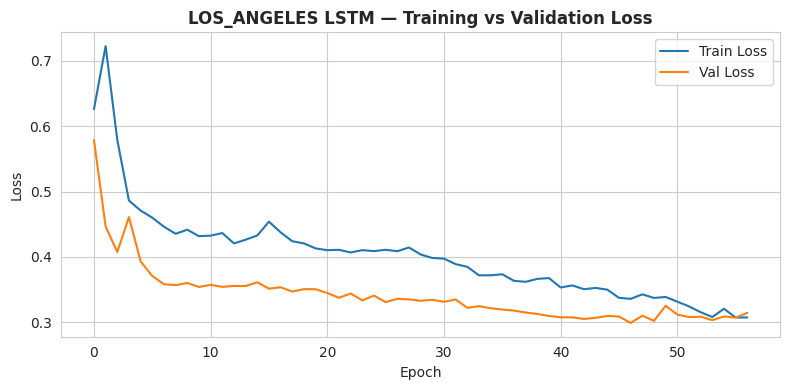

LOS_ANGELES LSTM
Stopped at epoch 57
Final train loss: 0.307356
Final val loss: 0.314371
Ratio (val/train): 1.02
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


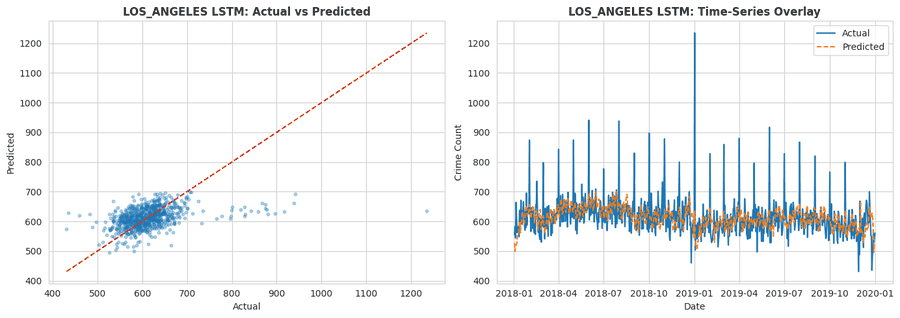


Running los_angeles — GRU
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.4558 - val_loss: 0.4091 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5577 - val_loss: 0.3919 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4932 - val_loss: 0.4244 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4381 - val_loss: 0.3526 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4792 - val_loss: 0.3485 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4164 - val_loss: 0.3352 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4568 - val_loss: 0.3497 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4162 - val_loss: 0.3452 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4505 - val_loss: 0.3381 - learning_rate: 0.0010
E

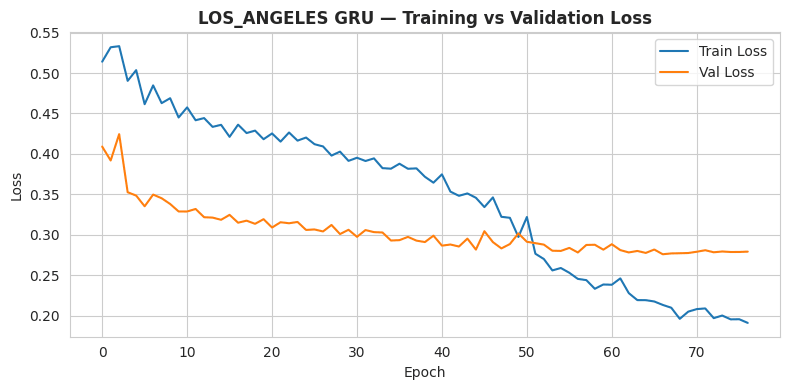

LOS_ANGELES GRU
Stopped at epoch 77
Final train loss: 0.191117
Final val loss: 0.279204
Ratio (val/train): 1.46
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


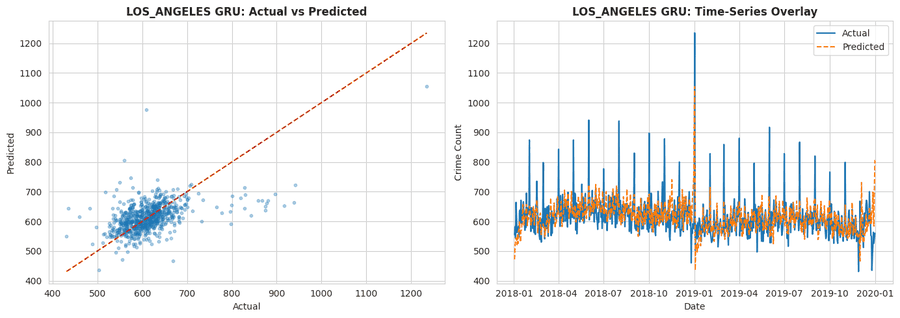


Running los_angeles — CNN
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.4830 - val_loss: 0.5044 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4949 - val_loss: 0.5160 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4534 - val_loss: 0.4460 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4587 - val_loss: 0.5149 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4665 - val_loss: 0.6513 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4392 - val_loss: 0.4386 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4370 - val_loss: 0.4947 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4459 - val_loss: 0.4696 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4408 - val_loss: 0.4489 - learning_rate: 0.0010


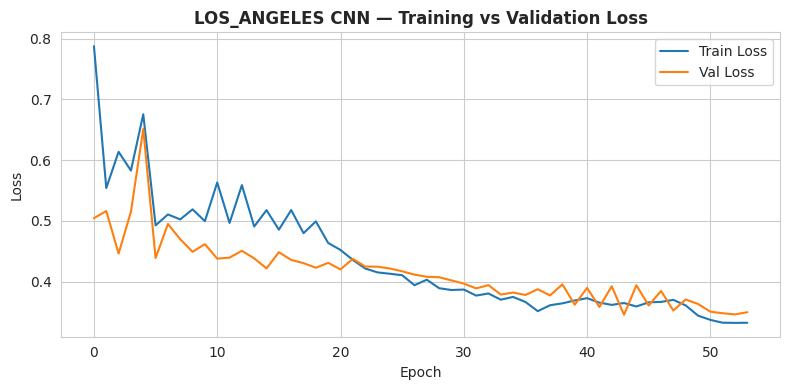

LOS_ANGELES CNN
Stopped at epoch 54
Final train loss: 0.332046
Final val loss: 0.349444
Ratio (val/train): 1.05
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


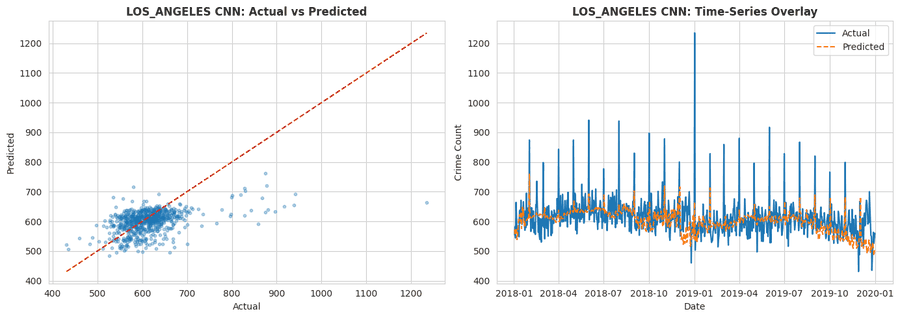


Running los_angeles — Transformer
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 18s 95ms/step - loss: 0.5714 - val_loss: 0.4695 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5361 - val_loss: 0.4382 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4960 - val_loss: 0.4028 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4613 - val_loss: 0.3993 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4554 - val_loss: 0.5401 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4642 - val_loss: 0.4541 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4537 - val_loss: 0.4201 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4410 - val_loss: 0.3988 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4358 - val_loss: 0.3890 - learning_rate

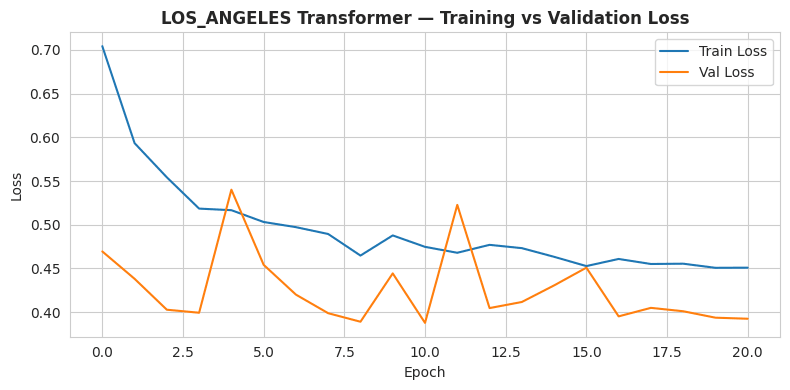

LOS_ANGELES Transformer
Stopped at epoch 21
Final train loss: 0.450899
Final val loss: 0.392464
Ratio (val/train): 0.87
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


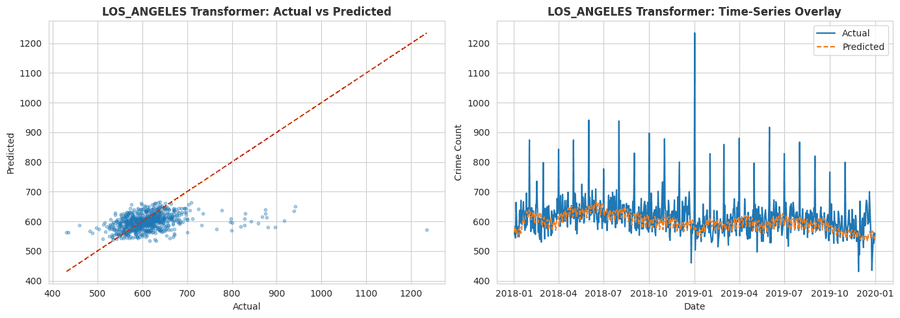

,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.62963,9.367761,9.367761,6.229956,6.196267,6.332339,0.730295,77,0.191117,0.279204,1.460902,Healthy
1,los_angeles,LSTM,59.050263,38.540328,29.327209,0.118007,0.118207,613.62963,9.623111,9.623111,6.097806,6.138450,6.280715,0.724341,57,0.307356,0.314371,1.022823,Healthy
2,los_angeles,CNN,59.080017,39.840997,29.280334,0.117118,0.164321,613.62963,9.627960,9.627960,6.257692,6.423233,6.492678,0.748787,54,0.332046,0.349444,1.052397,Healthy
3,los_angeles,Transformer,62.572508,38.310440,26.557983,0.009650,0.063490,613.62963,10.197113,10.197113,5.904475,6.103548,6.243251,0.720021,21,0.450899,0.392464,0.870402,Healthy


In [35]:
# CELL 34 — Run DL Forecast Models: Los Angeles
la_dl_results, la_dl_preds, la_dl_histories = run_all_dl_models(la_dl, "los_angeles")


Running new_york — LSTM
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.4861 - val_loss: 0.1924 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3776 - val_loss: 0.1946 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3415 - val_loss: 0.1733 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3105 - val_loss: 0.1646 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3061 - val_loss: 0.1583 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3025 - val_loss: 0.1534 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2847 - val_loss: 0.1517 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2806 - val_loss: 0.1502 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2774 - val_loss: 0.1456 - learning_rate: 0.0010
Ep

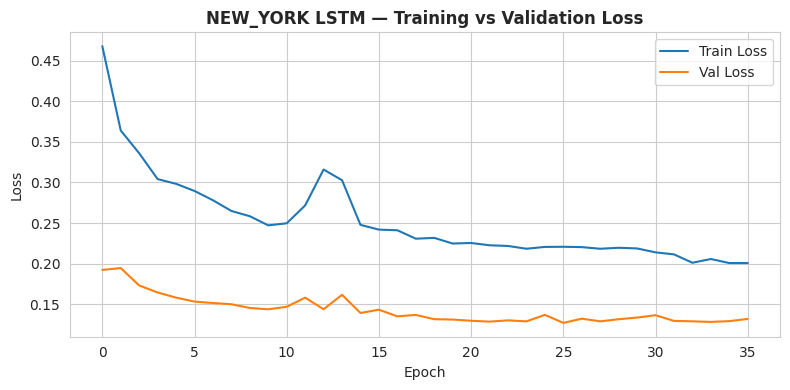

NEW_YORK LSTM
Stopped at epoch 36
Final train loss: 0.200837
Final val loss: 0.132123
Ratio (val/train): 0.66
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


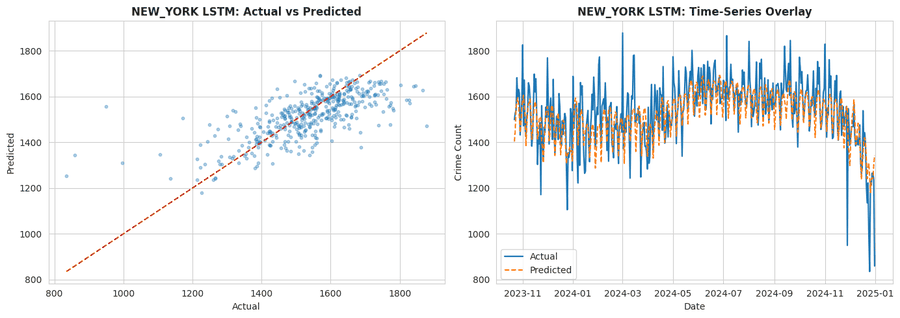


Running new_york — GRU
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.5051 - val_loss: 0.2044 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3300 - val_loss: 0.1627 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3148 - val_loss: 0.1589 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2997 - val_loss: 0.1523 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2876 - val_loss: 0.1472 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2890 - val_loss: 0.1567 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2771 - val_loss: 0.1433 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2828 - val_loss: 0.1508 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2701 - val_loss: 0.1426 - learning_rate: 0.0010
Epo

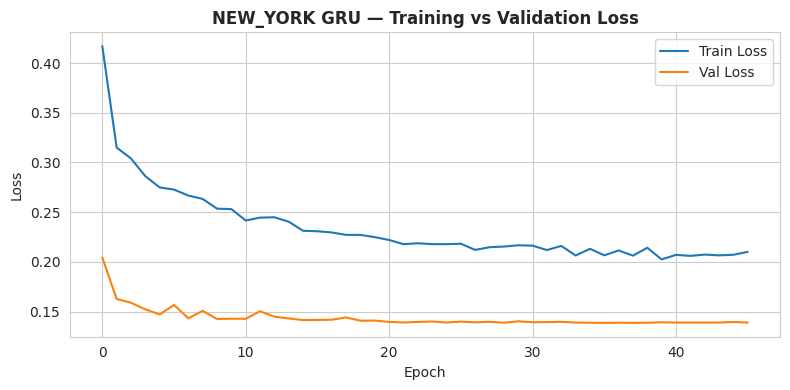

NEW_YORK GRU
Stopped at epoch 46
Final train loss: 0.210121
Final val loss: 0.138989
Ratio (val/train): 0.66
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


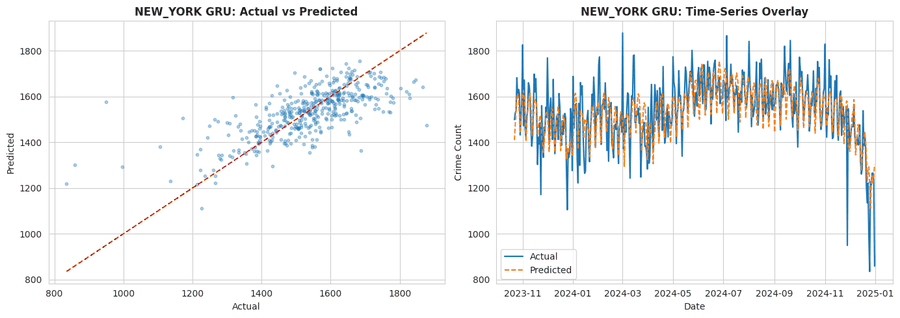


Running new_york — CNN
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.6685 - val_loss: 0.2141 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4856 - val_loss: 0.2726 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4250 - val_loss: 0.2618 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4225 - val_loss: 0.2467 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4068 - val_loss: 0.1930 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4089 - val_loss: 0.1934 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4105 - val_loss: 0.2002 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3980 - val_loss: 0.1943 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3908 - val_loss: 0.1930 - learning_rate: 0.0010
Epo

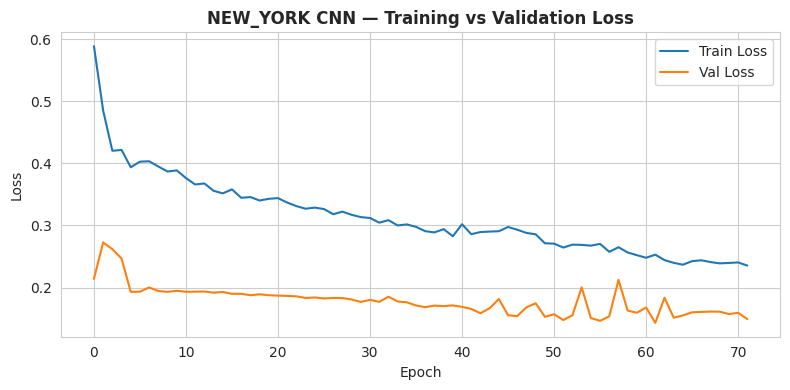

NEW_YORK CNN
Stopped at epoch 72
Final train loss: 0.235343
Final val loss: 0.149109
Ratio (val/train): 0.63
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


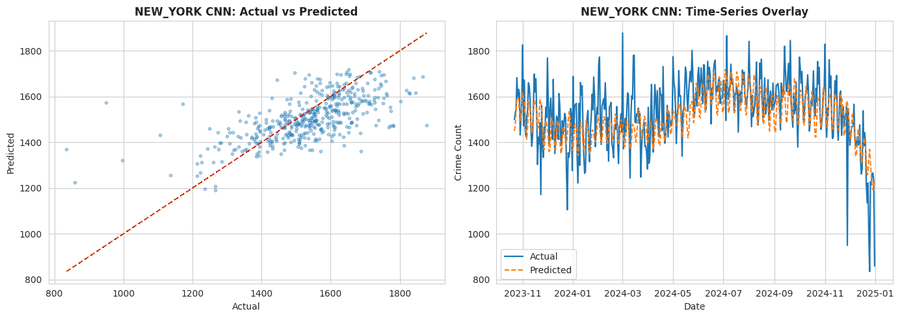


Running new_york — Transformer
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 163ms/step - loss: 0.6152 - val_loss: 0.2277 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5374 - val_loss: 0.2516 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4958 - val_loss: 0.2187 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4763 - val_loss: 0.2151 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4735 - val_loss: 0.2190 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4338 - val_loss: 0.2099 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4404 - val_loss: 0.2028 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4317 - val_loss: 0.1967 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4203 - val_loss: 0.1998 - learning_rate: 

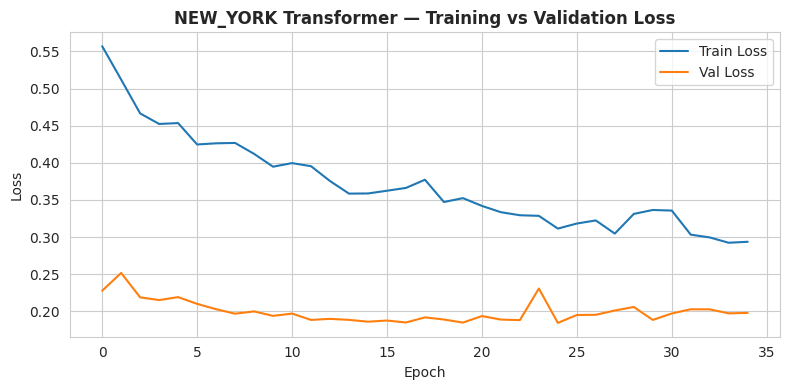

NEW_YORK Transformer
Stopped at epoch 35
Final train loss: 0.293577
Final val loss: 0.197775
Ratio (val/train): 0.67
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


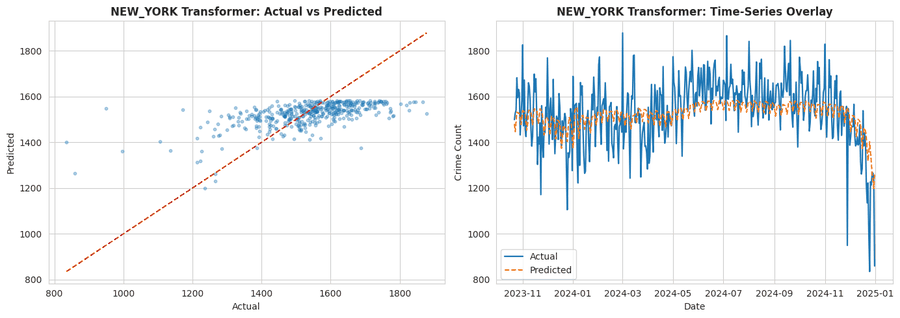

,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.97254,6.653370,6.653370,4.952553,4.865619,4.772297,0.706502,46,0.210121,0.138989,0.661472,Check overfitting/underfitting
1,new_york,LSTM,104.841941,74.693940,56.281738,0.466644,0.485414,1535.97254,6.825769,6.825769,5.020695,4.971455,4.862974,0.719926,36,0.200837,0.132123,0.657863,Check overfitting/underfitting
2,new_york,CNN,113.361368,83.393074,61.094360,0.376442,0.418453,1535.97254,7.380429,7.380429,5.571443,5.549505,5.429334,0.803771,72,0.235343,0.149109,0.633582,Check overfitting/underfitting
3,new_york,Transformer,119.402671,90.349102,72.169189,0.308209,0.316529,1535.97254,7.773750,7.773750,6.105827,5.997881,5.882208,0.870815,35,0.293577,0.197775,0.673672,Check overfitting/underfitting


In [36]:
# CELL 35 — Run DL Forecast Models: New York
nyc_dl_results, nyc_dl_preds, nyc_dl_histories = run_all_dl_models(nyc_dl, "new_york")

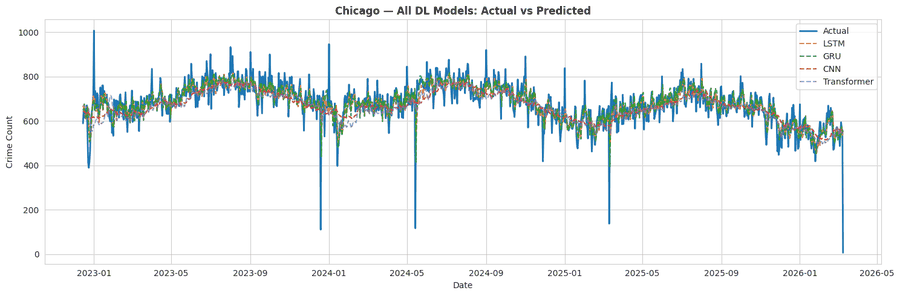

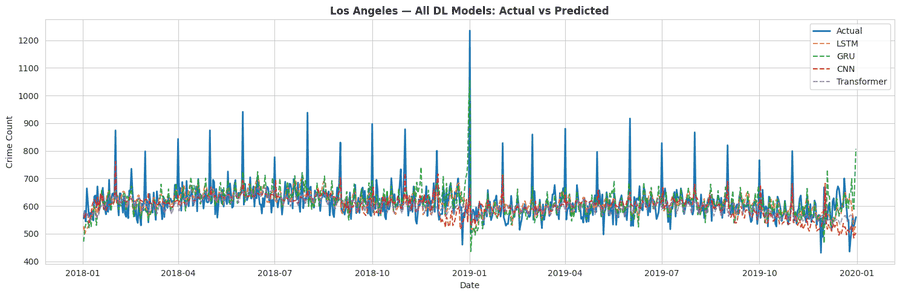

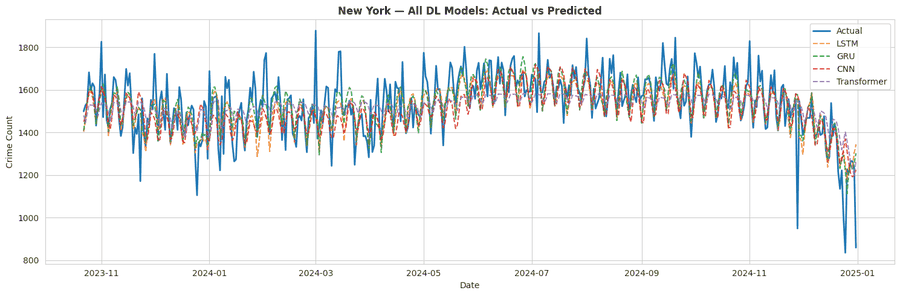

In [37]:
# CELL 36 — Overlay Plot of All DL Models

def plot_dl_overlay(dl_pack, preds_dict, city_key, city_title):
    y_true = dl_pack["y_test_raw"]
    test_dates = dl_pack["test_dates"]

    plt.figure(figsize=(15, 5))
    plt.plot(test_dates, y_true, label="Actual", linewidth=2)

    for model_name, pred in preds_dict.items():
        plt.plot(test_dates, pred, label=model_name, linestyle="--", alpha=0.85)

    plt.title(f"{city_title} — All DL Models: Actual vs Predicted", fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Crime Count")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_all_dl_overlay.png"), dpi=300)
    plt.show()


plot_dl_overlay(chi_dl, chi_dl_preds, "chicago", "Chicago")
plot_dl_overlay(la_dl, la_dl_preds, "los_angeles", "Los Angeles")
plot_dl_overlay(nyc_dl, nyc_dl_preds, "new_york", "New York")

,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,14.642355,6.358405,6.026386,0.824800,33,0.150056,0.136654,0.910688,Healthy
1,chicago,GRU,61.158163,40.721643,31.078674,0.541631,0.542319,678.906859,9.008329,9.008329,14.824343,6.333754,5.998119,0.820931,40,0.142516,0.136612,0.958567,Healthy
2,chicago,CNN,67.175238,46.606100,36.609741,0.447001,0.460722,678.906859,9.894618,9.894618,15.584130,7.237335,6.864874,0.939559,42,0.186763,0.186025,0.996047,Healthy
3,chicago,Transformer,69.469179,48.358224,37.325317,0.408587,0.440743,678.906859,10.232505,10.232505,15.578690,7.522882,7.122954,0.974881,42,0.197041,0.166538,0.845193,Healthy
4,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.629630,9.367761,9.367761,6.229956,6.196267,6.332339,0.730295,77,0.191117,0.279204,1.460902,Healthy
5,los_angeles,LSTM,59.050263,38.540328,29.327209,0.118007,0.118207,613.629630,9.623111,9.623111,6.097806,6.138450,6.280715,0.724341,57,0.307356,0.314371,1.022823,Healthy
6,los_angeles,CNN,59.080017,39.840997,29.280334,0.117118,0.164321,613.629630,9.627960,9.627960,6.257692,6.423233,6.492678,0.748787,54,0.332046,0.349444,1.052397,Healthy
7,los_angeles,Transformer,62.572508,38.310440,26.557983,0.009650,0.063490,613.629630,10.197113,10.197113,5.904475,6.103548,6.243251,0.720021,21,0.450899,0.392464,0.870402,Healthy
8,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.972540,6.653370,6.653370,4.952553,4.865619,4.772297,0.706502,46,0.210121,0.138989,0.661472,Check overfitting/underfitting
9,new_york,LSTM,104.841941,74.693940,56.281738,0.466644,0.485414,1535.972540,6.825769,6.825769,5.020695,4.971455,4.862974,0.719926,36,0.200837,0.132123,0.657863,Check overfitting/underfitting


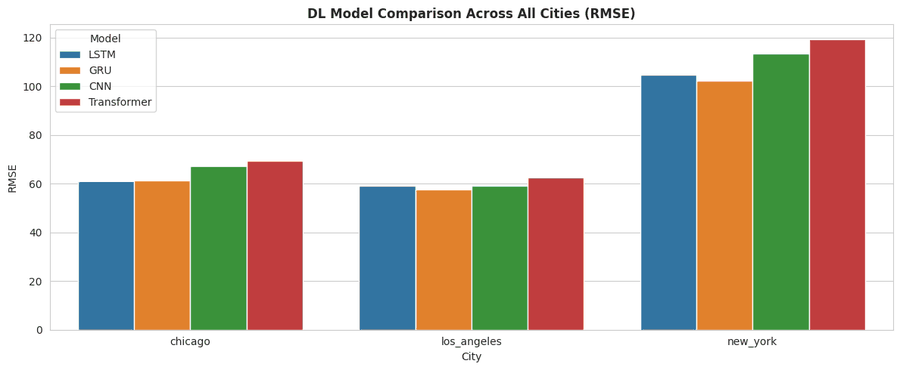

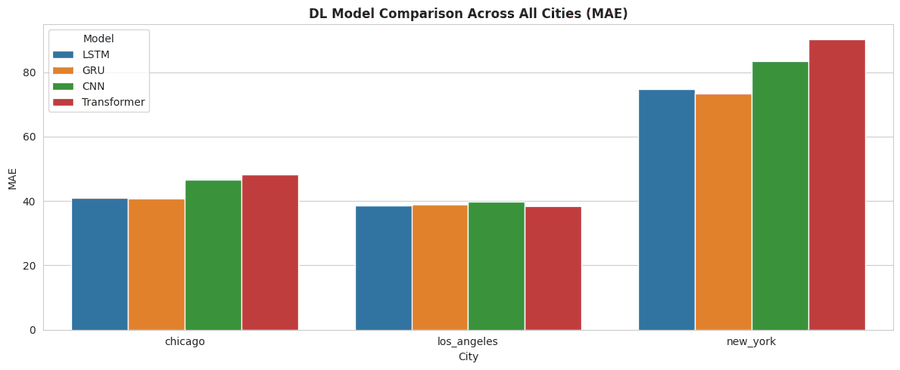

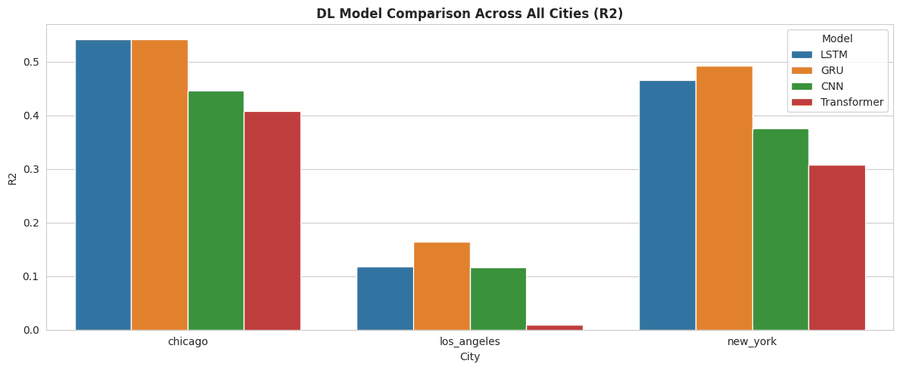

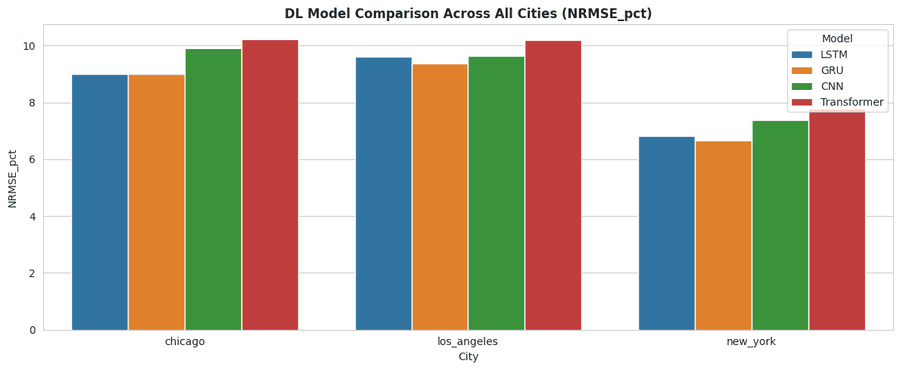

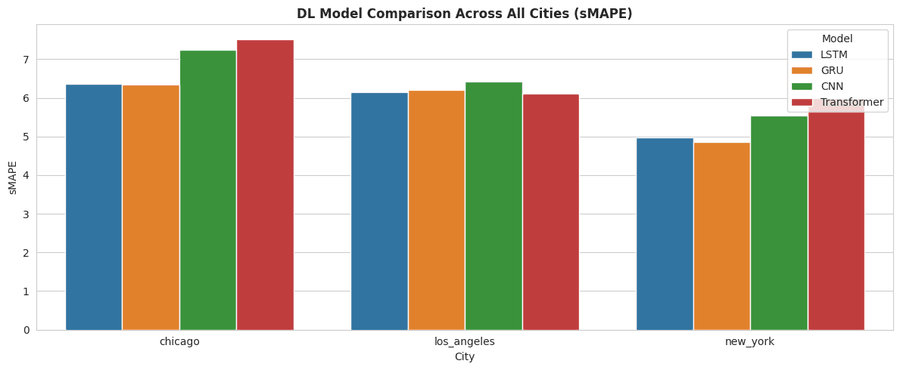

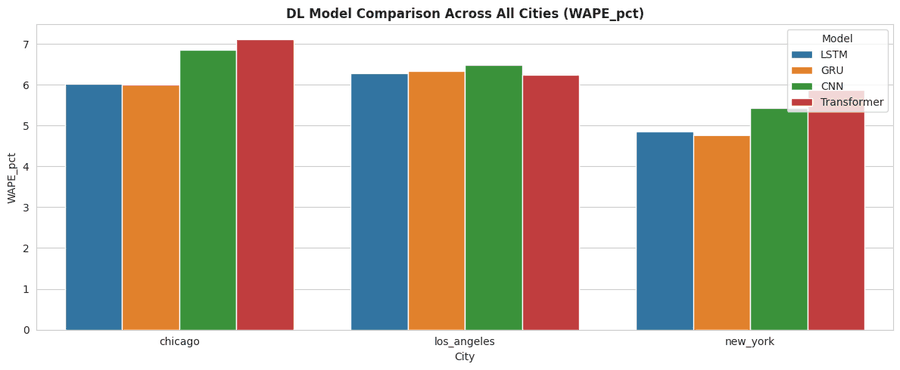

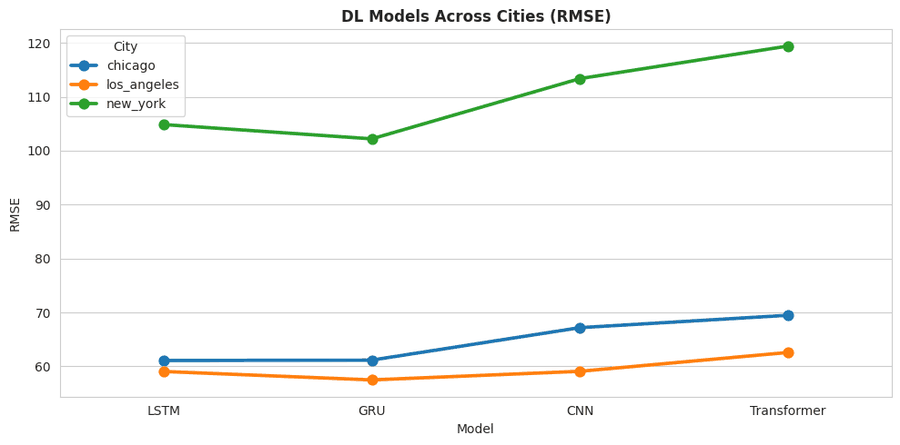

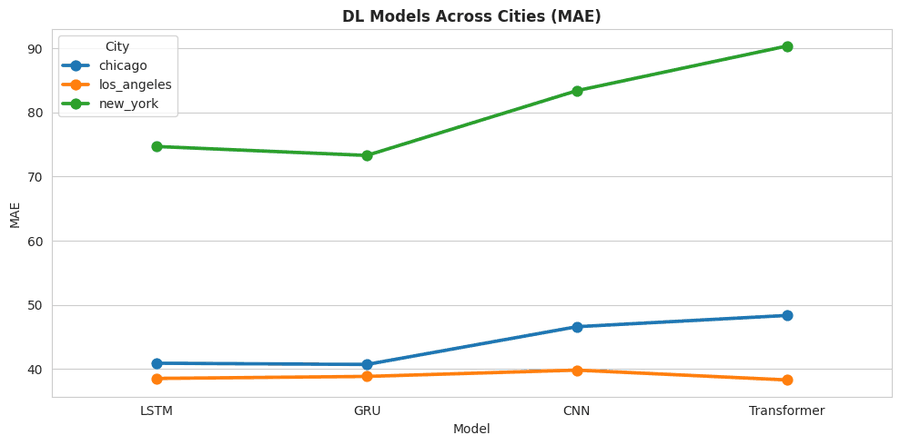

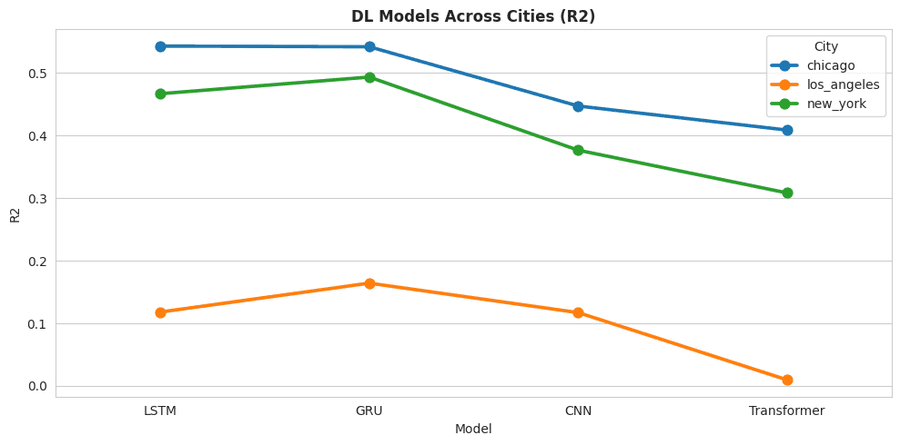

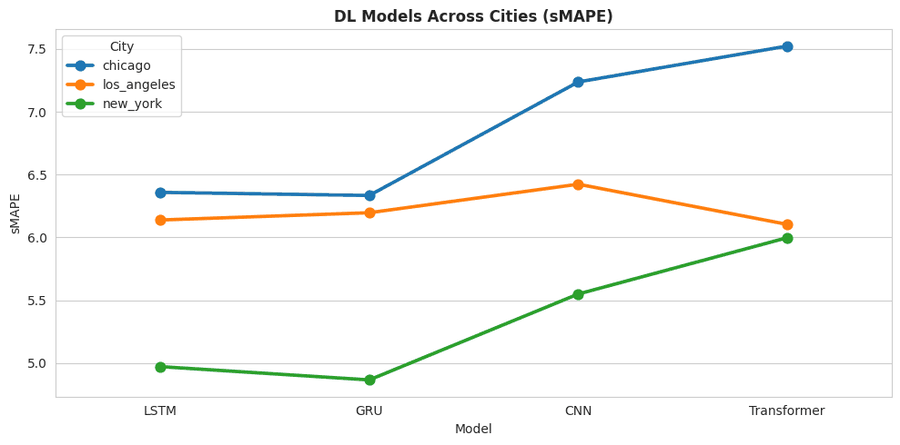

In [38]:
# CELL 36A — Build all_dl_compare + DL Comparison Plots (FIXES ERROR AFTER CELL 36)

all_dl_compare = pd.concat([
    chi_dl_results.copy(),
    la_dl_results.copy(),
    nyc_dl_results.copy()
], ignore_index=True)

all_dl_compare.to_csv(os.path.join(TABLE_DIR, "all_cities_dl_model_comparison.csv"), index=False)
display(all_dl_compare)

def plot_dl_comparison_all_cities(all_dl_df):
    metrics = ["RMSE", "MAE", "R2", "NRMSE_pct", "sMAPE", "WAPE_pct"]

    for metric in metrics:
        plt.figure(figsize=(12, 5))
        sns.barplot(data=all_dl_df, x="City", y=metric, hue="Model")
        plt.title(f"DL Model Comparison Across All Cities ({metric})", fontweight="bold")
        plt.tight_layout()
        plt.savefig(os.path.join(PLOT_DIR, f"all_cities_dl_{metric.lower()}.png"), dpi=300)
        plt.show()

def plot_metric_lines_across_cities(all_dl_df):
    for metric in ["RMSE", "MAE", "R2", "sMAPE"]:
        plt.figure(figsize=(10, 5))
        sns.pointplot(data=all_dl_df, x="Model", y=metric, hue="City")
        plt.title(f"DL Models Across Cities ({metric})", fontweight="bold")
        plt.tight_layout()
        plt.savefig(os.path.join(PLOT_DIR, f"dl_models_across_cities_{metric.lower()}.png"), dpi=300)
        plt.show()

plot_dl_comparison_all_cities(all_dl_compare)
plot_metric_lines_across_cities(all_dl_compare)

# * PART 4 — ARIMA / SARIMA TOTAL CRIME FORECASTING*

In [39]:
# CELL 37 — Stationarity + Daily Forecast Functions

def adf_test(series):
    series = pd.Series(series).dropna()
    stat, pvalue, _, _, _, _ = adfuller(series)
    return stat, pvalue


def train_test_split_daily(daily_df, split_ratio=0.8):
    n = len(daily_df)
    sp = int(n * split_ratio)
    train = daily_df.iloc[:sp].copy()
    test  = daily_df.iloc[sp:].copy()
    return train, test


def fit_best_arima_or_sarima(daily_df, city_key):
    daily_df = daily_df.copy()
    daily_df["date_only"] = pd.to_datetime(daily_df["date_only"])

    train_df, test_df = train_test_split_daily(daily_df)
    y_train = train_df["crime_count"].values.astype(float)
    y_test  = test_df["crime_count"].values.astype(float)

    stat, pval = adf_test(y_train)
    print(f"{city_key} ADF stat={stat:.4f}, p={pval:.4f}")

    use_sarima = False
    seasonal_order = None

    if PMDARIMA_AVAILABLE:
        try:
            # Daily seasonal cycle: weekly seasonality
            arima_auto = pm.auto_arima(
                y_train,
                seasonal=True,
                m=7,
                suppress_warnings=True,
                error_action="ignore",
                stepwise=True,
                trace=False,
                max_p=3,
                max_q=3,
                max_d=2,
                max_P=2,
                max_Q=2,
                max_D=1
            )
            order = arima_auto.order
            seasonal_order = arima_auto.seasonal_order
            print("Selected DAILY SARIMA:", order, seasonal_order)

            model = SARIMAX(
                y_train,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )
            fitted = model.fit(disp=False)
            forecast = fitted.forecast(steps=len(y_test))
            model_name = "SARIMA"
            use_sarima = True

        except Exception as e:
            print("Auto SARIMA failed, fallback to ARIMA:", e)
            use_sarima = False

    if not use_sarima:
        if PMDARIMA_AVAILABLE:
            try:
                arima_auto = pm.auto_arima(
                    y_train,
                    seasonal=False,
                    suppress_warnings=True,
                    error_action="ignore",
                    stepwise=True,
                    trace=False,
                    max_p=4,
                    max_q=4,
                    max_d=2
                )
                order = arima_auto.order
            except:
                order = (3, 1, 2)
        else:
            order = (3, 1, 2)

        print("Selected DAILY ARIMA:", order)
        model = ARIMA(y_train, order=order)
        fitted = model.fit()
        forecast = fitted.forecast(steps=len(y_test))
        model_name = "ARIMA"
        seasonal_order = None

    forecast = np.asarray(forecast).reshape(-1)
    forecast = np.clip(forecast, 0, None)

    metrics = forecast_metrics(y_test, forecast)
    metrics["City"] = city_key
    metrics["Model"] = model_name
    metrics["Order"] = str(order)
    metrics["Seasonal_Order"] = str(seasonal_order)

    city_plot = os.path.join(BASE_OUT, city_key, "plots")
    city_table = os.path.join(BASE_OUT, city_key, "tables")

    # Forecast plot
    plt.figure(figsize=(14, 5))
    plt.plot(train_df["date_only"], y_train, label="Train", linewidth=1.2)
    plt.plot(test_df["date_only"], y_test, label="Test", linewidth=1.5)
    plt.plot(test_df["date_only"], forecast, label=f"{model_name} Forecast", linestyle="--", linewidth=1.5)
    plt.title(f"{city_key.upper()} — {model_name} Daily Forecast", fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Crime Count")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_{model_name.lower()}_daily_forecast.png"), dpi=300)
    plt.show()

    # Scatter like your reference style
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, forecast, alpha=0.35, s=10)
    lo = min(y_test.min(), forecast.min())
    hi = max(y_test.max(), forecast.max())
    plt.plot([lo, hi], [lo, hi], "r--", linewidth=1.5)
    plt.title(f"{city_key.upper()} {model_name}: Actual vs Predicted", fontweight="bold")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_{model_name.lower()}_daily_actual_vs_pred.png"), dpi=300)
    plt.show()

    residuals = y_test - forecast

    plt.figure(figsize=(10, 4))
    plt.plot(test_df["date_only"], residuals)
    plt.axhline(0, linestyle="--")
    plt.title(f"{city_key.upper()} — {model_name} Daily Residual Plot", fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Residual")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_{model_name.lower()}_daily_residuals.png"), dpi=300)
    plt.show()

    plt.figure(figsize=(7, 4))
    sns.histplot(residuals, kde=True)
    plt.title(f"{city_key.upper()} — {model_name} Daily Error Distribution", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_{model_name.lower()}_daily_error_distribution.png"), dpi=300)
    plt.show()

    out_df = pd.DataFrame({
        "City": city_key,
        "Model": model_name,
        "date_only": test_df["date_only"].values,
        "actual": y_test,
        "forecast": forecast,
        "residual": residuals
    })
    out_df.to_csv(os.path.join(city_table, f"{city_key}_{model_name.lower()}_daily_predictions.csv"), index=False)
    pd.DataFrame([metrics]).to_csv(os.path.join(city_table, f"{city_key}_{model_name.lower()}_daily_metrics.csv"), index=False)

    return metrics, forecast

chicago ADF stat=-2.2858, p=0.1766
Selected DAILY ARIMA: (3, 1, 2)


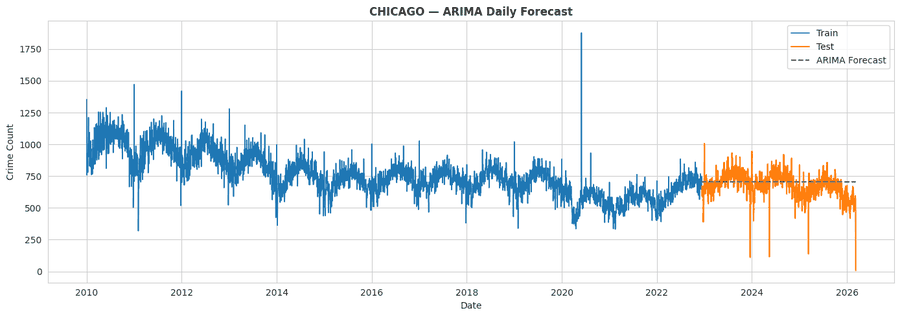

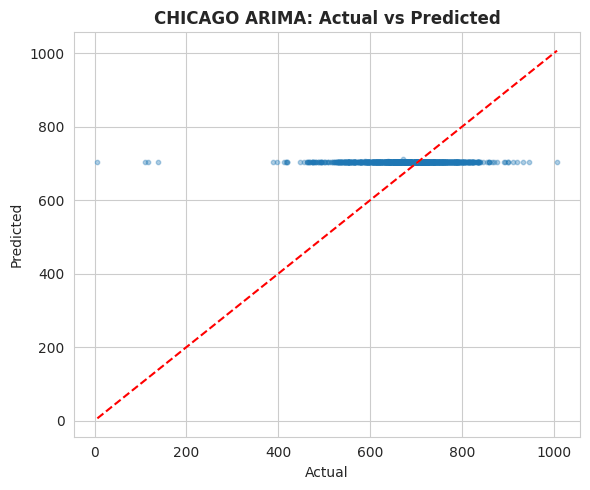

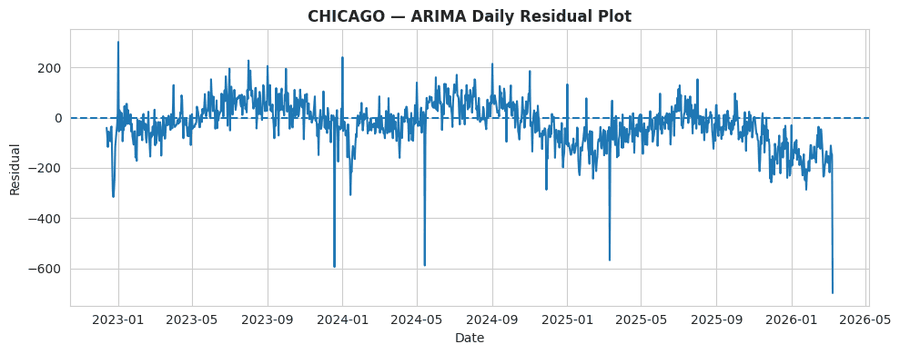

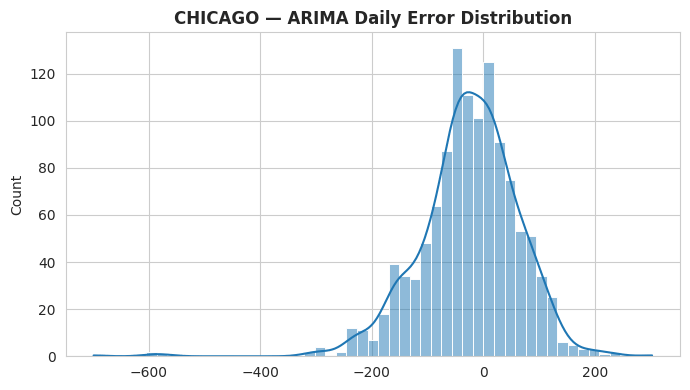

los_angeles ADF stat=-2.8448, p=0.0522
Selected DAILY ARIMA: (3, 1, 2)


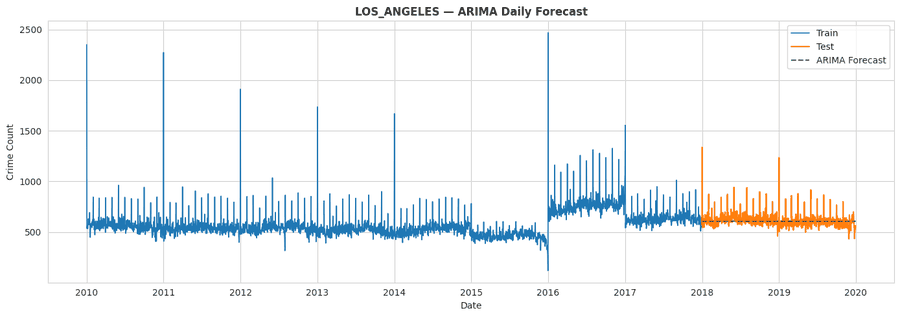

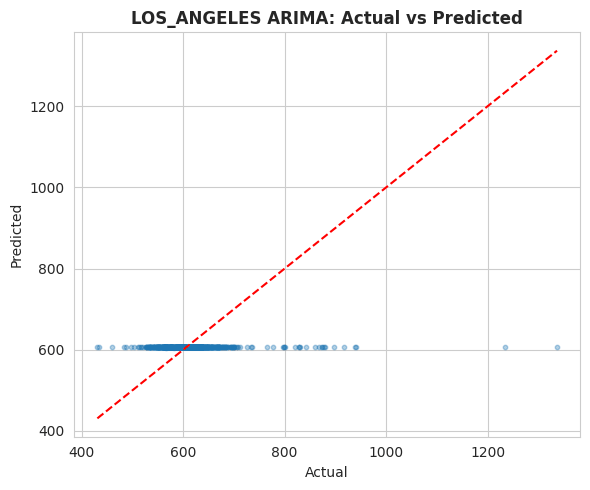

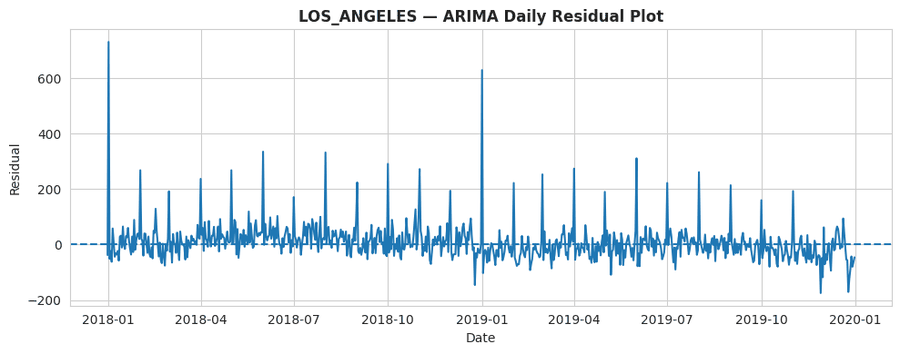

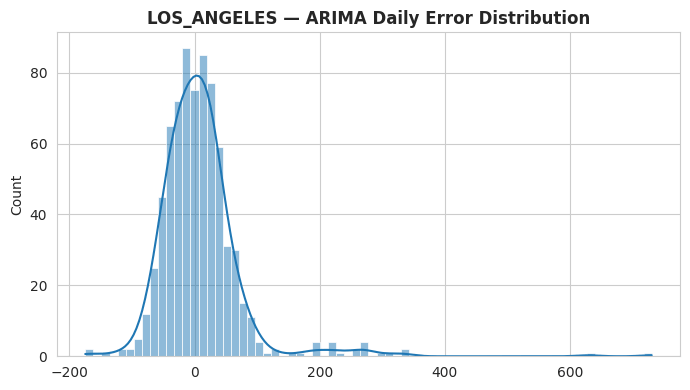

new_york ADF stat=-1.9831, p=0.2940
Selected DAILY ARIMA: (3, 1, 2)


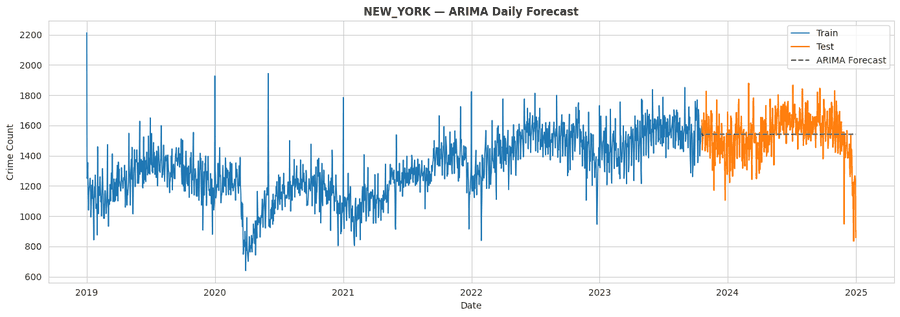

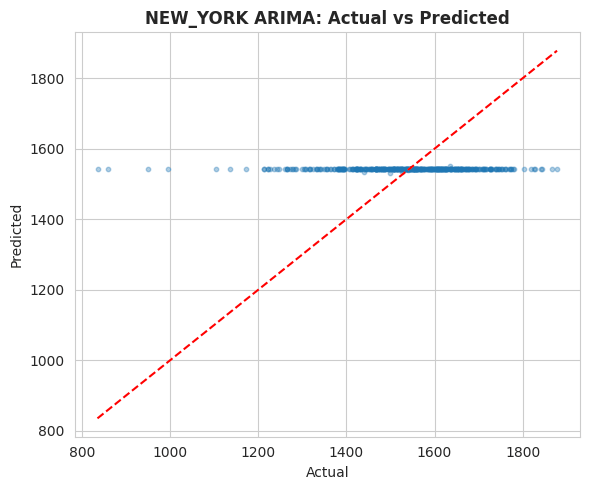

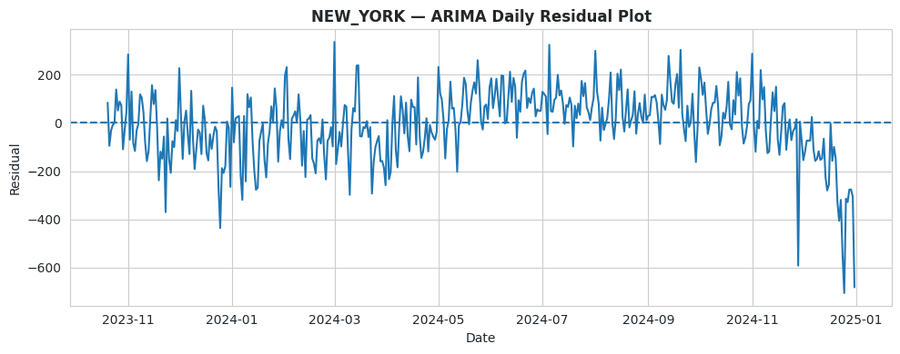

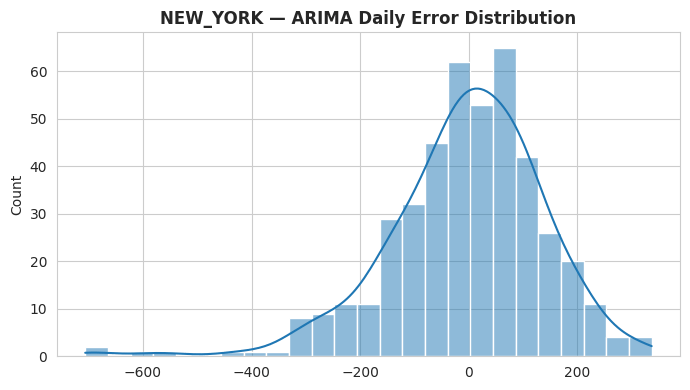

,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,City,Model,Order,Seasonal_Order
0,93.930562,68.855676,52.833858,-0.082873,-0.000054,678.866441,13.836383,13.836383,21.711584,10.459488,10.142743,1.388485,chicago,ARIMA,"(3, 1, 2)",None
1,68.817113,41.132320,29.163409,-0.016107,0.000204,614.554036,11.197895,11.197895,6.356206,6.499183,6.693036,0.745299,los_angeles,ARIMA,"(3, 1, 2)",None
2,143.445583,106.956535,82.621084,-0.000851,0.000552,1535.979499,9.339030,9.339030,7.381703,7.096177,6.963409,1.029762,new_york,ARIMA,"(3, 1, 2)",None


In [40]:
# CELL 38 — Run ARIMA/SARIMA for All Three Cities (DAILY)

chi_arima_metrics, chi_arima_forecast = fit_best_arima_or_sarima(chi_daily_total, "chicago")
la_arima_metrics, la_arima_forecast   = fit_best_arima_or_sarima(la_daily_total,  "los_angeles")
nyc_arima_metrics, nyc_arima_forecast = fit_best_arima_or_sarima(nyc_daily_total, "new_york")

arima_all = pd.DataFrame([chi_arima_metrics, la_arima_metrics, nyc_arima_metrics])
arima_all = arima_all.sort_values(["City", "RMSE"]).reset_index(drop=True)

arima_all.to_csv(os.path.join(TABLE_DIR, "all_cities_daily_arima_results.csv"), index=False)
display(arima_all)

# *PART 5 — COMPARE DL VS ARIMA/SARIMA*

In [41]:
# CELL 39 — Total Crime Forecast Comparison Tables
chi_total_compare = pd.concat([chi_dl_results, pd.DataFrame([chi_arima_metrics])], ignore_index=True)
la_total_compare  = pd.concat([la_dl_results,  pd.DataFrame([la_arima_metrics])], ignore_index=True)
nyc_total_compare = pd.concat([nyc_dl_results, pd.DataFrame([nyc_arima_metrics])], ignore_index=True)

chi_total_compare.to_csv(os.path.join(BASE_OUT, "chicago", "tables", "chicago_total_forecast_comparison.csv"), index=False)
la_total_compare.to_csv(os.path.join(BASE_OUT, "los_angeles", "tables", "los_angeles_total_forecast_comparison.csv"), index=False)
nyc_total_compare.to_csv(os.path.join(BASE_OUT, "new_york", "tables", "new_york_total_forecast_comparison.csv"), index=False)

display(chi_total_compare.sort_values("RMSE"))
display(la_total_compare.sort_values("RMSE"))
display(nyc_total_compare.sort_values("RMSE"))


,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,...,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment,Order,Seasonal_Order
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,...,6.358405,6.026386,0.824800,33.0,0.150056,0.136654,0.910688,Healthy,NaN,NaN
1,chicago,GRU,61.158163,40.721643,31.078674,0.541631,0.542319,678.906859,9.008329,9.008329,...,6.333754,5.998119,0.820931,40.0,0.142516,0.136612,0.958567,Healthy,NaN,NaN
2,chicago,CNN,67.175238,46.606100,36.609741,0.447001,0.460722,678.906859,9.894618,9.894618,...,7.237335,6.864874,0.939559,42.0,0.186763,0.186025,0.996047,Healthy,NaN,NaN
3,chicago,Transformer,69.469179,48.358224,37.325317,0.408587,0.440743,678.906859,10.232505,10.232505,...,7.522882,7.122954,0.974881,42.0,0.197041,0.166538,0.845193,Healthy,NaN,NaN
4,chicago,ARIMA,93.930562,68.855676,52.833858,-0.082873,-0.000054,678.866441,13.836383,13.836383,...,10.459488,10.142743,1.388485,NaN,NaN,NaN,NaN,NaN,"(3, 1, 2)",None


,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,...,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment,Order,Seasonal_Order
0,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.629630,9.367761,9.367761,...,6.196267,6.332339,0.730295,77.0,0.191117,0.279204,1.460902,Healthy,NaN,NaN
1,los_angeles,LSTM,59.050263,38.540328,29.327209,0.118007,0.118207,613.629630,9.623111,9.623111,...,6.138450,6.280715,0.724341,57.0,0.307356,0.314371,1.022823,Healthy,NaN,NaN
2,los_angeles,CNN,59.080017,39.840997,29.280334,0.117118,0.164321,613.629630,9.627960,9.627960,...,6.423233,6.492678,0.748787,54.0,0.332046,0.349444,1.052397,Healthy,NaN,NaN
3,los_angeles,Transformer,62.572508,38.310440,26.557983,0.009650,0.063490,613.629630,10.197113,10.197113,...,6.103548,6.243251,0.720021,21.0,0.450899,0.392464,0.870402,Healthy,NaN,NaN
4,los_angeles,ARIMA,68.817113,41.132320,29.163409,-0.016107,0.000204,614.554036,11.197895,11.197895,...,6.499183,6.693036,0.745299,NaN,NaN,NaN,NaN,NaN,"(3, 1, 2)",None


,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,...,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment,Order,Seasonal_Order
0,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.972540,6.653370,6.653370,...,4.865619,4.772297,0.706502,46.0,0.210121,0.138989,0.661472,Check overfitting/underfitting,NaN,NaN
1,new_york,LSTM,104.841941,74.693940,56.281738,0.466644,0.485414,1535.972540,6.825769,6.825769,...,4.971455,4.862974,0.719926,36.0,0.200837,0.132123,0.657863,Check overfitting/underfitting,NaN,NaN
2,new_york,CNN,113.361368,83.393074,61.094360,0.376442,0.418453,1535.972540,7.380429,7.380429,...,5.549505,5.429334,0.803771,72.0,0.235343,0.149109,0.633582,Check overfitting/underfitting,NaN,NaN
3,new_york,Transformer,119.402671,90.349102,72.169189,0.308209,0.316529,1535.972540,7.773750,7.773750,...,5.997881,5.882208,0.870815,35.0,0.293577,0.197775,0.673672,Check overfitting/underfitting,NaN,NaN
4,new_york,ARIMA,143.445583,106.956535,82.621084,-0.000851,0.000552,1535.979499,9.339030,9.339030,...,7.096177,6.963409,1.029762,NaN,NaN,NaN,NaN,NaN,"(3, 1, 2)",None


In [42]:
# NEW / REPLACEMENT CELL — Proper Total Forecast Comparison Table

chi_total_compare = chi_dl_results.copy()
la_total_compare  = la_dl_results.copy()
nyc_total_compare = nyc_dl_results.copy()

all_total_forecast = pd.concat([chi_total_compare, la_total_compare, nyc_total_compare], ignore_index=True)
all_total_forecast = all_total_forecast.sort_values(["City", "RMSE"]).reset_index(drop=True)

all_total_forecast.to_csv(os.path.join(TABLE_DIR, "all_cities_total_forecast_results.csv"), index=False)
display(all_total_forecast)

,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,14.642355,6.358405,6.026386,0.824800,33,0.150056,0.136654,0.910688,Healthy
1,chicago,GRU,61.158163,40.721643,31.078674,0.541631,0.542319,678.906859,9.008329,9.008329,14.824343,6.333754,5.998119,0.820931,40,0.142516,0.136612,0.958567,Healthy
2,chicago,CNN,67.175238,46.606100,36.609741,0.447001,0.460722,678.906859,9.894618,9.894618,15.584130,7.237335,6.864874,0.939559,42,0.186763,0.186025,0.996047,Healthy
3,chicago,Transformer,69.469179,48.358224,37.325317,0.408587,0.440743,678.906859,10.232505,10.232505,15.578690,7.522882,7.122954,0.974881,42,0.197041,0.166538,0.845193,Healthy
4,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.629630,9.367761,9.367761,6.229956,6.196267,6.332339,0.730295,77,0.191117,0.279204,1.460902,Healthy
5,los_angeles,LSTM,59.050263,38.540328,29.327209,0.118007,0.118207,613.629630,9.623111,9.623111,6.097806,6.138450,6.280715,0.724341,57,0.307356,0.314371,1.022823,Healthy
6,los_angeles,CNN,59.080017,39.840997,29.280334,0.117118,0.164321,613.629630,9.627960,9.627960,6.257692,6.423233,6.492678,0.748787,54,0.332046,0.349444,1.052397,Healthy
7,los_angeles,Transformer,62.572508,38.310440,26.557983,0.009650,0.063490,613.629630,10.197113,10.197113,5.904475,6.103548,6.243251,0.720021,21,0.450899,0.392464,0.870402,Healthy
8,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.972540,6.653370,6.653370,4.952553,4.865619,4.772297,0.706502,46,0.210121,0.138989,0.661472,Check overfitting/underfitting
9,new_york,LSTM,104.841941,74.693940,56.281738,0.466644,0.485414,1535.972540,6.825769,6.825769,5.020695,4.971455,4.862974,0.719926,36,0.200837,0.132123,0.657863,Check overfitting/underfitting


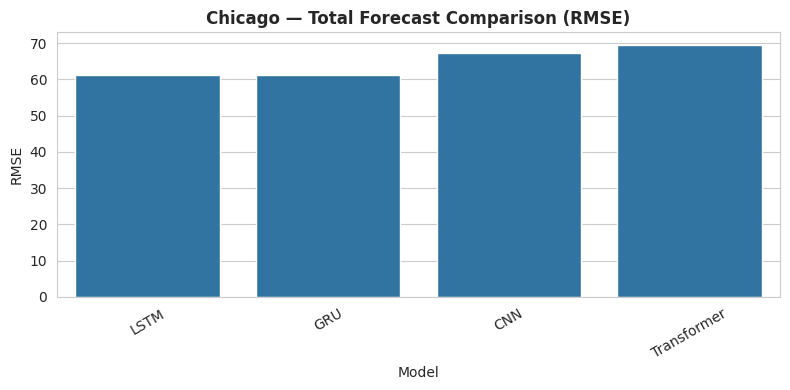

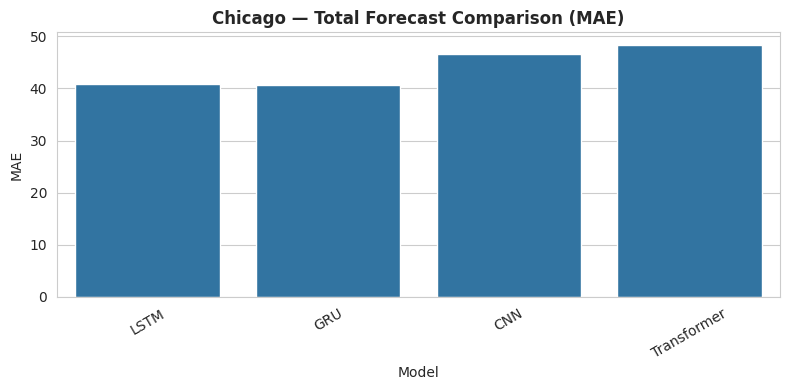

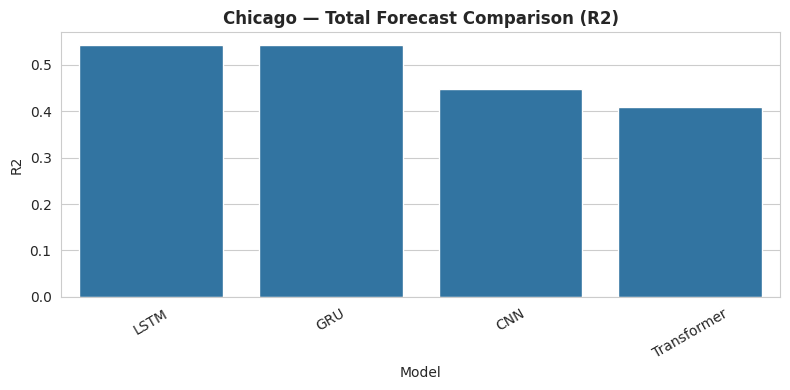

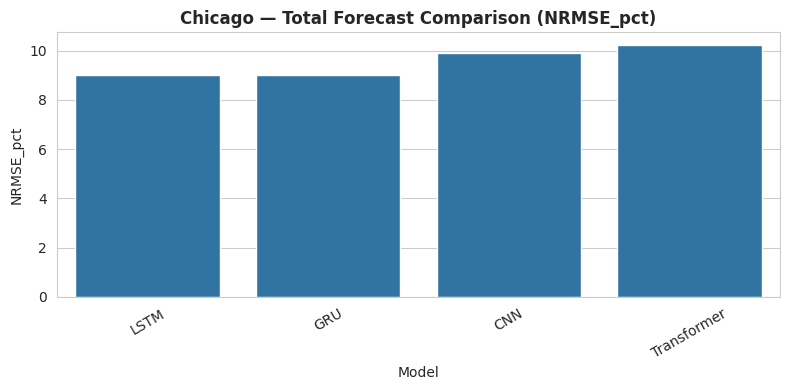

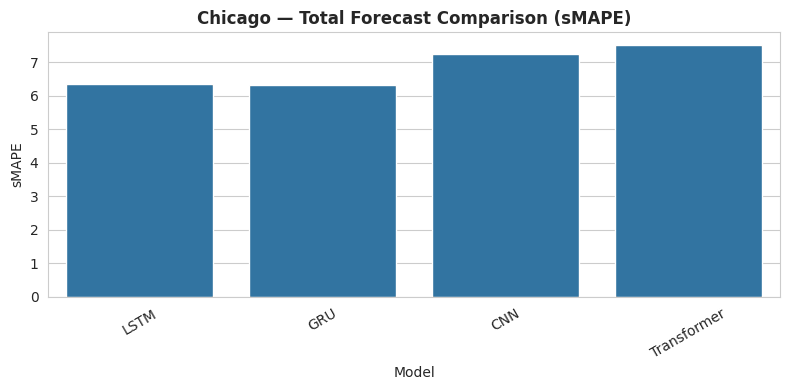

...

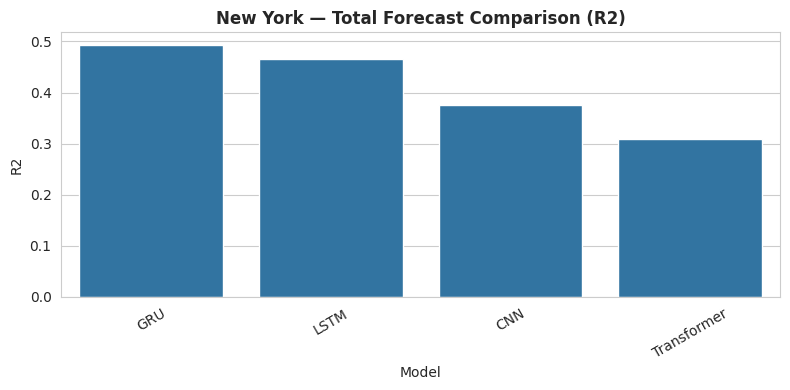

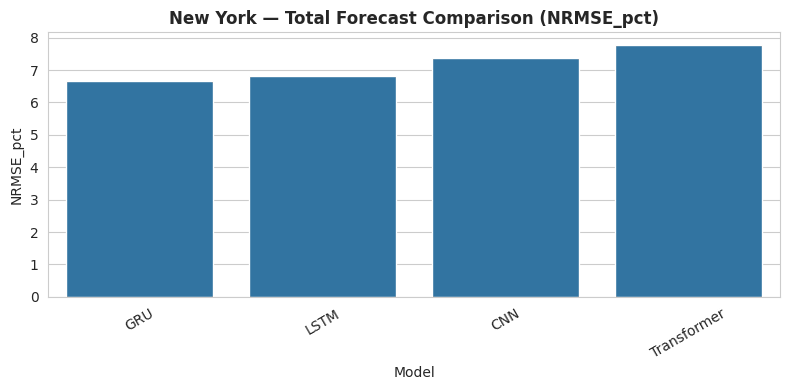

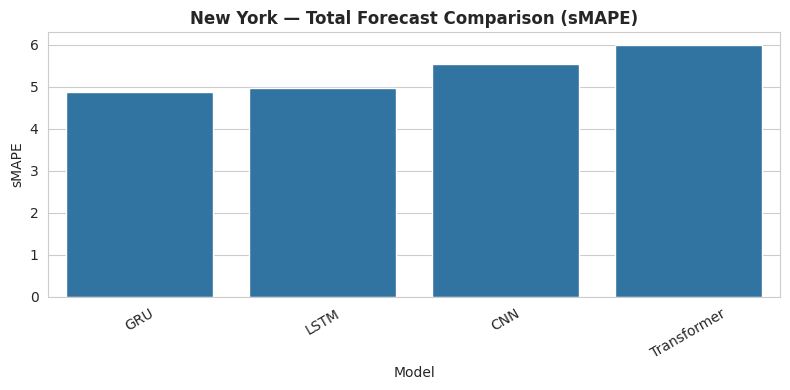

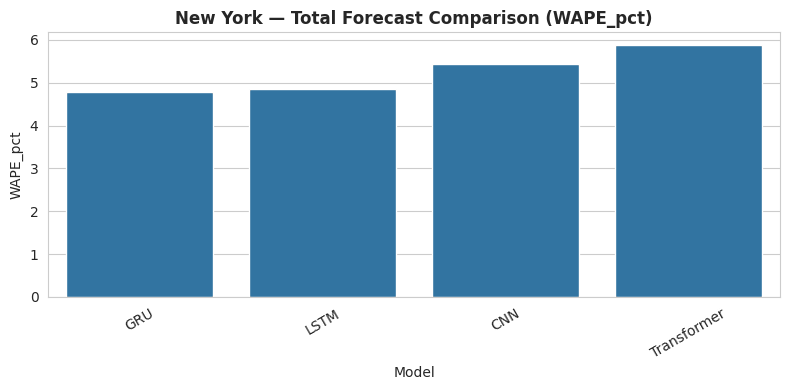

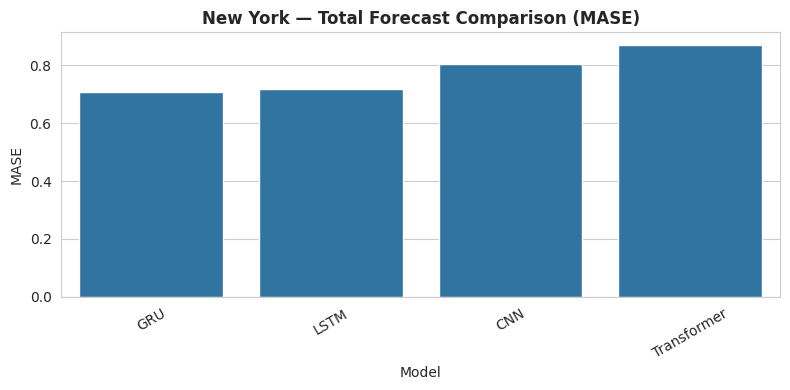

In [43]:
# CELL 40 — Plot Metric Comparisons for Total Forecasting
def plot_total_forecast_comparison(compare_df, city_key, city_title):
    metrics = ["RMSE", "MAE", "R2", "NRMSE_pct", "sMAPE", "WAPE_pct", "MASE"]
    for metric in metrics:
        plt.figure(figsize=(8, 4))
        sns.barplot(data=compare_df, x="Model", y=metric)
        plt.title(f"{city_title} — Total Forecast Comparison ({metric})", fontweight="bold")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_total_fc_{metric.lower()}.png"), dpi=300)
        plt.show()

plot_total_forecast_comparison(chi_total_compare, "chicago", "Chicago")
plot_total_forecast_comparison(la_total_compare, "los_angeles", "Los Angeles")
plot_total_forecast_comparison(nyc_total_compare, "new_york", "New York")


,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,14.642355,6.358405,6.026386,0.824800,33,0.150056,0.136654,0.910688,Healthy
1,chicago,GRU,61.158163,40.721643,31.078674,0.541631,0.542319,678.906859,9.008329,9.008329,14.824343,6.333754,5.998119,0.820931,40,0.142516,0.136612,0.958567,Healthy
2,chicago,CNN,67.175238,46.606100,36.609741,0.447001,0.460722,678.906859,9.894618,9.894618,15.584130,7.237335,6.864874,0.939559,42,0.186763,0.186025,0.996047,Healthy
3,chicago,Transformer,69.469179,48.358224,37.325317,0.408587,0.440743,678.906859,10.232505,10.232505,15.578690,7.522882,7.122954,0.974881,42,0.197041,0.166538,0.845193,Healthy
4,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.629630,9.367761,9.367761,6.229956,6.196267,6.332339,0.730295,77,0.191117,0.279204,1.460902,Healthy
5,los_angeles,LSTM,59.050263,38.540328,29.327209,0.118007,0.118207,613.629630,9.623111,9.623111,6.097806,6.138450,6.280715,0.724341,57,0.307356,0.314371,1.022823,Healthy
6,los_angeles,CNN,59.080017,39.840997,29.280334,0.117118,0.164321,613.629630,9.627960,9.627960,6.257692,6.423233,6.492678,0.748787,54,0.332046,0.349444,1.052397,Healthy
7,los_angeles,Transformer,62.572508,38.310440,26.557983,0.009650,0.063490,613.629630,10.197113,10.197113,5.904475,6.103548,6.243251,0.720021,21,0.450899,0.392464,0.870402,Healthy
8,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.972540,6.653370,6.653370,4.952553,4.865619,4.772297,0.706502,46,0.210121,0.138989,0.661472,Check overfitting/underfitting
9,new_york,LSTM,104.841941,74.693940,56.281738,0.466644,0.485414,1535.972540,6.825769,6.825769,5.020695,4.971455,4.862974,0.719926,36,0.200837,0.132123,0.657863,Check overfitting/underfitting


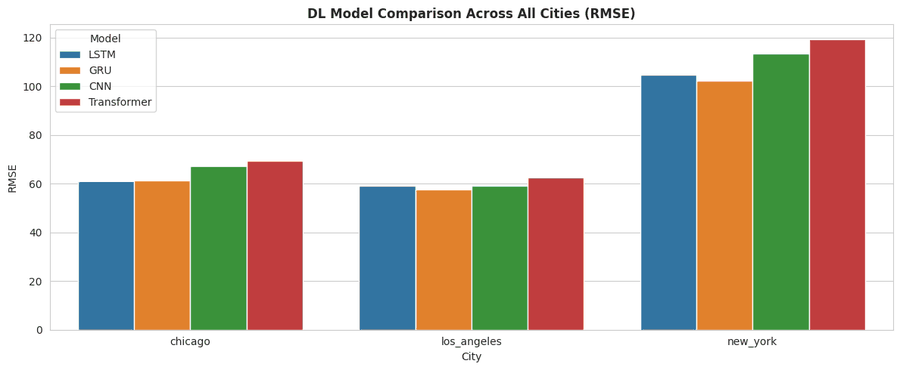

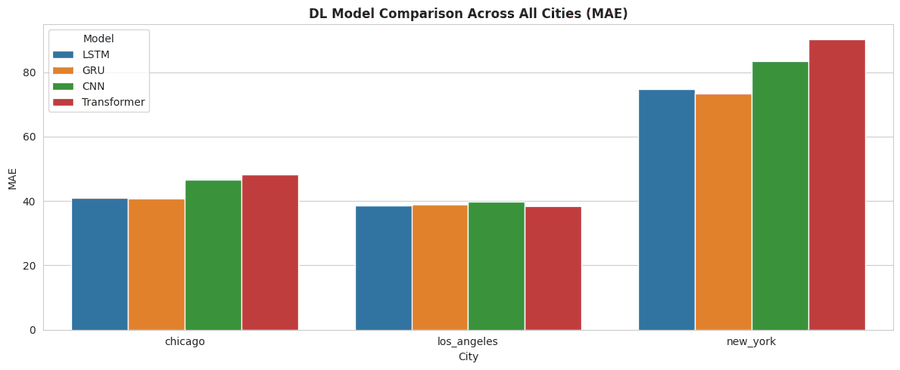

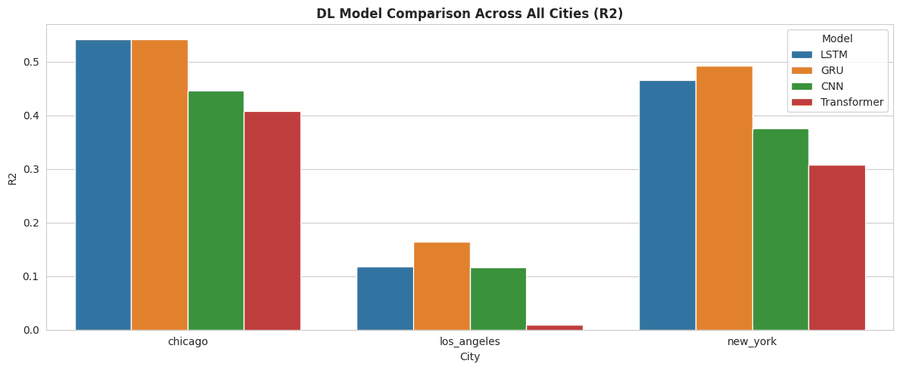

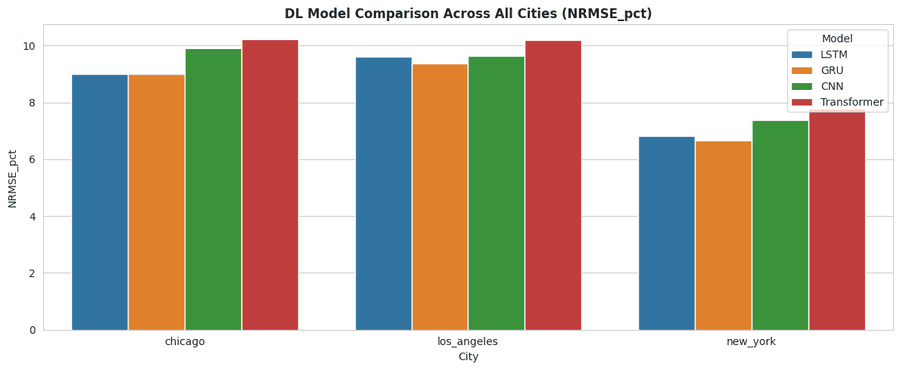

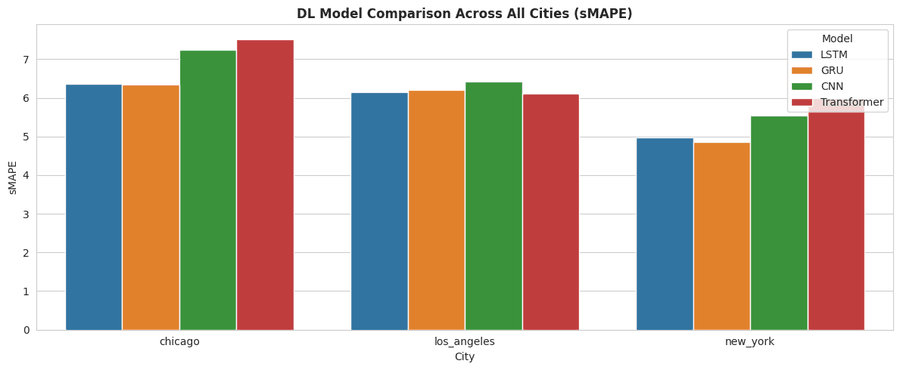

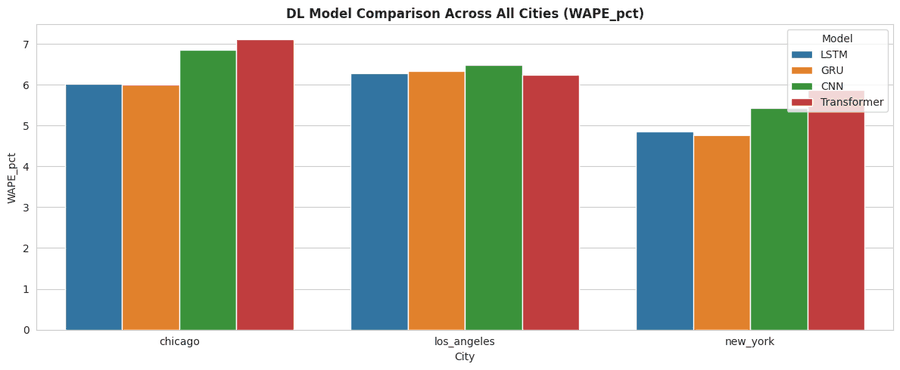

In [44]:
# NEW CELL — DL Comparison Graphs Across All Cities

def plot_dl_comparison_all_cities(all_dl_df):
    metrics = ["RMSE", "MAE", "R2", "NRMSE_pct", "sMAPE", "WAPE_pct"]

    for metric in metrics:
        plt.figure(figsize=(12, 5))
        sns.barplot(data=all_dl_df, x="City", y=metric, hue="Model")
        plt.title(f"DL Model Comparison Across All Cities ({metric})", fontweight="bold")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.savefig(os.path.join(PLOT_DIR, f"all_cities_dl_{metric.lower()}.png"), dpi=300)
        plt.show()


all_dl_compare = pd.concat([
    chi_dl_results.copy(),
    la_dl_results.copy(),
    nyc_dl_results.copy()
], ignore_index=True)

all_dl_compare.to_csv(os.path.join(TABLE_DIR, "all_cities_dl_model_comparison.csv"), index=False)
display(all_dl_compare)

plot_dl_comparison_all_cities(all_dl_compare)

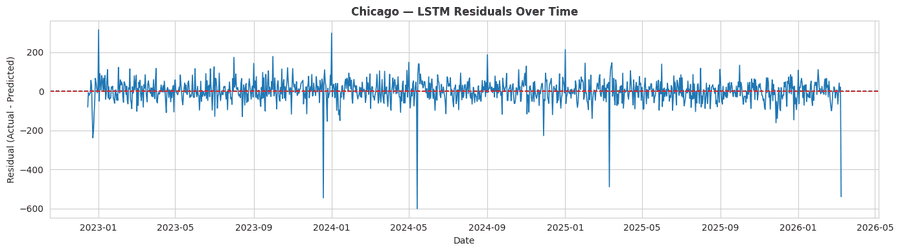

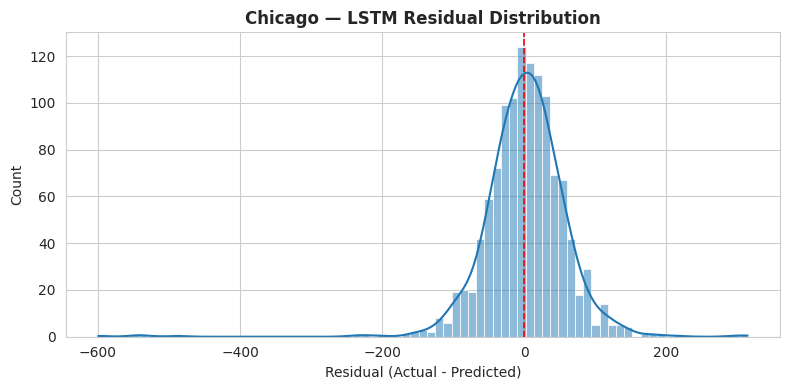

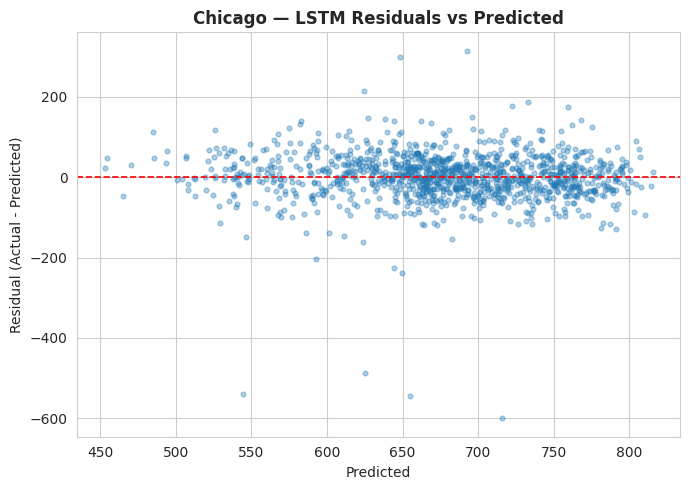

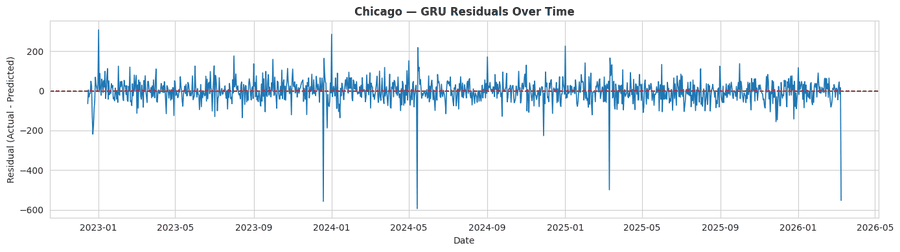

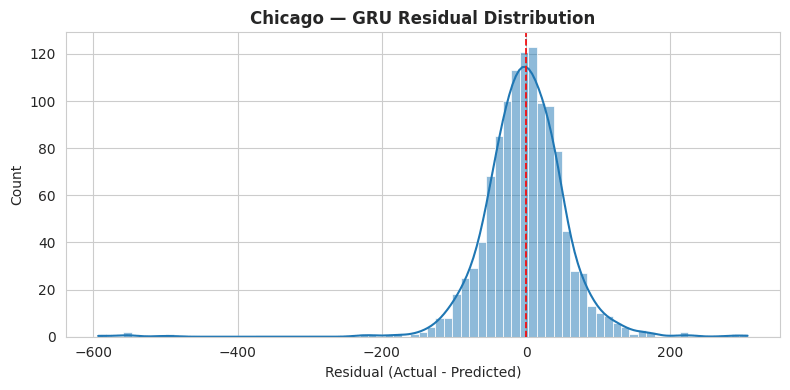

...

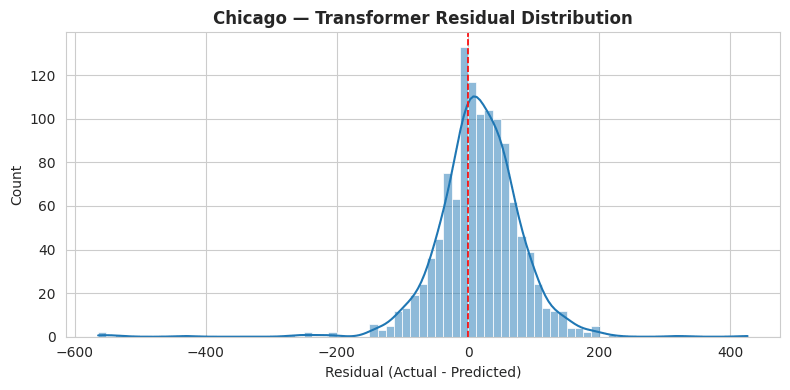

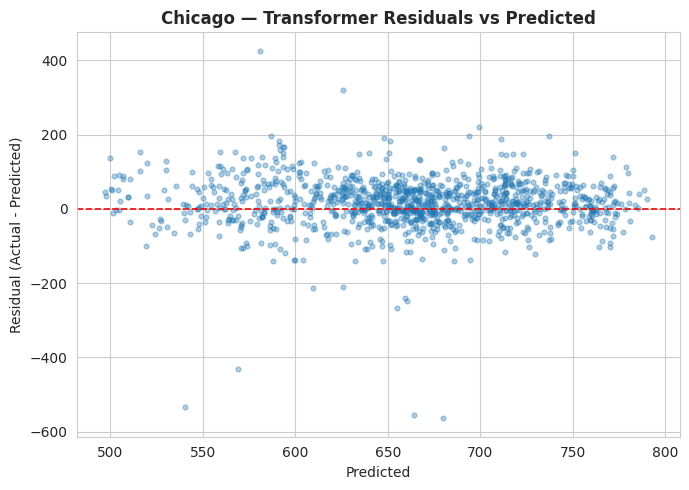

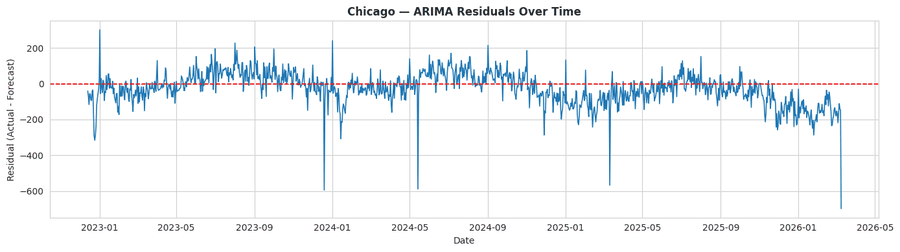

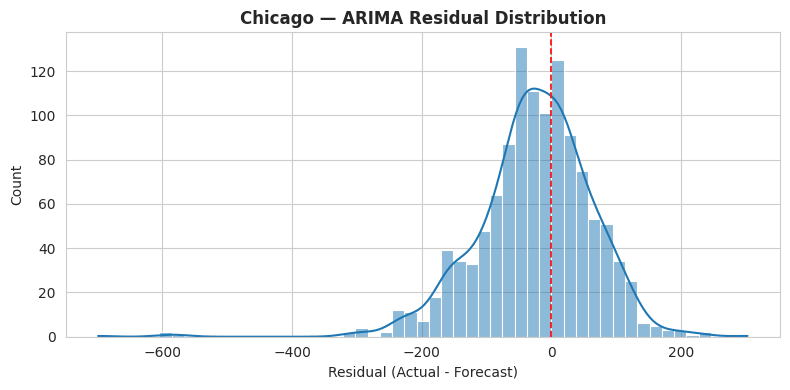

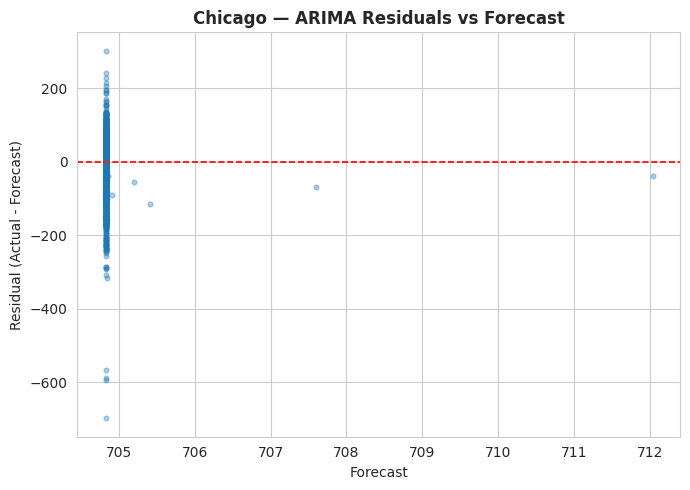

Residual plots saved for Chicago (DL + ARIMA).


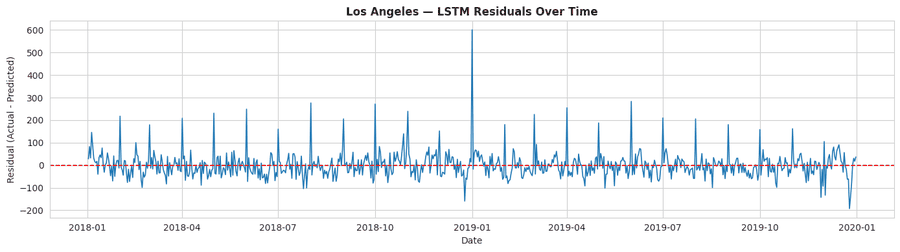

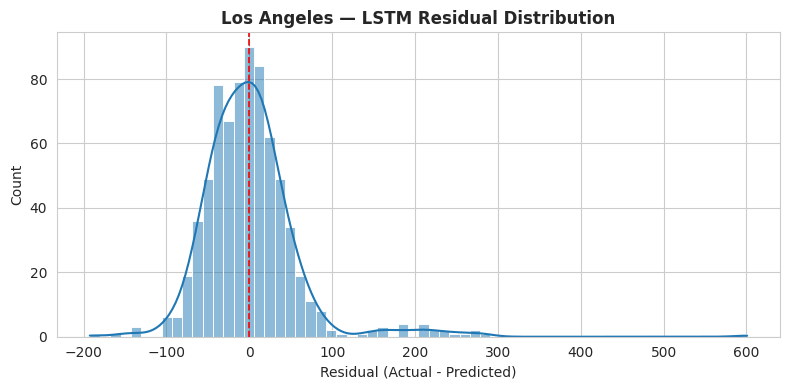

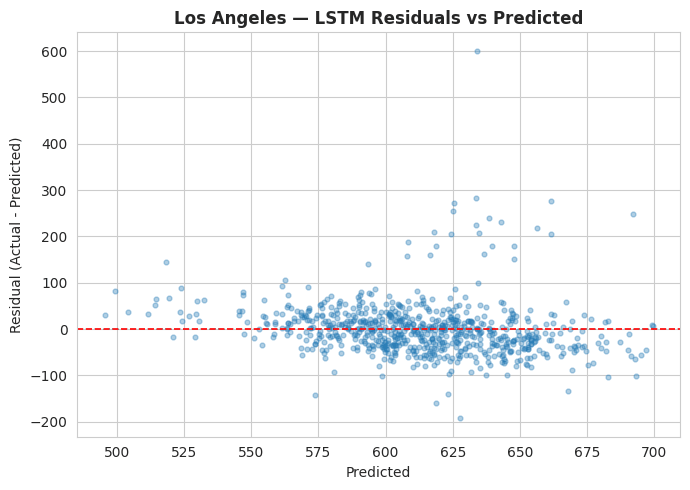

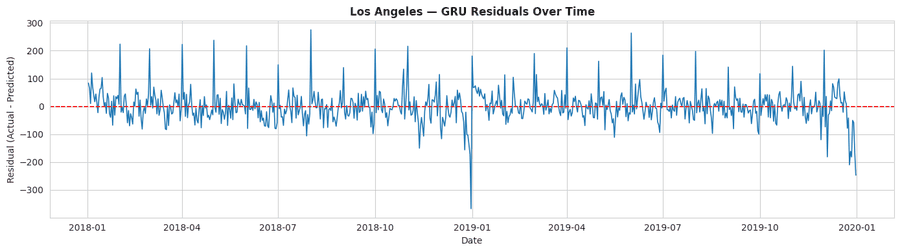

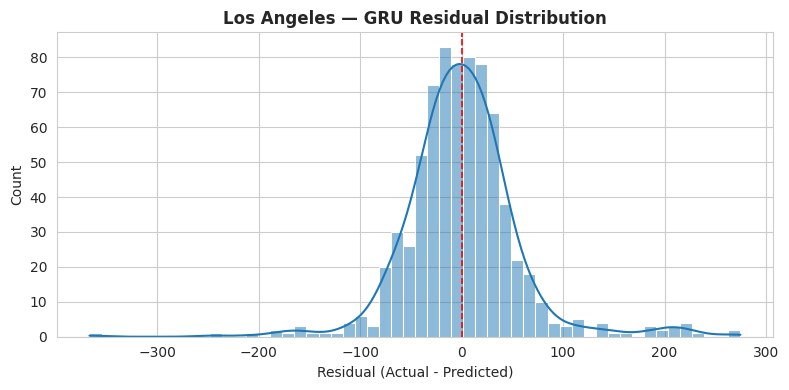

...

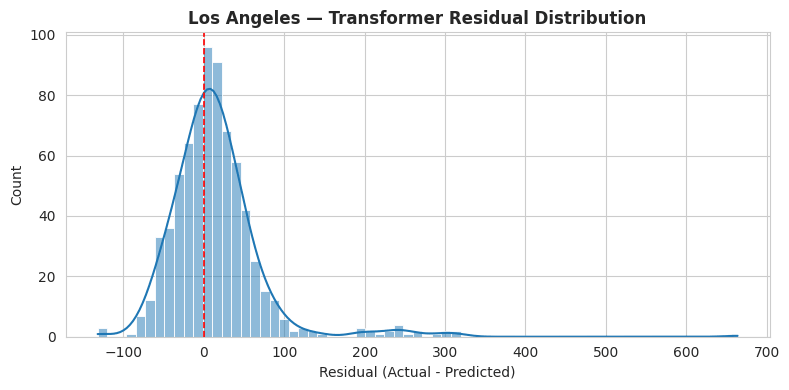

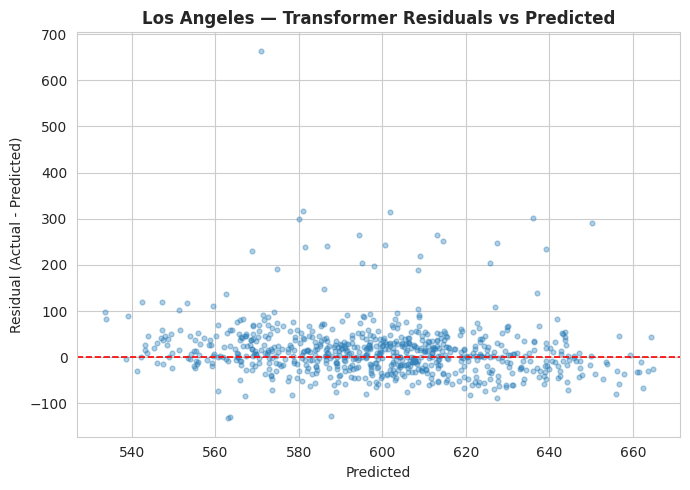

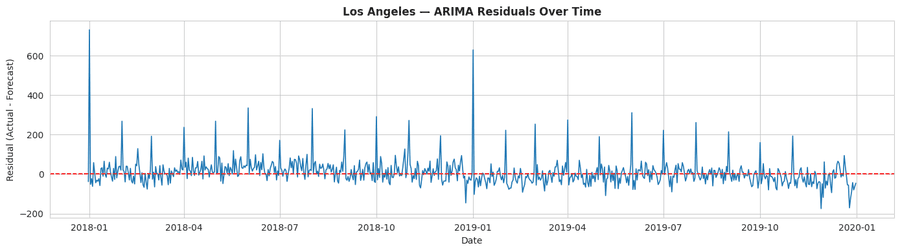

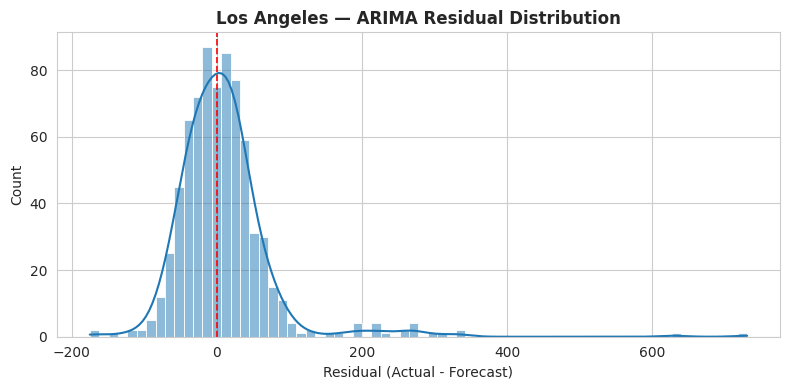

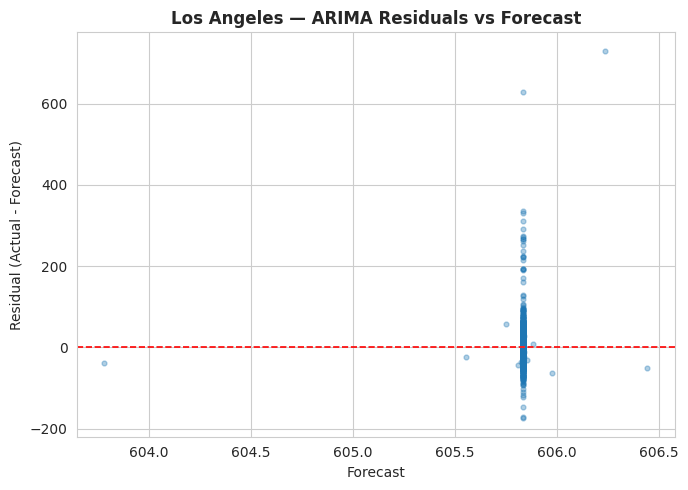

Residual plots saved for Los Angeles (DL + ARIMA).


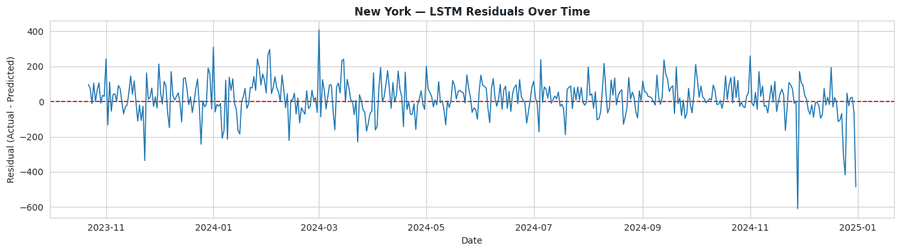

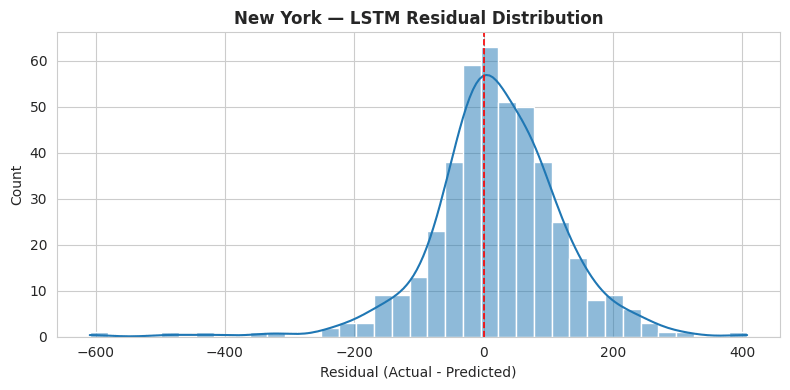

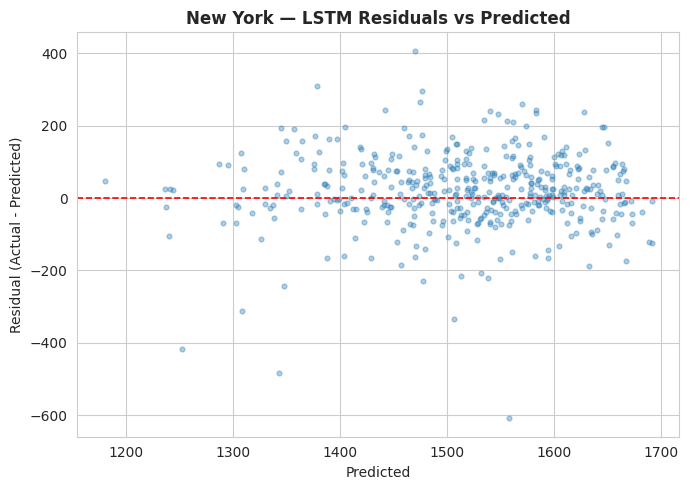

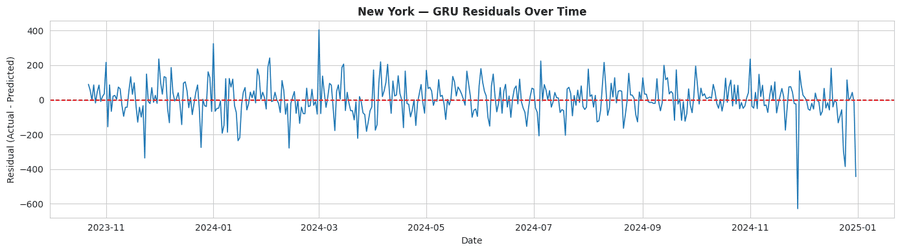

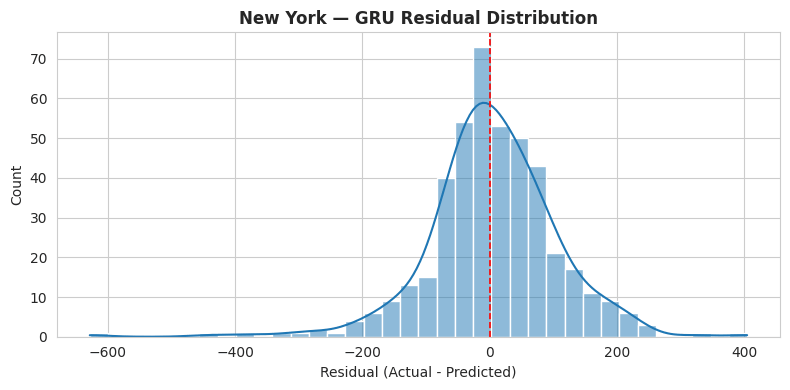

...

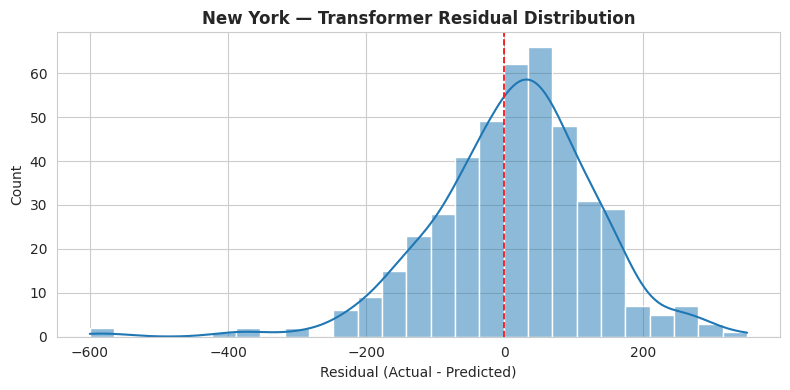

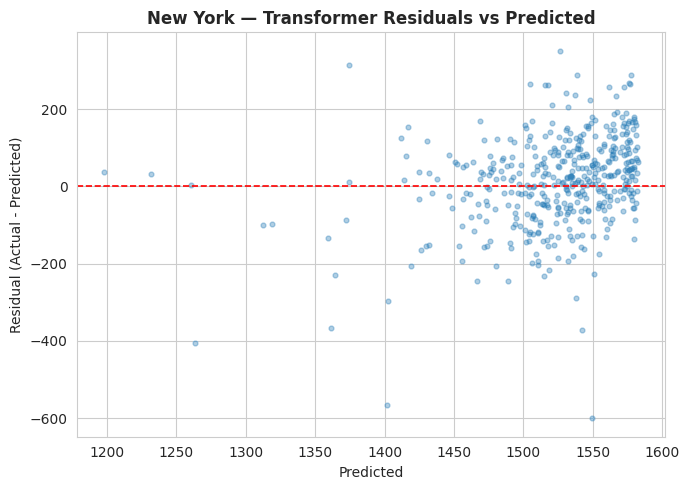

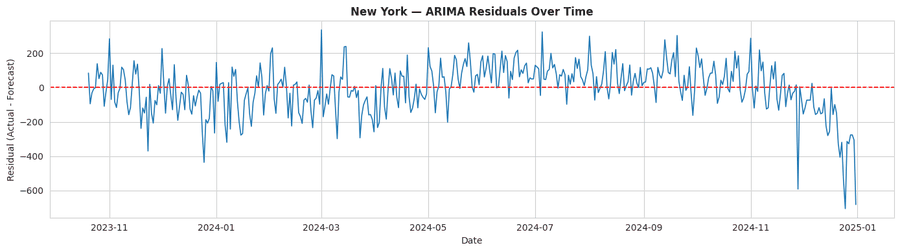

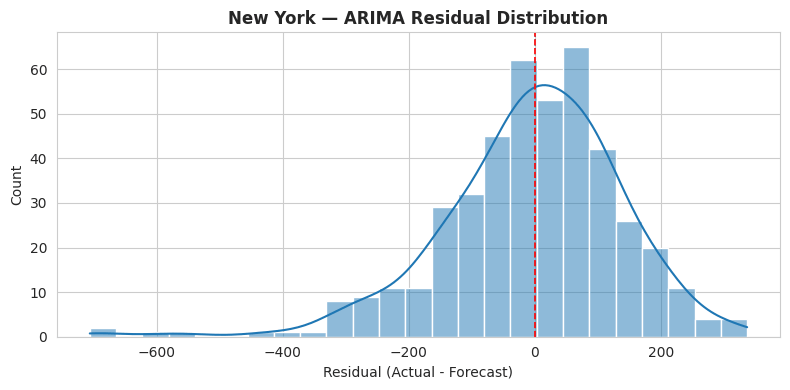

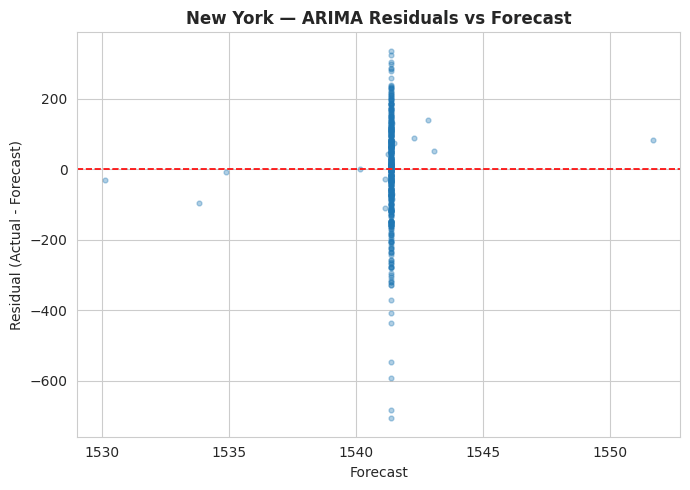

Residual plots saved for New York (DL + ARIMA).


In [45]:
# CELL 40A — Residual Plots for All Forecasting Models (DL + ARIMA)

def plot_all_forecast_residuals(dl_pack, dl_preds, arima_pred, arima_daily_df, city_key, city_title):
    city_plot = os.path.join(BASE_OUT, city_key, "plots")
    city_table = os.path.join(BASE_OUT, city_key, "tables")

    # -----------------------------
    # DL residual plots
    # -----------------------------
    y_true_dl = np.asarray(dl_pack["y_test_raw"]).reshape(-1)
    dl_dates = pd.to_datetime(dl_pack["test_dates"])

    dl_residual_summary = []

    for model_name, pred in dl_preds.items():
        pred = np.asarray(pred).reshape(-1)
        min_len = min(len(y_true_dl), len(pred), len(dl_dates))

        y_true_use = y_true_dl[-min_len:]
        pred_use = pred[-min_len:]
        dates_use = dl_dates[-min_len:]
        residuals = y_true_use - pred_use

        safe_name = model_name.lower().replace(" ", "_")

        # Residual vs time
        plt.figure(figsize=(14, 4))
        plt.plot(dates_use, residuals, linewidth=1.2)
        plt.axhline(0, color="red", linestyle="--", linewidth=1.2)
        plt.title(f"{city_title} — {model_name} Residuals Over Time", fontweight="bold")
        plt.xlabel("Date")
        plt.ylabel("Residual (Actual - Predicted)")
        plt.tight_layout()
        plt.savefig(os.path.join(city_plot, f"{safe_name}_residual_time_plot.png"), dpi=300)
        plt.show()

        # Residual distribution
        plt.figure(figsize=(8, 4))
        sns.histplot(residuals, kde=True)
        plt.axvline(0, color="red", linestyle="--", linewidth=1.2)
        plt.title(f"{city_title} — {model_name} Residual Distribution", fontweight="bold")
        plt.xlabel("Residual (Actual - Predicted)")
        plt.tight_layout()
        plt.savefig(os.path.join(city_plot, f"{safe_name}_residual_distribution.png"), dpi=300)
        plt.show()

        # Residual vs predicted
        plt.figure(figsize=(7, 5))
        plt.scatter(pred_use, residuals, alpha=0.35, s=12)
        plt.axhline(0, color="red", linestyle="--", linewidth=1.2)
        plt.title(f"{city_title} — {model_name} Residuals vs Predicted", fontweight="bold")
        plt.xlabel("Predicted")
        plt.ylabel("Residual (Actual - Predicted)")
        plt.tight_layout()
        plt.savefig(os.path.join(city_plot, f"{safe_name}_residual_vs_predicted.png"), dpi=300)
        plt.show()

        tmp_df = pd.DataFrame({
            "City": city_key,
            "Model": model_name,
            "date_only": dates_use,
            "actual": y_true_use,
            "predicted": pred_use,
            "residual": residuals
        })
        tmp_df.to_csv(os.path.join(city_table, f"{safe_name}_residual_details.csv"), index=False)

        dl_residual_summary.append({
            "City": city_key,
            "Model": model_name,
            "Residual_Mean": float(np.mean(residuals)),
            "Residual_STD": float(np.std(residuals)),
            "Residual_MAE": float(np.mean(np.abs(residuals)))
        })

    dl_residual_summary_df = pd.DataFrame(dl_residual_summary)
    dl_residual_summary_df.to_csv(
        os.path.join(city_table, f"{city_key}_dl_residual_summary.csv"),
        index=False
    )

    # -----------------------------
    # ARIMA residual plots
    # -----------------------------
    arima_df = arima_daily_df.copy()
    arima_df["date_only"] = pd.to_datetime(arima_df["date_only"])

    split_idx = int(len(arima_df) * 0.8)
    arima_test_df = arima_df.iloc[split_idx:].copy()

    y_true_arima = arima_test_df["crime_count"].values.astype(float)
    arima_dates = arima_test_df["date_only"].values
    arima_pred = np.asarray(arima_pred).reshape(-1)

    min_len = min(len(y_true_arima), len(arima_pred), len(arima_dates))
    y_true_arima = y_true_arima[-min_len:]
    arima_pred = arima_pred[-min_len:]
    arima_dates = pd.to_datetime(arima_dates[-min_len:])
    arima_residuals = y_true_arima - arima_pred

    # Residual vs time
    plt.figure(figsize=(14, 4))
    plt.plot(arima_dates, arima_residuals, linewidth=1.2)
    plt.axhline(0, color="red", linestyle="--", linewidth=1.2)
    plt.title(f"{city_title} — ARIMA Residuals Over Time", fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Residual (Actual - Forecast)")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_arima_residual_time_plot.png"), dpi=300)
    plt.show()

    # Residual distribution
    plt.figure(figsize=(8, 4))
    sns.histplot(arima_residuals, kde=True)
    plt.axvline(0, color="red", linestyle="--", linewidth=1.2)
    plt.title(f"{city_title} — ARIMA Residual Distribution", fontweight="bold")
    plt.xlabel("Residual (Actual - Forecast)")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_arima_residual_distribution.png"), dpi=300)
    plt.show()

    # Residual vs predicted
    plt.figure(figsize=(7, 5))
    plt.scatter(arima_pred, arima_residuals, alpha=0.35, s=12)
    plt.axhline(0, color="red", linestyle="--", linewidth=1.2)
    plt.title(f"{city_title} — ARIMA Residuals vs Forecast", fontweight="bold")
    plt.xlabel("Forecast")
    plt.ylabel("Residual (Actual - Forecast)")
    plt.tight_layout()
    plt.savefig(os.path.join(city_plot, f"{city_key}_arima_residual_vs_forecast.png"), dpi=300)
    plt.show()

    arima_out_df = pd.DataFrame({
        "City": city_key,
        "Model": "ARIMA",
        "date_only": arima_dates,
        "actual": y_true_arima,
        "predicted": arima_pred,
        "residual": arima_residuals
    })
    arima_out_df.to_csv(
        os.path.join(city_table, f"{city_key}_arima_residual_details.csv"),
        index=False
    )

    print(f"Residual plots saved for {city_title} (DL + ARIMA).")


plot_all_forecast_residuals(
    chi_dl, chi_dl_preds, chi_arima_forecast, chi_daily_total, "chicago", "Chicago"
)
plot_all_forecast_residuals(
    la_dl, la_dl_preds, la_arima_forecast, la_daily_total, "los_angeles", "Los Angeles"
)
plot_all_forecast_residuals(
    nyc_dl, nyc_dl_preds, nyc_arima_forecast, nyc_daily_total, "new_york", "New York"
)

# *PART 6 — CRIME CATEGORY FORECASTING*

In [46]:
# CELL 41 — Build Top Category Daily Panels
def build_top_category_panel(df, city_key, top_n=5):
    top_cats = df["crime_type"].value_counts().head(top_n).index.tolist()
    daily_total = df.groupby("date_only").size().rename("total_crime")

    daily_cat = (
        df[df["crime_type"].isin(top_cats)]
        .groupby(["date_only", "crime_type"]).size()
        .unstack(fill_value=0)
    )

    panel = pd.concat([daily_total, daily_cat], axis=1).fillna(0).reset_index()
    panel.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_top_category_panel.csv"), index=False)

    with open(os.path.join(BASE_OUT, city_key, "reports", f"{city_key}_top_categories.txt"), "w") as f:
        for c in top_cats:
            f.write(str(c) + "\n")

    return panel, top_cats


chi_cat_panel, chi_top_cats = build_top_category_panel(df_chi, "chicago", top_n=5)
la_cat_panel, la_top_cats   = build_top_category_panel(df_la, "los_angeles", top_n=5)
nyc_cat_panel, nyc_top_cats = build_top_category_panel(df_nyc, "new_york", top_n=5)

print("Chicago top categories:", chi_top_cats)
print("LA top categories:", la_top_cats)
print("NYC top categories:", nyc_top_cats)


Chicago top categories: ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'NARCOTICS', 'ASSAULT']
LA top categories: ['BATTERY - SIMPLE ASSAULT', 'BURGLARY FROM VEHICLE', 'VEHICLE - STOLEN', 'THEFT PLAIN - PETTY ($950 & UNDER)', 'BURGLARY']
NYC top categories: ['PETIT LARCENY', 'HARRASSMENT 2', 'ASSAULT 3 & RELATED OFFENSES', 'CRIMINAL MISCHIEF & RELATED OF', 'GRAND LARCENY']


In [47]:
# CELL 42 — Category Forecast Function (DL) FIXED TABLE OUTPUT

def run_category_dl_forecast(panel_df, category_name, city_key, look_back=30, epochs=40):
    tmp = panel_df[["date_only", category_name]].copy()
    tmp.columns = ["date_only", "crime_count"]
    tmp = make_temporal_features_from_daily(tmp)
    dl_pack = prepare_dl_data(tmp, look_back=look_back)

    res = []
    for model_name, builder in {
        "LSTM": build_lstm_model,
        "GRU": build_gru_model,
        "CNN": build_cnn_model,
        "Transformer": build_transformer_model,
    }.items():
        metrics, model, pred, history = fit_predict_dl_model(
            builder, model_name, dl_pack, city_key,
            epochs=epochs, batch_size=32, patience=6
        )
        metrics["Category"] = category_name
        res.append(metrics)

    out_df = pd.DataFrame(res)
    out_df = out_df[
        ["City", "Category", "Model", "RMSE", "MAE", "R2", "NRMSE_pct", "sMAPE", "WAPE_pct", "MASE"]
    ].sort_values("RMSE").reset_index(drop=True)

    safe_cat = category_name.lower().replace(" ", "_").replace("/", "_")
    out_df.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{safe_cat}_dl_forecast_metrics.csv"), index=False)
    return out_df

In [48]:
# CELL 43 — Category Forecast Function (ARIMA/SARIMA) DAILY

def run_category_arima_forecast(panel_df, category_name, city_key):
    tmp = panel_df[["date_only", category_name]].copy()
    tmp.columns = ["date_only", "crime_count"]
    tmp["date_only"] = pd.to_datetime(tmp["date_only"])
    tmp = tmp.sort_values("date_only").reset_index(drop=True)

    # keep DAILY, no monthly resampling
    metrics, forecast = fit_best_arima_or_sarima(tmp, city_key)

    metrics["Category"] = category_name

    out_df = pd.DataFrame([metrics])
    safe_cat = category_name.lower().replace(" ", "_").replace("/", "_")
    out_df.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{safe_cat}_arima_forecast_metrics.csv"), index=False)

    return out_df


Running category forecasting for chicago: THEFT
Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.2650 - val_loss: 0.7342 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2155 - val_loss: 0.5167 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1962 - val_loss: 0.6571 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1874 - val_loss: 0.5809 - learning_rate: 0.0010
Epoch 5/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1893
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1893 - val_loss: 0.6071 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1804 - val_loss: 0.5598 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1692 - val_loss: 0.5507 - learning_rate: 5.0000e-04
Epoch 8/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0

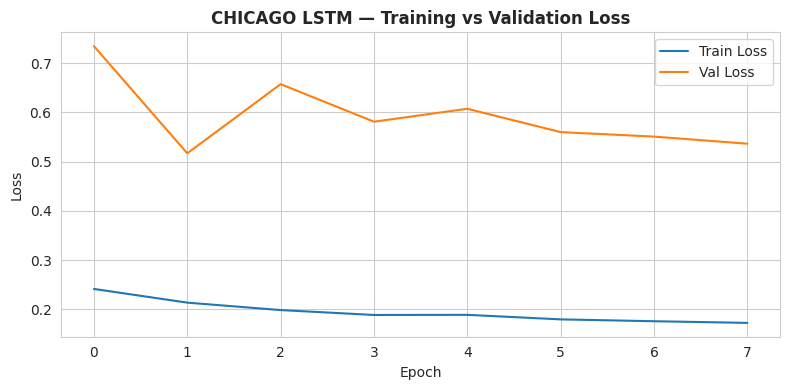

CHICAGO LSTM
Stopped at epoch 8
Final train loss: 0.172661
Final val loss: 0.536264
Ratio (val/train): 3.11
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


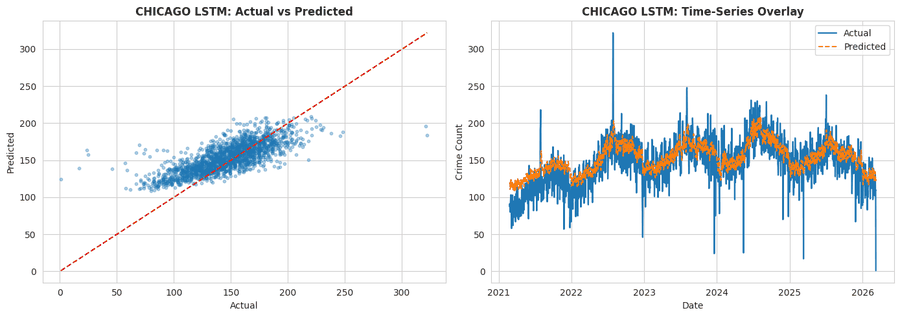

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3150 - val_loss: 0.6763 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2128 - val_loss: 0.5621 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2039 - val_loss: 0.5558 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1868 - val_loss: 0.5393 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1760 - val_loss: 0.5401 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1803 - val_loss: 0.6024 - learning_rate: 0.0010
Epoch 7/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1827
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1827 - val_loss: 0.5721 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1760 - val_loss: 0.5457 - learning_r

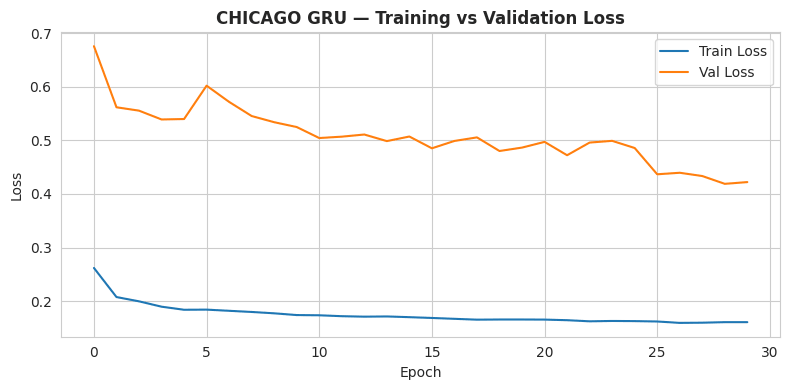

CHICAGO GRU
Stopped at epoch 30
Final train loss: 0.160475
Final val loss: 0.422245
Ratio (val/train): 2.63
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


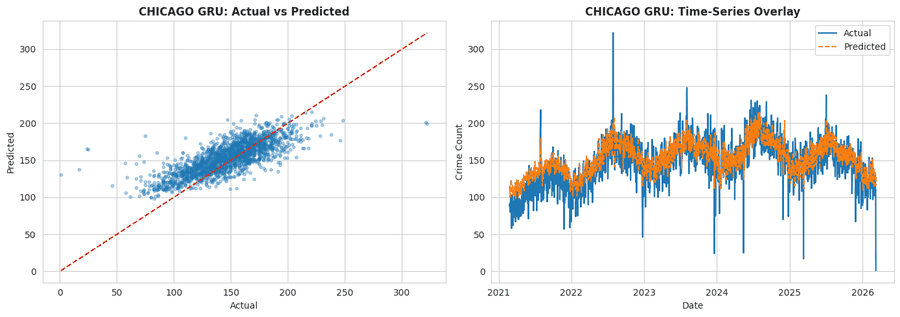

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.3646 - val_loss: 0.8791 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3047 - val_loss: 0.8749 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2582 - val_loss: 1.0529 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2481 - val_loss: 0.8781 - learning_rate: 0.0010
Epoch 5/30
180/195 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2401
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2399 - val_loss: 0.9512 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2366 - val_loss: 0.8331 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2260 - val_loss: 0.8422 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2268 - val_loss: 0.8455 - l

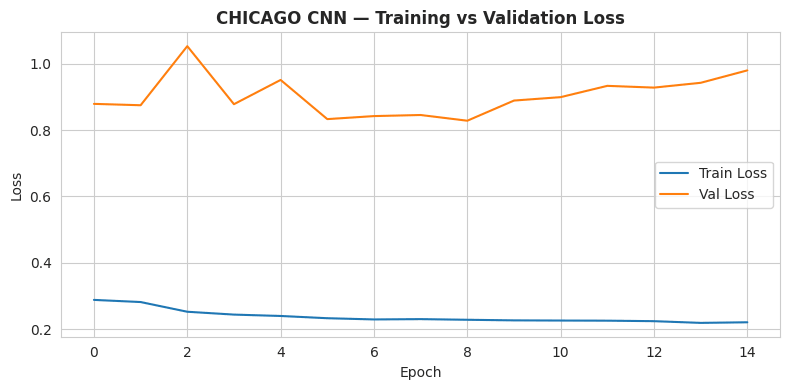

CHICAGO CNN
Stopped at epoch 15
Final train loss: 0.220801
Final val loss: 0.979963
Ratio (val/train): 4.44
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


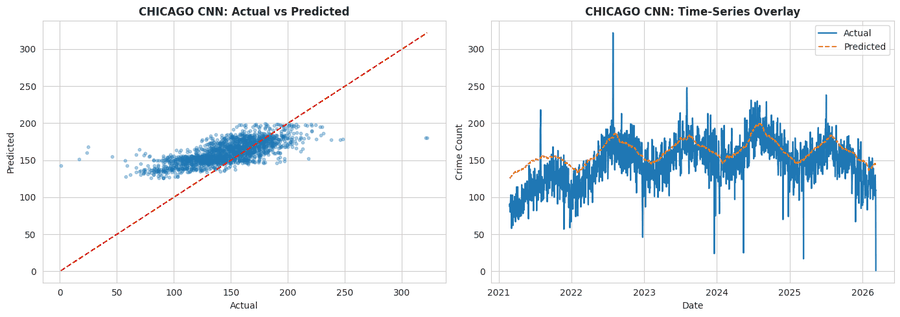

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - loss: 0.5047 - val_loss: 1.0213 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3033 - val_loss: 1.1521 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2696 - val_loss: 1.0298 - learning_rate: 0.0010
Epoch 4/30
192/195 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2553
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2552 - val_loss: 1.0664 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2533 - val_loss: 0.9889 - learning_rate: 5.0000e-04
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2419 - val_loss: 0.9615 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2336 - val_loss: 0.9782 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2331 - val_loss: 0.993

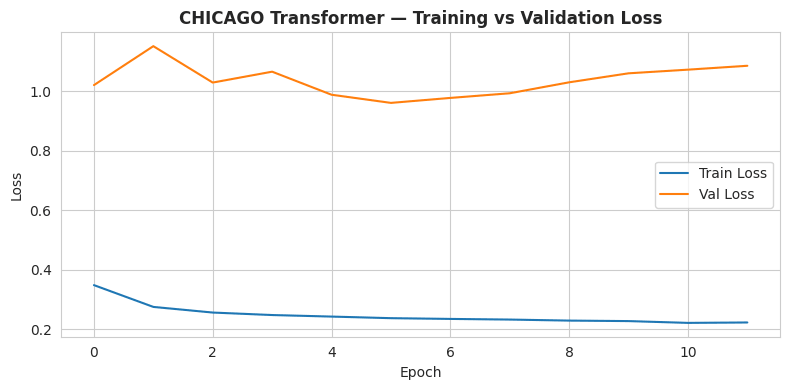

CHICAGO Transformer
Stopped at epoch 12
Final train loss: 0.223587
Final val loss: 1.086219
Ratio (val/train): 4.86
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


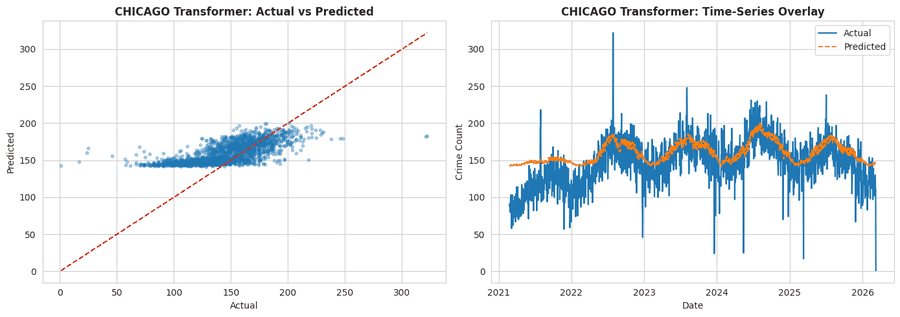

chicago ADF stat=-2.4623, p=0.1249
Selected DAILY ARIMA: (3, 1, 2)


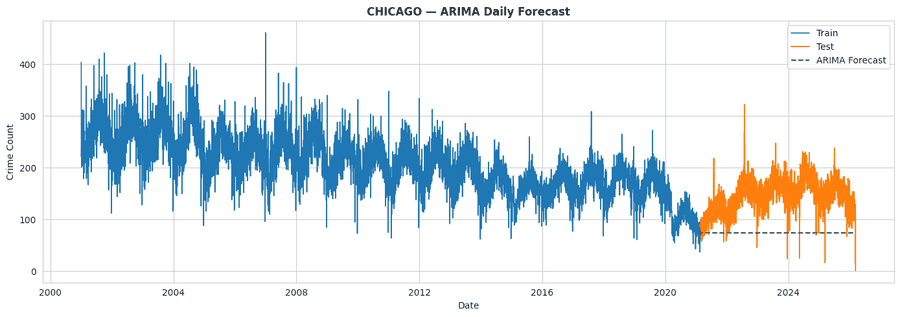

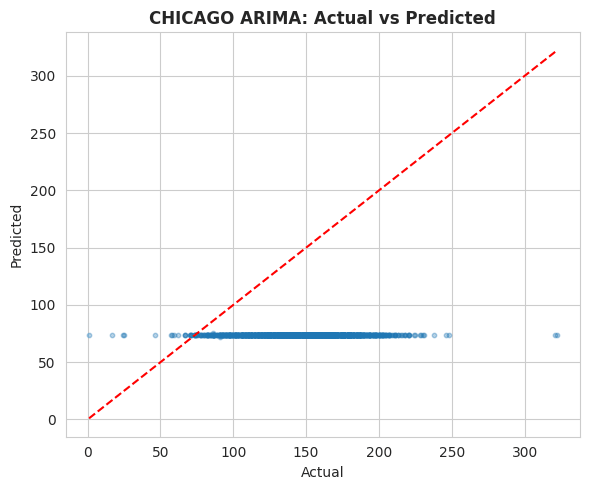

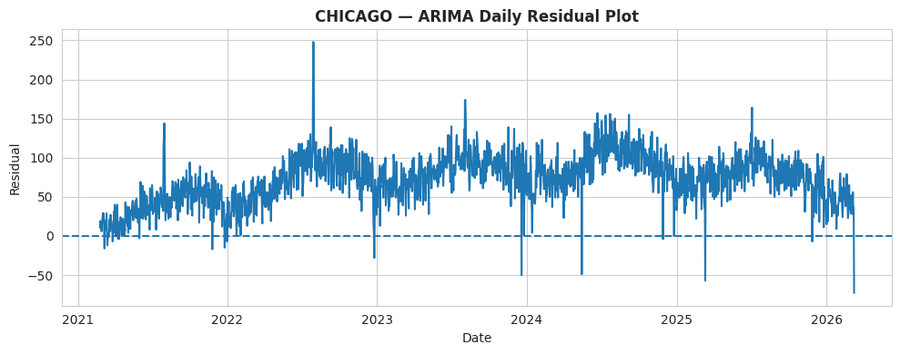

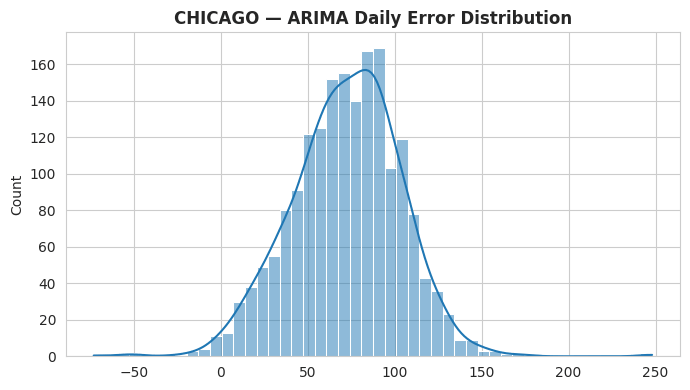


Running category forecasting for chicago: BATTERY
Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.6495 - val_loss: 0.2763 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2148 - val_loss: 0.2484 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2069 - val_loss: 0.2084 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1838 - val_loss: 0.2255 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1818 - val_loss: 0.2006 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1755 - val_loss: 0.1989 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1848 - val_loss: 0.1928 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1866 - val_loss: 0.1985 - learning_rate: 0.0010
Epoch 9/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1767 - 

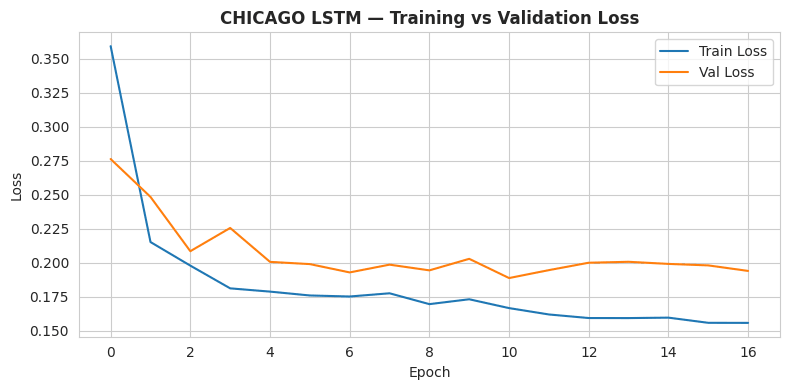

CHICAGO LSTM
Stopped at epoch 17
Final train loss: 0.155638
Final val loss: 0.193895
Ratio (val/train): 1.25
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


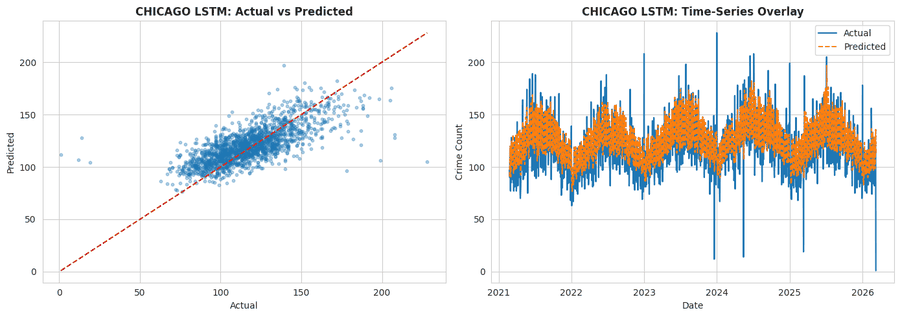

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3811 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1896 - val_loss: 0.1966 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1960 - val_loss: 0.2014 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1840 - val_loss: 0.1950 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1908 - val_loss: 0.1918 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1841 - val_loss: 0.1950 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1767 - val_loss: 0.1961 - learning_rate: 0.0010
Epoch 8/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1768
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1766 - val_loss: 0.2018 - learning_r

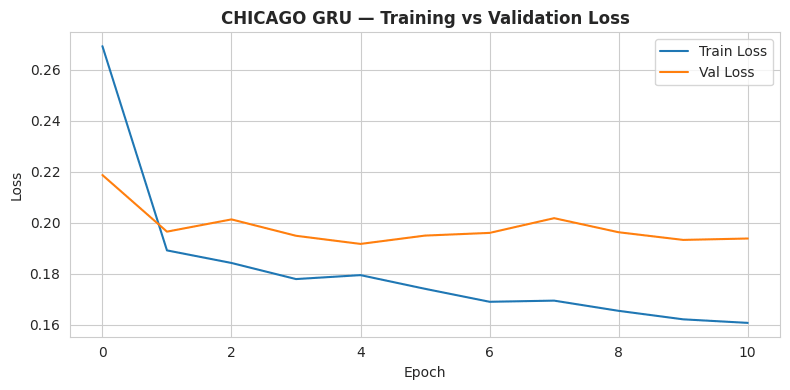

CHICAGO GRU
Stopped at epoch 11
Final train loss: 0.160825
Final val loss: 0.193878
Ratio (val/train): 1.21
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


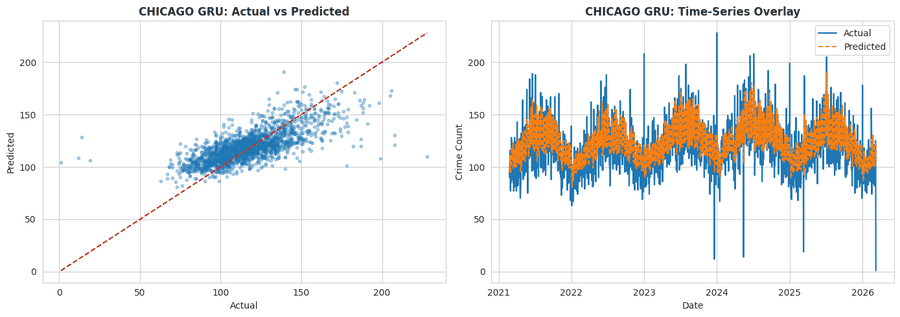

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.4146 - val_loss: 0.3395 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2463 - val_loss: 0.3277 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2555 - val_loss: 0.3230 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2561 - val_loss: 0.3417 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2570 - val_loss: 0.2964 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2665 - val_loss: 0.3081 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2522 - val_loss: 0.3137 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2433 - val_loss: 0.2892 - learning_rate: 0.0010
Epoch 9/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2447 - val_loss: 0.2832 - learning_rate: 0.0010
Epoch 10/

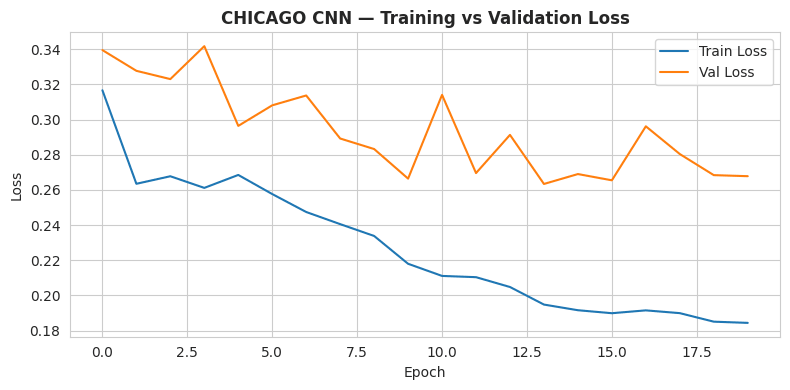

CHICAGO CNN
Stopped at epoch 20
Final train loss: 0.184379
Final val loss: 0.267791
Ratio (val/train): 1.45
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


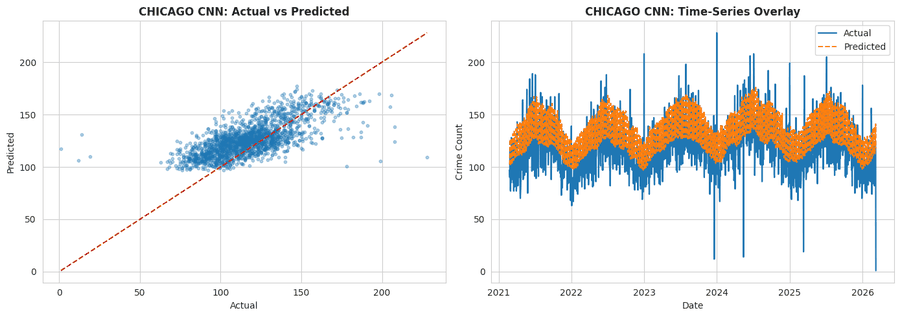

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - loss: 0.5431 - val_loss: 0.4030 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3588 - val_loss: 0.3958 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2757 - val_loss: 0.3559 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2688 - val_loss: 0.4197 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2839 - val_loss: 0.3952 - learning_rate: 0.0010
Epoch 6/30
193/195 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2793
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2792 - val_loss: 0.4334 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2928 - val_loss: 0.3154 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2551 - val_loss: 0.2884 - lear

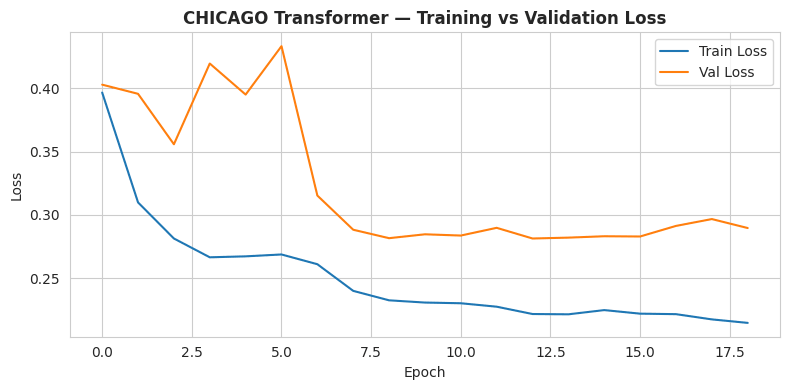

CHICAGO Transformer
Stopped at epoch 19
Final train loss: 0.214733
Final val loss: 0.289696
Ratio (val/train): 1.35
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


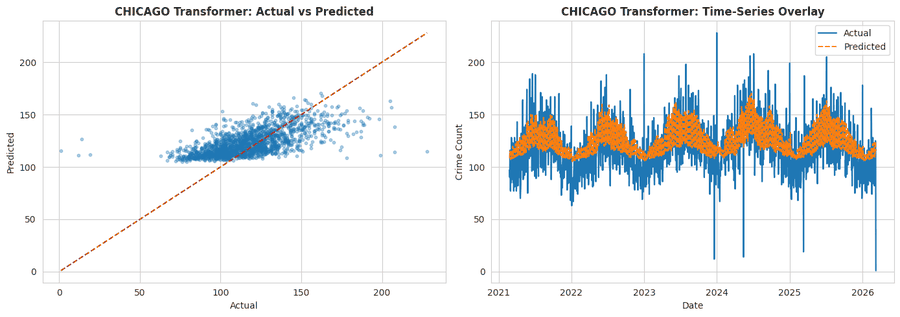

chicago ADF stat=-2.4046, p=0.1404
Selected DAILY ARIMA: (3, 1, 2)


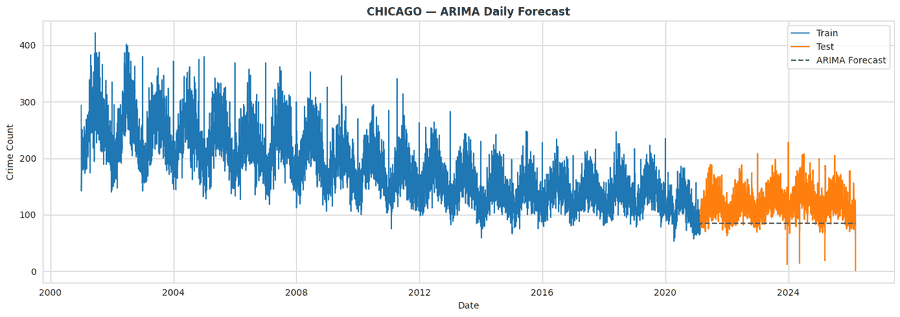

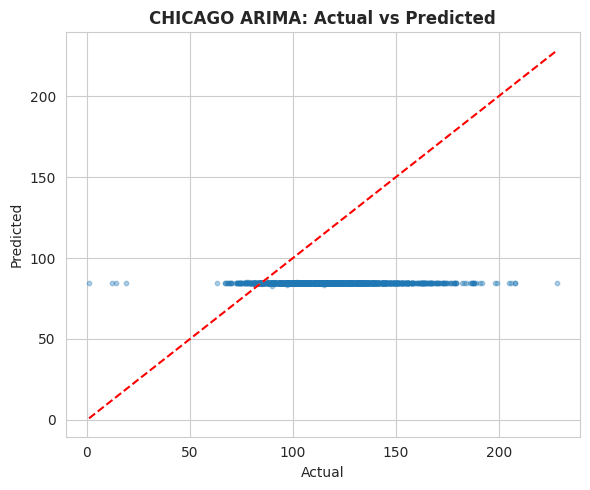

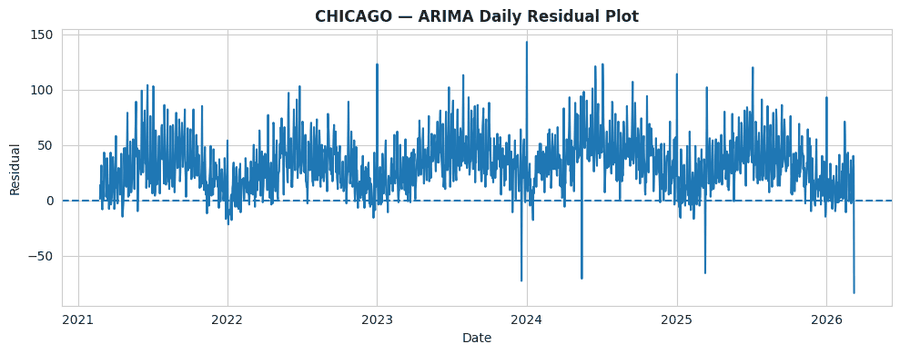

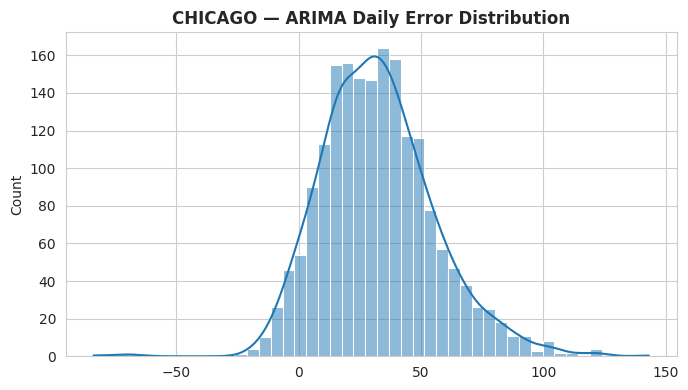


Running category forecasting for chicago: CRIMINAL DAMAGE
Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2745 - val_loss: 0.2468 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1598 - val_loss: 0.2292 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1537 - val_loss: 0.2259 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1509 - val_loss: 0.2228 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1484 - val_loss: 0.2208 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1448 - val_loss: 0.2231 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1451 - val_loss: 0.2195 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1457 - val_loss: 0.2227 - learning_rate: 0.0010
Epoch 9/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0

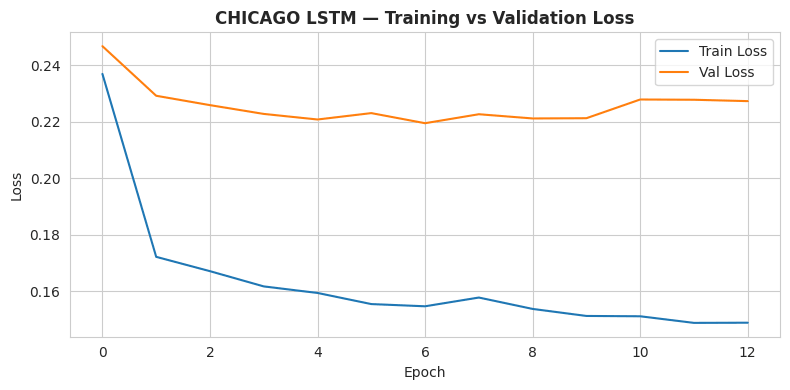

CHICAGO LSTM
Stopped at epoch 13
Final train loss: 0.148944
Final val loss: 0.227336
Ratio (val/train): 1.53
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


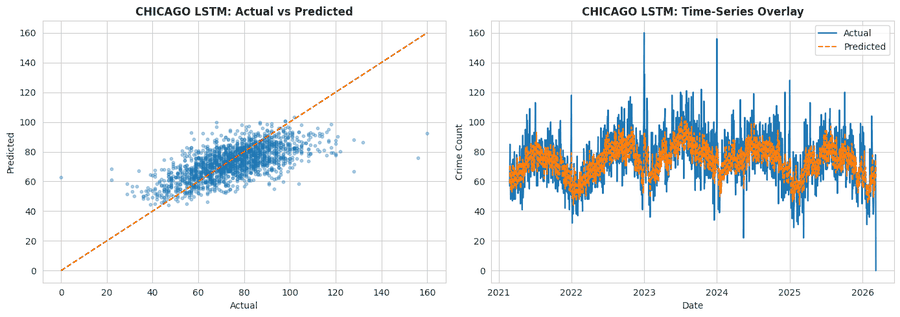

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3207 - val_loss: 0.2404 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1596 - val_loss: 0.2256 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1533 - val_loss: 0.2227 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1538 - val_loss: 0.2174 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1531 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1561 - val_loss: 0.2136 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1513 - val_loss: 0.2169 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1458 - val_loss: 0.2160 - learning_rate: 0.0010
Epoch 9/30
186/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1512
Epoch 9: ReduceLROnPlateau reducing learning rate to 

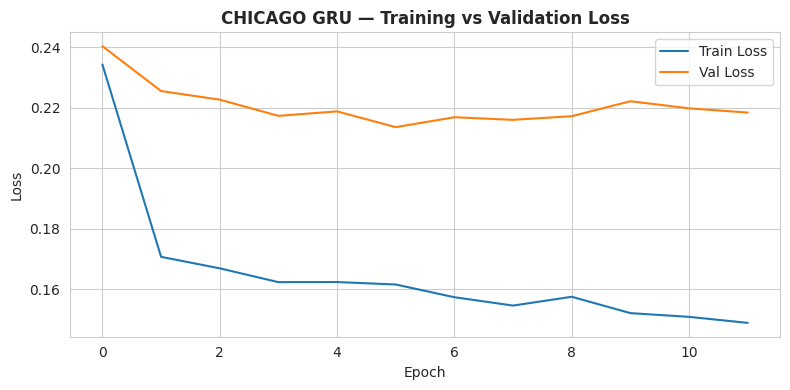

CHICAGO GRU
Stopped at epoch 12
Final train loss: 0.148932
Final val loss: 0.218444
Ratio (val/train): 1.47
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


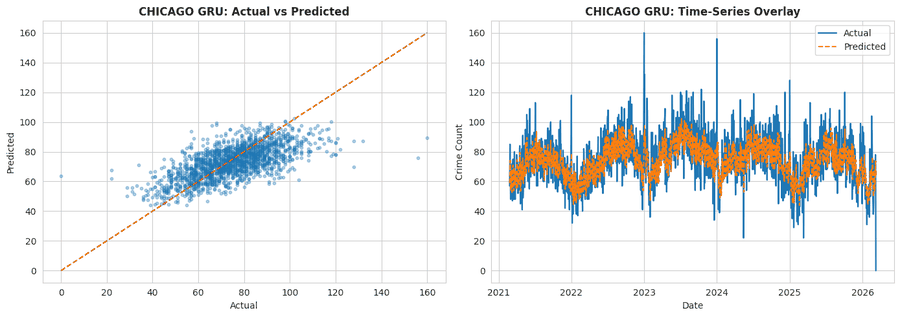

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.2580 - val_loss: 0.3133 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2485 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2620 - val_loss: 0.2838 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2628 - val_loss: 0.2771 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2419 - val_loss: 0.2741 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2354 - val_loss: 0.2726 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2334 - val_loss: 0.2690 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2290 - val_loss: 0.2725 - learning_rate: 0.0010
Epoch 9/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2327 - val_loss: 0.2692 - learning_rate: 0.0010
Epoch 10/

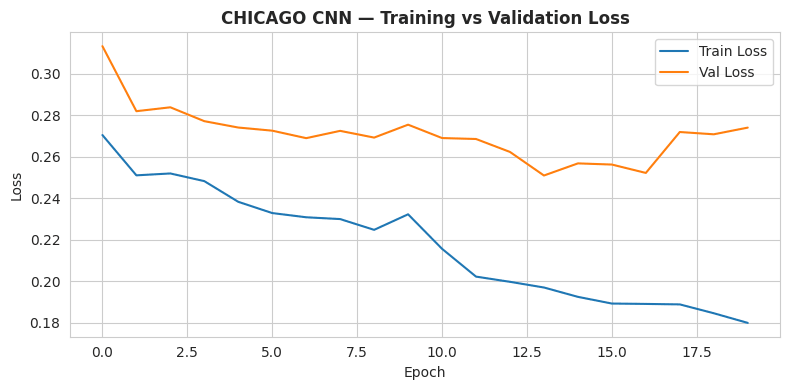

CHICAGO CNN
Stopped at epoch 20
Final train loss: 0.180021
Final val loss: 0.274040
Ratio (val/train): 1.52
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


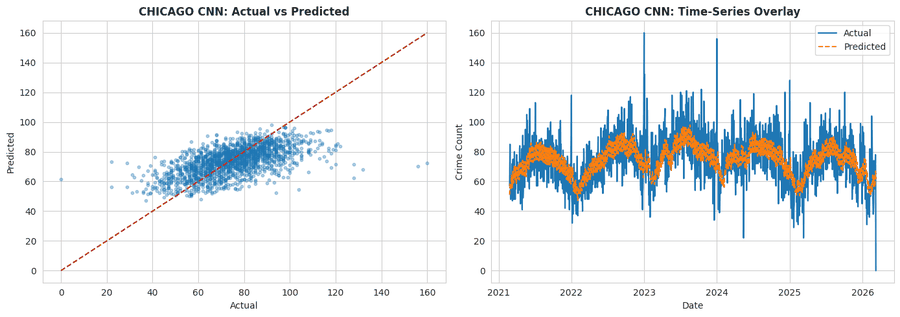

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - loss: 0.3026 - val_loss: 0.4219 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2499 - val_loss: 0.3583 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2625 - val_loss: 0.3215 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2552 - val_loss: 0.3487 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2566 - val_loss: 0.2921 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2198 - val_loss: 0.3229 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2108 - val_loss: 0.2905 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2129 - val_loss: 0.3029 - learning_rate: 0.0010
Epoch 9/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2189 - val_loss: 0.2902 - learning_rate: 0.0010
Epoch 10

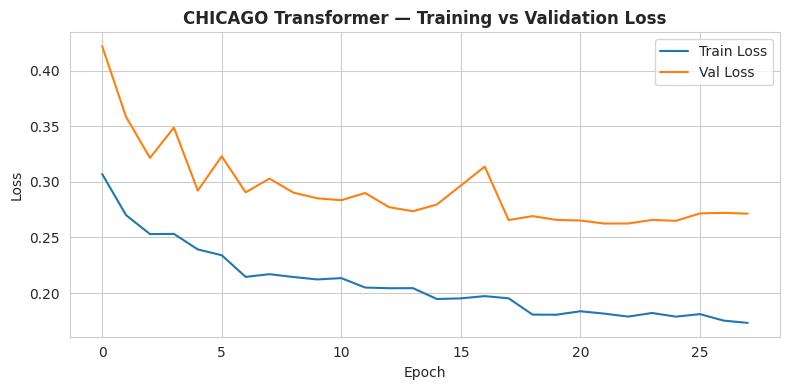

CHICAGO Transformer
Stopped at epoch 28
Final train loss: 0.173174
Final val loss: 0.271328
Ratio (val/train): 1.57
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


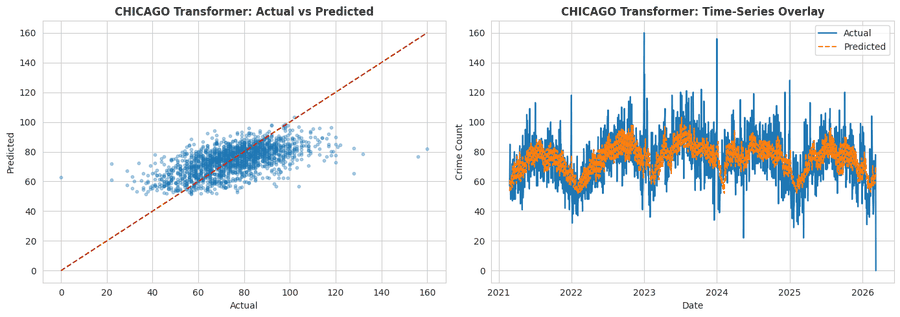

chicago ADF stat=-2.9529, p=0.0395
Selected DAILY ARIMA: (3, 1, 2)


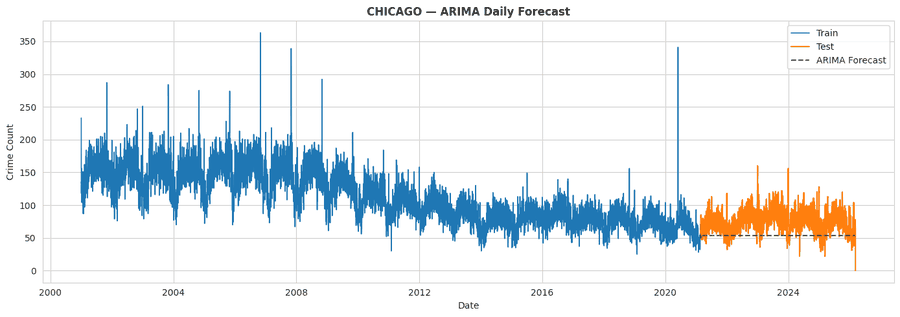

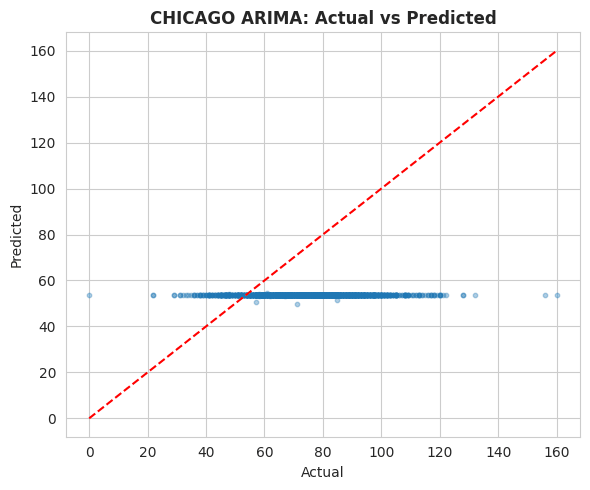

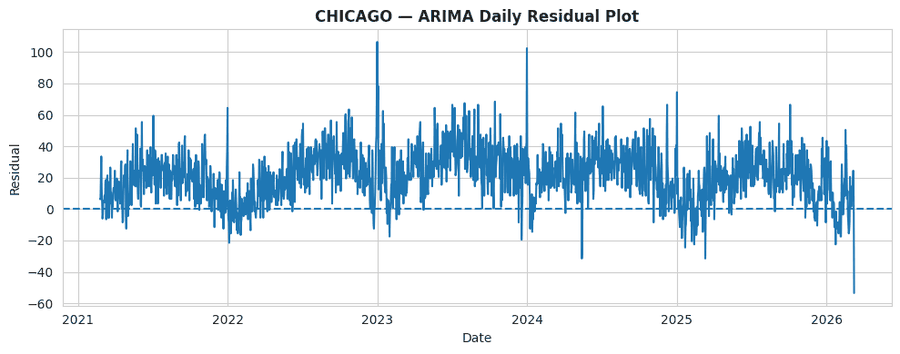

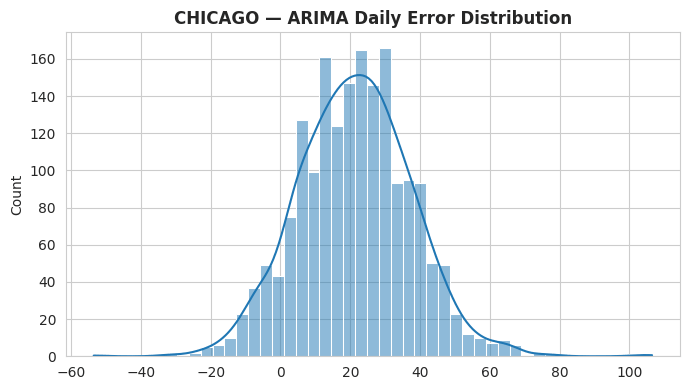


Running category forecasting for chicago: NARCOTICS
Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1687 - val_loss: 0.6937 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1112 - val_loss: 0.5808 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1086 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1040 - val_loss: 0.4669 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0964 - val_loss: 0.3912 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0950 - val_loss: 0.4447 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0970 - val_loss: 0.4671 - learning_rate: 0.0010
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0969
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6m

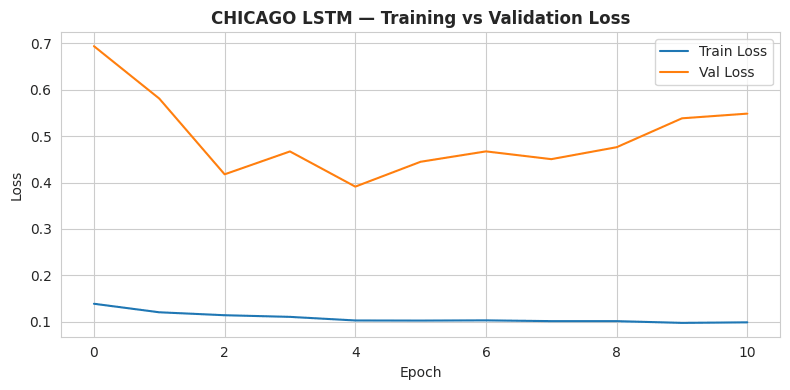

CHICAGO LSTM
Stopped at epoch 11
Final train loss: 0.098866
Final val loss: 0.548384
Ratio (val/train): 5.55
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


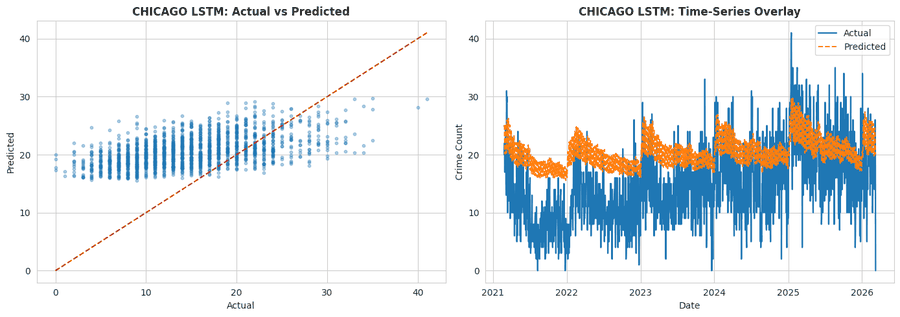

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1809 - val_loss: 0.5583 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1103 - val_loss: 0.4063 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1059 - val_loss: 0.3505 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1000 - val_loss: 0.3964 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0999 - val_loss: 0.3788 - learning_rate: 0.0010
Epoch 6/30
194/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0971
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0971 - val_loss: 0.3850 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1005 - val_loss: 0.4076 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0911 - val_loss: 0.3818 - learni

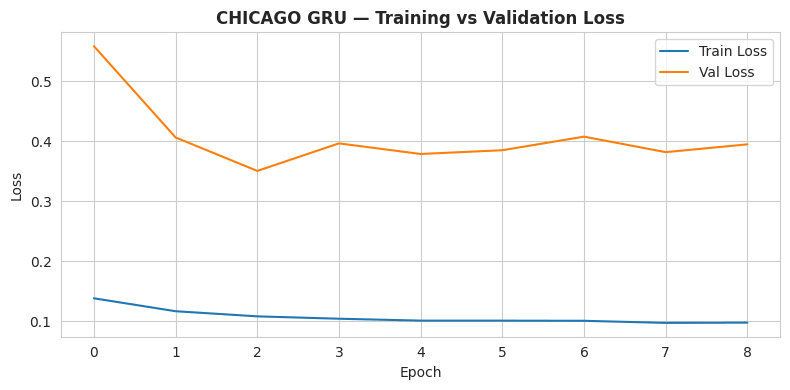

CHICAGO GRU
Stopped at epoch 9
Final train loss: 0.097900
Final val loss: 0.394777
Ratio (val/train): 4.03
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


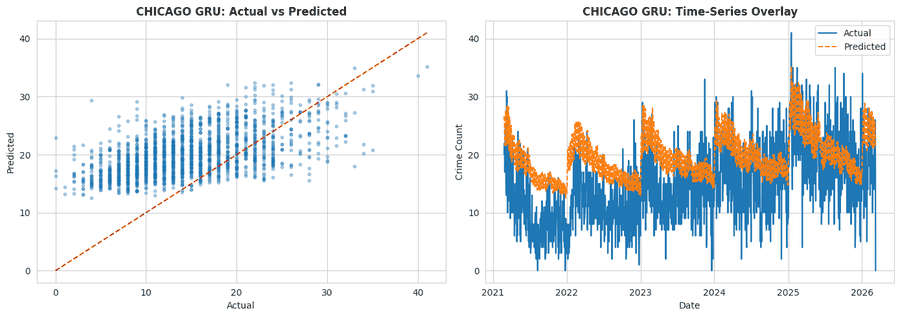

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2982 - val_loss: 0.4915 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1584 - val_loss: 0.5688 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1466 - val_loss: 0.4872 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1330 - val_loss: 0.5963 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1227 - val_loss: 0.5790 - learning_rate: 0.0010
Epoch 6/30
184/195 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1290
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1288 - val_loss: 0.5494 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1290 - val_loss: 0.6710 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1094 - val_loss: 0.7110 - learn

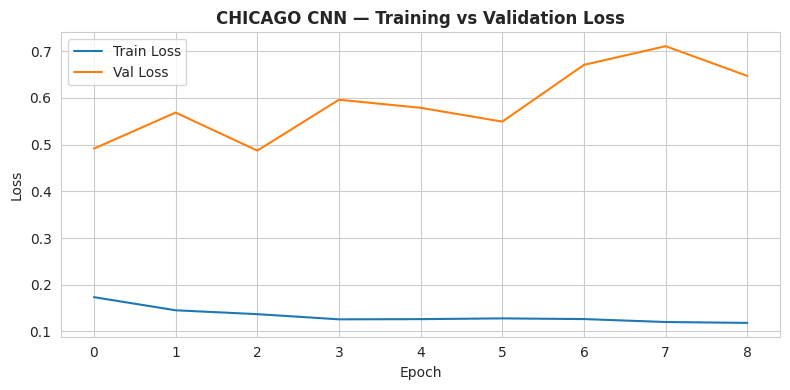

CHICAGO CNN
Stopped at epoch 9
Final train loss: 0.118147
Final val loss: 0.647257
Ratio (val/train): 5.48
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


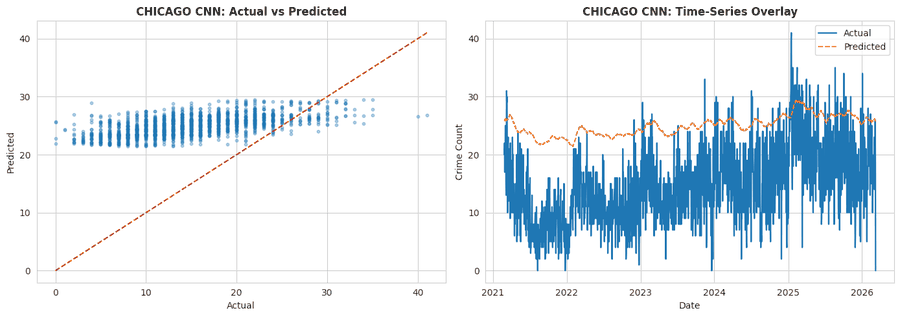

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - loss: 0.1906 - val_loss: 0.7426 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1593 - val_loss: 0.8172 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2089 - val_loss: 0.6883 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3801 - val_loss: 0.7085 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1822 - val_loss: 0.7026 - learning_rate: 0.0010
Epoch 6/30
181/195 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1478
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1472 - val_loss: 0.7147 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1375 - val_loss: 0.6787 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1263 - val_loss: 0.6946 - lear

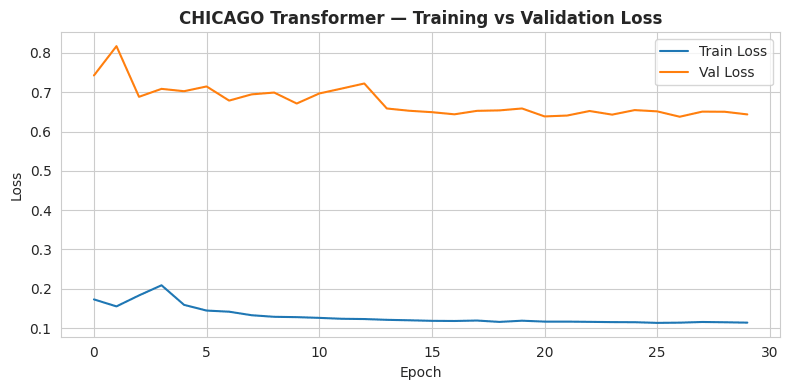

CHICAGO Transformer
Stopped at epoch 30
Final train loss: 0.113679
Final val loss: 0.643517
Ratio (val/train): 5.66
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


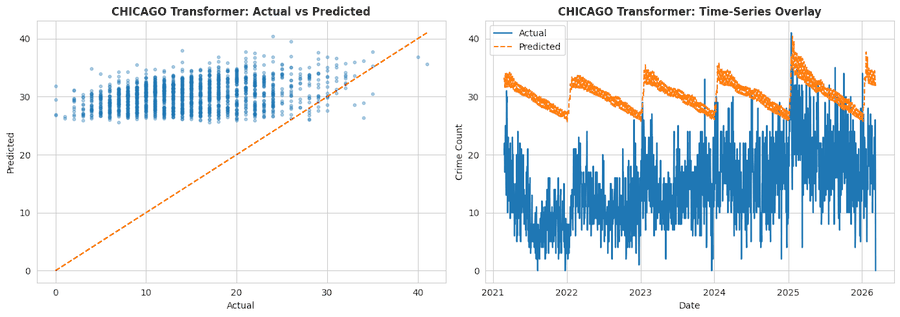

chicago ADF stat=-1.6510, p=0.4565
Selected DAILY ARIMA: (3, 1, 2)


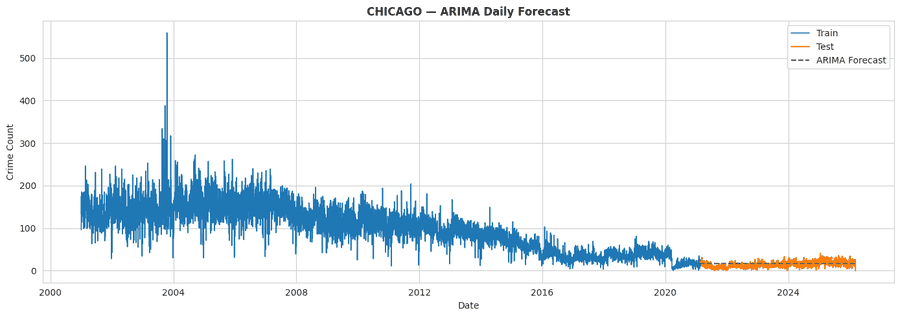

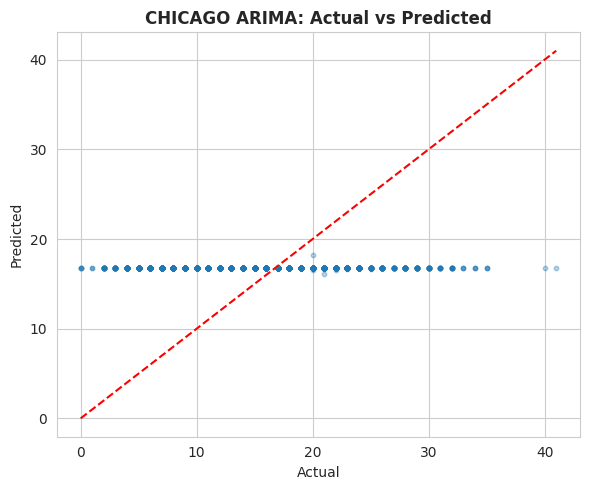

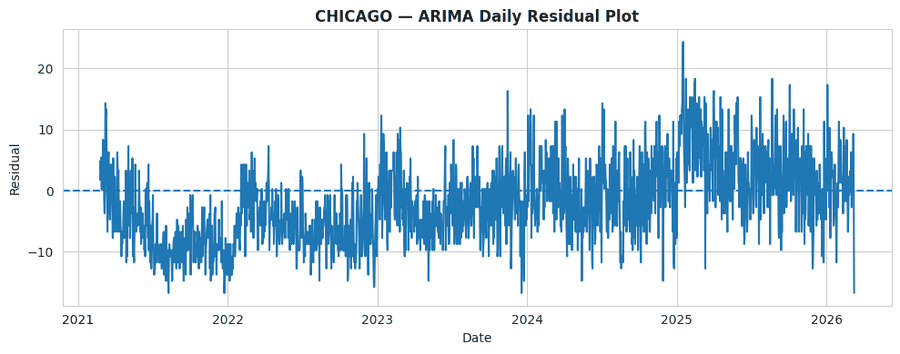

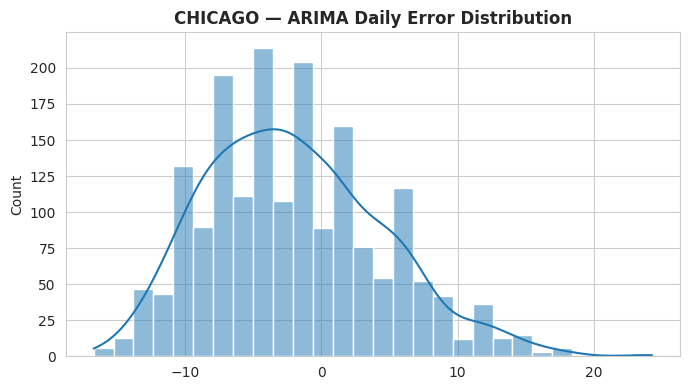


Running category forecasting for chicago: ASSAULT
Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.4885 - val_loss: 0.3050 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3484 - val_loss: 0.2973 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3472 - val_loss: 0.2985 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3354 - val_loss: 0.2972 - learning_rate: 0.0010
Epoch 5/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3302
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3304 - val_loss: 0.2989 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3353 - val_loss: 0.2988 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3142 - val_loss: 0.2970 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━

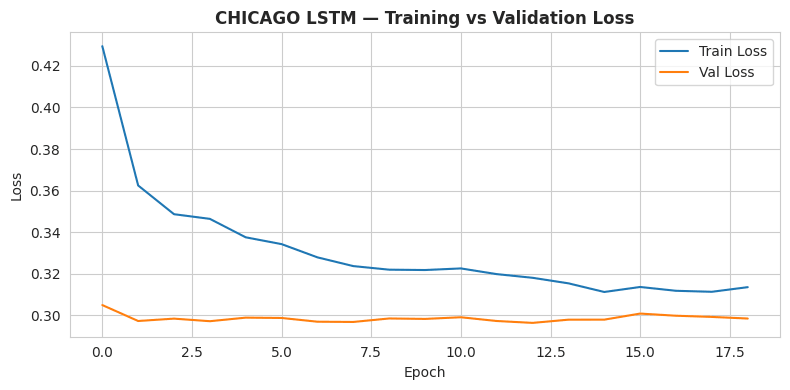

CHICAGO LSTM
Stopped at epoch 19
Final train loss: 0.313606
Final val loss: 0.298526
Ratio (val/train): 0.95
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


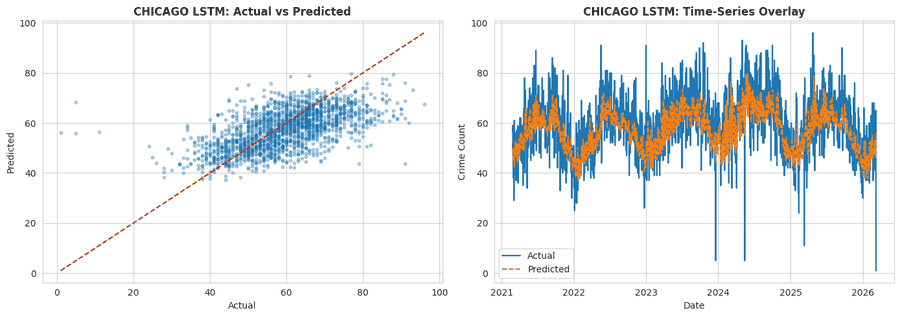

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.4381 - val_loss: 0.2968 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3378 - val_loss: 0.2940 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3650 - val_loss: 0.2974 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3440 - val_loss: 0.2962 - learning_rate: 0.0010
Epoch 5/30
187/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3389
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3390 - val_loss: 0.3007 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3374 - val_loss: 0.2987 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3147 - val_loss: 0.2980 - learning_rate: 5.0000e-04
Epoch 8/30
192/195 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3146
Epoch 8: ReduceLROnPlat

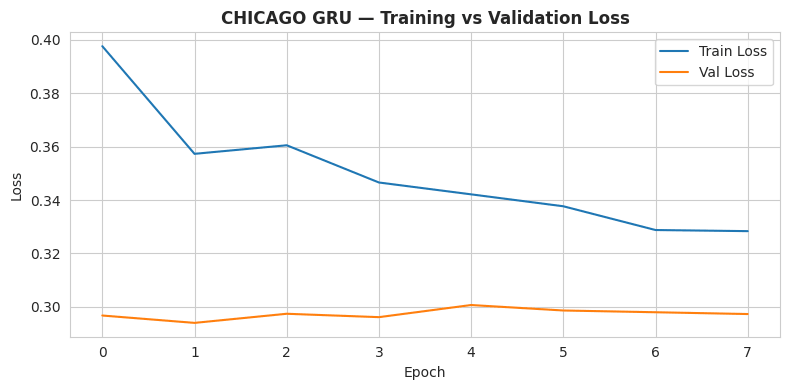

CHICAGO GRU
Stopped at epoch 8
Final train loss: 0.328368
Final val loss: 0.297339
Ratio (val/train): 0.91
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


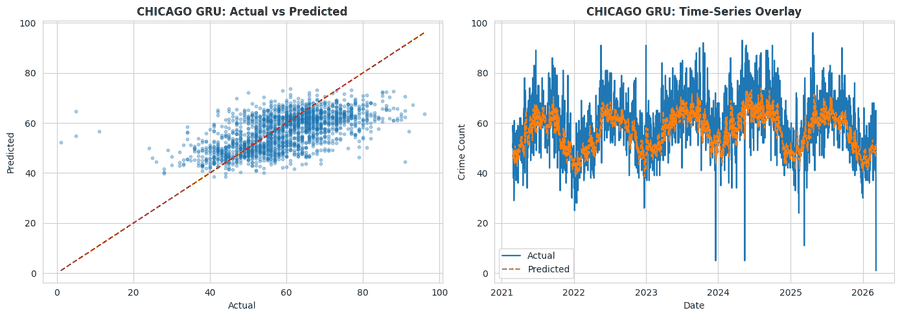

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.5033 - val_loss: 0.3209 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3877 - val_loss: 0.3182 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4101 - val_loss: 0.3197 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4116 - val_loss: 0.3205 - learning_rate: 0.0010
Epoch 5/30
186/195 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4471
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4453 - val_loss: 0.3207 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4059 - val_loss: 0.3163 - learning_rate: 5.0000e-04
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3872 - val_loss: 0.3145 - learning_rate: 5.0000e-04
Epoch 8/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3848 - val_loss: 0.3180 - l

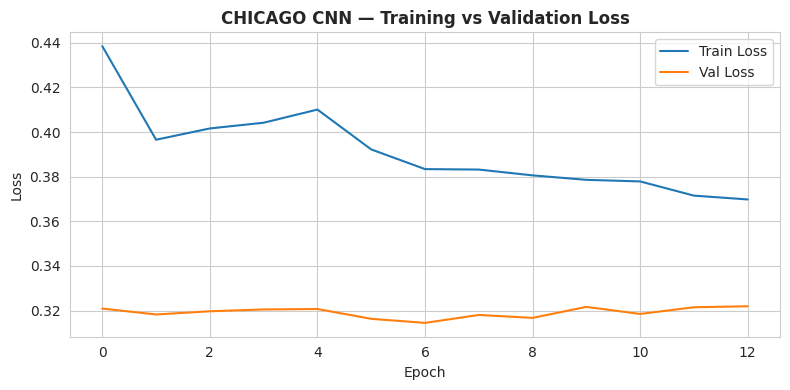

CHICAGO CNN
Stopped at epoch 13
Final train loss: 0.369805
Final val loss: 0.321921
Ratio (val/train): 0.87
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


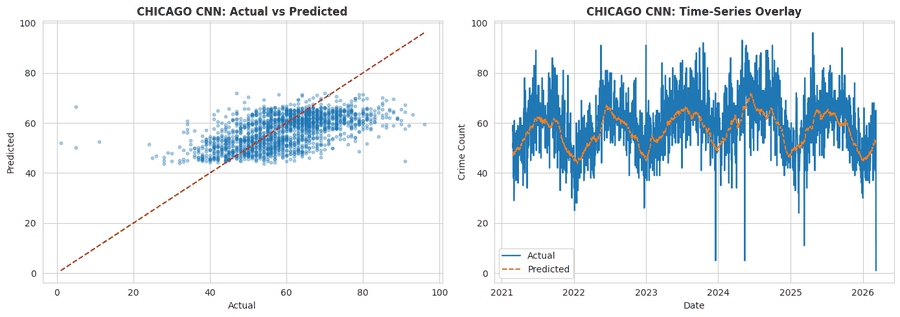

Epoch 1/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - loss: 0.4809 - val_loss: 0.3130 - learning_rate: 0.0010
Epoch 2/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5003 - val_loss: 0.3124 - learning_rate: 0.0010
Epoch 3/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4436 - val_loss: 0.3105 - learning_rate: 0.0010
Epoch 4/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4190 - val_loss: 0.3116 - learning_rate: 0.0010
Epoch 5/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3935 - val_loss: 0.3044 - learning_rate: 0.0010
Epoch 6/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3864 - val_loss: 0.3097 - learning_rate: 0.0010
Epoch 7/30
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3950 - val_loss: 0.3173 - learning_rate: 0.0010
Epoch 8/30
191/195 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3945
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3943 - val_loss: 0.3076 - learning

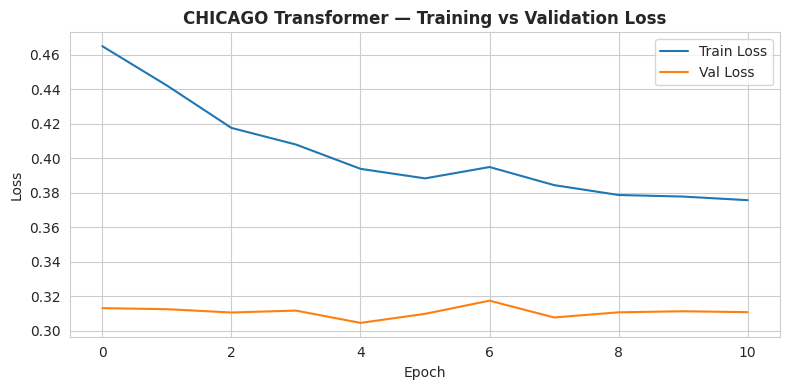

CHICAGO Transformer
Stopped at epoch 11
Final train loss: 0.375682
Final val loss: 0.310674
Ratio (val/train): 0.83
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


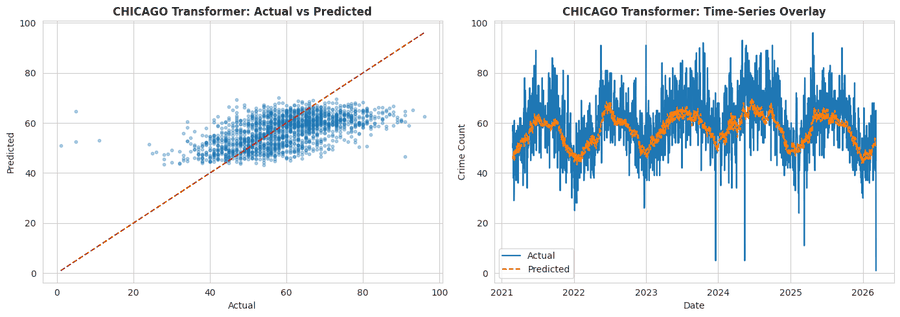

chicago ADF stat=-3.2189, p=0.0189
Selected DAILY ARIMA: (3, 1, 2)


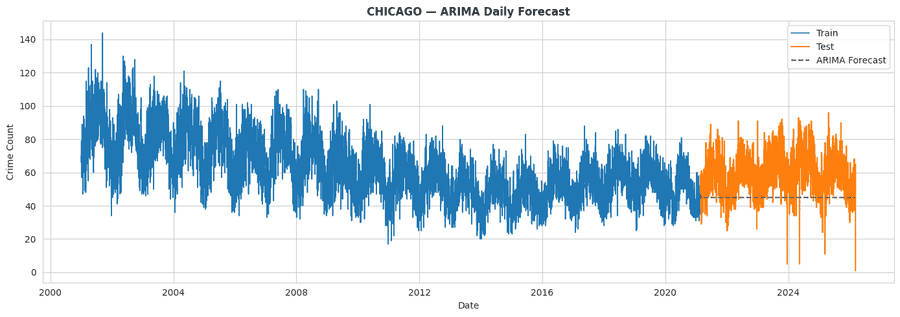

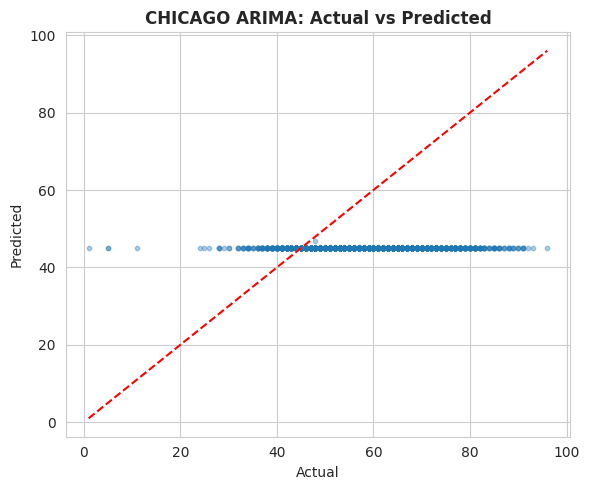

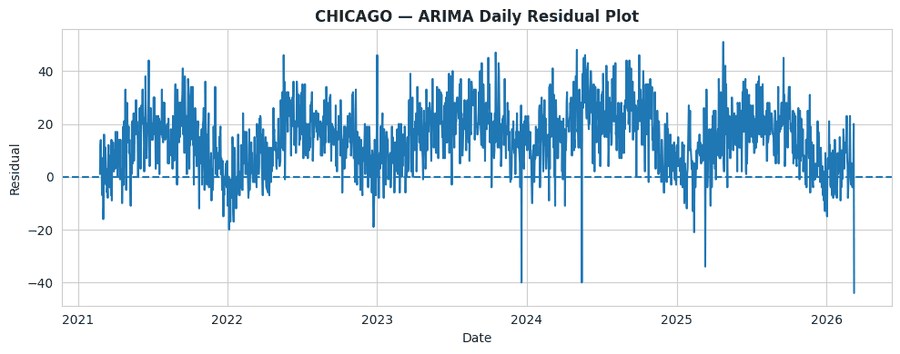

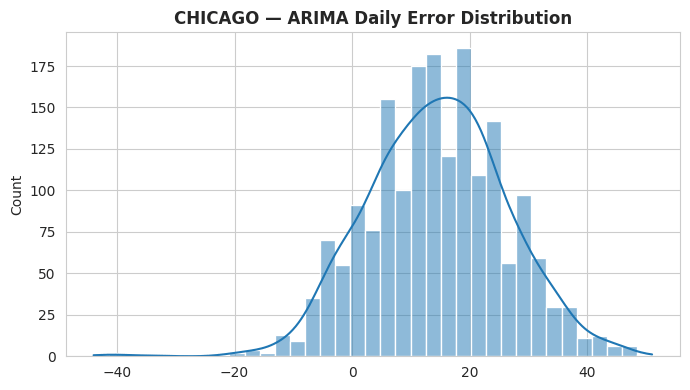


Running category forecasting for los_angeles: BATTERY - SIMPLE ASSAULT
Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.7124 - val_loss: 0.6973 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6563 - val_loss: 0.6873 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6380 - val_loss: 0.6670 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6169 - val_loss: 0.6258 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6017 - val_loss: 0.6247 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5846 - val_loss: 0.6392 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5779 - val_loss: 0.6202 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5757 - val_loss: 0.6252 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.569

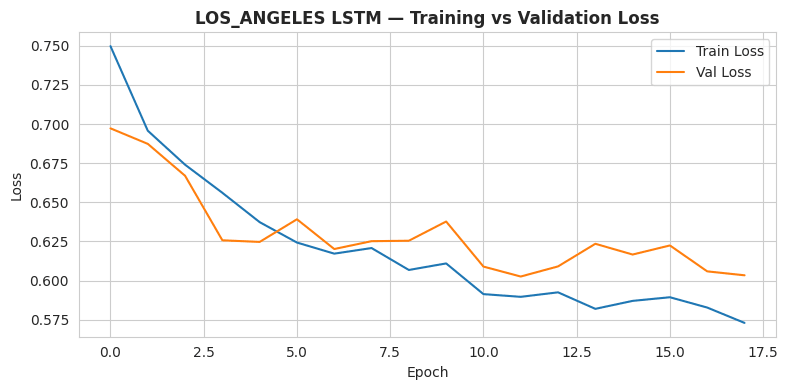

LOS_ANGELES LSTM
Stopped at epoch 18
Final train loss: 0.573010
Final val loss: 0.603403
Ratio (val/train): 1.05
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


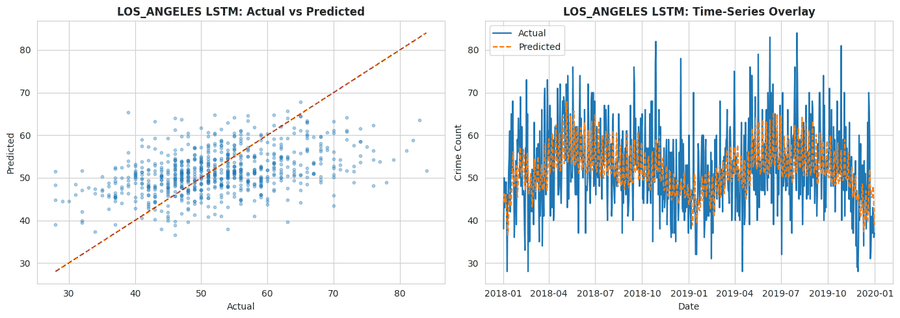

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.7629 - val_loss: 0.6477 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6436 - val_loss: 0.6706 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6242 - val_loss: 0.6729 - learning_rate: 0.0010
Epoch 4/30
71/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6039
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6076 - val_loss: 0.6515 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6023 - val_loss: 0.6145 - learning_rate: 5.0000e-04
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.5857 - val_loss: 0.6142 - learning_rate: 5.0000e-04
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5806 - val_loss: 0.6031 - learning_rate: 5.0000e-04
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5742 - val_loss: 0.6041 - learning_rate: 5

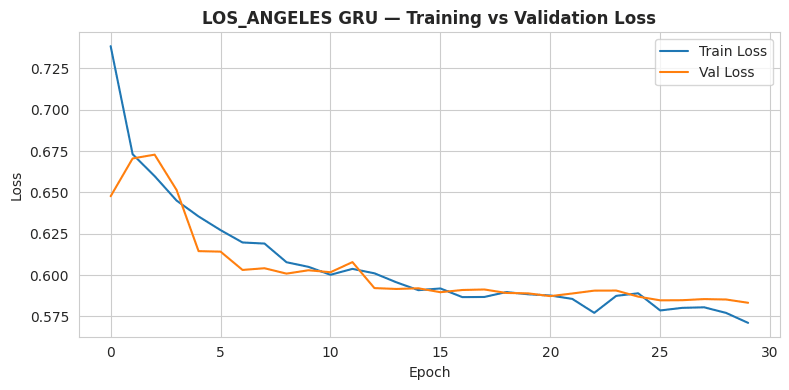

LOS_ANGELES GRU
Stopped at epoch 30
Final train loss: 0.571064
Final val loss: 0.583229
Ratio (val/train): 1.02
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


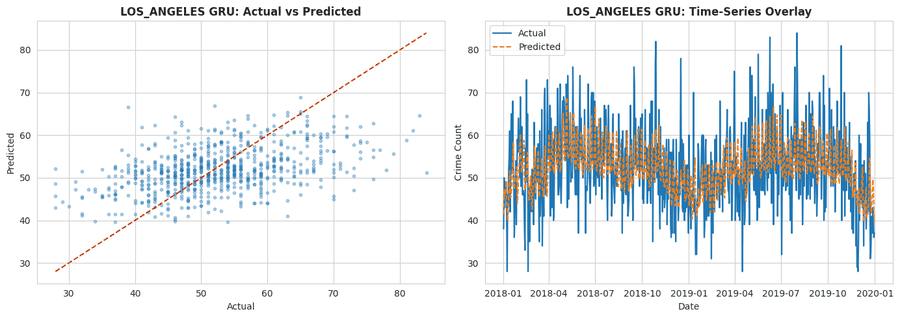

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.6933 - val_loss: 0.7056 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6667 - val_loss: 0.6991 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6629 - val_loss: 0.7072 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6527 - val_loss: 0.7998 - learning_rate: 0.0010
Epoch 5/30
67/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6668
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6750 - val_loss: 0.7023 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6561 - val_loss: 0.6919 - learning_rate: 5.0000e-04
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6482 - val_loss: 0.6874 - learning_rate: 5.0000e-04
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6532 - val_loss: 0.6803 - learning_rate: 5.00

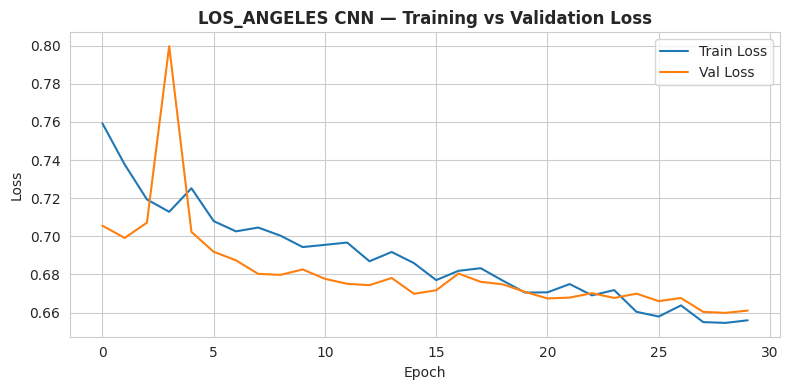

LOS_ANGELES CNN
Stopped at epoch 30
Final train loss: 0.655906
Final val loss: 0.661013
Ratio (val/train): 1.01
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


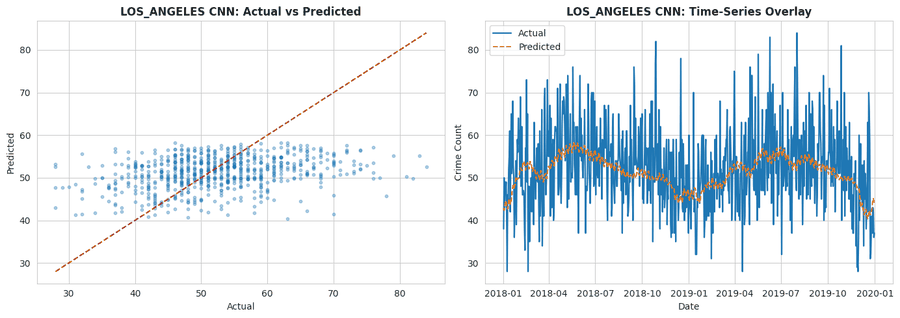

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 89ms/step - loss: 0.7657 - val_loss: 0.8229 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7222 - val_loss: 0.7652 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7008 - val_loss: 0.7151 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7002 - val_loss: 0.6908 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6839 - val_loss: 0.6837 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6871 - val_loss: 0.6774 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6724 - val_loss: 0.6786 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6673 - val_loss: 0.6832 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6751 - val_loss: 0.6728 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━

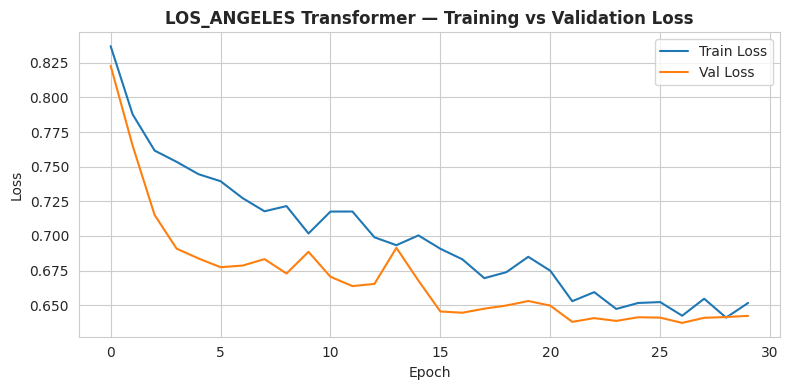

LOS_ANGELES Transformer
Stopped at epoch 30
Final train loss: 0.651563
Final val loss: 0.642236
Ratio (val/train): 0.99
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


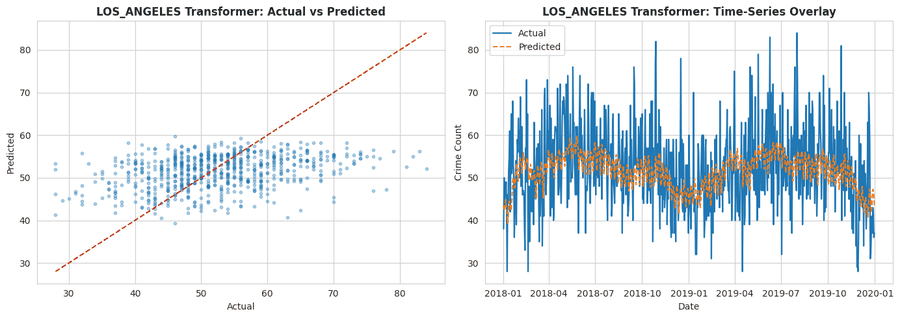

los_angeles ADF stat=-3.5275, p=0.0073
Selected DAILY ARIMA: (3, 1, 2)


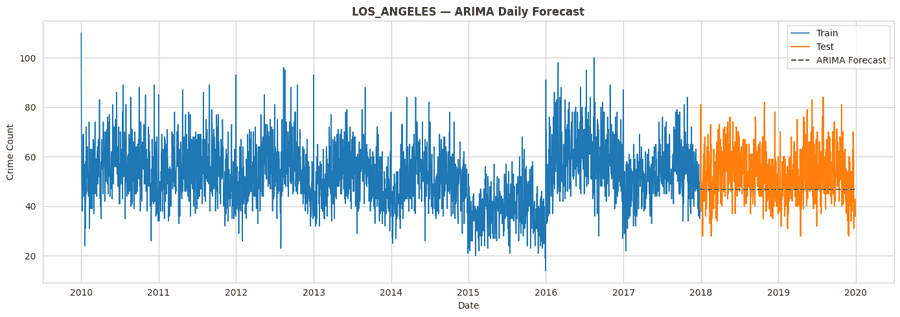

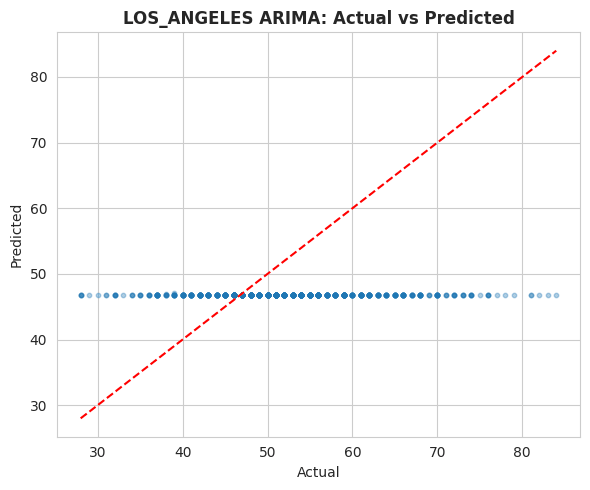

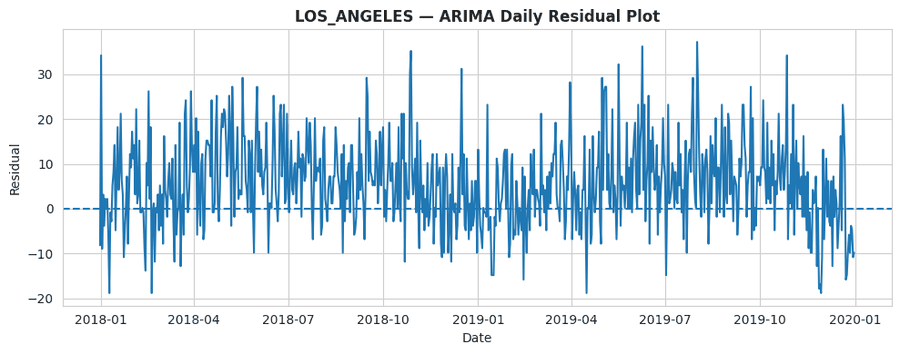

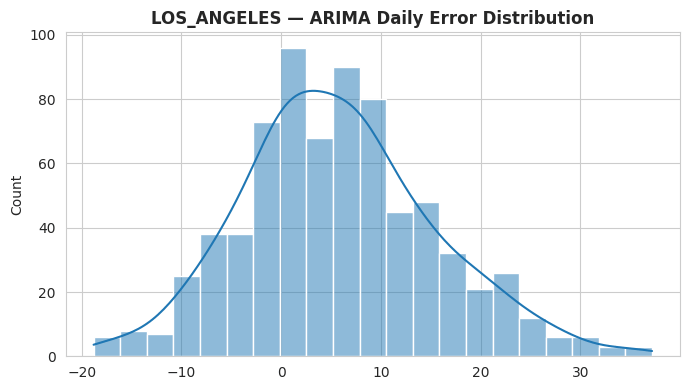


Running category forecasting for los_angeles: BURGLARY FROM VEHICLE
Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.6050 - val_loss: 0.5860 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5667 - val_loss: 0.5296 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5441 - val_loss: 0.5202 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5204 - val_loss: 0.5226 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5212 - val_loss: 0.5224 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5278 - val_loss: 0.5157 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5219 - val_loss: 0.5134 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5181 - val_loss: 0.5107 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5184 -

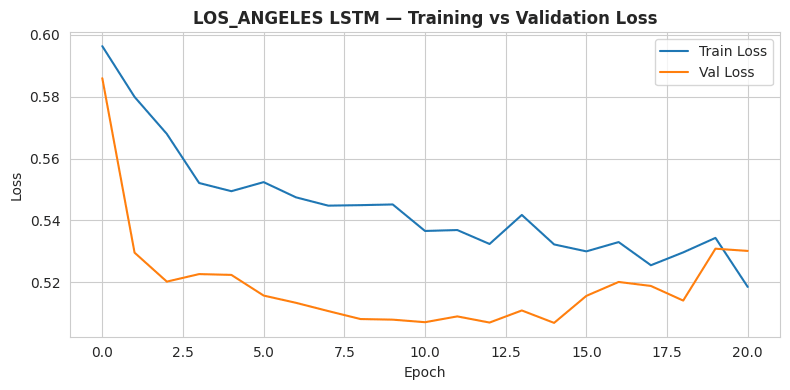

LOS_ANGELES LSTM
Stopped at epoch 21
Final train loss: 0.518499
Final val loss: 0.530139
Ratio (val/train): 1.02
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


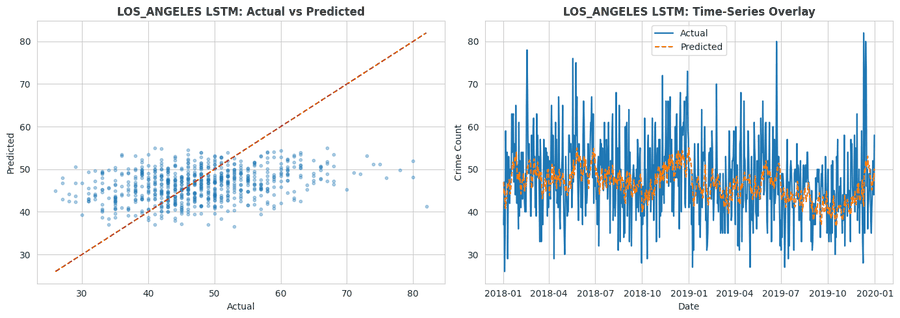

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.5798 - val_loss: 0.5706 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5474 - val_loss: 0.5497 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5387 - val_loss: 0.5519 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5448 - val_loss: 0.5416 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5423 - val_loss: 0.5373 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5488 - val_loss: 0.5271 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5310 - val_loss: 0.5254 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5277 - val_loss: 0.5174 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5249 - val_loss: 0.5129 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━━━

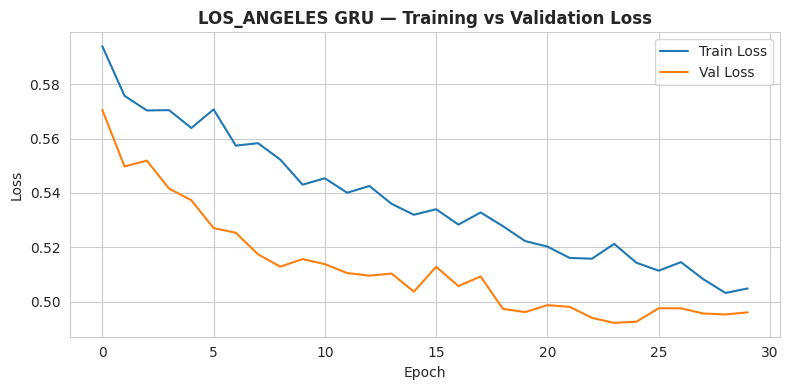

LOS_ANGELES GRU
Stopped at epoch 30
Final train loss: 0.504899
Final val loss: 0.496114
Ratio (val/train): 0.98
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


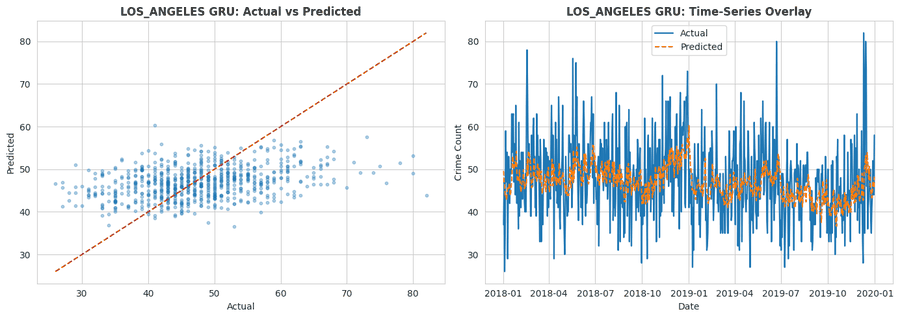

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.6261 - val_loss: 0.5484 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5808 - val_loss: 0.5602 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5658 - val_loss: 0.5585 - learning_rate: 0.0010
Epoch 4/30
68/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5570
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5630 - val_loss: 0.5645 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5532 - val_loss: 0.5592 - learning_rate: 5.0000e-04
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5464 - val_loss: 0.5541 - learning_rate: 5.0000e-04
Epoch 7/30
70/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5325
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5368 - val_loss: 0.5489

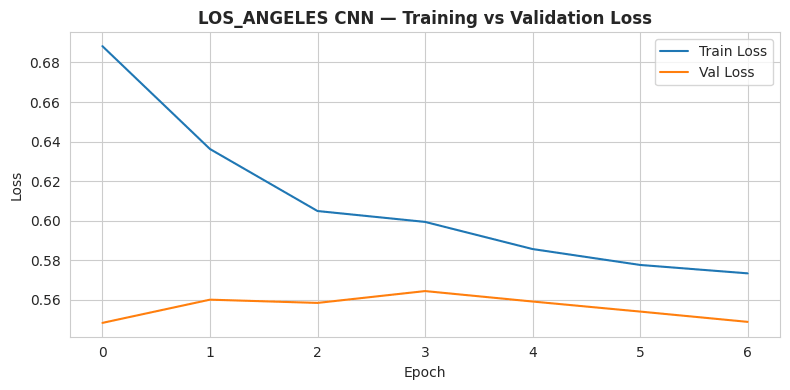

LOS_ANGELES CNN
Stopped at epoch 7
Final train loss: 0.573457
Final val loss: 0.548946
Ratio (val/train): 0.96
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


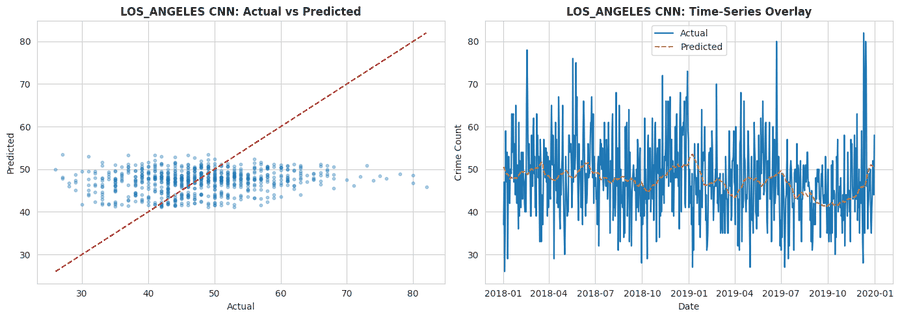

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - loss: 0.6277 - val_loss: 0.6180 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6165 - val_loss: 0.5515 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6034 - val_loss: 0.5688 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5732 - val_loss: 0.5587 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5645 - val_loss: 0.5513 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5572 - val_loss: 0.5551 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5637 - val_loss: 0.5562 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5552 - val_loss: 0.5459 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5583 - val_loss: 0.5401 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━

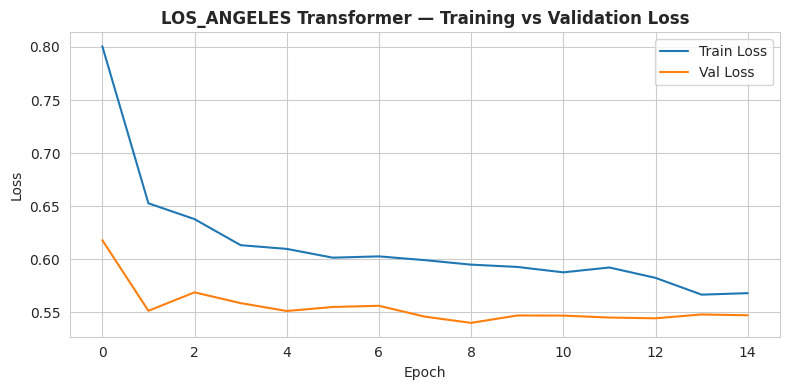

LOS_ANGELES Transformer
Stopped at epoch 15
Final train loss: 0.568080
Final val loss: 0.547255
Ratio (val/train): 0.96
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


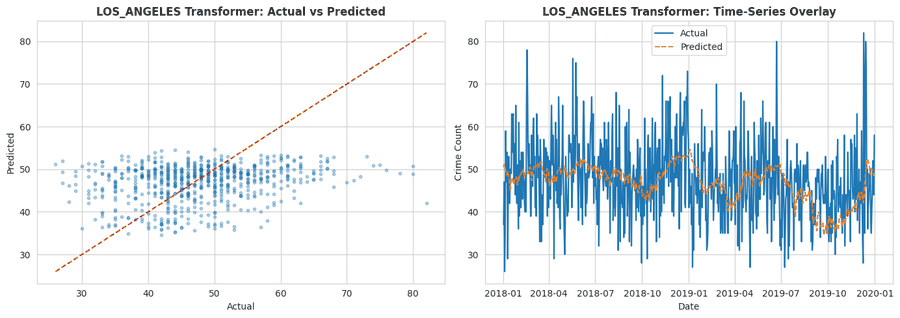

los_angeles ADF stat=-3.3974, p=0.0110
Selected DAILY ARIMA: (3, 1, 2)


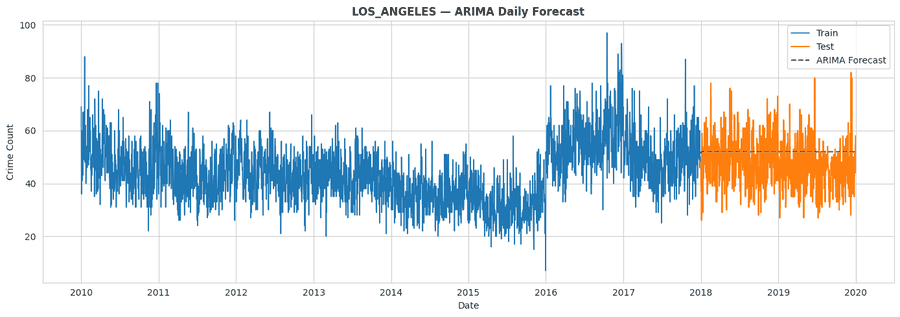

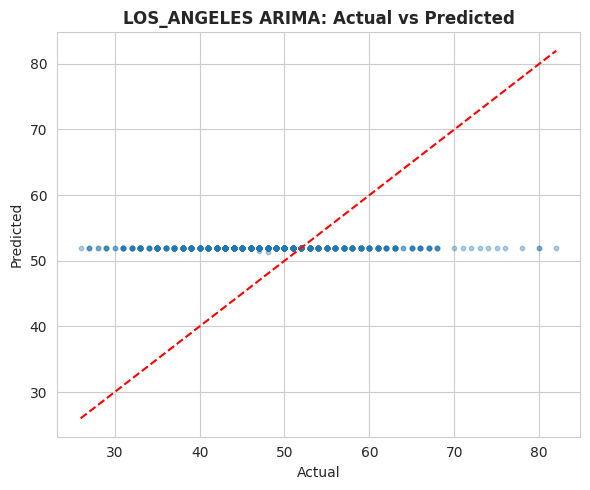

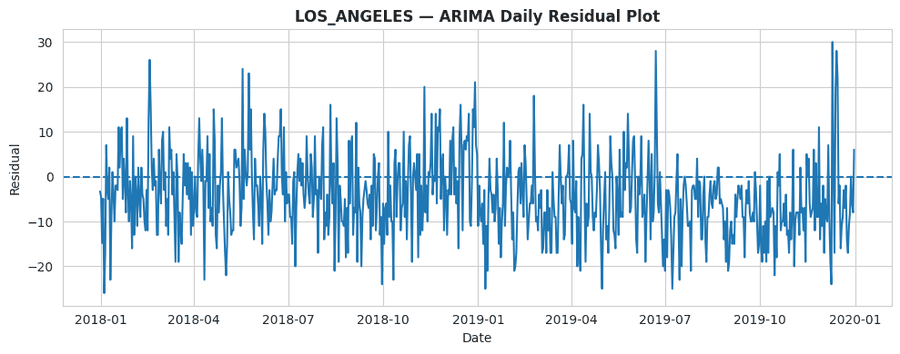

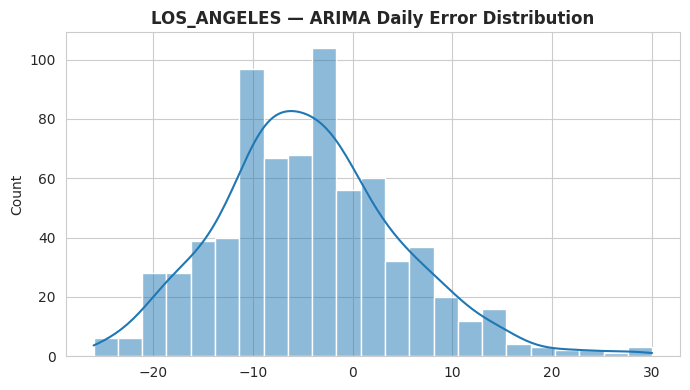


Running category forecasting for los_angeles: VEHICLE - STOLEN
Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.5421 - val_loss: 0.4440 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5019 - val_loss: 0.4224 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4931 - val_loss: 0.4107 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4851 - val_loss: 0.4079 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4778 - val_loss: 0.4888 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4984 - val_loss: 0.4224 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4836 - val_loss: 0.3987 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4831 - val_loss: 0.4098 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4782 - val_

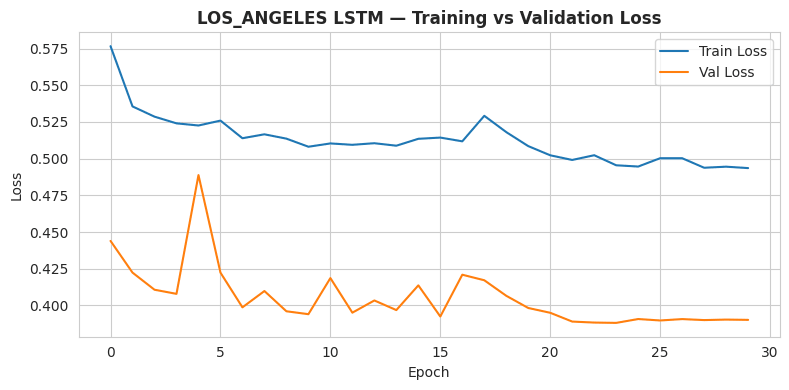

LOS_ANGELES LSTM
Stopped at epoch 30
Final train loss: 0.493575
Final val loss: 0.390181
Ratio (val/train): 0.79
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


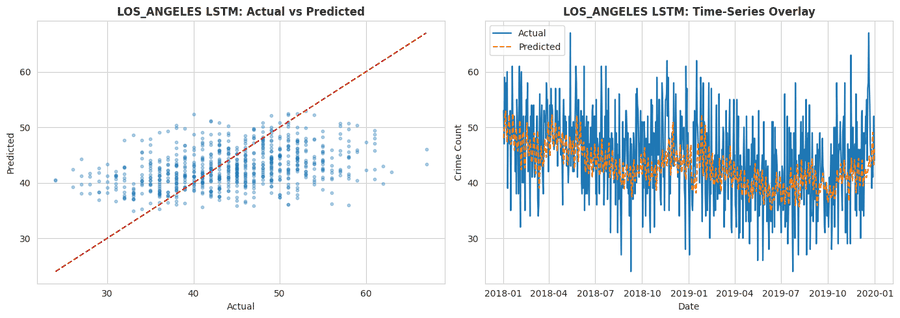

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.5159 - val_loss: 0.4542 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5046 - val_loss: 0.4687 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5112 - val_loss: 0.4359 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4925 - val_loss: 0.4293 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4832 - val_loss: 0.4135 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4856 - val_loss: 0.4159 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4807 - val_loss: 0.4124 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4747 - val_loss: 0.4110 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4733 - val_loss: 0.4094 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━━━

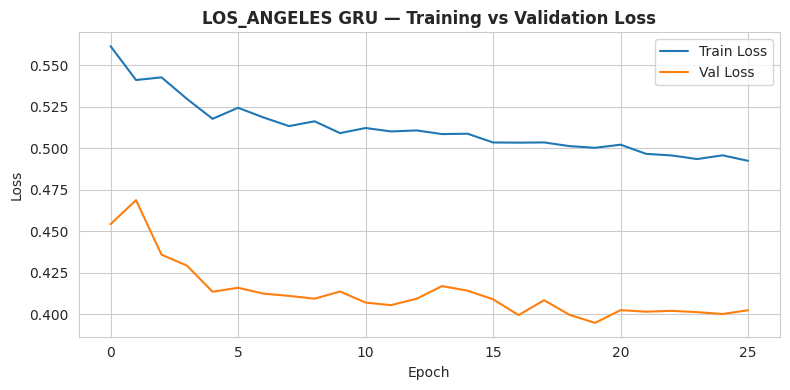

LOS_ANGELES GRU
Stopped at epoch 26
Final train loss: 0.492368
Final val loss: 0.402410
Ratio (val/train): 0.82
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


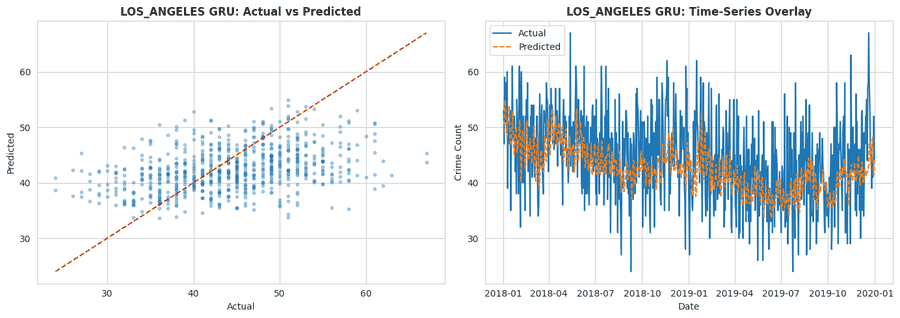

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.5298 - val_loss: 0.6890 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5489 - val_loss: 0.4648 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5140 - val_loss: 0.4425 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5172 - val_loss: 0.4396 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5119 - val_loss: 0.4432 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5166 - val_loss: 0.4446 - learning_rate: 0.0010
Epoch 7/30
71/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5059
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5108 - val_loss: 0.4398 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5121 - val_loss: 0.4357 - learning_rate: 5.0000e-04
E

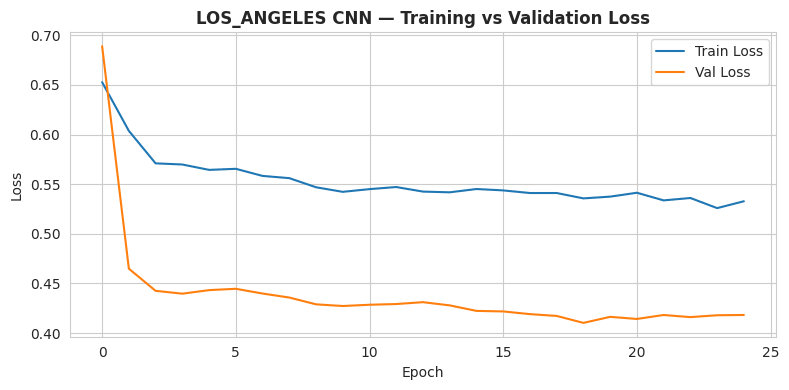

LOS_ANGELES CNN
Stopped at epoch 25
Final train loss: 0.532748
Final val loss: 0.418162
Ratio (val/train): 0.78
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


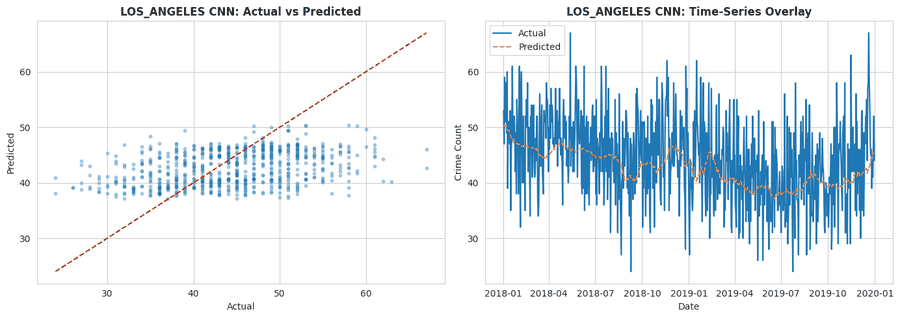

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 88ms/step - loss: 0.5645 - val_loss: 0.4159 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5603 - val_loss: 0.4062 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5438 - val_loss: 0.4090 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5341 - val_loss: 0.4044 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5189 - val_loss: 0.3961 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5166 - val_loss: 0.4010 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5078 - val_loss: 0.4001 - learning_rate: 0.0010
Epoch 8/30
75/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5231
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5246 - val_loss: 0.4148 - learning_rate: 0.0010
Epoc

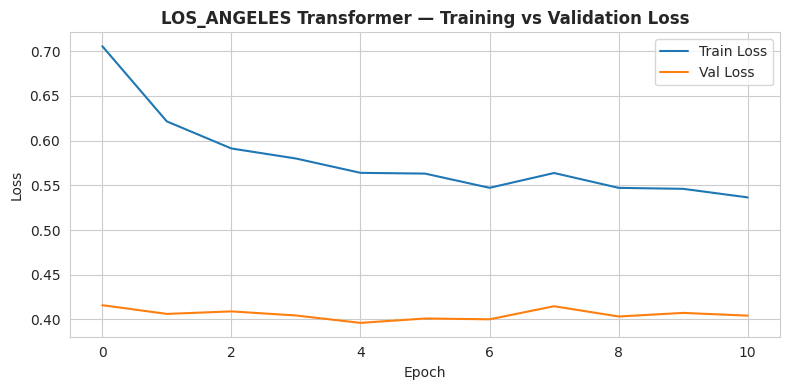

LOS_ANGELES Transformer
Stopped at epoch 11
Final train loss: 0.536536
Final val loss: 0.404246
Ratio (val/train): 0.75
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


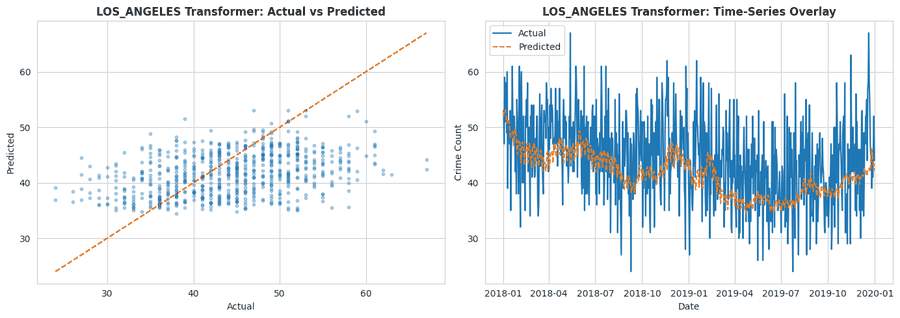

los_angeles ADF stat=-2.9043, p=0.0448
Selected DAILY ARIMA: (3, 1, 2)


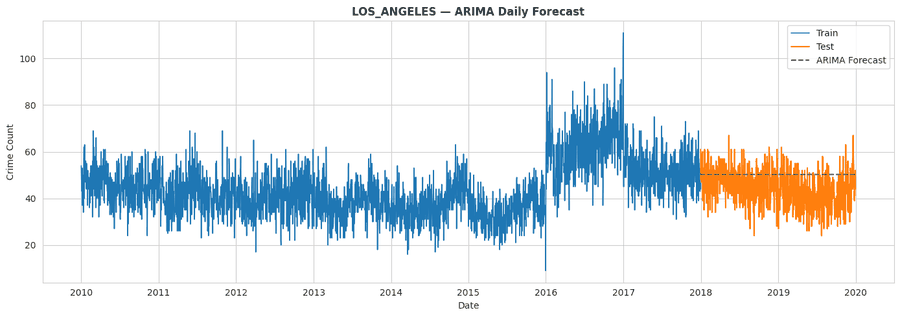

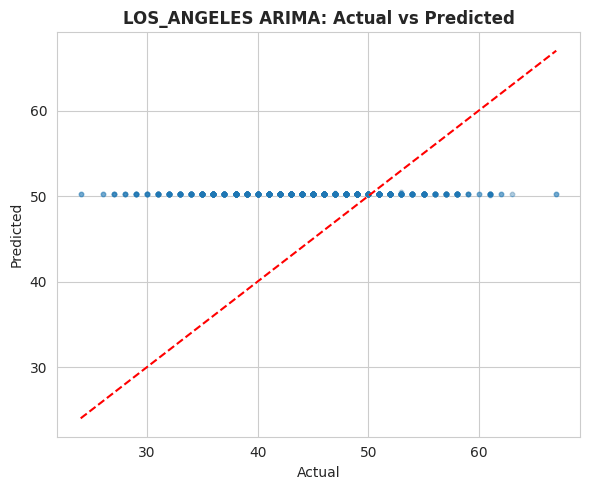

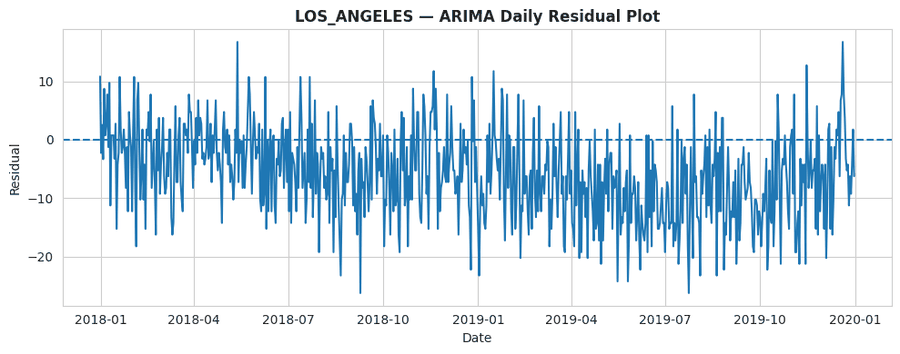

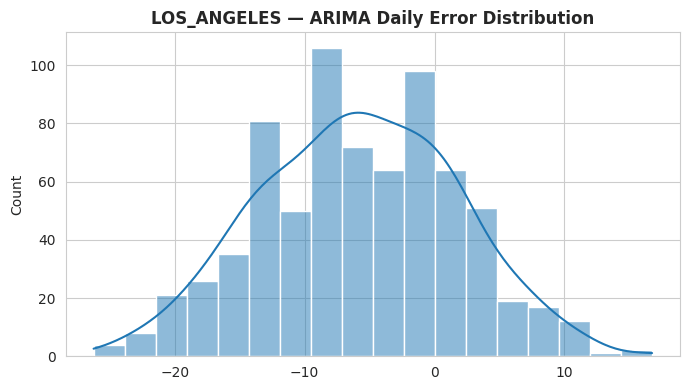


Running category forecasting for los_angeles: THEFT PLAIN - PETTY ($950 & UNDER)
Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1.3217 - val_loss: 0.7312 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7725 - val_loss: 0.7080 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6741 - val_loss: 0.6890 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6851 - val_loss: 0.6846 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6627 - val_loss: 0.6874 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6495 - val_loss: 0.6714 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6491 - val_loss: 0.6871 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6443 - val_loss: 0.6856 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - l

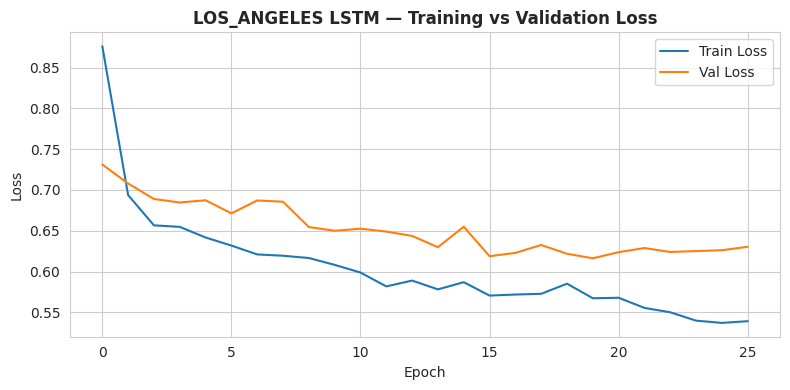

LOS_ANGELES LSTM
Stopped at epoch 26
Final train loss: 0.539148
Final val loss: 0.630362
Ratio (val/train): 1.17
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


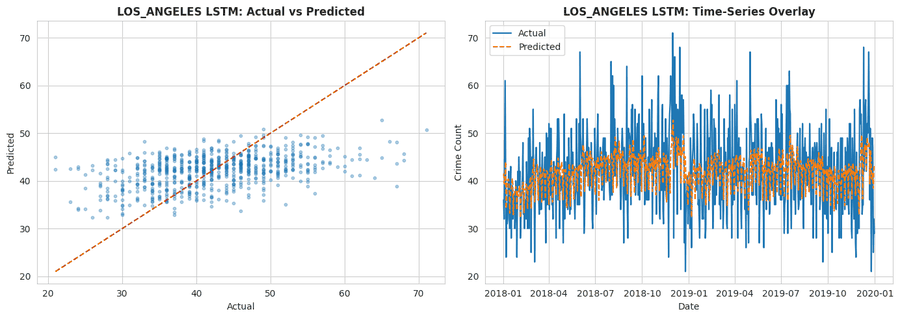

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 1.3523 - val_loss: 0.6731 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7013 - val_loss: 0.6663 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6720 - val_loss: 0.6583 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6662 - val_loss: 0.6429 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6549 - val_loss: 0.6281 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6253 - val_loss: 0.6271 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6211 - val_loss: 0.6243 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6290 - val_loss: 0.6312 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6205 - val_loss: 0.6192 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━━

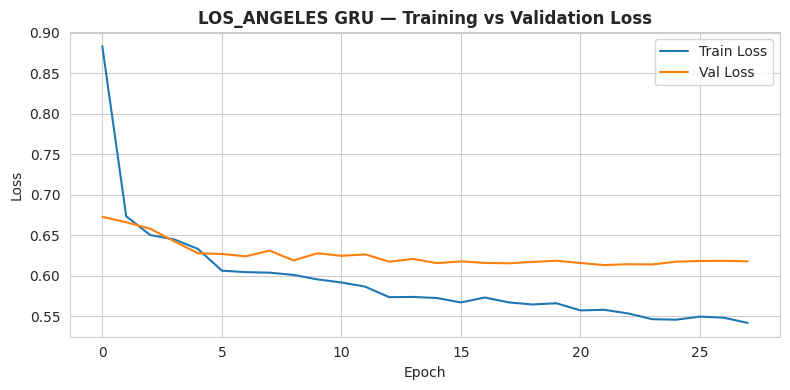

LOS_ANGELES GRU
Stopped at epoch 28
Final train loss: 0.542045
Final val loss: 0.618077
Ratio (val/train): 1.14
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


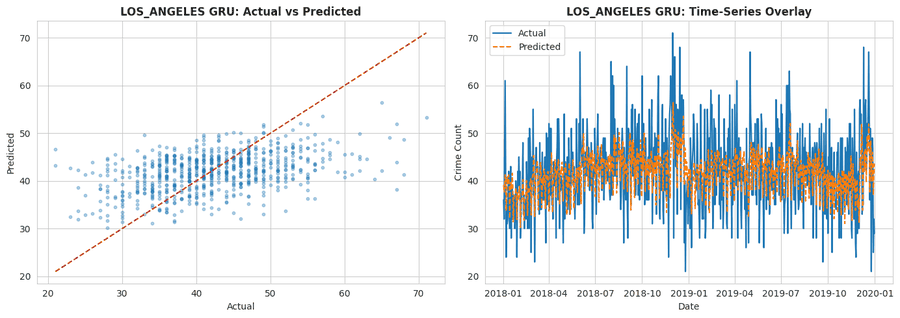

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 1.1296 - val_loss: 0.7618 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7849 - val_loss: 0.7598 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6948 - val_loss: 0.7669 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6871 - val_loss: 0.7648 - learning_rate: 0.0010
Epoch 5/30
69/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6871
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6866 - val_loss: 0.7753 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6732 - val_loss: 0.7589 - learning_rate: 5.0000e-04
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6822 - val_loss: 0.7592 - learning_rate: 5.0000e-04
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6829 - val_loss: 0.7505 - learning_rate: 5.00

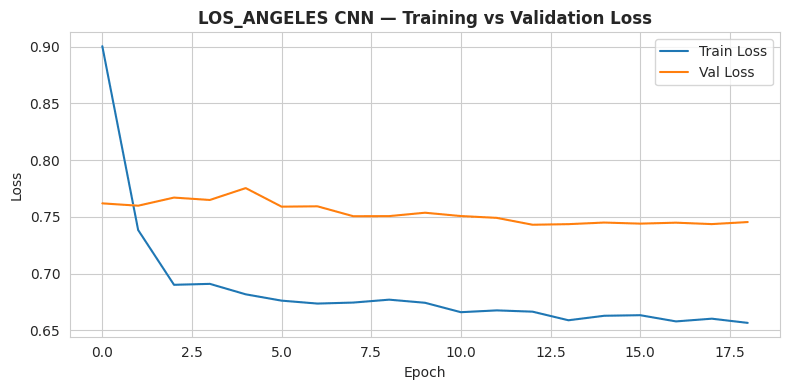

LOS_ANGELES CNN
Stopped at epoch 19
Final train loss: 0.656476
Final val loss: 0.745343
Ratio (val/train): 1.14
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


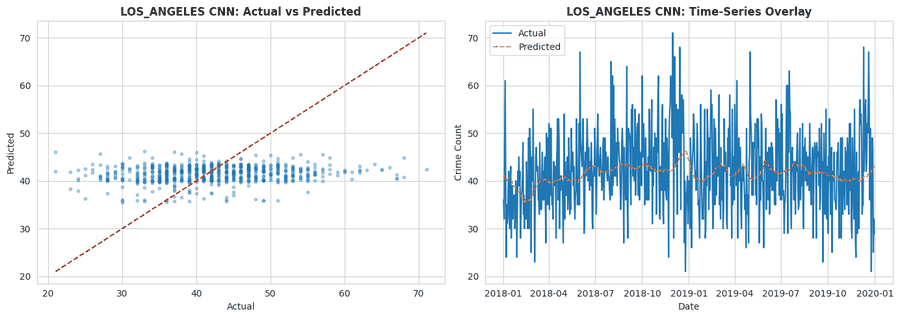

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 89ms/step - loss: 1.4522 - val_loss: 0.7013 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8504 - val_loss: 0.7216 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8058 - val_loss: 0.7669 - learning_rate: 0.0010
Epoch 4/30
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7664
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7651 - val_loss: 0.7796 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7581 - val_loss: 0.7390 - learning_rate: 5.0000e-04
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7199 - val_loss: 0.7409 - learning_rate: 5.0000e-04
Epoch 7/30
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7067
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7061 - val_loss: 0.742

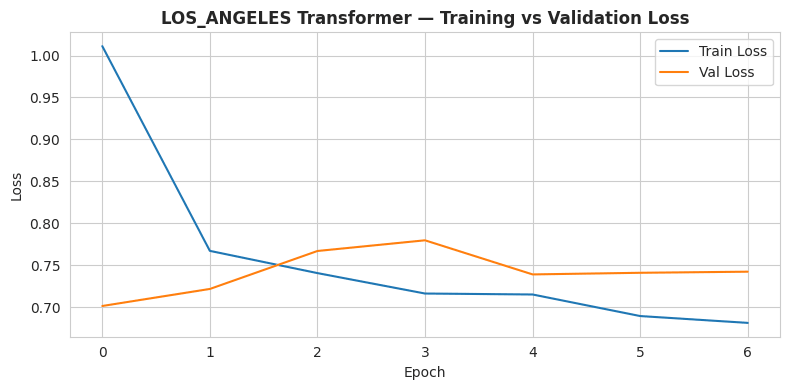

LOS_ANGELES Transformer
Stopped at epoch 7
Final train loss: 0.681157
Final val loss: 0.742208
Ratio (val/train): 1.09
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


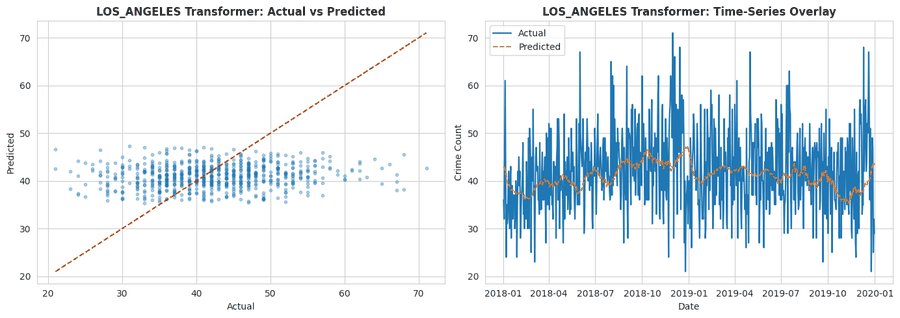

los_angeles ADF stat=-3.5109, p=0.0077
Selected DAILY ARIMA: (3, 1, 2)


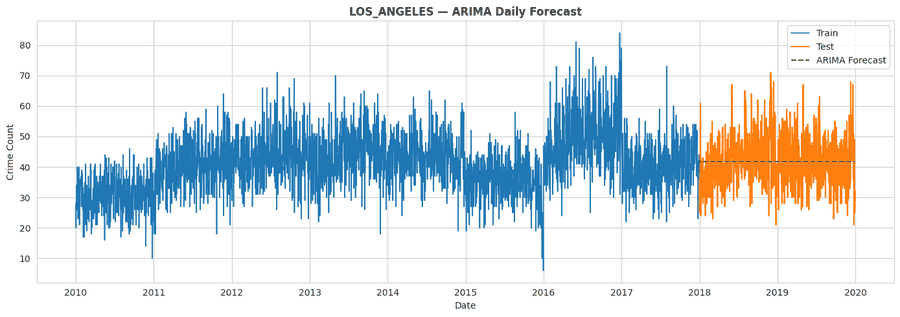

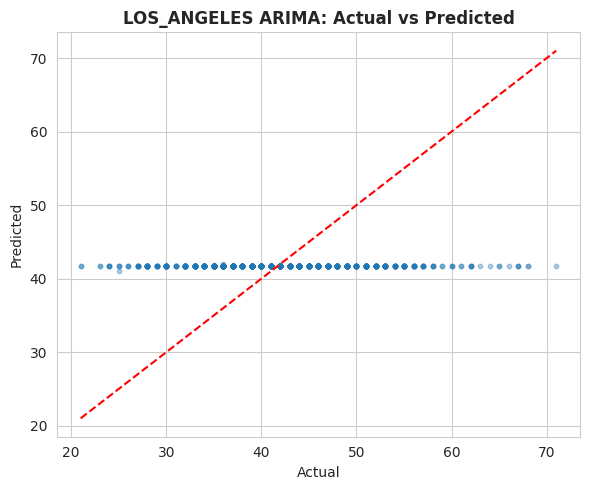

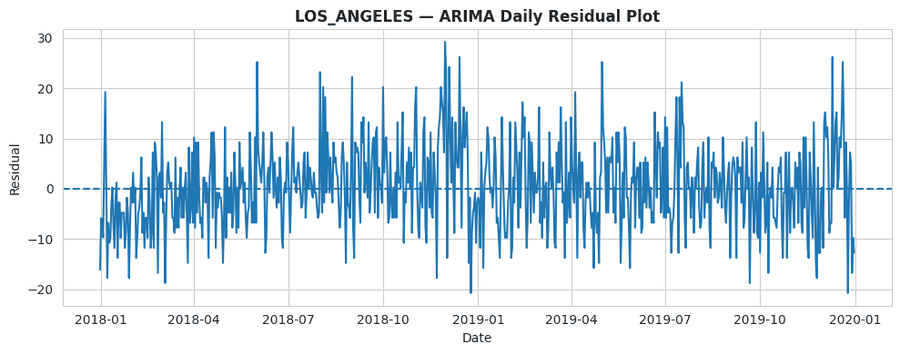

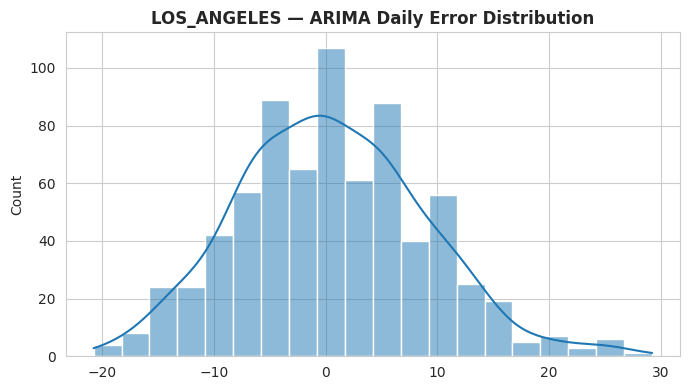


Running category forecasting for los_angeles: BURGLARY
Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.8619 - val_loss: 0.6938 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7820 - val_loss: 0.6169 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6608 - val_loss: 0.5715 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6017 - val_loss: 0.5553 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5517 - val_loss: 0.5418 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5360 - val_loss: 0.5488 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5198 - val_loss: 0.5381 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5108 - val_loss: 0.5465 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5017 - val_loss: 0.

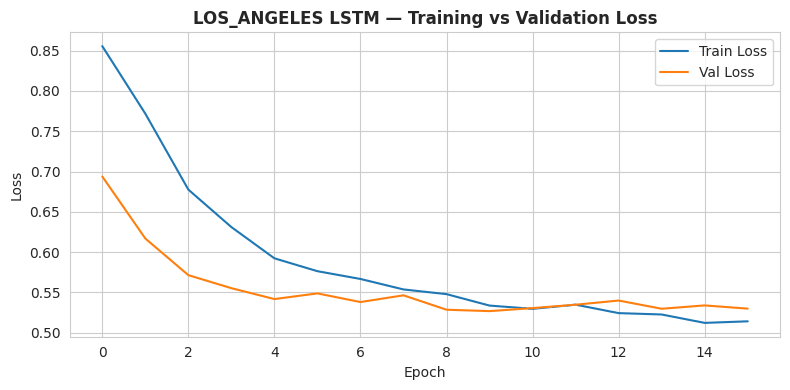

LOS_ANGELES LSTM
Stopped at epoch 16
Final train loss: 0.514202
Final val loss: 0.529935
Ratio (val/train): 1.03
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


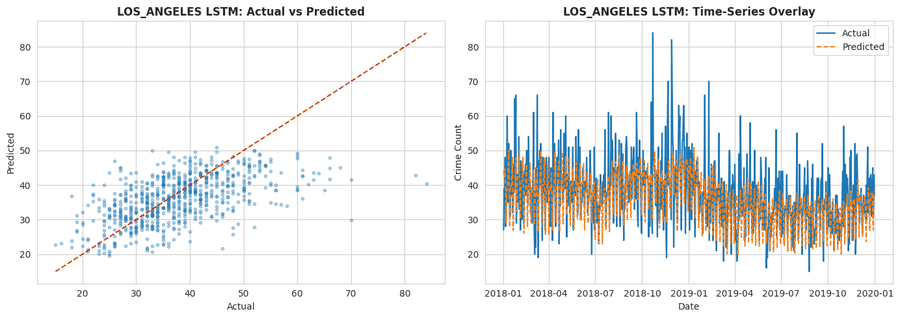

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.7975 - val_loss: 0.6744 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6673 - val_loss: 0.5860 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5926 - val_loss: 0.5625 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5517 - val_loss: 0.5423 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5331 - val_loss: 0.5424 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5236 - val_loss: 0.5399 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5134 - val_loss: 0.5233 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5000 - val_loss: 0.5356 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4981 - val_loss: 0.5447 - learning_rate: 0.0010
Epoch 10/30
70/77 ━━━━━━━━━━

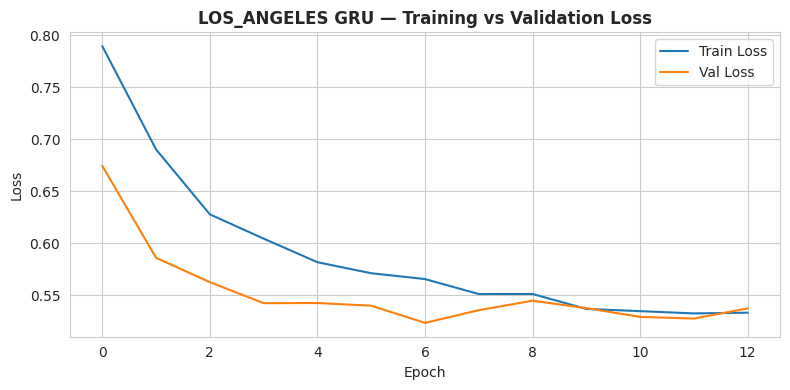

LOS_ANGELES GRU
Stopped at epoch 13
Final train loss: 0.533146
Final val loss: 0.537254
Ratio (val/train): 1.01
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


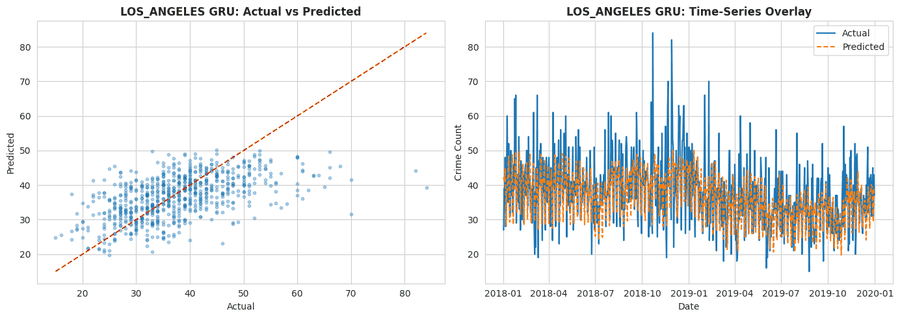

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.8741 - val_loss: 0.7386 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8864 - val_loss: 0.7165 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8628 - val_loss: 0.7398 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8632 - val_loss: 0.7320 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8659 - val_loss: 0.7153 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8502 - val_loss: 0.7007 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8408 - val_loss: 0.7158 - learning_rate: 0.0010
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8412 - val_loss: 0.6925 - learning_rate: 0.0010
Epoch 9/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8165 - val_loss: 0.6815 - learning_rate: 0.0010
Epoch 10/30
77/77 ━━━━━━━━━

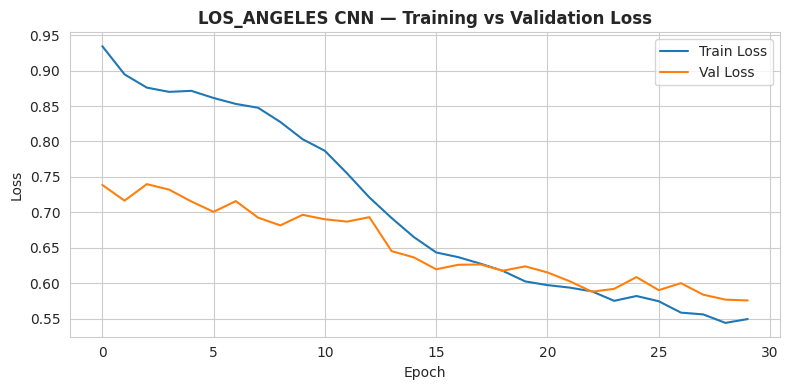

LOS_ANGELES CNN
Stopped at epoch 30
Final train loss: 0.549414
Final val loss: 0.575656
Ratio (val/train): 1.05
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


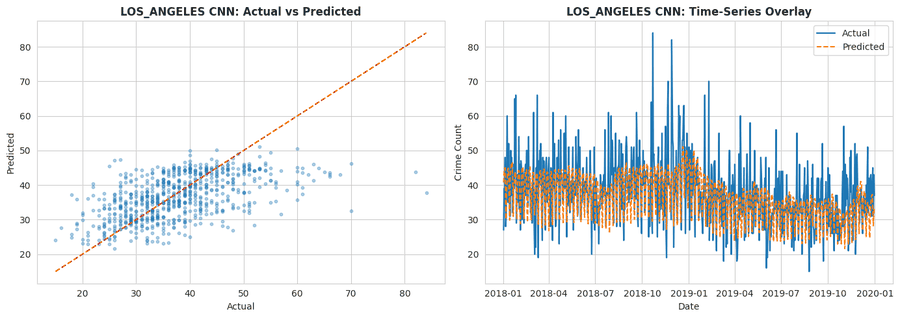

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - loss: 0.9157 - val_loss: 0.7193 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8759 - val_loss: 0.6770 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8286 - val_loss: 0.6790 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8384 - val_loss: 0.6985 - learning_rate: 0.0010
Epoch 5/30
73/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8200
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8216 - val_loss: 0.6914 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8156 - val_loss: 0.6796 - learning_rate: 5.0000e-04
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7888 - val_loss: 0.6711 - learning_rate: 5.0000e-04
Epoch 8/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7794 - val_loss: 0.6782 - learning_rate: 5.0

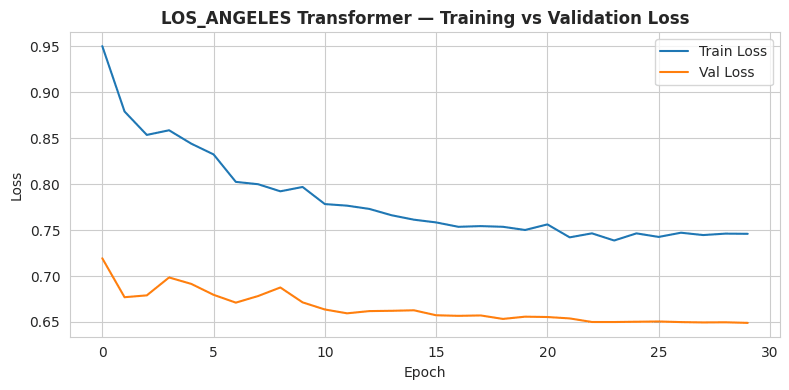

LOS_ANGELES Transformer
Stopped at epoch 30
Final train loss: 0.745955
Final val loss: 0.649023
Ratio (val/train): 0.87
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


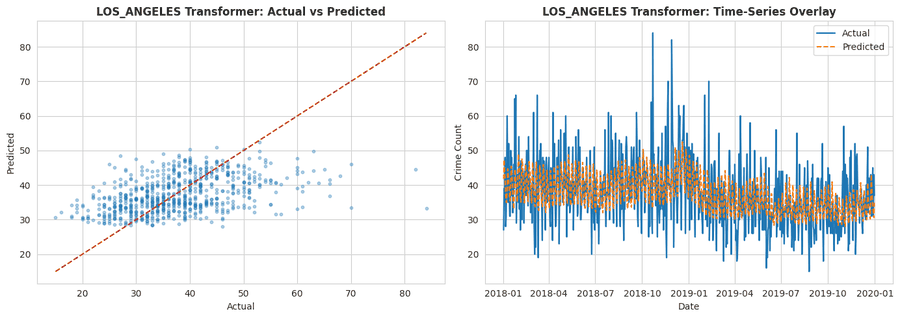

los_angeles ADF stat=-3.8282, p=0.0026
Selected DAILY ARIMA: (3, 1, 2)


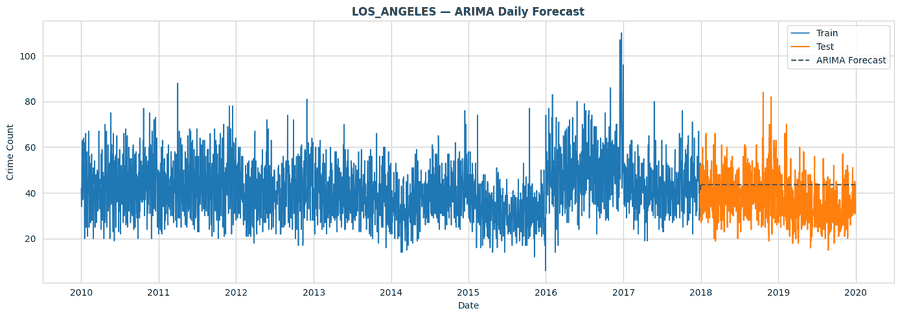

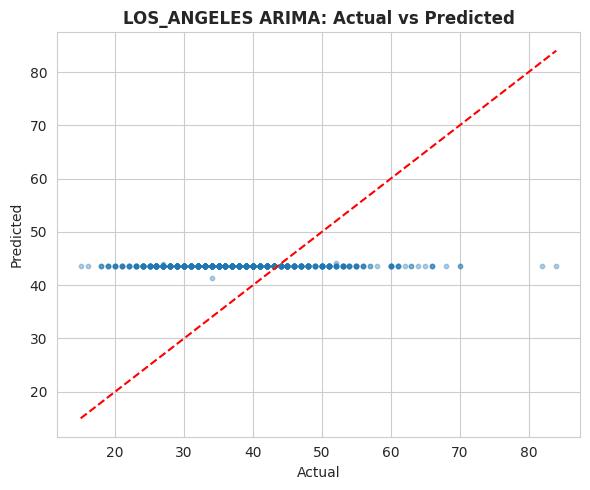

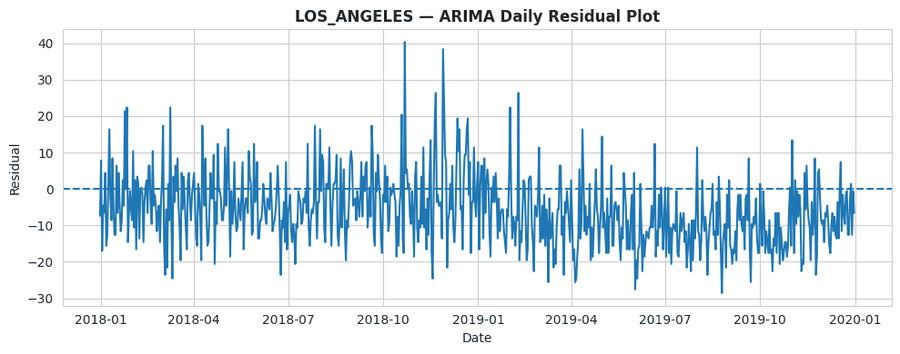

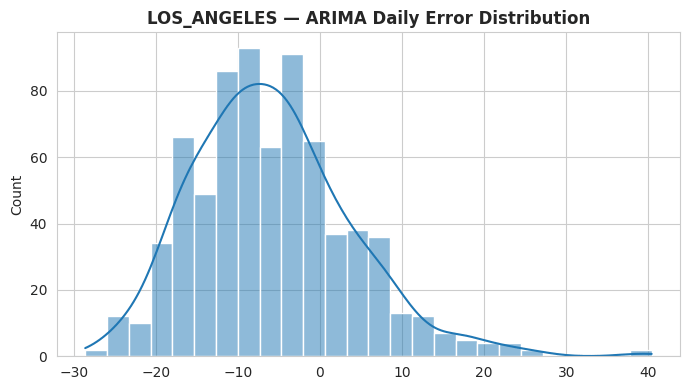


Running category forecasting for new_york: PETIT LARCENY
Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.4263 - val_loss: 0.0092 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1763 - val_loss: 0.0060 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1740 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1852 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1536 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1369 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1187 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1227 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 9/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

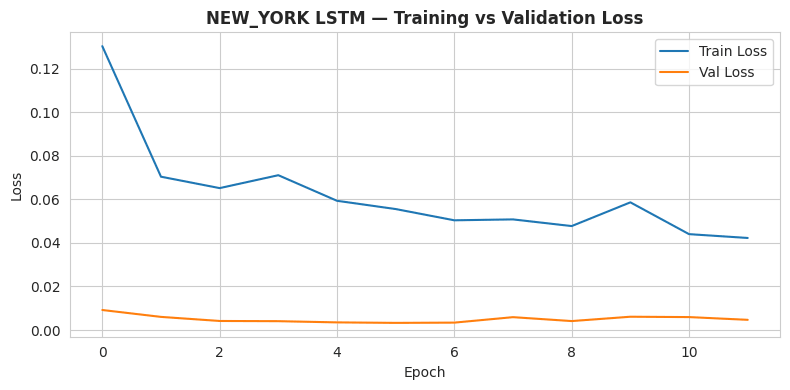

NEW_YORK LSTM
Stopped at epoch 12
Final train loss: 0.042241
Final val loss: 0.004669
Ratio (val/train): 0.11
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


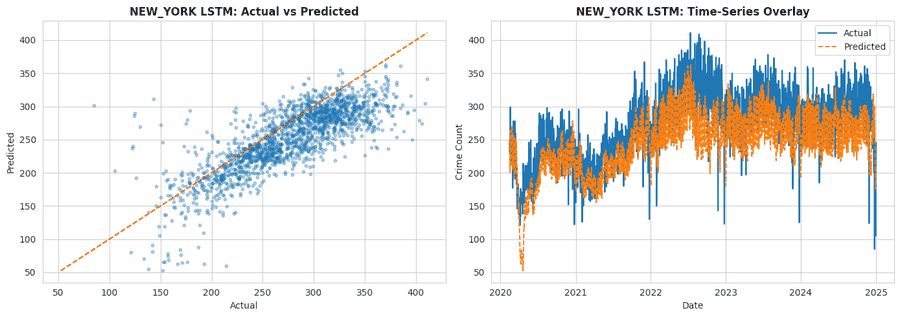

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1426 - val_loss: 0.0100 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1623 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2055 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2858 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1450 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1462 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1362 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1495 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 9/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1374 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 10/3

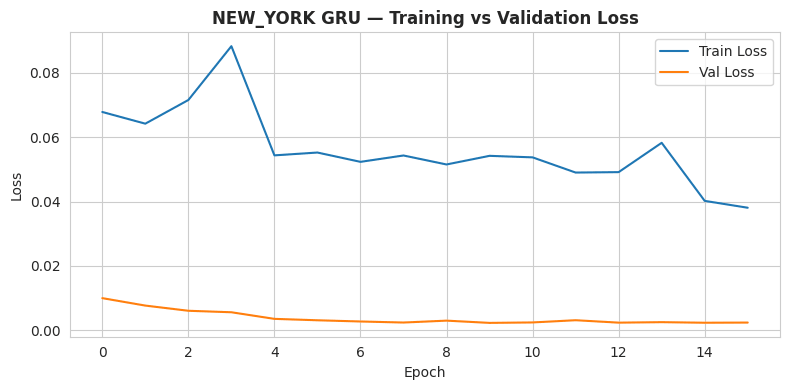

NEW_YORK GRU
Stopped at epoch 16
Final train loss: 0.038061
Final val loss: 0.002390
Ratio (val/train): 0.06
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


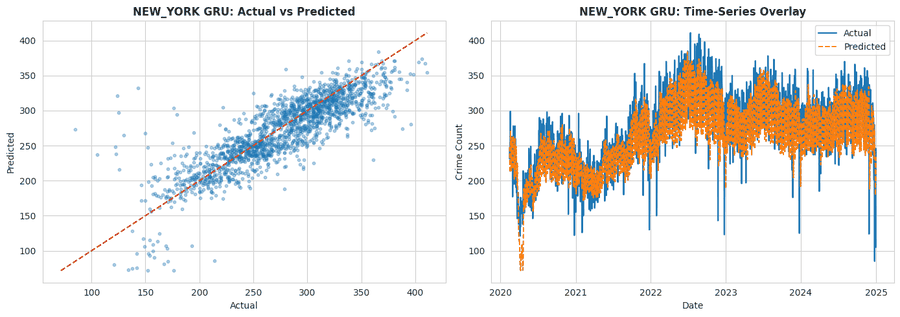

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.3905 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3784 - val_loss: 0.0083 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2643 - val_loss: 0.0063 - learning_rate: 0.0010
Epoch 4/30
179/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2498
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2402 - val_loss: 0.0064 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2631 - val_loss: 0.0077 - learning_rate: 5.0000e-04
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1443 - val_loss: 0.0076 - learning_rate: 5.0000e-04
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1534 - val_loss: 0.0058 - learning_rate: 5.0000e-04
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1431 - val_loss: 0.0067

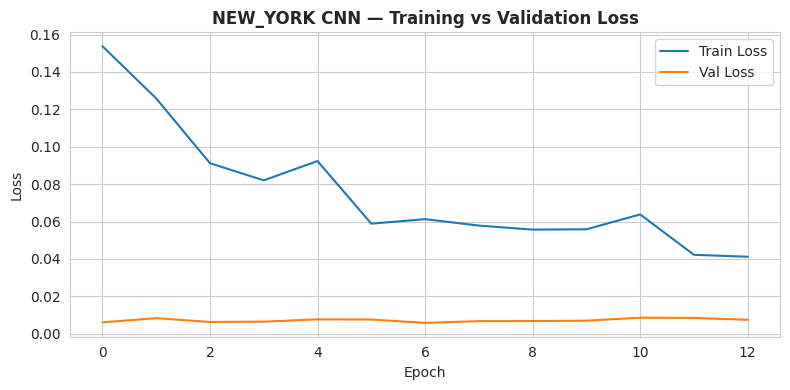

NEW_YORK CNN
Stopped at epoch 13
Final train loss: 0.041175
Final val loss: 0.007466
Ratio (val/train): 0.18
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


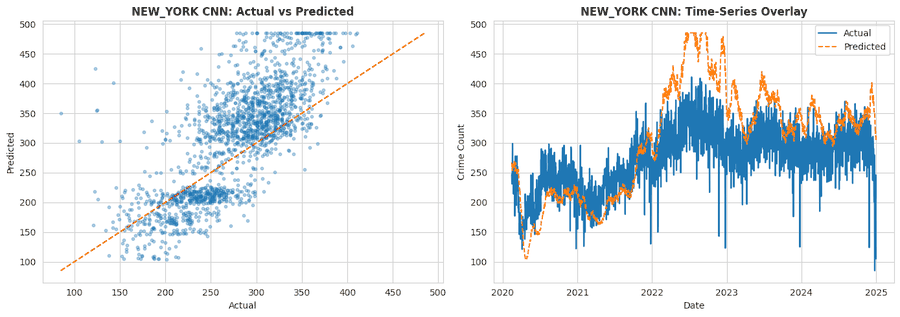

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - loss: 0.6927 - val_loss: 0.0133 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3066 - val_loss: 0.0191 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3445 - val_loss: 0.0190 - learning_rate: 0.0010
Epoch 4/30
186/189 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1983
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1959 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1998 - val_loss: 0.0208 - learning_rate: 5.0000e-04
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1201 - val_loss: 0.0227 - learning_rate: 5.0000e-04
Epoch 7/30
179/189 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1210
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1177

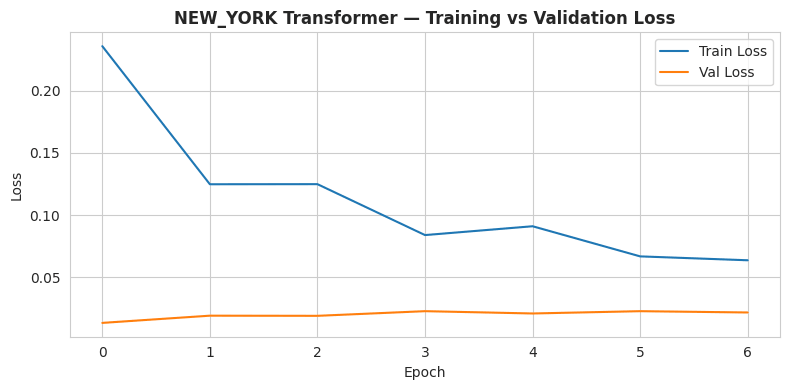

NEW_YORK Transformer
Stopped at epoch 7
Final train loss: 0.063639
Final val loss: 0.021643
Ratio (val/train): 0.34
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


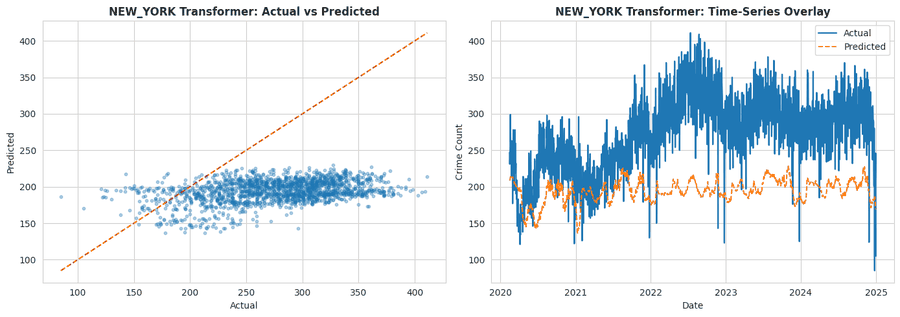

new_york ADF stat=-1.6258, p=0.4697
Selected DAILY ARIMA: (3, 1, 2)


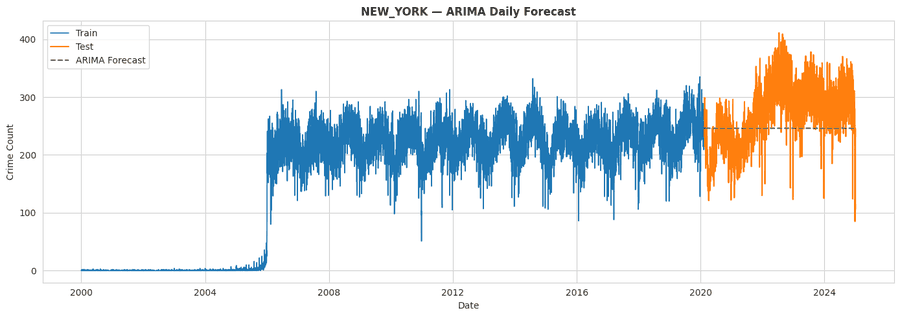

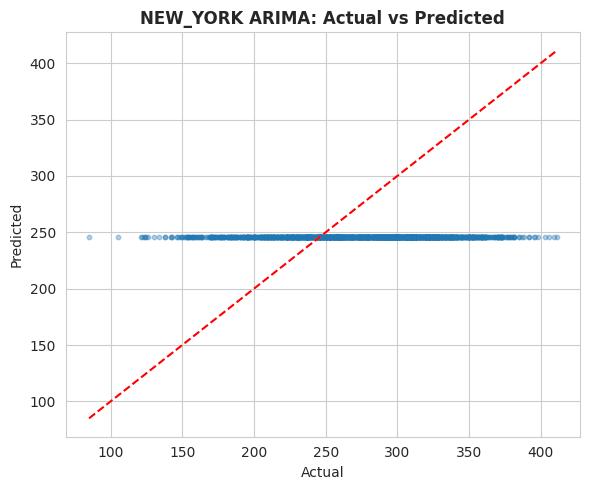

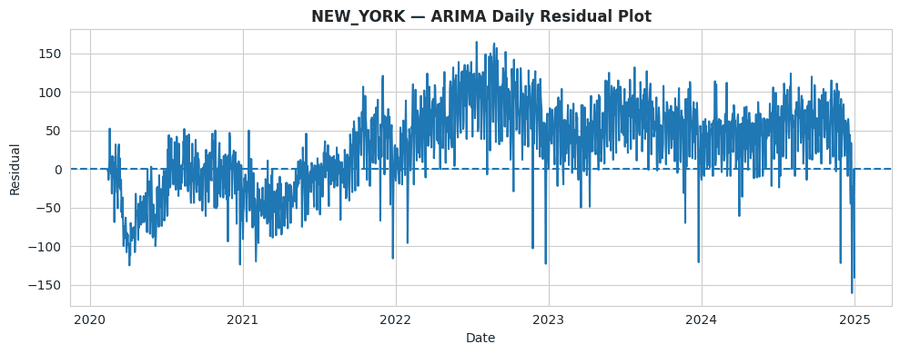

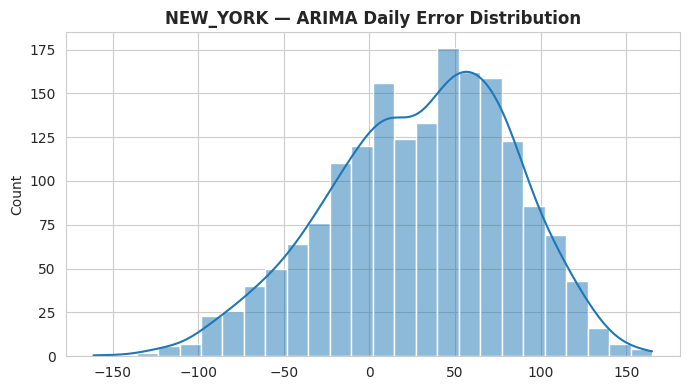


Running category forecasting for new_york: HARRASSMENT 2
Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.4284 - val_loss: 0.0051 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1022 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1214 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1073 - val_loss: 0.0042 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1101 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1111 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1135 - val_loss: 0.0065 - learning_rate: 0.0010
Epoch 8/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1002
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 

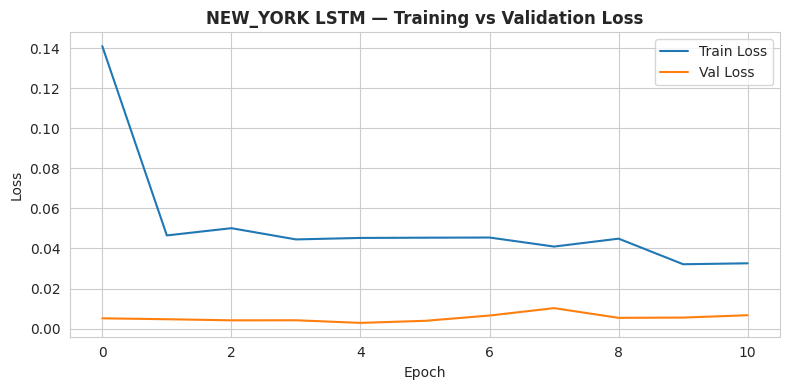

NEW_YORK LSTM
Stopped at epoch 11
Final train loss: 0.032604
Final val loss: 0.006692
Ratio (val/train): 0.21
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


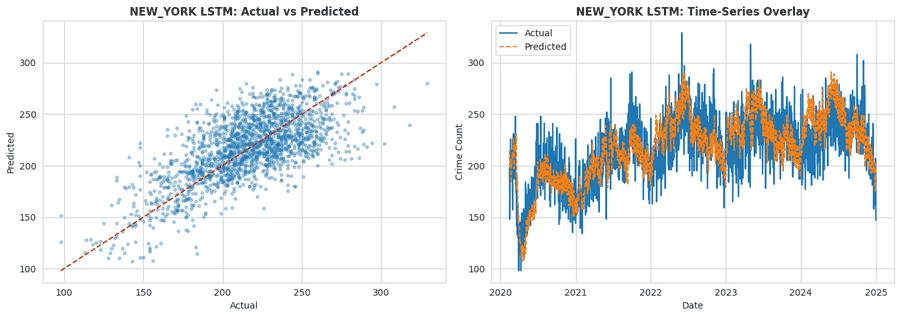

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.3335 - val_loss: 0.0062 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0938 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1194 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0921 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0879 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0922 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0895 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 8/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0957
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0929 - val_loss: 0.0029 - learning_r

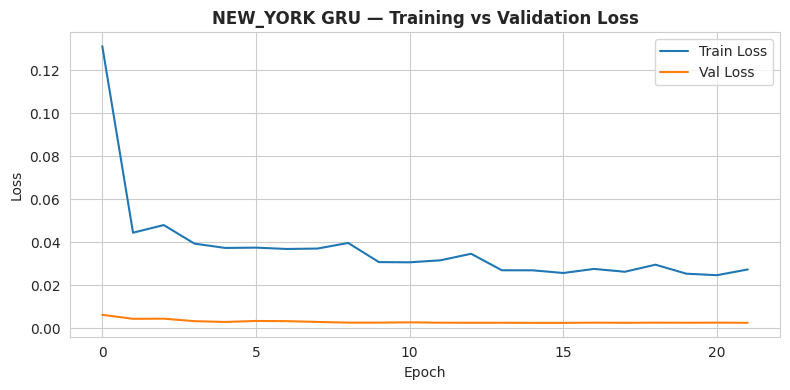

NEW_YORK GRU
Stopped at epoch 22
Final train loss: 0.027294
Final val loss: 0.002476
Ratio (val/train): 0.09
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


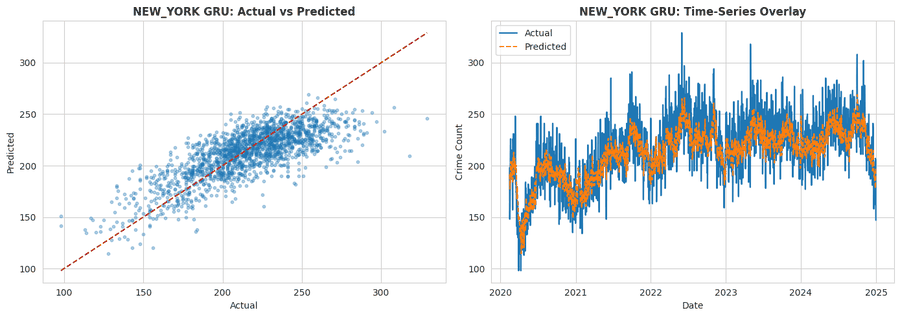

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.3663 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3593 - val_loss: 0.0072 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2109 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1428 - val_loss: 0.0143 - learning_rate: 0.0010
Epoch 5/30
168/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1545
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1434 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1591 - val_loss: 0.0098 - learning_rate: 5.0000e-04
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0970 - val_loss: 0.0115 - learning_rate: 5.0000e-04
Epoch 8/30
178/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0987
Epoch 8: ReduceLROnPla

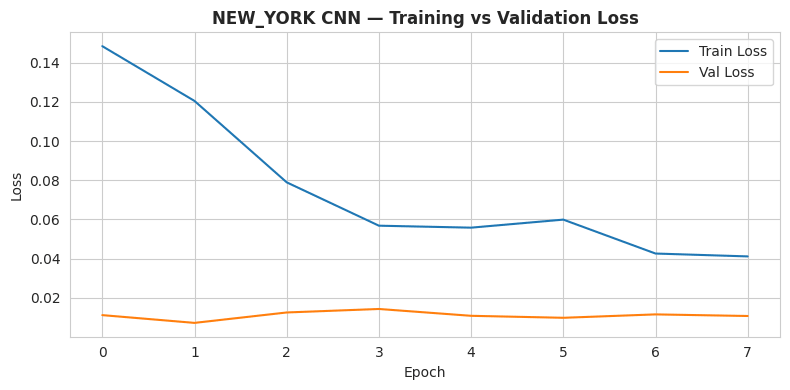

NEW_YORK CNN
Stopped at epoch 8
Final train loss: 0.041088
Final val loss: 0.010672
Ratio (val/train): 0.26
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


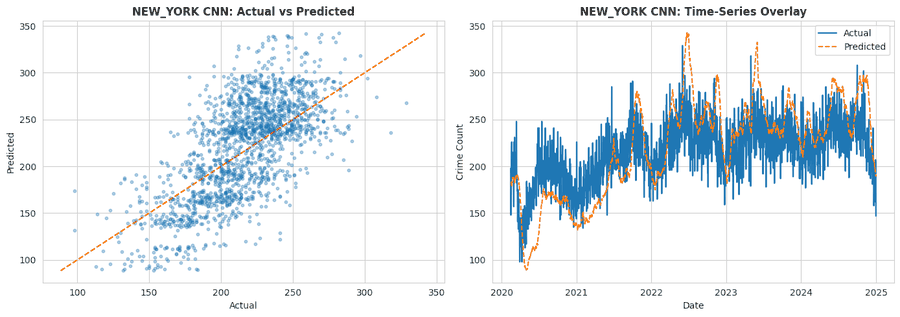

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - loss: 1.3225 - val_loss: 0.0072 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1347 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1556 - val_loss: 0.0167 - learning_rate: 0.0010
Epoch 4/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1213
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1182 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1397 - val_loss: 0.0162 - learning_rate: 5.0000e-04
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0800 - val_loss: 0.0170 - learning_rate: 5.0000e-04
Epoch 7/30
179/189 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0777
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0756

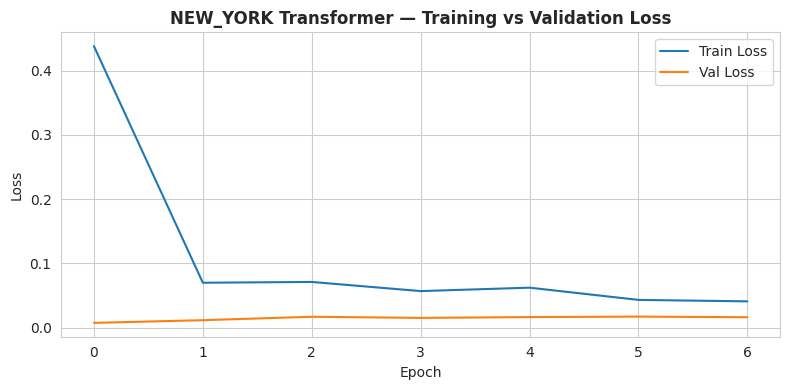

NEW_YORK Transformer
Stopped at epoch 7
Final train loss: 0.040711
Final val loss: 0.016014
Ratio (val/train): 0.39
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


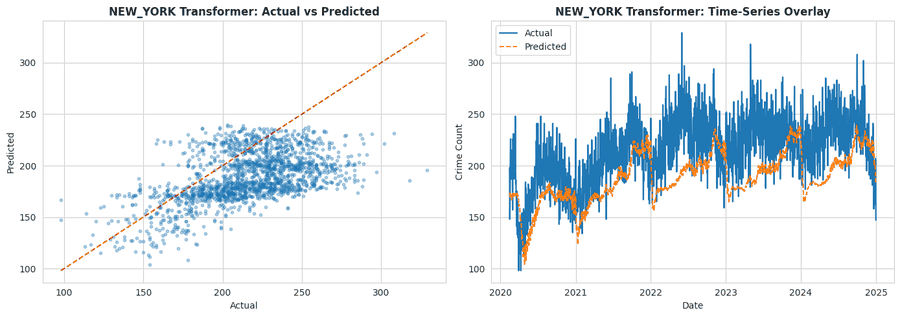

new_york ADF stat=-1.6705, p=0.4464
Selected DAILY ARIMA: (3, 1, 2)


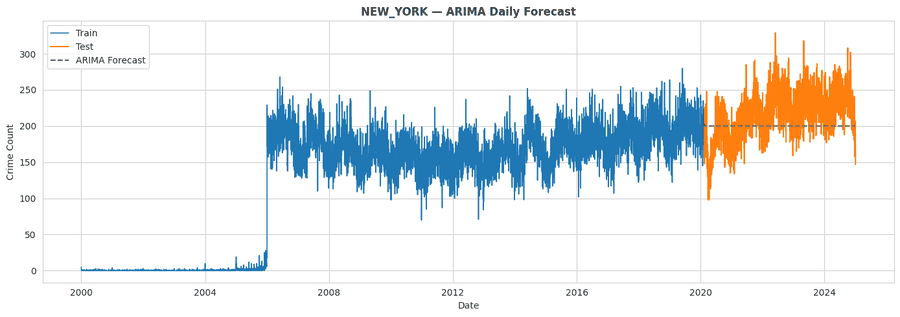

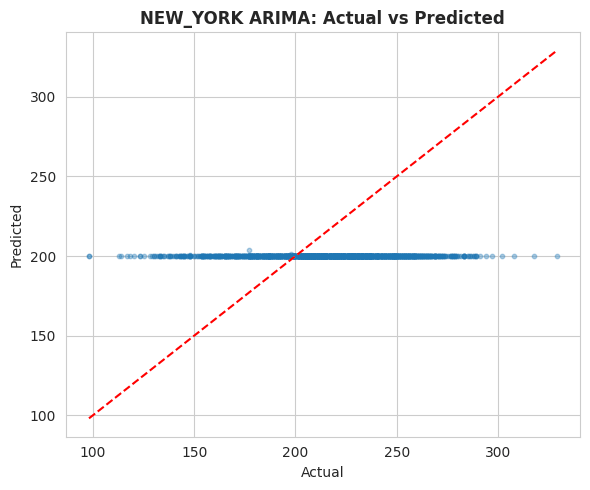

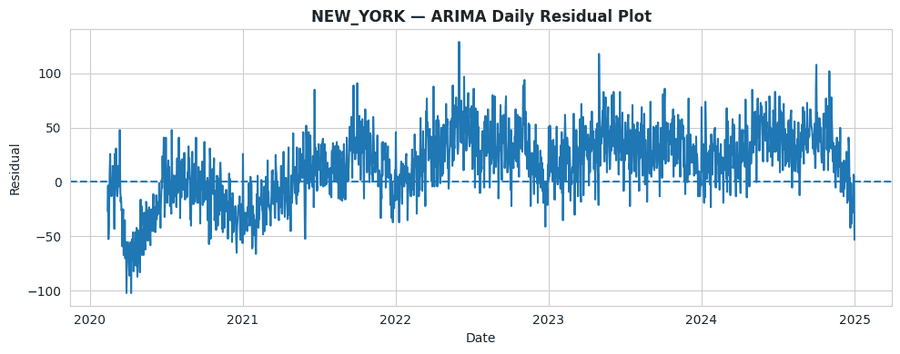

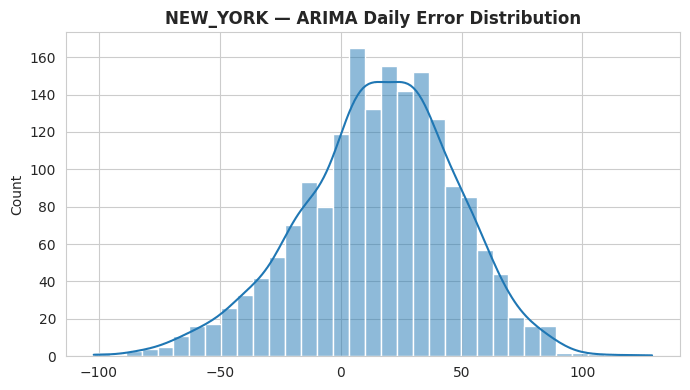


Running category forecasting for new_york: ASSAULT 3 & RELATED OFFENSES
Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.4701 - val_loss: 0.0071 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0668 - val_loss: 0.0068 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0683 - val_loss: 0.0066 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0655 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0603 - val_loss: 0.0070 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0658 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0557 - val_loss: 0.0103 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0469 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 9/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/

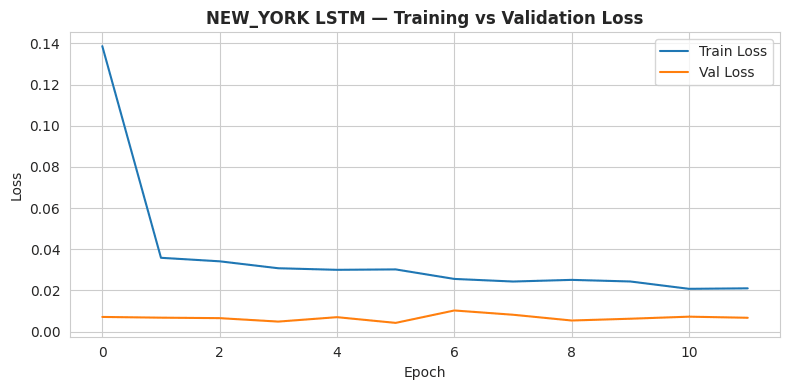

NEW_YORK LSTM
Stopped at epoch 12
Final train loss: 0.021039
Final val loss: 0.006740
Ratio (val/train): 0.32
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


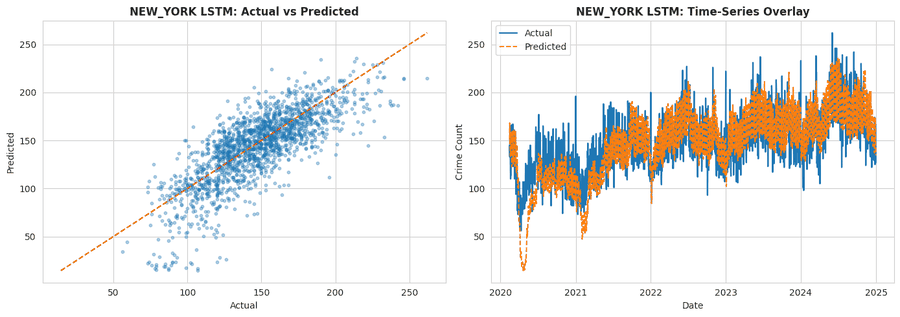

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.5429 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0804 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0720 - val_loss: 0.0065 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0793 - val_loss: 0.0066 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0639 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0624 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0697 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0571 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 9/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0533 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 10/3

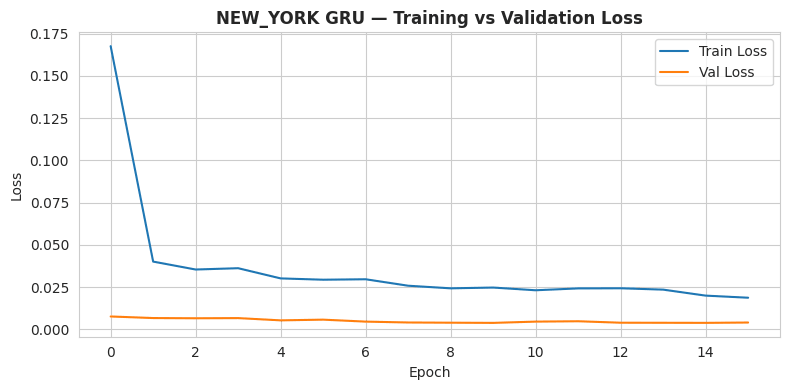

NEW_YORK GRU
Stopped at epoch 16
Final train loss: 0.018701
Final val loss: 0.004015
Ratio (val/train): 0.21
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


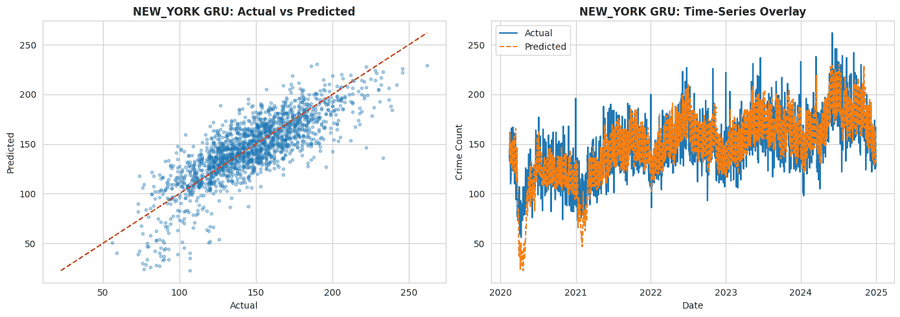

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2991 - val_loss: 0.0083 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3265 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1774 - val_loss: 0.0092 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1385 - val_loss: 0.0146 - learning_rate: 0.0010
Epoch 5/30
167/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1363
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1262 - val_loss: 0.0120 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1054 - val_loss: 0.0108 - learning_rate: 5.0000e-04
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0708 - val_loss: 0.0126 - learning_rate: 5.0000e-04
Epoch 8/30
170/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0686
Epoch 8: ReduceLROnPla

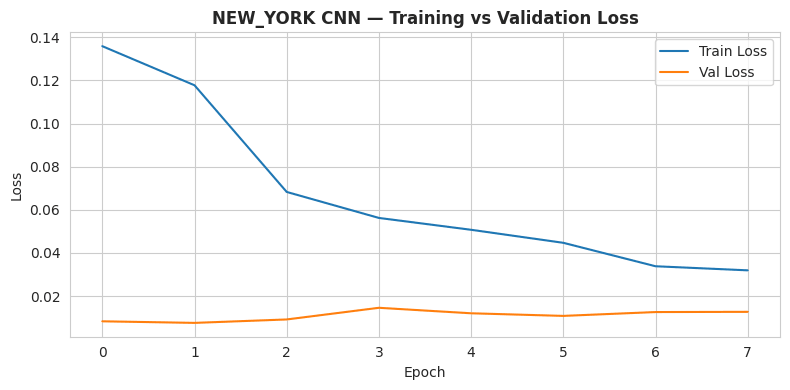

NEW_YORK CNN
Stopped at epoch 8
Final train loss: 0.031938
Final val loss: 0.012705
Ratio (val/train): 0.40
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


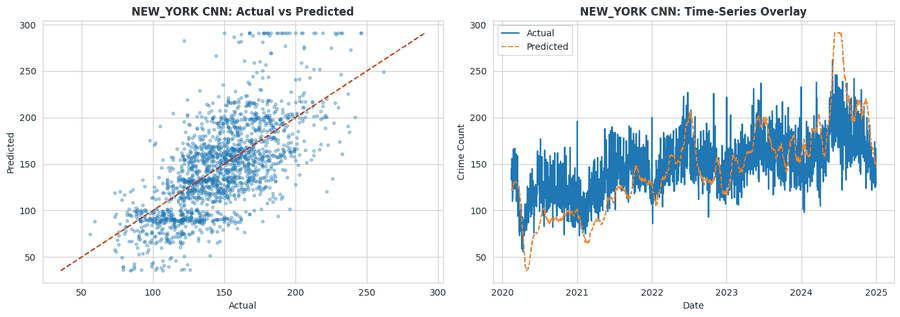

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - loss: 1.5659 - val_loss: 0.0167 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1490 - val_loss: 0.0192 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1524 - val_loss: 0.0212 - learning_rate: 0.0010
Epoch 4/30
180/189 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0972
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0948 - val_loss: 0.0210 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0981 - val_loss: 0.0203 - learning_rate: 5.0000e-04
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0572 - val_loss: 0.0231 - learning_rate: 5.0000e-04
Epoch 7/30
180/189 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0552
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0540

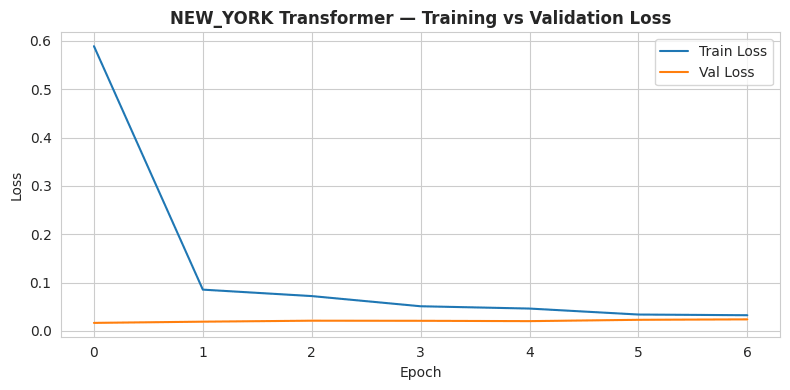

NEW_YORK Transformer
Stopped at epoch 7
Final train loss: 0.032557
Final val loss: 0.023993
Ratio (val/train): 0.74
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


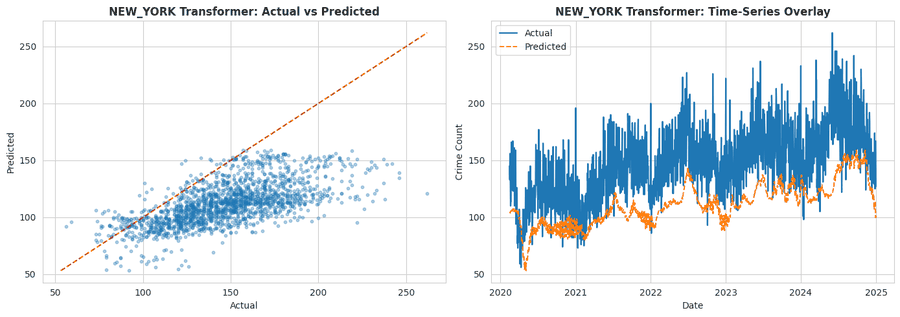

new_york ADF stat=-1.7083, p=0.4269
Selected DAILY ARIMA: (3, 1, 2)


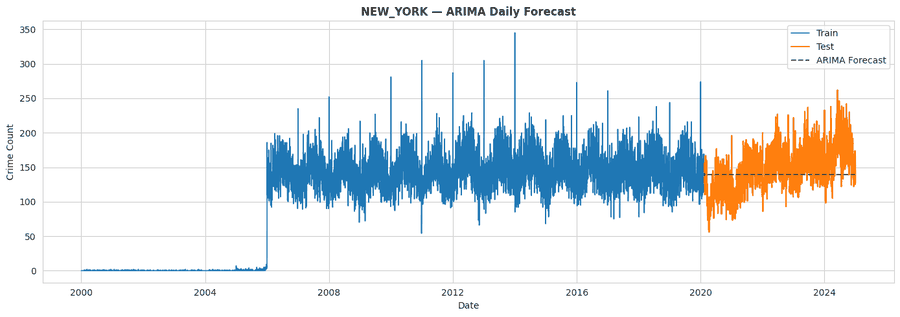

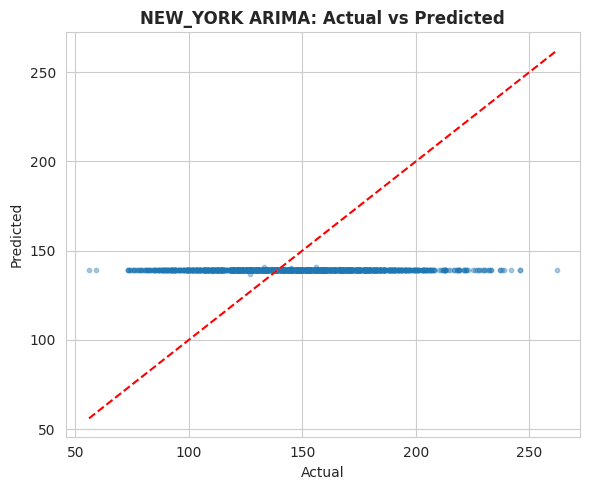

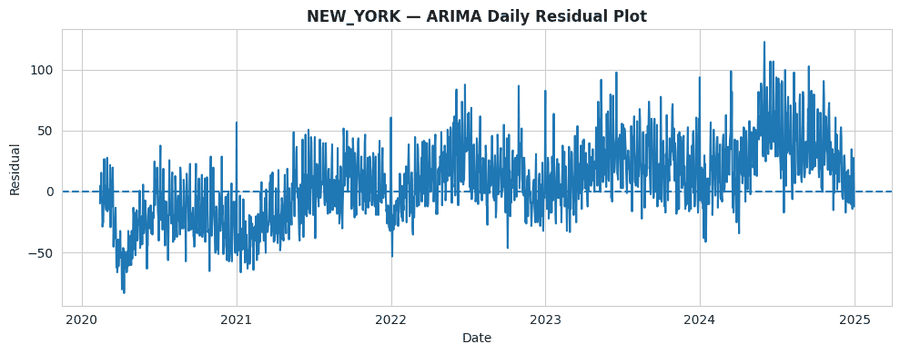

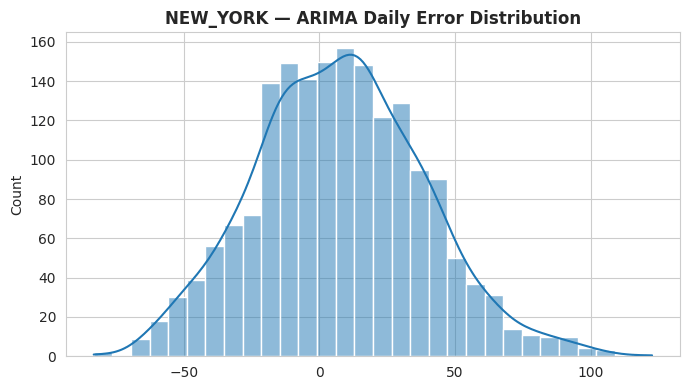


Running category forecasting for new_york: CRIMINAL MISCHIEF & RELATED OF
Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.3310 - val_loss: 0.0110 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0829 - val_loss: 0.0095 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1061 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0837 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0764 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0812 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0758 - val_loss: 0.0086 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0783 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 9/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5m

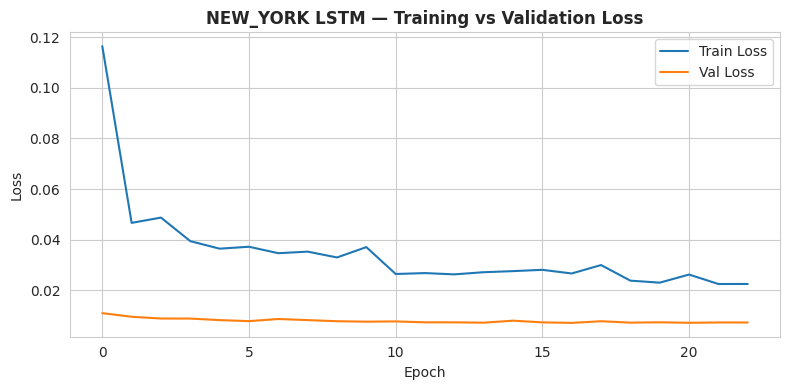

NEW_YORK LSTM
Stopped at epoch 23
Final train loss: 0.022485
Final val loss: 0.007260
Ratio (val/train): 0.32
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


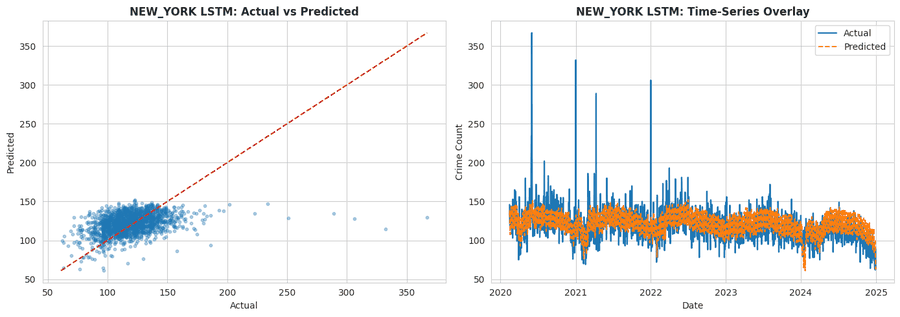

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.5171 - val_loss: 0.0113 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0770 - val_loss: 0.0099 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0886 - val_loss: 0.0101 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0743 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0790 - val_loss: 0.0091 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0766 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 7/30
184/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0712
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0700 - val_loss: 0.0092 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0752 - val_loss: 0.0086 - learning_r

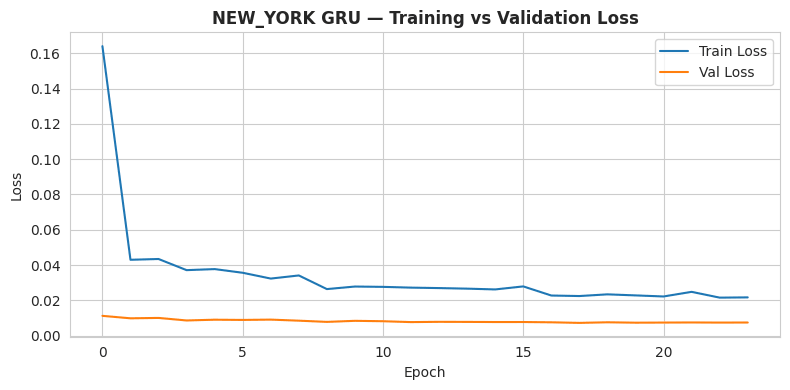

NEW_YORK GRU
Stopped at epoch 24
Final train loss: 0.021747
Final val loss: 0.007524
Ratio (val/train): 0.35
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


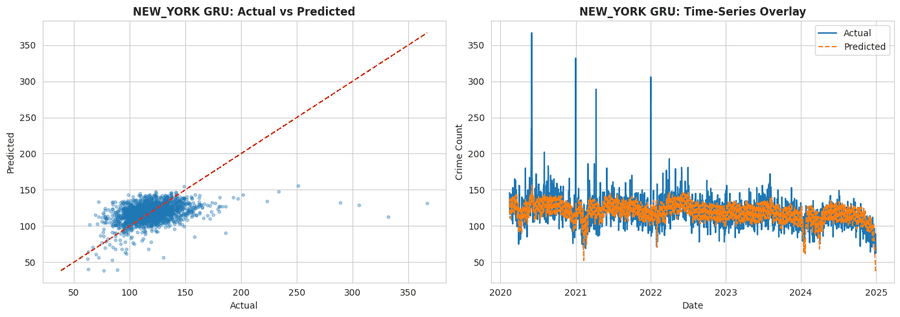

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.4353 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2730 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1364 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1578 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1282 - val_loss: 0.0120 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1307 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 7/30
186/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1342
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1325 - val_loss: 0.0115 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1127 - val_loss: 0.0101 - learning_

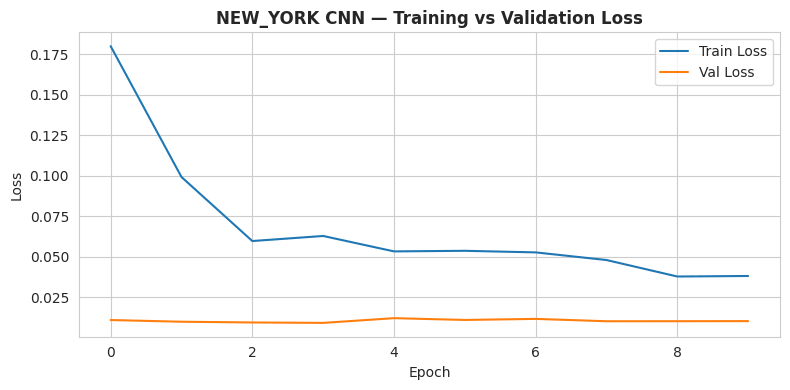

NEW_YORK CNN
Stopped at epoch 10
Final train loss: 0.038022
Final val loss: 0.010136
Ratio (val/train): 0.27
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


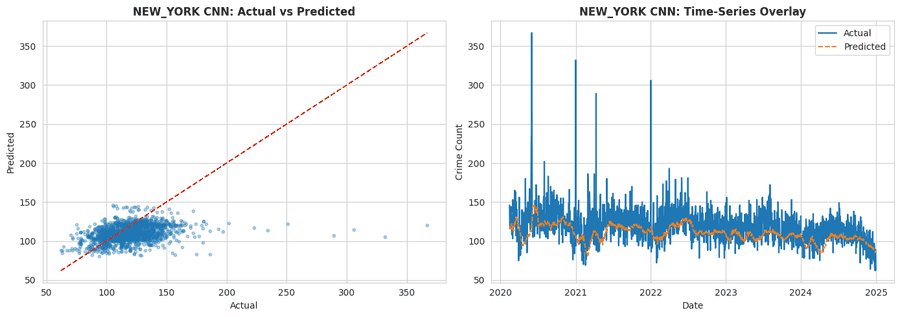

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - loss: 0.6960 - val_loss: 0.0136 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2024 - val_loss: 0.0165 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1674 - val_loss: 0.0176 - learning_rate: 0.0010
Epoch 4/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1738
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1690 - val_loss: 0.0204 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1136 - val_loss: 0.0205 - learning_rate: 5.0000e-04
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0650 - val_loss: 0.0191 - learning_rate: 5.0000e-04
Epoch 7/30
178/189 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0646
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0628

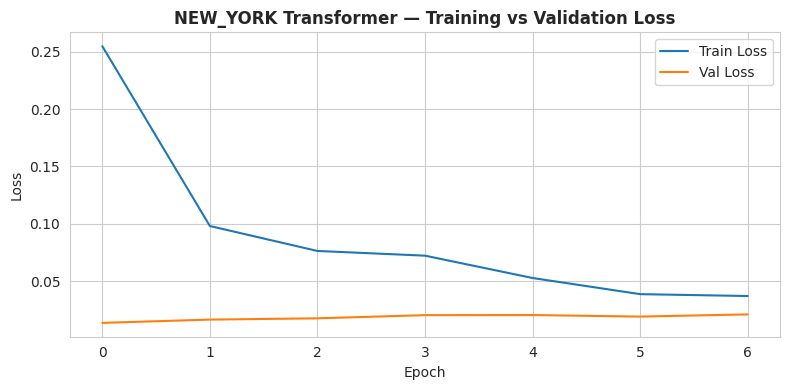

NEW_YORK Transformer
Stopped at epoch 7
Final train loss: 0.037060
Final val loss: 0.021025
Ratio (val/train): 0.57
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


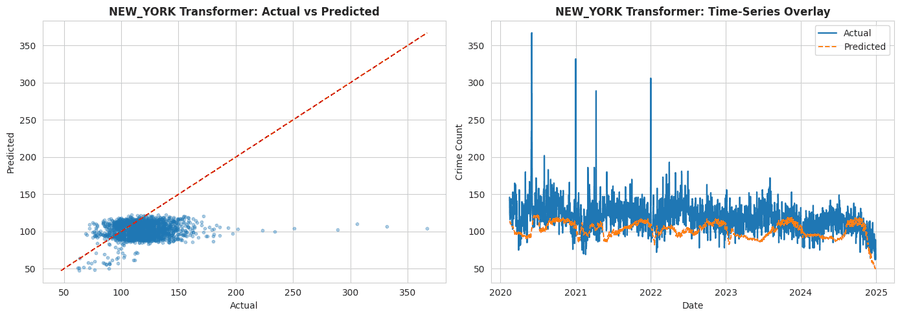

new_york ADF stat=-1.8706, p=0.3460
Selected DAILY ARIMA: (3, 1, 2)


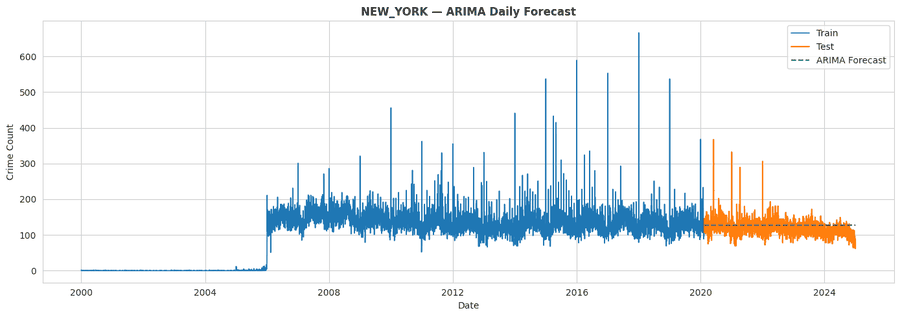

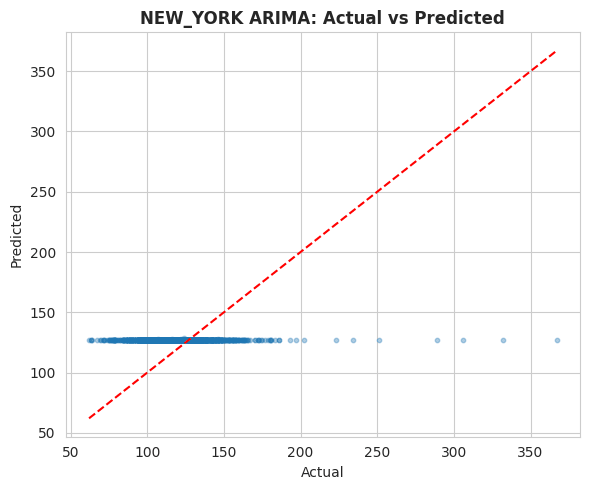

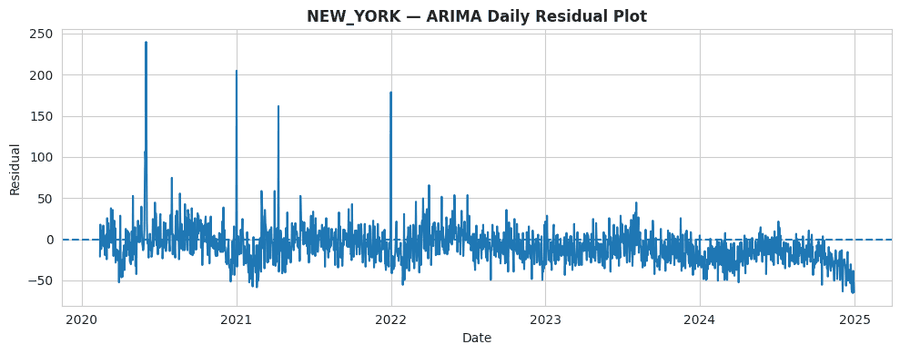

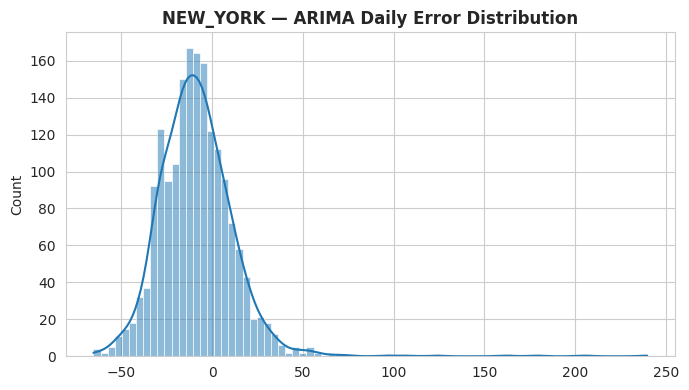


Running category forecasting for new_york: GRAND LARCENY
Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.5562 - val_loss: 0.0081 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2253 - val_loss: 0.0070 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2367 - val_loss: 0.0105 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2941 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2294 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2042 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 7/30
181/189 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2113
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2053 - val_loss: 0.0060 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 

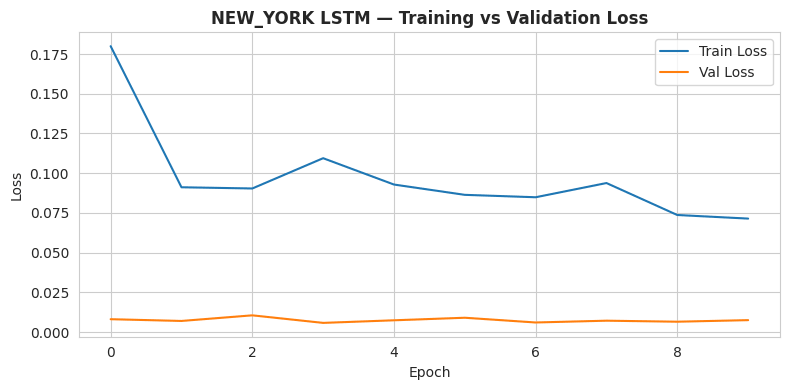

NEW_YORK LSTM
Stopped at epoch 10
Final train loss: 0.071410
Final val loss: 0.007495
Ratio (val/train): 0.10
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


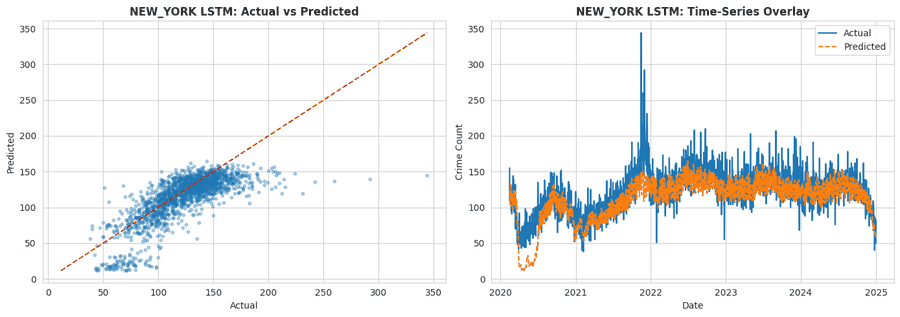

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.6139 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1971 - val_loss: 0.0086 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2261 - val_loss: 0.0096 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2375 - val_loss: 0.0084 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2277 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2238 - val_loss: 0.0071 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1932 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1822 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 9/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1731 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 10/3

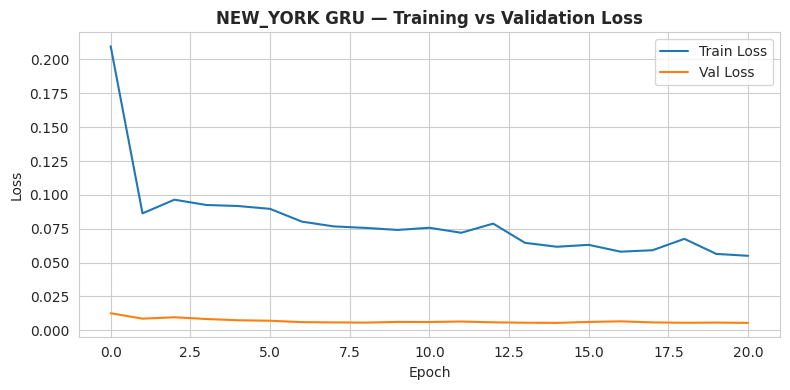

NEW_YORK GRU
Stopped at epoch 21
Final train loss: 0.055047
Final val loss: 0.005508
Ratio (val/train): 0.10
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


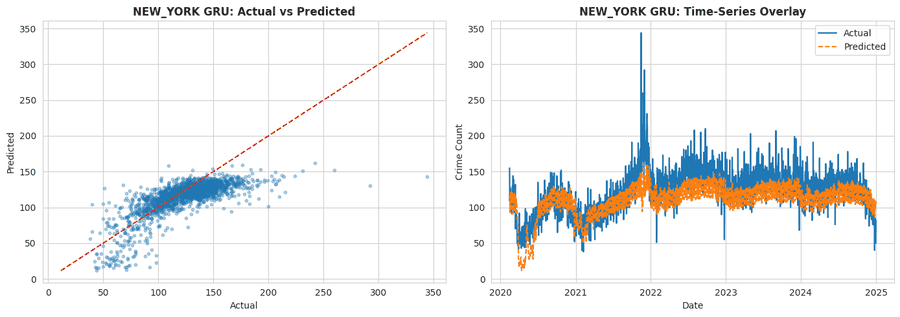

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.4679 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3485 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2414 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2642 - val_loss: 0.0097 - learning_rate: 0.0010
Epoch 5/30
177/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2421
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2318 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2279 - val_loss: 0.0162 - learning_rate: 5.0000e-04
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1599 - val_loss: 0.0136 - learning_rate: 5.0000e-04
Epoch 8/30
177/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1504
Epoch 8: ReduceLROnPla

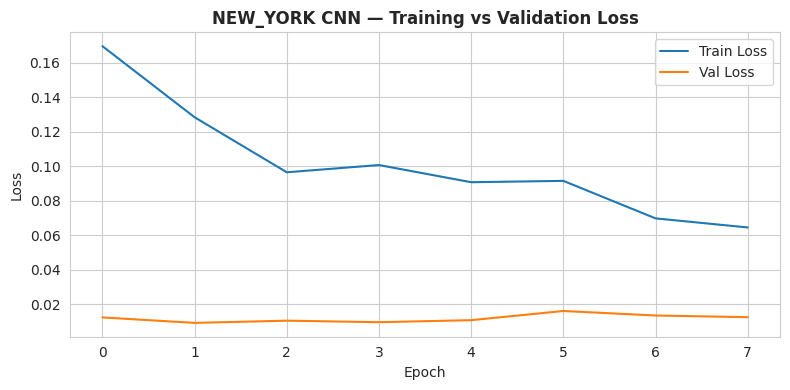

NEW_YORK CNN
Stopped at epoch 8
Final train loss: 0.064552
Final val loss: 0.012630
Ratio (val/train): 0.20
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


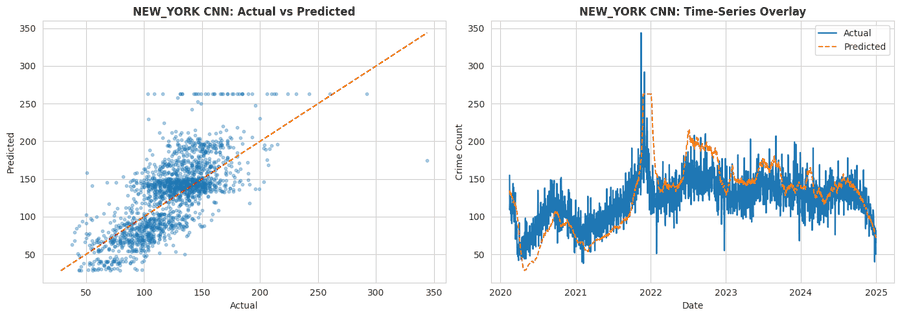

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - loss: 0.9859 - val_loss: 0.0182 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2708 - val_loss: 0.0172 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3015 - val_loss: 0.0186 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2611 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2471 - val_loss: 0.0170 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2168 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 7/30
182/189 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2225
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2172 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 8/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2558 - val_loss: 0.0149 - learning

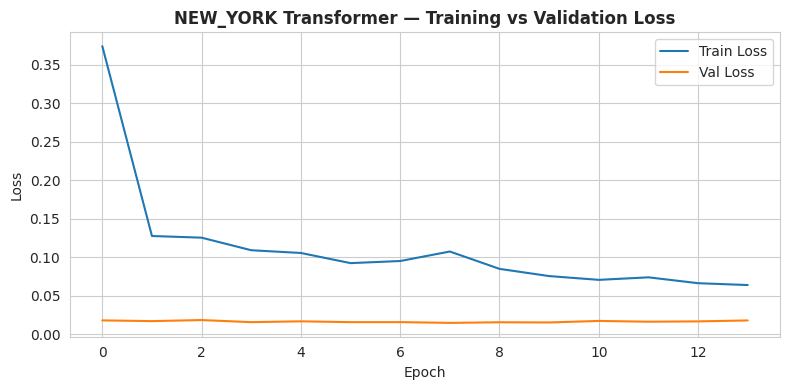

NEW_YORK Transformer
Stopped at epoch 14
Final train loss: 0.064017
Final val loss: 0.018097
Ratio (val/train): 0.28
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


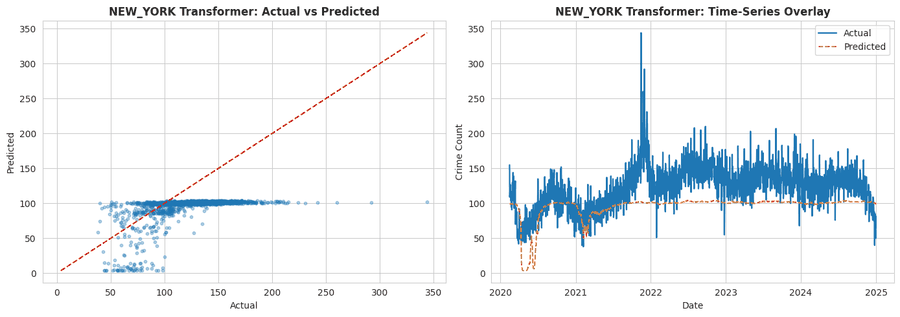

new_york ADF stat=-1.6658, p=0.4488
Selected DAILY ARIMA: (3, 1, 2)


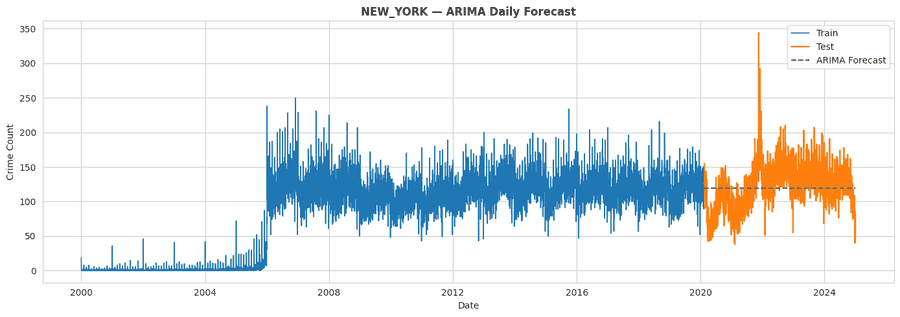

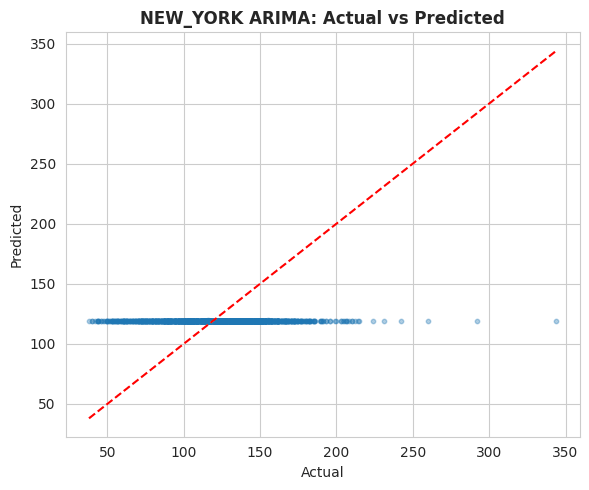

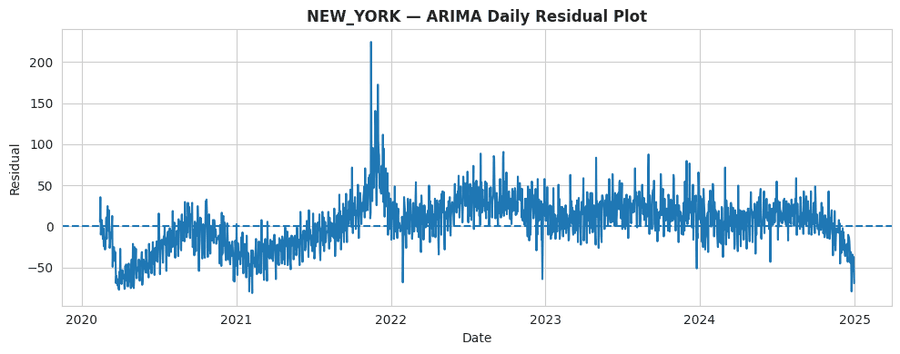

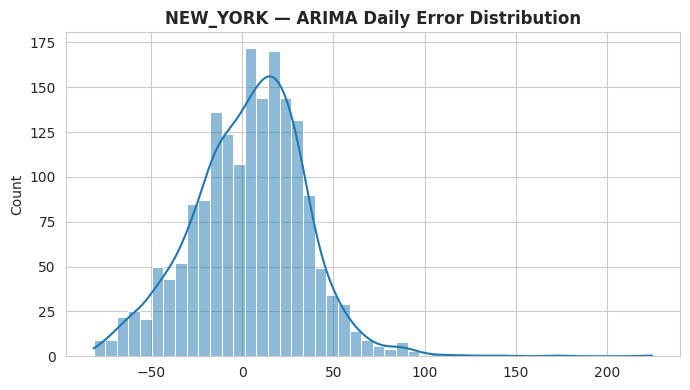

,City,Category,Model,RMSE,MAE,R2,NRMSE_pct,sMAPE,WAPE_pct,MASE,MedAE,Explained_Variance,Mean_Actual,CVRMSE_pct,MAPE_safe,Order,Seasonal_Order
0,chicago,THEFT,GRU,21.458034,16.348705,0.531743,14.669965,11.769174,11.176929,0.860212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chicago,THEFT,LSTM,22.265059,16.811232,0.495859,15.221694,12.144527,11.493139,0.884548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chicago,THEFT,CNN,27.414757,21.424716,0.235684,18.742328,15.308274,14.647187,1.127294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chicago,THEFT,Transformer,27.747267,21.294556,0.217031,18.969651,15.268854,14.558201,1.120445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chicago,THEFT,ARIMA,78.754066,72.619289,-5.298179,53.852936,63.323486,49.657906,3.822505,73.992551,0.000042,146.23913,53.852936,51.373734,"(3, 1, 2)",None


,City,Category,Model,RMSE,MAE,R2,NRMSE_pct,sMAPE,WAPE_pct,MASE,MedAE,Explained_Variance,Mean_Actual,CVRMSE_pct,MAPE_safe,Order,Seasonal_Order
0,los_angeles,BATTERY - SIMPLE ASSAULT,GRU,8.830296,6.973785,0.159152,16.822908,13.395436,13.286003,0.718398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,los_angeles,BATTERY - SIMPLE ASSAULT,LSTM,8.879596,7.018191,0.149737,16.916832,13.506050,13.370603,0.722972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,los_angeles,BATTERY - SIMPLE ASSAULT,Transformer,9.193747,7.209335,0.088510,17.515332,13.838561,13.734757,0.742662,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,los_angeles,BATTERY - SIMPLE ASSAULT,CNN,9.302148,7.234511,0.066889,17.721851,13.879062,13.782723,0.745256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,los_angeles,BATTERY - SIMPLE ASSAULT,ARIMA,11.244216,8.686646,-0.347326,21.413370,16.775432,16.542759,0.886640,7.19784,-0.000196,52.51026,21.41337,15.72275,"(3, 1, 2)",None


,City,Category,Model,RMSE,MAE,R2,NRMSE_pct,sMAPE,WAPE_pct,MASE,MedAE,Explained_Variance,Mean_Actual,CVRMSE_pct,MAPE_safe,Order,Seasonal_Order
0,new_york,PETIT LARCENY,GRU,29.209287,21.215960,0.701598,10.584495,8.306629,7.687973,0.728849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,new_york,PETIT LARCENY,LSTM,40.943676,32.026692,0.413682,14.836655,12.673103,11.605430,1.100238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,new_york,PETIT LARCENY,CNN,68.907055,54.381366,-0.660684,24.969673,18.617039,19.706036,1.868206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,new_york,PETIT LARCENY,Transformer,95.958361,84.835510,-2.220515,34.772186,34.619389,30.741627,2.914422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,new_york,PETIT LARCENY,ARIMA,61.252933,50.984760,-0.312697,22.197555,19.158942,18.476454,1.752368,47.952011,0.000032,275.944507,22.197555,18.494683,"(3, 1, 2)",None


In [49]:
# CELL 44 — Run Category Forecasting for All Top Categories
def run_all_category_forecasts(panel_df, top_categories, city_key):
    all_results = []
    for cat in top_categories:
        print(f"\nRunning category forecasting for {city_key}: {cat}")
        dl_df = run_category_dl_forecast(panel_df, cat, city_key, look_back=30, epochs=30)
        ar_df = run_category_arima_forecast(panel_df, cat, city_key)
        combo = pd.concat([dl_df, ar_df], ignore_index=True)
        combo["Category"] = cat
        all_results.append(combo)
    final_df = pd.concat(all_results, ignore_index=True)
    final_df.to_csv(os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_all_category_forecast_results.csv"), index=False)
    return final_df


chi_cat_results = run_all_category_forecasts(chi_cat_panel, chi_top_cats, "chicago")
la_cat_results  = run_all_category_forecasts(la_cat_panel,  la_top_cats,  "los_angeles")
nyc_cat_results = run_all_category_forecasts(nyc_cat_panel, nyc_top_cats, "new_york")

display(chi_cat_results.head())
display(la_cat_results.head())
display(nyc_cat_results.head())


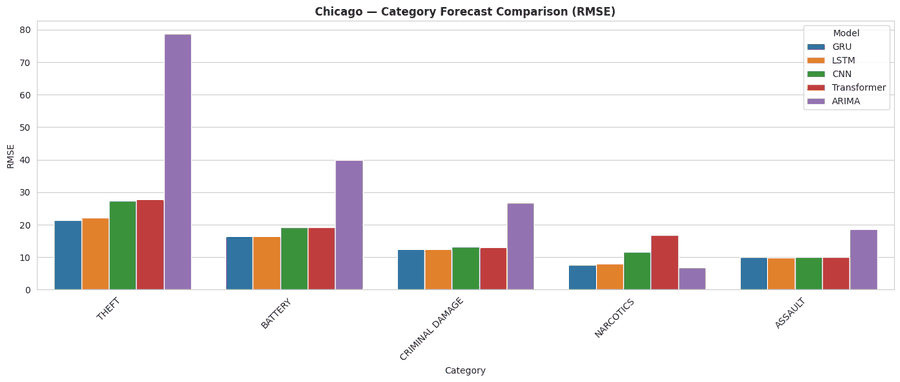

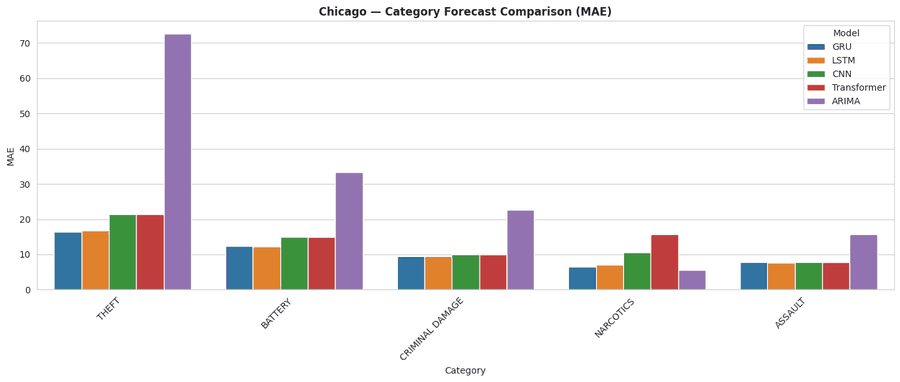

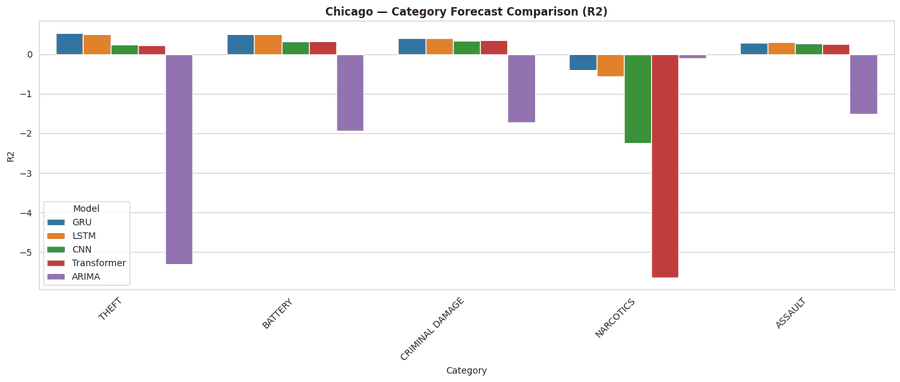

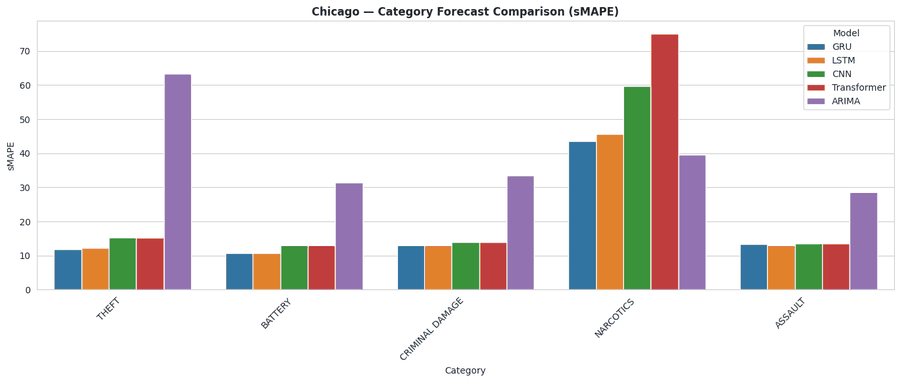

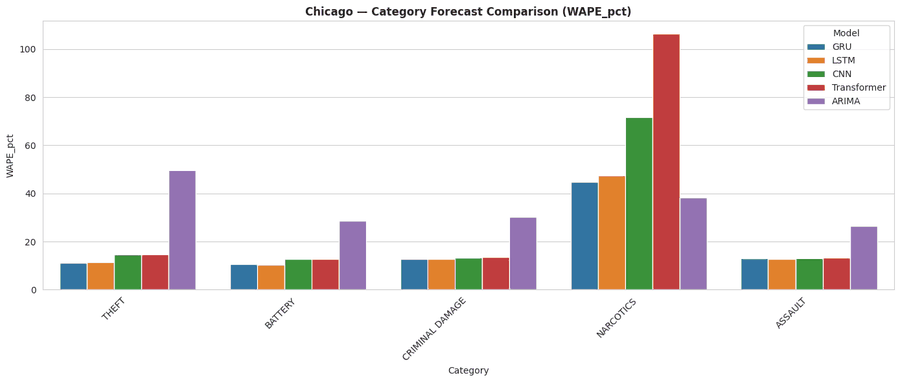

...

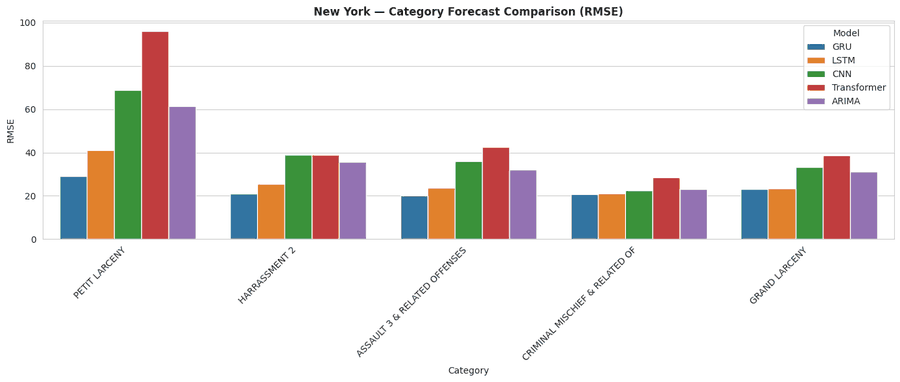

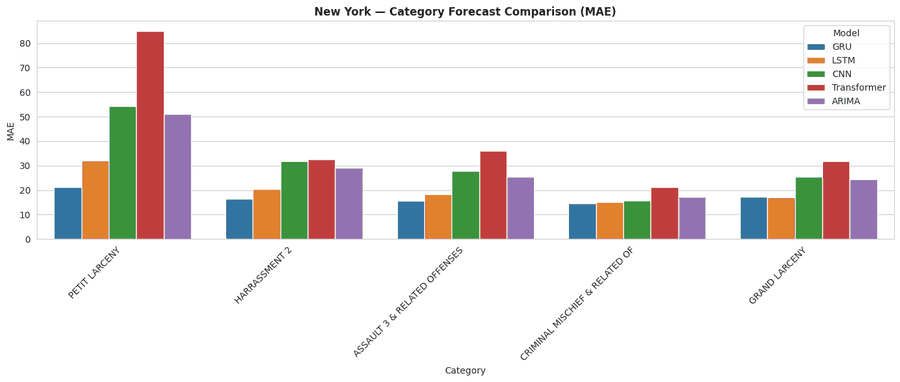

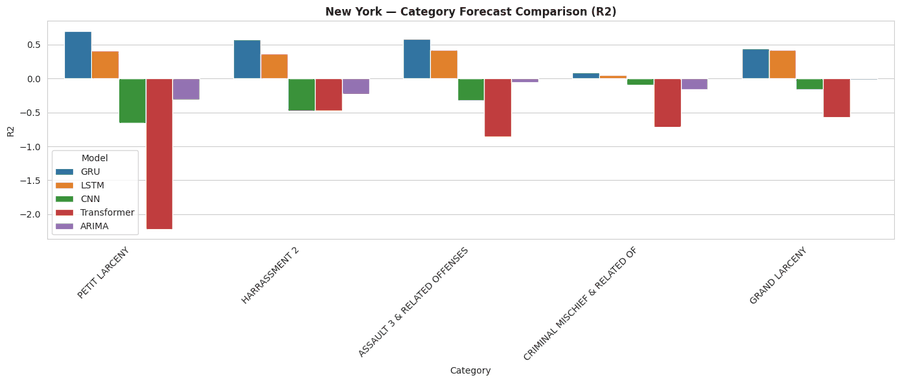

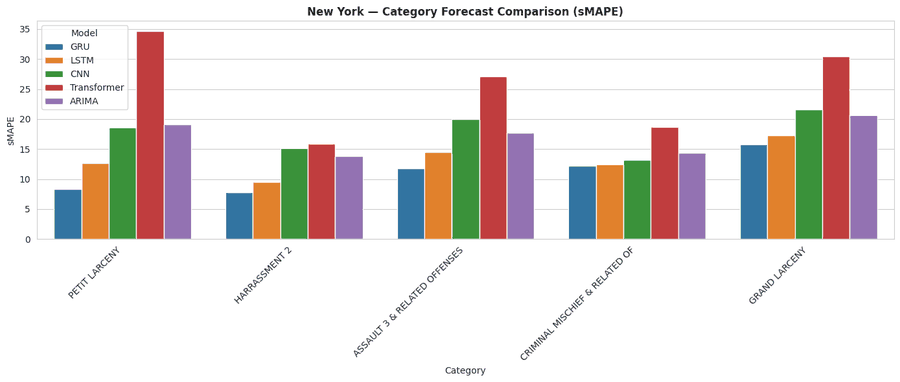

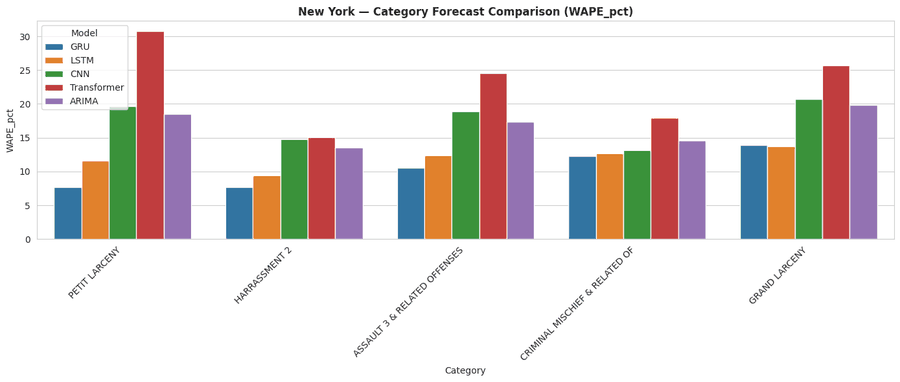

In [50]:
# CELL 45 — Category Forecast Comparison Plots
def plot_category_results(cat_results_df, city_key, city_title):
    for metric in ["RMSE", "MAE", "R2", "sMAPE", "WAPE_pct"]:
        plt.figure(figsize=(14, 6))
        sns.barplot(data=cat_results_df, x="Category", y=metric, hue="Model")
        plt.xticks(rotation=45, ha="right")
        plt.title(f"{city_title} — Category Forecast Comparison ({metric})", fontweight="bold")
        plt.tight_layout()
        plt.savefig(os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_category_{metric.lower()}.png"), dpi=300)
        plt.show()

plot_category_results(chi_cat_results, "chicago", "Chicago")
plot_category_results(la_cat_results, "los_angeles", "Los Angeles")
plot_category_results(nyc_cat_results, "new_york", "New York")


# *PART 7 — ABLATION STUDY*

In [51]:
# CELL 46 — Ablation Study Model Definitions (OLD + NEW)

# ------------------------------------------------------------
# PART A: Original hybrid ablation models (already in notebook)
# ------------------------------------------------------------
def build_gru_transformer_model(input_shape):
    inp = Input(shape=input_shape)
    x = GRU(64, return_sequences=True)(inp)
    x = transformer_encoder(x, head_size=32, num_heads=2, ff_dim=64, dropout=0.1)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.2)(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def build_cnn_gru_model(input_shape):
    inp = Input(shape=input_shape)
    x = Conv1D(64, kernel_size=3, activation="relu", padding="causal")(inp)
    x = GRU(64, return_sequences=False)(x)
    x = Dropout(0.2)(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def build_cnn_lstm_model(input_shape):
    inp = Input(shape=input_shape)
    x = Conv1D(64, kernel_size=3, activation="relu", padding="causal")(inp)
    x = LSTM(64, return_sequences=False)(x)
    x = Dropout(0.2)(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def build_cnn_gru_transformer_model(input_shape):
    inp = Input(shape=input_shape)
    x = Conv1D(64, kernel_size=3, activation="relu", padding="causal")(inp)
    x = GRU(64, return_sequences=True)(x)
    x = transformer_encoder(x, head_size=32, num_heads=2, ff_dim=64, dropout=0.1)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.2)(x)
    out = Dense(1)(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


HYBRID_ABLATION_MODELS = {
    "Without CNN (GRU+Transformer)": build_gru_transformer_model,
    "With CNN+GRU": build_cnn_gru_model,
    "With CNN+LSTM": build_cnn_lstm_model,
    "With CNN+GRU+Transformer": build_cnn_gru_transformer_model
}

# ------------------------------------------------------------
# PART B: New CNN-only baseline ablation
# ------------------------------------------------------------
def build_cnn_ablation_model(
    input_shape,
    n_conv_layers=2,
    filters=64,
    kernel_size=3,
    dense_units=32,
    dropout_rate=0.2
):
    inp = Input(shape=input_shape)
    x = inp

    for _ in range(n_conv_layers):
        x = Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="causal")(x)

    x = GlobalAveragePooling1D()(x)
    x = Dropout(dropout_rate)(x)
    x = Dense(dense_units, activation="relu")(x)
    out = Dense(1)(x)

    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mse")
    return model


def make_cnn_builder(n_conv_layers=2, filters=64, kernel_size=3, dense_units=32, dropout_rate=0.2):
    def _builder(input_shape):
        return build_cnn_ablation_model(
            input_shape=input_shape,
            n_conv_layers=n_conv_layers,
            filters=filters,
            kernel_size=kernel_size,
            dense_units=dense_units,
            dropout_rate=dropout_rate
        )
    return _builder


CNN_ONLY_ABLATION_CONFIGS = [
    {"Model": "CNN_baseline_L14_2layers", "look_back": 14, "n_conv_layers": 2},
    {"Model": "CNN_baseline_L30_2layers", "look_back": 30, "n_conv_layers": 2},
    {"Model": "CNN_baseline_L60_2layers", "look_back": 60, "n_conv_layers": 2},
    {"Model": "CNN_depth1_L30",          "look_back": 30, "n_conv_layers": 1},
    {"Model": "CNN_depth2_L30",          "look_back": 30, "n_conv_layers": 2},
    {"Model": "CNN_depth3_L30",          "look_back": 30, "n_conv_layers": 3},
]

print("Hybrid ablation models:")
print(list(HYBRID_ABLATION_MODELS.keys()))

print("\nCNN-only ablation configs:")
display(pd.DataFrame(CNN_ONLY_ABLATION_CONFIGS))

Hybrid ablation models:
['Without CNN (GRU+Transformer)', 'With CNN+GRU', 'With CNN+LSTM', 'With CNN+GRU+Transformer']

CNN-only ablation configs:


,Model,look_back,n_conv_layers
0,CNN_baseline_L14_2layers,14,2
1,CNN_baseline_L30_2layers,30,2
2,CNN_baseline_L60_2layers,60,2
3,CNN_depth1_L30,30,1
4,CNN_depth2_L30,30,2
5,CNN_depth3_L30,30,3



Hybrid Ablation: chicago — Without CNN (GRU+Transformer)
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 1.0409 - val_loss: 0.7184 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4606 - val_loss: 0.5478 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4669 - val_loss: 0.4624 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3887 - val_loss: 0.3932 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3874 - val_loss: 0.2827 - learning_rate: 0.0010
Epoch 6/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3504 - val_loss: 0.2565 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3291 - val_loss: 0.3142 - learning_rate: 0.0010
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3272 - val_loss: 0.2421 - learning_rate: 0.0010
Epoch 9/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step -

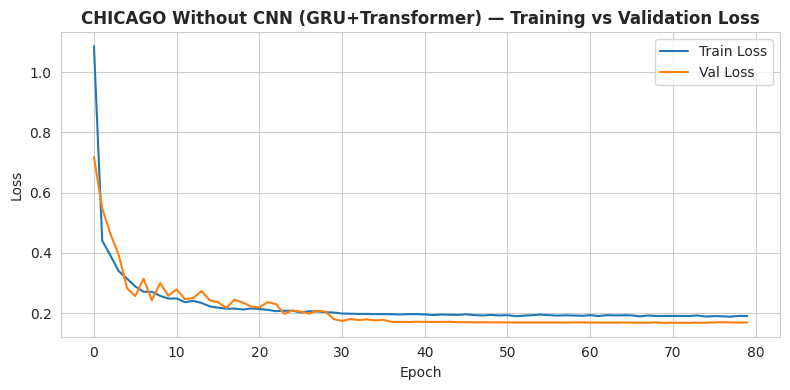

CHICAGO Without CNN (GRU+Transformer)
Stopped at epoch 80
Final train loss: 0.190103
Final val loss: 0.168441
Ratio (val/train): 0.89
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


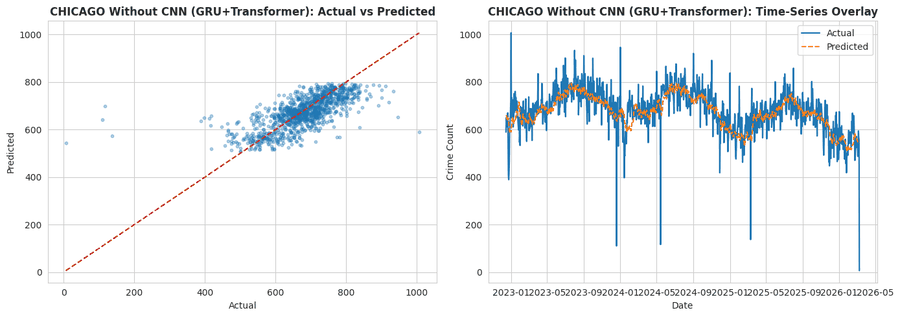


Hybrid Ablation: chicago — With CNN+GRU
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.7656 - val_loss: 0.1585 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2450 - val_loss: 0.1787 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2022 - val_loss: 0.2074 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1933 - val_loss: 0.2130 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1968 - val_loss: 0.2337 - learning_rate: 0.0010
Epoch 6/80
120/125 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1889
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1883 - val_loss: 0.2357 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1873 - val_loss: 0.1729 - learning_rate: 5.0000e-04
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step -

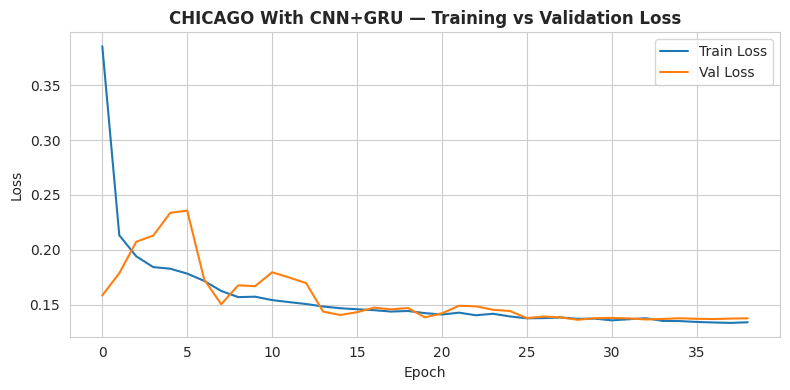

CHICAGO With CNN+GRU
Stopped at epoch 39
Final train loss: 0.133983
Final val loss: 0.137597
Ratio (val/train): 1.03
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


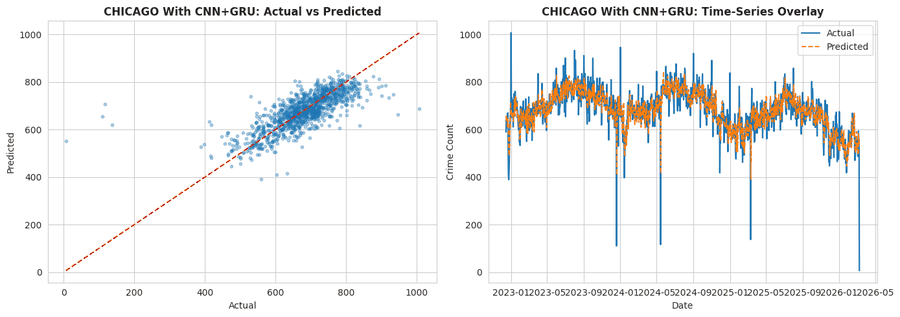


Hybrid Ablation: chicago — With CNN+LSTM
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5587 - val_loss: 0.1868 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2261 - val_loss: 0.2171 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2109 - val_loss: 0.2531 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2121 - val_loss: 0.2898 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2089 - val_loss: 0.2957 - learning_rate: 0.0010
Epoch 6/80
121/125 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2041
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2034 - val_loss: 0.3746 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1900 - val_loss: 0.2605 - learning_rate: 5.0000e-04
Epoch 8/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step 

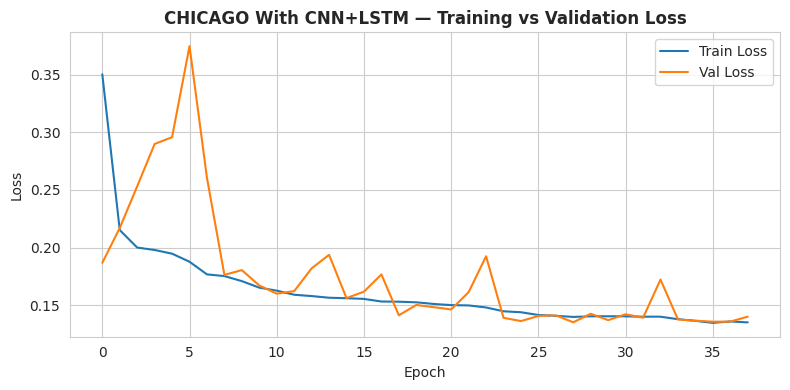

CHICAGO With CNN+LSTM
Stopped at epoch 38
Final train loss: 0.135273
Final val loss: 0.140230
Ratio (val/train): 1.04
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


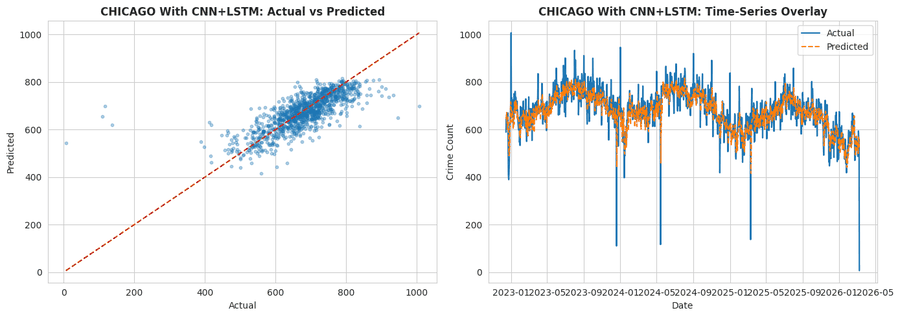


Hybrid Ablation: chicago — With CNN+GRU+Transformer
Epoch 1/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 1.0583 - val_loss: 0.2886 - learning_rate: 0.0010
Epoch 2/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.6399 - val_loss: 0.2899 - learning_rate: 0.0010
Epoch 3/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4455 - val_loss: 0.3473 - learning_rate: 0.0010
Epoch 4/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4132 - val_loss: 0.4162 - learning_rate: 0.0010
Epoch 5/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4040 - val_loss: 0.5346 - learning_rate: 0.0010
Epoch 6/80
120/125 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4316
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4261 - val_loss: 0.6301 - learning_rate: 0.0010
Epoch 7/80
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4498 - val_loss: 0.5740 - learning_rate: 5.0000e-04
Epoch 8/80
125/125 ━━━━━━━━━━━━━━

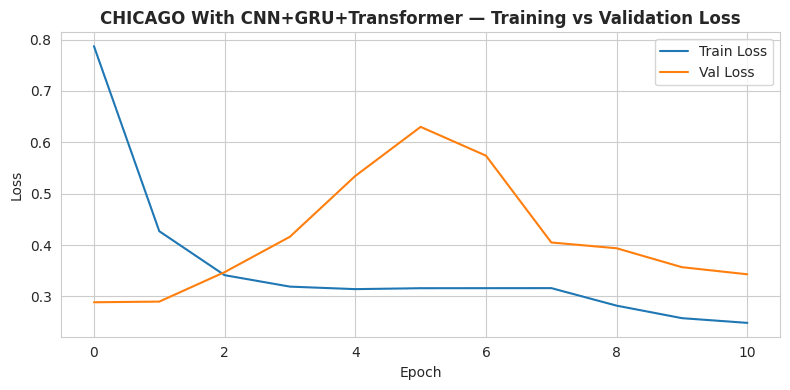

CHICAGO With CNN+GRU+Transformer
Stopped at epoch 11
Final train loss: 0.248445
Final val loss: 0.343063
Ratio (val/train): 1.38
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


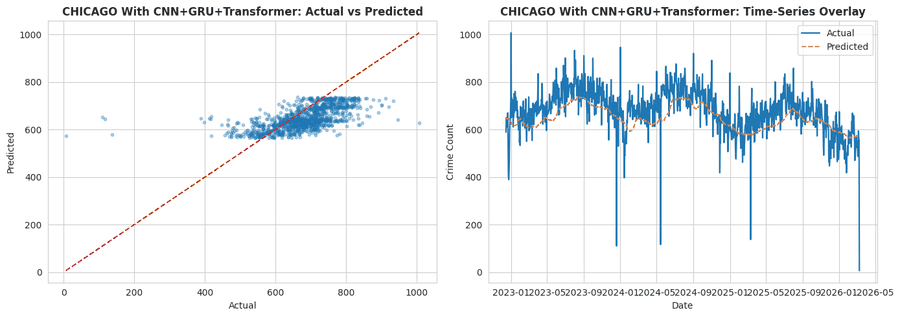


CNN Ablation: chicago — CNN_baseline_L14_2layers | look_back=14, conv_layers=2
Epoch 1/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.3532 - val_loss: 0.2961 - learning_rate: 0.0010
Epoch 2/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2397 - val_loss: 0.3631 - learning_rate: 0.0010
Epoch 3/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2321 - val_loss: 0.3636 - learning_rate: 0.0010
Epoch 4/35
110/126 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2325
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2309 - val_loss: 0.3303 - learning_rate: 0.0010
Epoch 5/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2299 - val_loss: 0.2334 - learning_rate: 5.0000e-04
Epoch 6/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2232 - val_loss: 0.1900 - learning_rate: 5.0000e-04
Epoch 7/35
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2129 - val_loss: 0.1852 - learning_rate: 5.0000e-04
Epoch

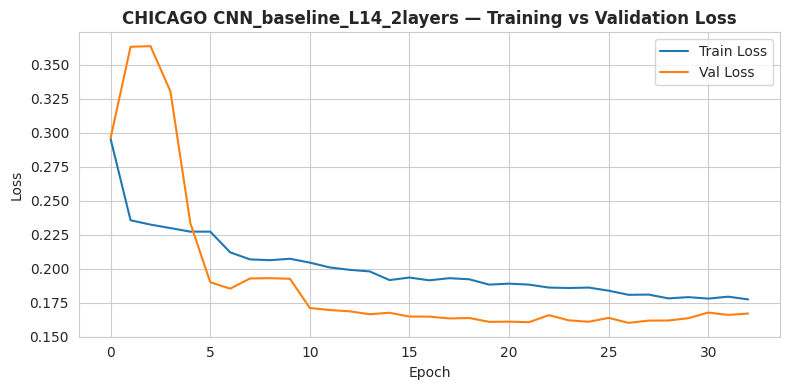

CHICAGO CNN_baseline_L14_2layers
Stopped at epoch 33
Final train loss: 0.177312
Final val loss: 0.166921
Ratio (val/train): 0.94
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


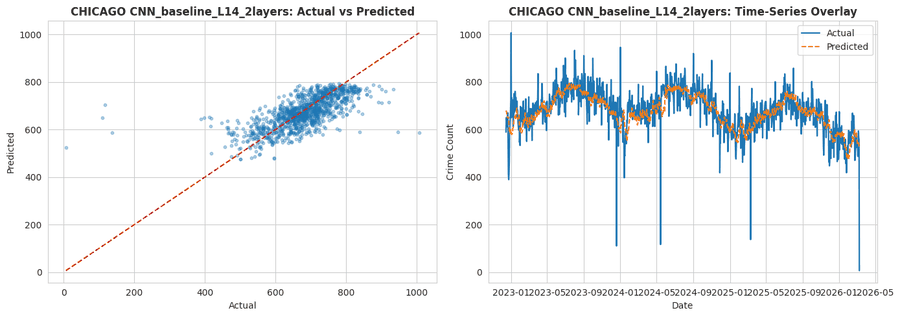


CNN Ablation: chicago — CNN_baseline_L30_2layers | look_back=30, conv_layers=2
Epoch 1/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.4821 - val_loss: 0.2138 - learning_rate: 0.0010
Epoch 2/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2445 - val_loss: 0.2418 - learning_rate: 0.0010
Epoch 3/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2257 - val_loss: 0.2186 - learning_rate: 0.0010
Epoch 4/35
116/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2268
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2272 - val_loss: 0.2478 - learning_rate: 0.0010
Epoch 5/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2333 - val_loss: 0.2053 - learning_rate: 5.0000e-04
Epoch 6/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2233 - val_loss: 0.2064 - learning_rate: 5.0000e-04
Epoch 7/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2256 - val_loss: 0.1943 - learning_rate: 5.0000e-04
Epoch

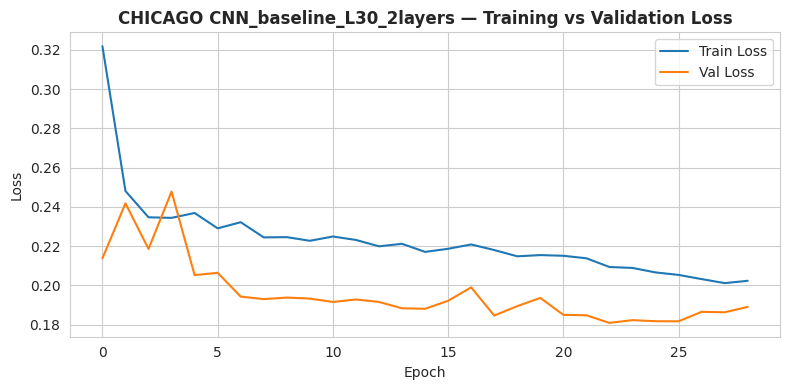

CHICAGO CNN_baseline_L30_2layers
Stopped at epoch 29
Final train loss: 0.202361
Final val loss: 0.189046
Ratio (val/train): 0.93
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


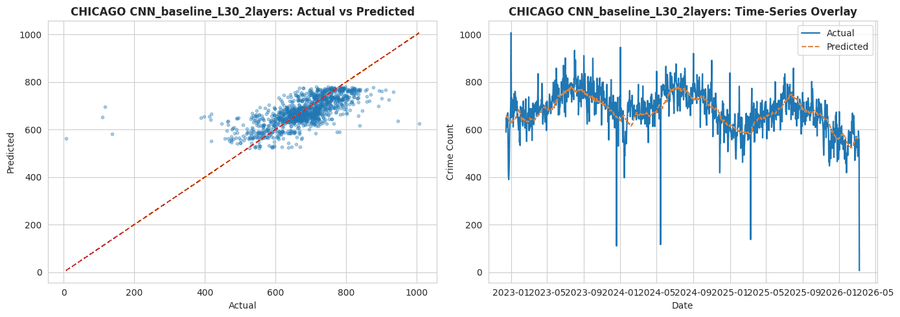


CNN Ablation: chicago — CNN_baseline_L60_2layers | look_back=60, conv_layers=2
Epoch 1/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.4971 - val_loss: 0.2320 - learning_rate: 0.0010
Epoch 2/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2583 - val_loss: 0.2254 - learning_rate: 0.0010
Epoch 3/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2256 - val_loss: 0.2381 - learning_rate: 0.0010
Epoch 4/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2192 - val_loss: 0.2616 - learning_rate: 0.0010
Epoch 5/35
115/124 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2262
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2279 - val_loss: 0.2712 - learning_rate: 0.0010
Epoch 6/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2157 - val_loss: 0.2294 - learning_rate: 5.0000e-04
Epoch 7/35
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2195 - val_loss: 0.2199 - learning_rate: 5.0000e-04
Epoch 8/3

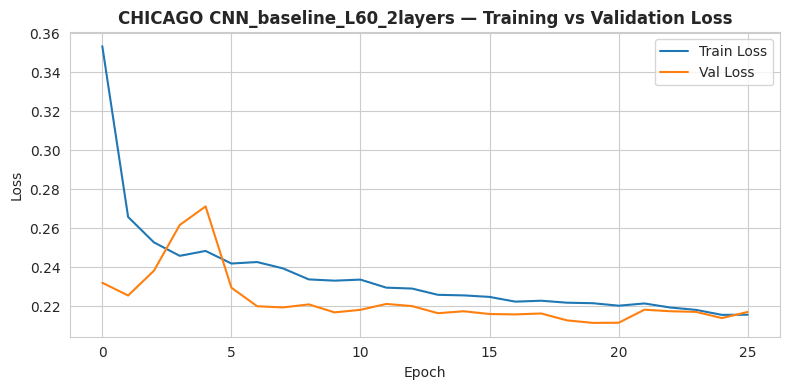

CHICAGO CNN_baseline_L60_2layers
Stopped at epoch 26
Final train loss: 0.215536
Final val loss: 0.216952
Ratio (val/train): 1.01
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


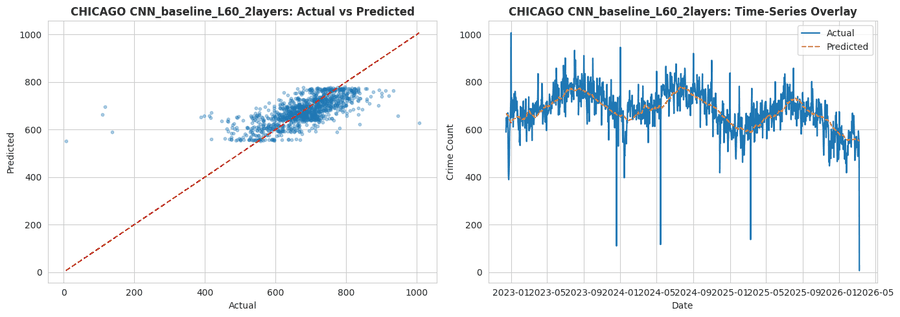


CNN Ablation: chicago — CNN_depth1_L30 | look_back=30, conv_layers=1
Epoch 1/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 1.5860 - val_loss: 0.2334 - learning_rate: 0.0010
Epoch 2/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2467 - val_loss: 0.2526 - learning_rate: 0.0010
Epoch 3/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2407 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 4/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2359 - val_loss: 0.2130 - learning_rate: 0.0010
Epoch 5/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2268 - val_loss: 0.2049 - learning_rate: 0.0010
Epoch 6/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2281 - val_loss: 0.2119 - learning_rate: 0.0010
Epoch 7/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2220 - val_loss: 0.2165 - learning_rate: 0.0010
Epoch 8/35
121/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2226
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━

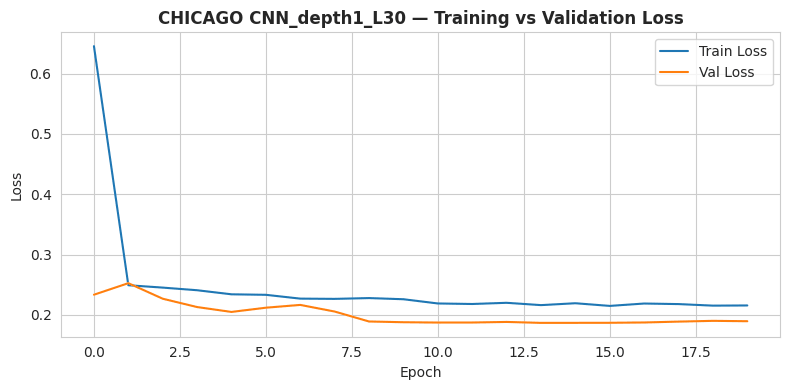

CHICAGO CNN_depth1_L30
Stopped at epoch 20
Final train loss: 0.215629
Final val loss: 0.189493
Ratio (val/train): 0.88
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


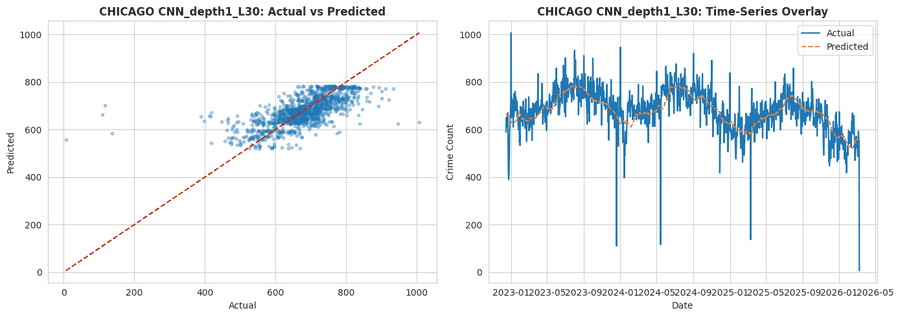


CNN Ablation: chicago — CNN_depth2_L30 | look_back=30, conv_layers=2
Epoch 1/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.5228 - val_loss: 0.2107 - learning_rate: 0.0010
Epoch 2/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2473 - val_loss: 0.2776 - learning_rate: 0.0010
Epoch 3/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2338 - val_loss: 0.2865 - learning_rate: 0.0010
Epoch 4/35
116/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2359
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2363 - val_loss: 0.2494 - learning_rate: 0.0010
Epoch 5/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2283 - val_loss: 0.2207 - learning_rate: 5.0000e-04
Epoch 6/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2288 - val_loss: 0.2078 - learning_rate: 5.0000e-04
Epoch 7/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2233 - val_loss: 0.1991 - learning_rate: 5.0000e-04
Epoch 8/35
125/

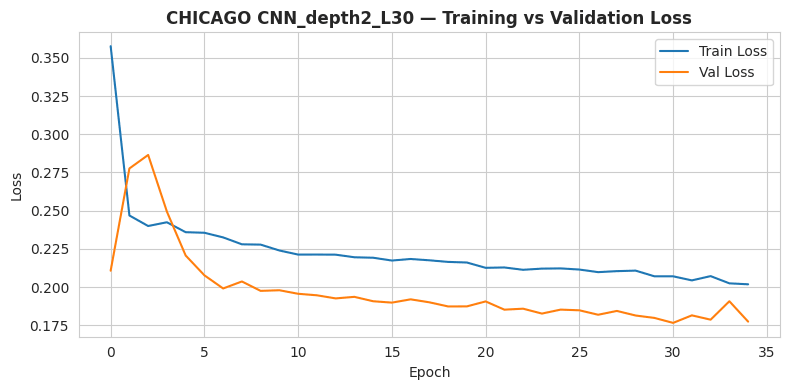

CHICAGO CNN_depth2_L30
Stopped at epoch 35
Final train loss: 0.201868
Final val loss: 0.177459
Ratio (val/train): 0.88
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


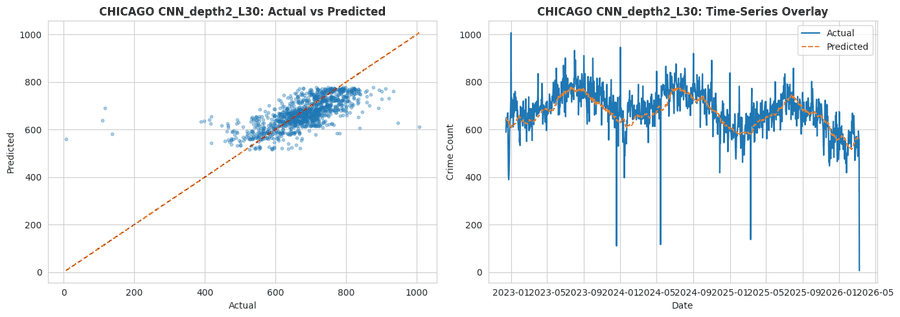


CNN Ablation: chicago — CNN_depth3_L30 | look_back=30, conv_layers=3
Epoch 1/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.4350 - val_loss: 0.2637 - learning_rate: 0.0010
Epoch 2/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2397 - val_loss: 0.2301 - learning_rate: 0.0010
Epoch 3/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2274 - val_loss: 0.2909 - learning_rate: 0.0010
Epoch 4/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2287 - val_loss: 0.2970 - learning_rate: 0.0010
Epoch 5/35
111/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2250
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2255 - val_loss: 0.3114 - learning_rate: 0.0010
Epoch 6/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2239 - val_loss: 0.2509 - learning_rate: 5.0000e-04
Epoch 7/35
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2229 - val_loss: 0.2294 - learning_rate: 5.0000e-04
Epoch 8/35
125/125 

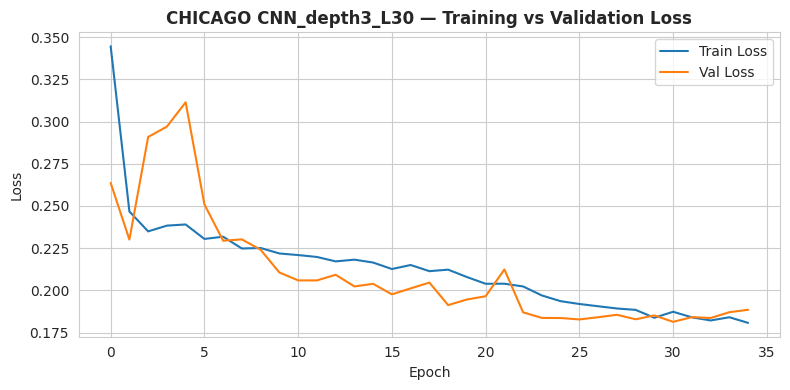

CHICAGO CNN_depth3_L30
Stopped at epoch 35
Final train loss: 0.180732
Final val loss: 0.188494
Ratio (val/train): 1.04
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


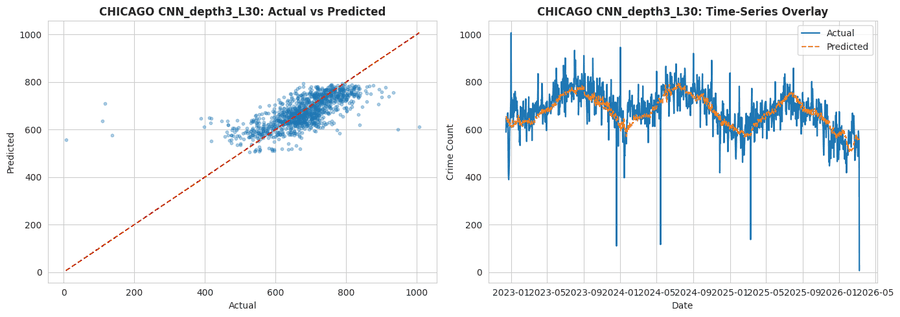


Saved ablation tables for chicago


,City,Model,Ablation_Group,Look_Back,Conv_Layers,RMSE,MAE,MedAE,R2,Explained_Variance,...,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,Without CNN (GRU+Transformer),Hybrid_Architecture,NaN,NaN,66.348854,45.379802,34.613525,0.460523,0.465173,...,9.772895,15.239958,7.060283,6.684246,0.914837,80,0.190103,0.168441,0.886049,Healthy
1,chicago,With CNN+GRU,Hybrid_Architecture,NaN,NaN,60.990158,40.811177,30.909424,0.544146,0.544641,...,8.983583,14.683103,6.356373,6.011307,0.822736,39,0.133983,0.137597,1.026971,Healthy
2,chicago,With CNN+LSTM,Hybrid_Architecture,NaN,NaN,60.963679,40.987714,30.212646,0.544542,0.549690,...,8.979682,14.589026,6.403244,6.037310,0.826295,38,0.135273,0.140230,1.036645,Healthy
3,chicago,With CNN+GRU+Transformer,Hybrid_Architecture,NaN,NaN,78.964485,59.138885,49.279419,0.235865,0.364639,...,11.631122,17.477769,9.102099,8.710898,1.192214,11,0.248445,0.343063,1.380841,Healthy
4,chicago,CNN_baseline_L14_2layers,CNN_Baseline,14.0,2.0,66.989160,46.140438,35.381226,0.450060,0.455411,...,9.867209,15.133935,7.187010,6.796284,0.930171,33,0.177312,0.166921,0.941396,Healthy
5,chicago,CNN_baseline_L30_2layers,CNN_Baseline,30.0,2.0,66.755393,45.941691,34.590942,0.453891,0.455818,...,9.832776,15.654143,7.135783,6.767009,0.926165,29,0.202361,0.189046,0.934202,Healthy
6,chicago,CNN_baseline_L60_2layers,CNN_Baseline,60.0,2.0,67.001416,45.901780,34.401062,0.449859,0.450076,...,9.869014,15.539435,7.113881,6.761131,0.925360,26,0.215536,0.216952,1.006571,Healthy
7,chicago,CNN_depth1_L30,CNN_Baseline,30.0,1.0,67.248679,46.461890,35.041321,0.445791,0.446514,...,9.905435,15.682690,7.211743,6.843633,0.936652,20,0.215629,0.189493,0.878796,Healthy
8,chicago,CNN_depth2_L30,CNN_Baseline,30.0,2.0,67.300847,46.832252,36.755005,0.444931,0.458913,...,9.913119,15.649293,7.265891,6.898185,0.944118,35,0.201868,0.177459,0.879084,Healthy
9,chicago,CNN_depth3_L30,CNN_Baseline,30.0,3.0,66.331285,45.795102,35.608887,0.460808,0.463957,...,9.770307,15.554260,7.141423,6.745418,0.923209,35,0.180732,0.188494,1.042944,Healthy



Hybrid Ablation: los_angeles — Without CNN (GRU+Transformer)
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 1.0157 - val_loss: 0.6520 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.6899 - val_loss: 3.5395 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.1824 - val_loss: 0.5211 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.4983 - val_loss: 0.4434 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.4697 - val_loss: 0.4072 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4648 - val_loss: 0.4382 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4427 - val_loss: 0.4388 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4359 - val_loss: 0.5313 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4520 

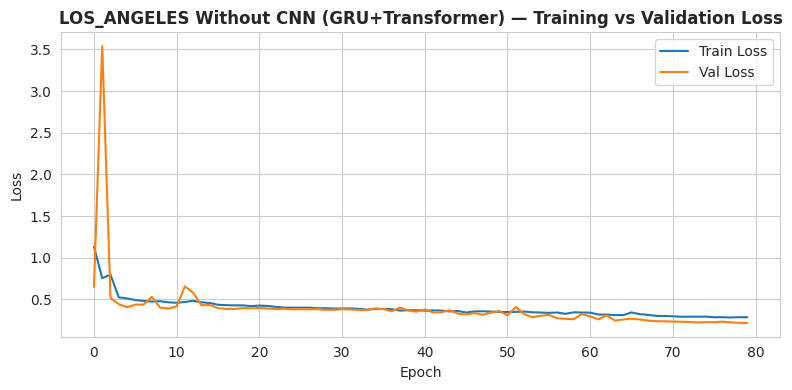

LOS_ANGELES Without CNN (GRU+Transformer)
Stopped at epoch 80
Final train loss: 0.286567
Final val loss: 0.219403
Ratio (val/train): 0.77
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


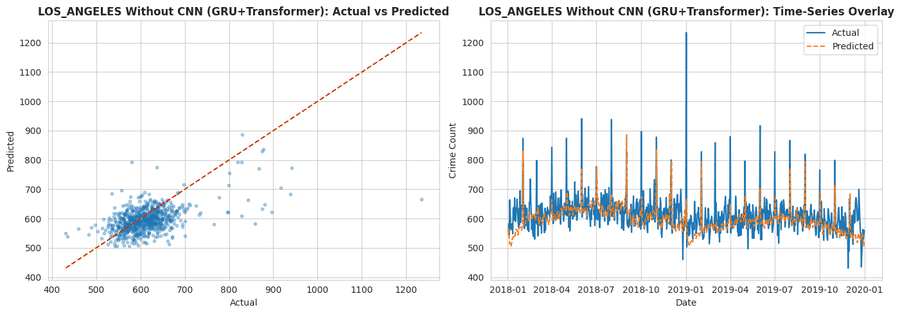


Hybrid Ablation: los_angeles — With CNN+GRU
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4865 - val_loss: 0.5225 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5017 - val_loss: 0.4325 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4500 - val_loss: 0.4011 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4537 - val_loss: 0.3620 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4330 - val_loss: 0.3858 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4305 - val_loss: 0.3551 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4189 - val_loss: 0.3502 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4278 - val_loss: 0.3459 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4085 - val_loss: 0.3400 - lear

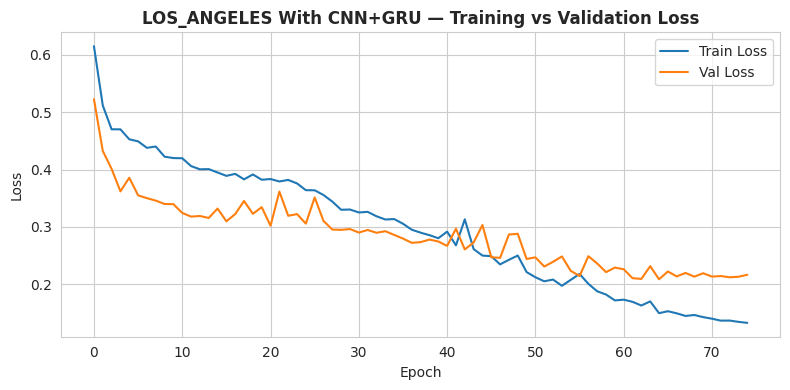

LOS_ANGELES With CNN+GRU
Stopped at epoch 75
Final train loss: 0.132988
Final val loss: 0.216717
Ratio (val/train): 1.63
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


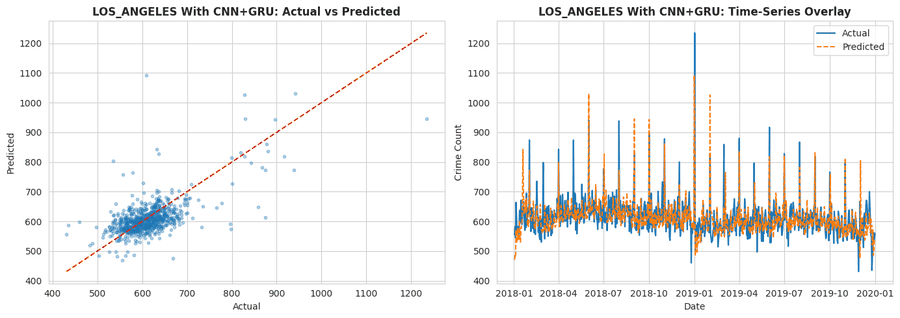


Hybrid Ablation: los_angeles — With CNN+LSTM
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4912 - val_loss: 0.4905 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5216 - val_loss: 0.4490 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4824 - val_loss: 0.3672 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4575 - val_loss: 0.3895 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4402 - val_loss: 0.3611 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4283 - val_loss: 0.3759 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4245 - val_loss: 0.3697 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4259 - val_loss: 0.3499 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4117 - val_loss: 0.3610 - lea

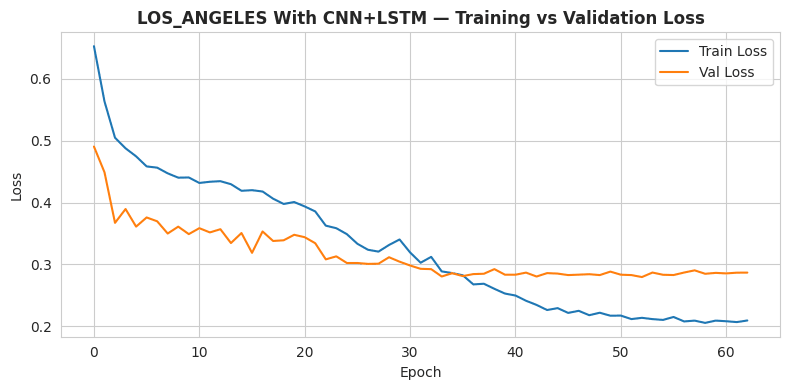

LOS_ANGELES With CNN+LSTM
Stopped at epoch 63
Final train loss: 0.209266
Final val loss: 0.286716
Ratio (val/train): 1.37
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


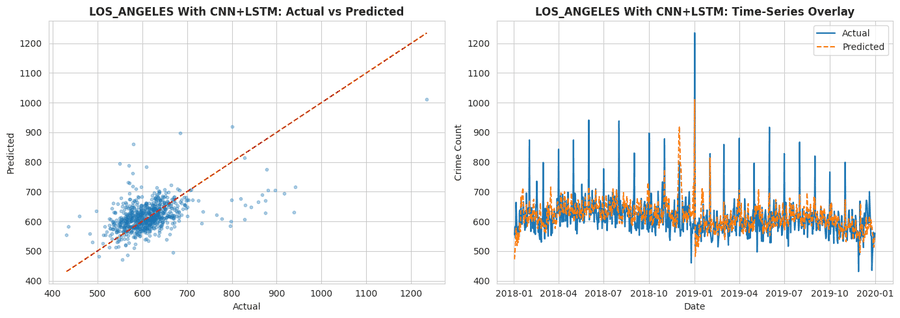


Hybrid Ablation: los_angeles — With CNN+GRU+Transformer
Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 1.7493 - val_loss: 1.6464 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.8007 - val_loss: 0.8177 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.6128 - val_loss: 0.4384 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5283 - val_loss: 0.4115 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4930 - val_loss: 0.5168 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4799 - val_loss: 0.4878 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4671 - val_loss: 0.4069 - learning_rate: 0.0010
Epoch 8/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4576 - val_loss: 0.4061 - learning_rate: 0.0010
Epoch 9/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.4579 - val

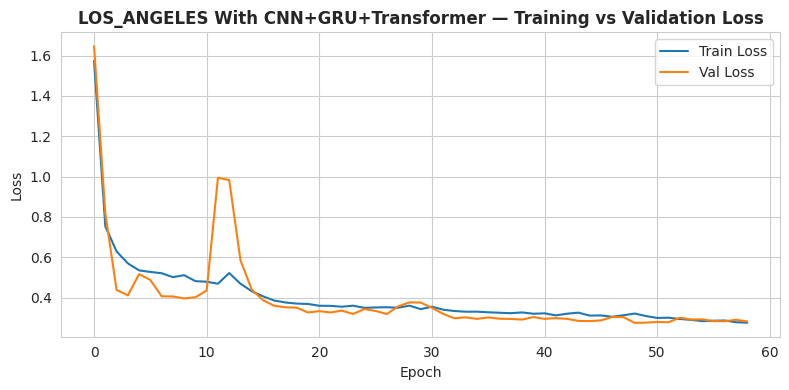

LOS_ANGELES With CNN+GRU+Transformer
Stopped at epoch 59
Final train loss: 0.275800
Final val loss: 0.282026
Ratio (val/train): 1.02
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


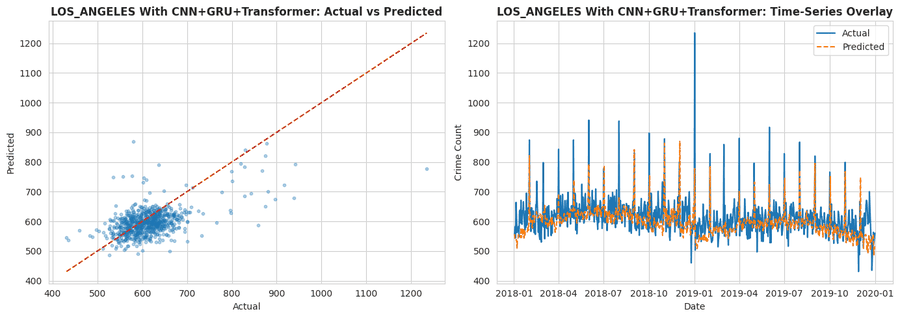


CNN Ablation: los_angeles — CNN_baseline_L14_2layers | look_back=14, conv_layers=2
Epoch 1/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.4771 - val_loss: 0.5338 - learning_rate: 0.0010
Epoch 2/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5238 - val_loss: 0.4585 - learning_rate: 0.0010
Epoch 3/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4483 - val_loss: 0.4523 - learning_rate: 0.0010
Epoch 4/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4480 - val_loss: 0.4309 - learning_rate: 0.0010
Epoch 5/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4427 - val_loss: 0.4311 - learning_rate: 0.0010
Epoch 6/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4343 - val_loss: 0.4124 - learning_rate: 0.0010
Epoch 7/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4281 - val_loss: 0.4198 - learning_rate: 0.0010
Epoch 8/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4282 - val_loss: 0.4385 - learning_rate: 0.0010
Epoch 9/35
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

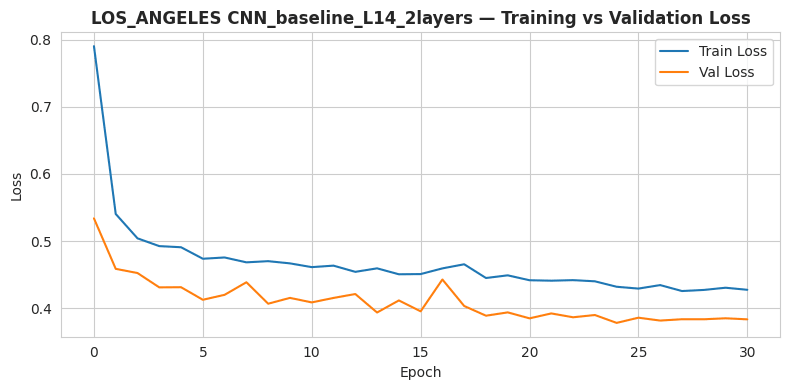

LOS_ANGELES CNN_baseline_L14_2layers
Stopped at epoch 31
Final train loss: 0.427291
Final val loss: 0.383251
Ratio (val/train): 0.90
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


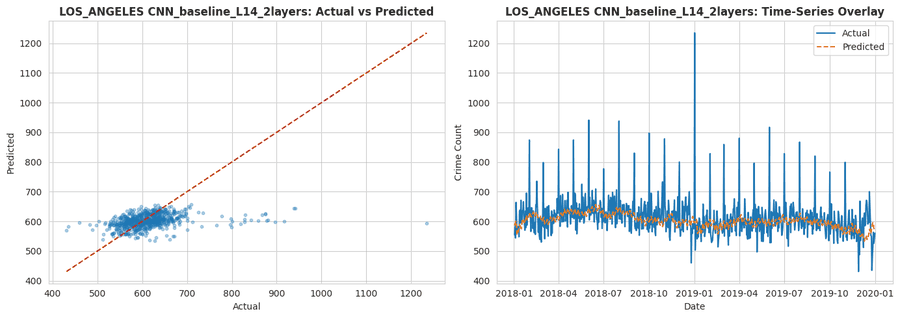


CNN Ablation: los_angeles — CNN_baseline_L30_2layers | look_back=30, conv_layers=2
Epoch 1/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.4898 - val_loss: 0.7577 - learning_rate: 0.0010
Epoch 2/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4878 - val_loss: 0.4476 - learning_rate: 0.0010
Epoch 3/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4427 - val_loss: 0.4531 - learning_rate: 0.0010
Epoch 4/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4410 - val_loss: 0.4901 - learning_rate: 0.0010
Epoch 5/35
71/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4357
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4408 - val_loss: 0.5127 - learning_rate: 0.0010
Epoch 6/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4467 - val_loss: 0.5001 - learning_rate: 5.0000e-04
Epoch 7/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4338 - val_loss: 0.4491 - learning_rate: 5.0000e-04
Epoch 8/35
71/77 ━━━━

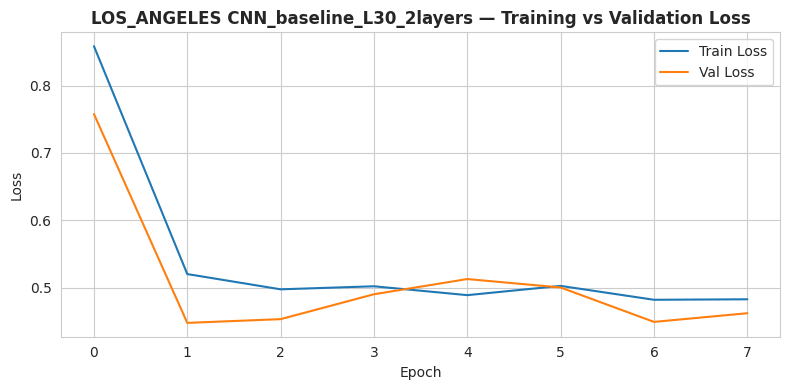

LOS_ANGELES CNN_baseline_L30_2layers
Stopped at epoch 8
Final train loss: 0.482633
Final val loss: 0.461934
Ratio (val/train): 0.96
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


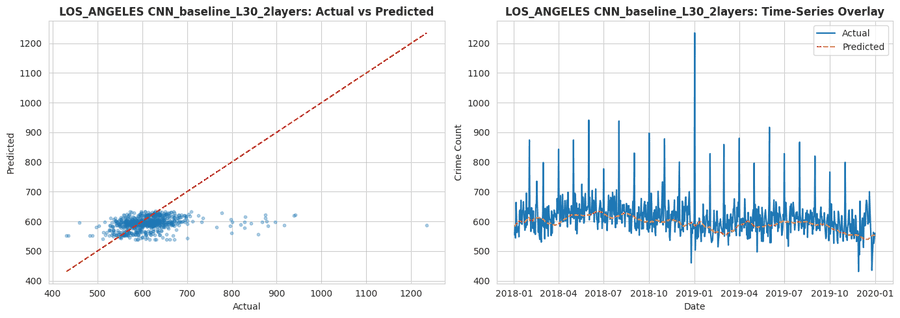


CNN Ablation: los_angeles — CNN_baseline_L60_2layers | look_back=60, conv_layers=2
Epoch 1/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.5089 - val_loss: 1.1159 - learning_rate: 0.0010
Epoch 2/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4934 - val_loss: 0.4940 - learning_rate: 0.0010
Epoch 3/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5120 - val_loss: 0.5662 - learning_rate: 0.0010
Epoch 4/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5280 - val_loss: 0.7579 - learning_rate: 0.0010
Epoch 5/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4630 - val_loss: 0.4546 - learning_rate: 0.0010
Epoch 6/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4626 - val_loss: 0.4567 - learning_rate: 0.0010
Epoch 7/35
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4578 - val_loss: 0.4587 - learning_rate: 0.0010
Epoch 8/35
70/76 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4518
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
76/76 ━━━━━━━━━━━━

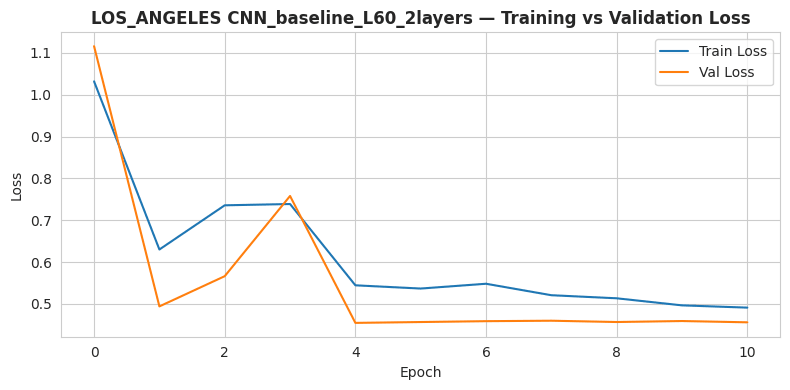

LOS_ANGELES CNN_baseline_L60_2layers
Stopped at epoch 11
Final train loss: 0.491074
Final val loss: 0.455976
Ratio (val/train): 0.93
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


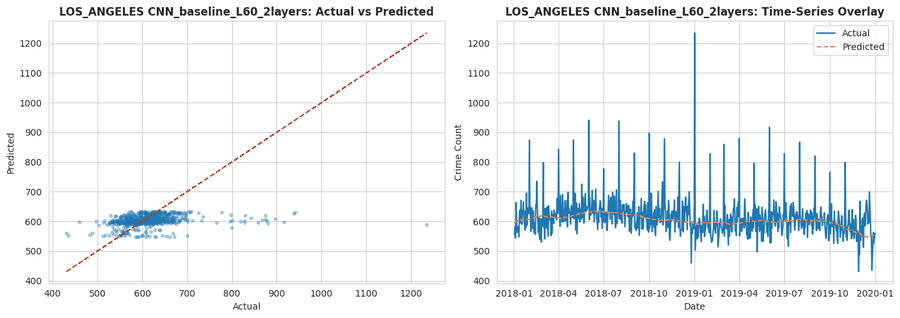


CNN Ablation: los_angeles — CNN_depth1_L30 | look_back=30, conv_layers=1
Epoch 1/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.4754 - val_loss: 0.5209 - learning_rate: 0.0010
Epoch 2/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4791 - val_loss: 0.4516 - learning_rate: 0.0010
Epoch 3/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4547 - val_loss: 0.4868 - learning_rate: 0.0010
Epoch 4/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4527 - val_loss: 0.4587 - learning_rate: 0.0010
Epoch 5/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4423 - val_loss: 0.4393 - learning_rate: 0.0010
Epoch 6/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4429 - val_loss: 0.4506 - learning_rate: 0.0010
Epoch 7/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4370 - val_loss: 0.4490 - learning_rate: 0.0010
Epoch 8/35
73/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4417
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0

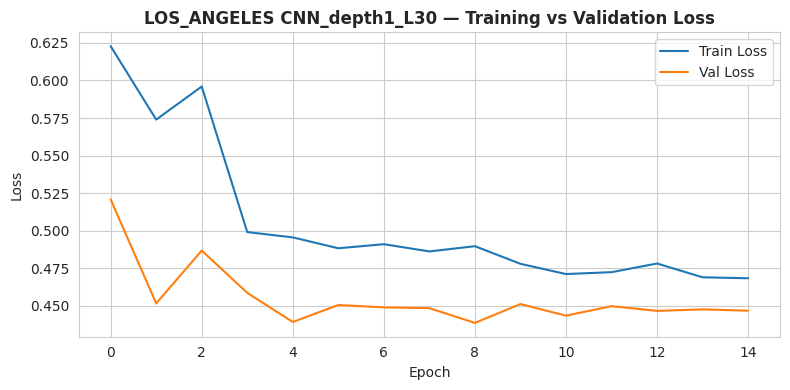

LOS_ANGELES CNN_depth1_L30
Stopped at epoch 15
Final train loss: 0.468368
Final val loss: 0.446770
Ratio (val/train): 0.95
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


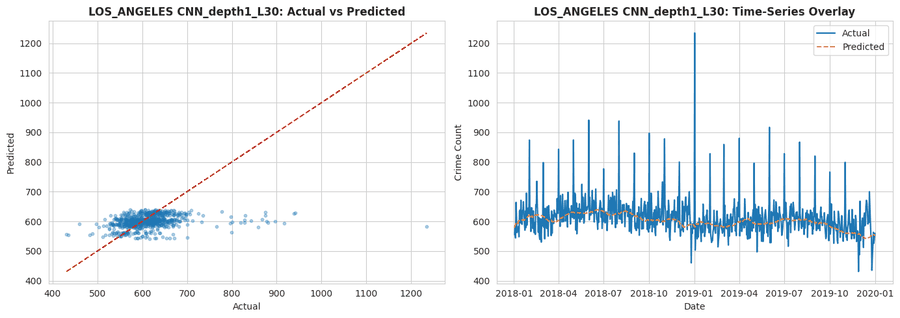


CNN Ablation: los_angeles — CNN_depth2_L30 | look_back=30, conv_layers=2
Epoch 1/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.4770 - val_loss: 0.5317 - learning_rate: 0.0010
Epoch 2/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4776 - val_loss: 0.4421 - learning_rate: 0.0010
Epoch 3/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4461 - val_loss: 0.5054 - learning_rate: 0.0010
Epoch 4/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4669 - val_loss: 0.4805 - learning_rate: 0.0010
Epoch 5/35
69/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4555
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4703 - val_loss: 0.4546 - learning_rate: 0.0010
Epoch 6/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4394 - val_loss: 0.4569 - learning_rate: 5.0000e-04
Epoch 7/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4399 - val_loss: 0.4418 - learning_rate: 5.0000e-04
Epoch 8/35
77/77 ━━━━━━━━━━━━━━

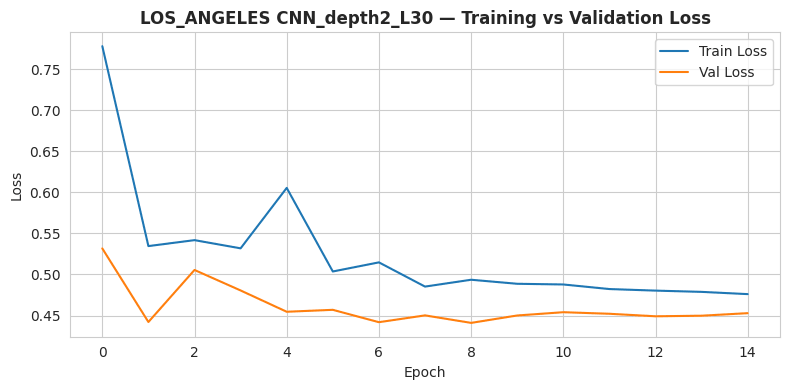

LOS_ANGELES CNN_depth2_L30
Stopped at epoch 15
Final train loss: 0.476033
Final val loss: 0.452848
Ratio (val/train): 0.95
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


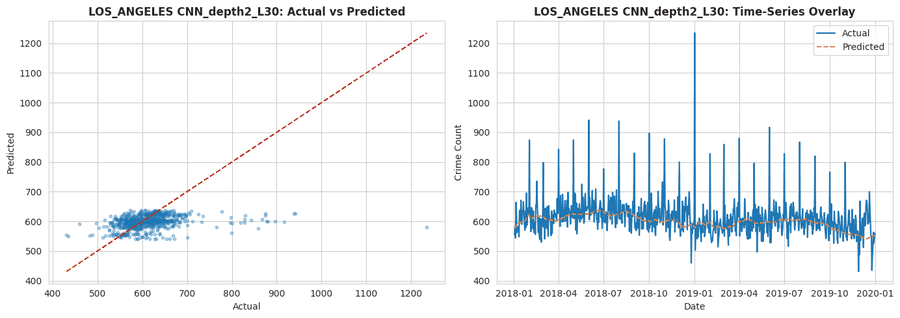


CNN Ablation: los_angeles — CNN_depth3_L30 | look_back=30, conv_layers=3
Epoch 1/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.4940 - val_loss: 1.1151 - learning_rate: 0.0010
Epoch 2/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4704 - val_loss: 0.6182 - learning_rate: 0.0010
Epoch 3/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4697 - val_loss: 0.4575 - learning_rate: 0.0010
Epoch 4/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4330 - val_loss: 0.4569 - learning_rate: 0.0010
Epoch 5/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4342 - val_loss: 0.4742 - learning_rate: 0.0010
Epoch 6/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4284 - val_loss: 0.4658 - learning_rate: 0.0010
Epoch 7/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4097 - val_loss: 0.4115 - learning_rate: 0.0010
Epoch 8/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3941 - val_loss: 0.4332 - learning_rate: 0.0010
Epoch 9/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3

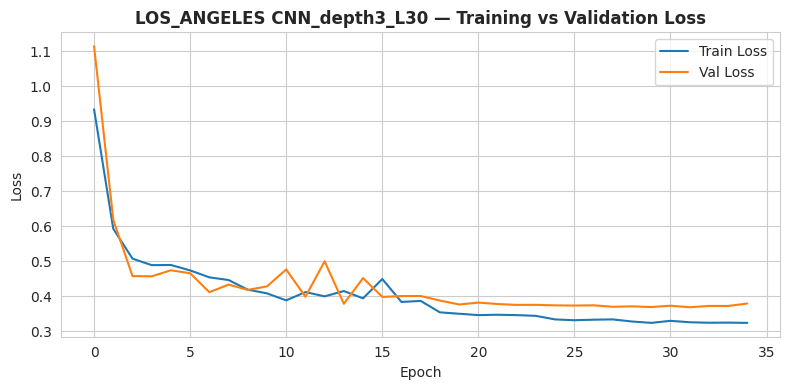

LOS_ANGELES CNN_depth3_L30
Stopped at epoch 35
Final train loss: 0.323752
Final val loss: 0.379123
Ratio (val/train): 1.17
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


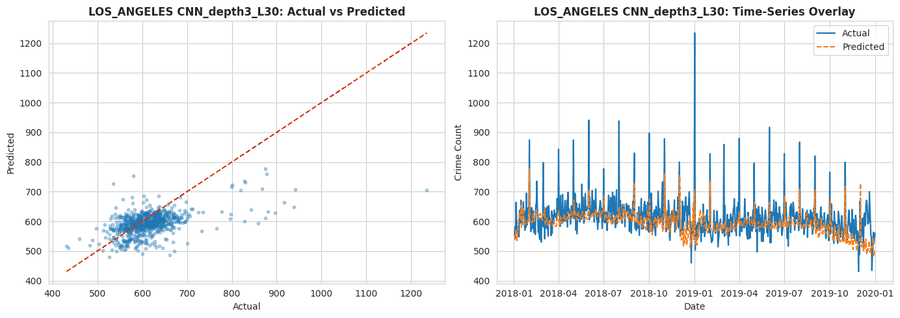


Saved ablation tables for los_angeles


,City,Model,Ablation_Group,Look_Back,Conv_Layers,RMSE,MAE,MedAE,R2,Explained_Variance,...,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,los_angeles,Without CNN (GRU+Transformer),Hybrid_Architecture,NaN,NaN,58.153123,40.143391,30.084717,0.144603,0.219727,...,9.476909,6.321663,6.488046,6.541958,0.754470,80,0.286567,0.219403,0.765626,Healthy
1,los_angeles,With CNN+GRU,Hybrid_Architecture,NaN,NaN,52.708158,35.558870,26.746399,0.297288,0.302106,...,8.589572,5.724142,5.694015,5.794842,0.668307,75,0.132988,0.216717,1.629597,Healthy
2,los_angeles,With CNN+LSTM,Hybrid_Architecture,NaN,NaN,57.623564,39.621255,29.568420,0.160111,0.164595,...,9.390610,6.369365,6.293413,6.456868,0.744657,63,0.209266,0.286716,1.370099,Healthy
3,los_angeles,With CNN+GRU+Transformer,Hybrid_Architecture,NaN,NaN,57.195121,40.312526,30.959839,0.172554,0.242852,...,9.320789,6.388132,6.513942,6.569521,0.757649,59,0.275800,0.282026,1.022574,Healthy
4,los_angeles,CNN_baseline_L14_2layers,CNN_Baseline,14.0,2.0,61.044367,37.158898,26.045532,0.057432,0.093723,...,9.948080,5.745153,5.912413,6.055591,0.698378,31,0.427291,0.383251,0.896932,Healthy
5,los_angeles,CNN_baseline_L30_2layers,CNN_Baseline,30.0,2.0,64.339405,39.494585,27.689819,-0.047070,0.059786,...,10.485055,6.042807,6.303299,6.436225,0.742276,8,0.482633,0.461934,0.957111,Healthy
6,los_angeles,CNN_baseline_L60_2layers,CNN_Baseline,60.0,2.0,61.619629,37.372240,27.051758,0.039583,0.066623,...,10.041828,5.781541,5.943444,6.090358,0.702388,11,0.491074,0.455976,0.928528,Healthy
7,los_angeles,CNN_depth1_L30,CNN_Baseline,30.0,1.0,62.525438,37.935309,26.349915,0.011140,0.055865,...,10.189442,5.845575,6.038898,6.182118,0.712970,15,0.468368,0.446770,0.953886,Healthy
8,los_angeles,CNN_depth2_L30,CNN_Baseline,30.0,2.0,62.753670,38.006269,26.047119,0.003907,0.060071,...,10.226636,5.843934,6.051760,6.193682,0.714304,15,0.476033,0.452848,0.951296,Healthy
9,los_angeles,CNN_depth3_L30,CNN_Baseline,30.0,3.0,59.087417,40.571756,30.645752,0.116897,0.233619,...,9.629166,6.341152,6.558717,6.611766,0.762521,35,0.323752,0.379123,1.171030,Healthy



Hybrid Ablation: new_york — Without CNN (GRU+Transformer)
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 1.5853 - val_loss: 2.0036 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.2777 - val_loss: 0.4348 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.1938 - val_loss: 0.2179 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.8432 - val_loss: 0.2520 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.6255 - val_loss: 0.2475 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5578 - val_loss: 0.2059 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5469 - val_loss: 0.2009 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4864 - val_loss: 0.2636 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4625 - v

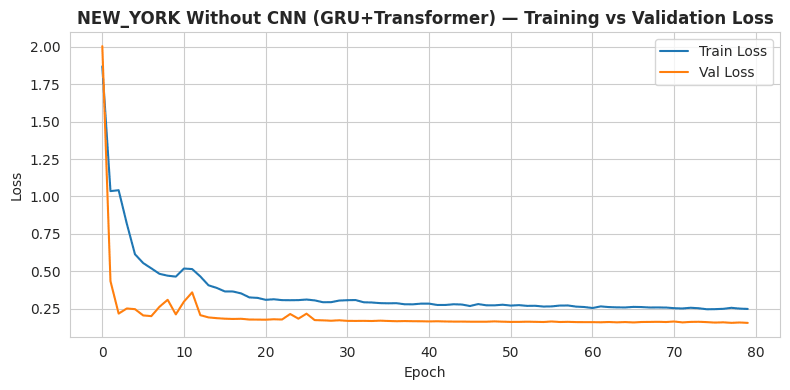

NEW_YORK Without CNN (GRU+Transformer)
Stopped at epoch 80
Final train loss: 0.248987
Final val loss: 0.155868
Ratio (val/train): 0.63
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


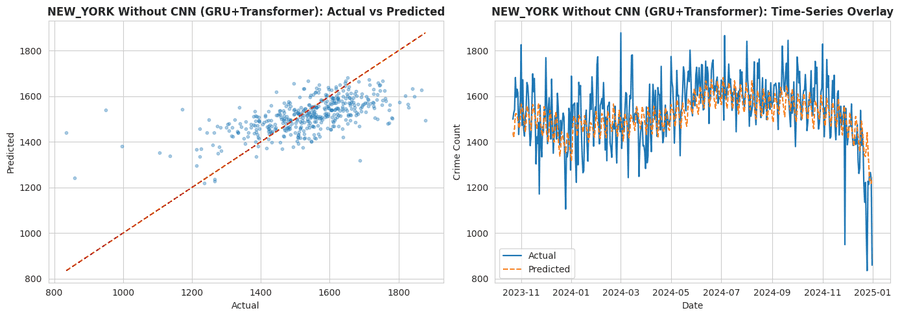


Hybrid Ablation: new_york — With CNN+GRU
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.7316 - val_loss: 0.1734 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4084 - val_loss: 0.1657 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3602 - val_loss: 0.2226 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3468 - val_loss: 0.1628 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3164 - val_loss: 0.1451 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2889 - val_loss: 0.1508 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2844 - val_loss: 0.1418 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2728 - val_loss: 0.1547 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2702 - val_loss: 0.1645 - learnin

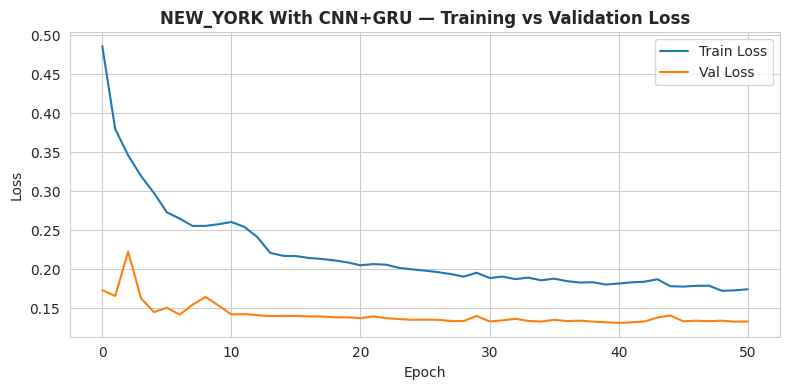

NEW_YORK With CNN+GRU
Stopped at epoch 51
Final train loss: 0.174340
Final val loss: 0.133154
Ratio (val/train): 0.76
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


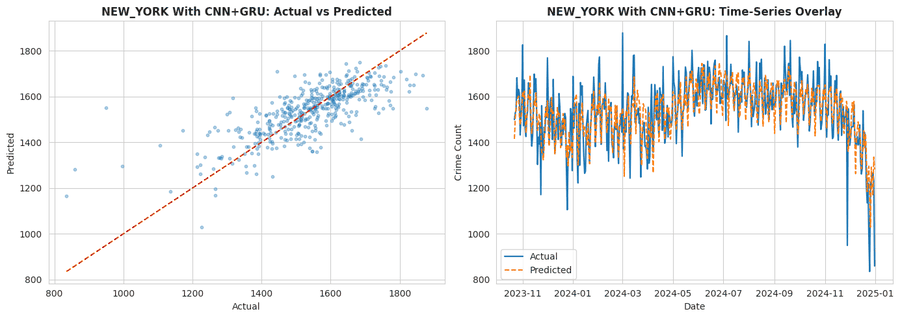


Hybrid Ablation: new_york — With CNN+LSTM
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.5486 - val_loss: 0.1999 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4001 - val_loss: 0.1612 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3719 - val_loss: 0.2219 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3417 - val_loss: 0.1550 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3188 - val_loss: 0.1519 - learning_rate: 0.0010
Epoch 6/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3000 - val_loss: 0.1497 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2965 - val_loss: 0.1499 - learning_rate: 0.0010
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2943 - val_loss: 0.1456 - learning_rate: 0.0010
Epoch 9/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2964 - val_loss: 0.1420 - learni

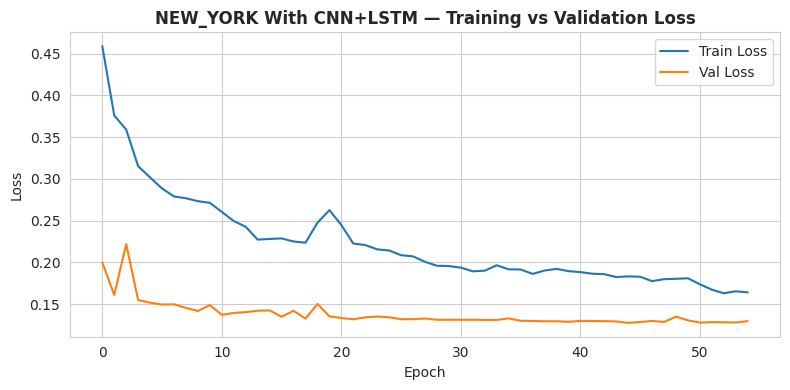

NEW_YORK With CNN+LSTM
Stopped at epoch 55
Final train loss: 0.164194
Final val loss: 0.129815
Ratio (val/train): 0.79
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


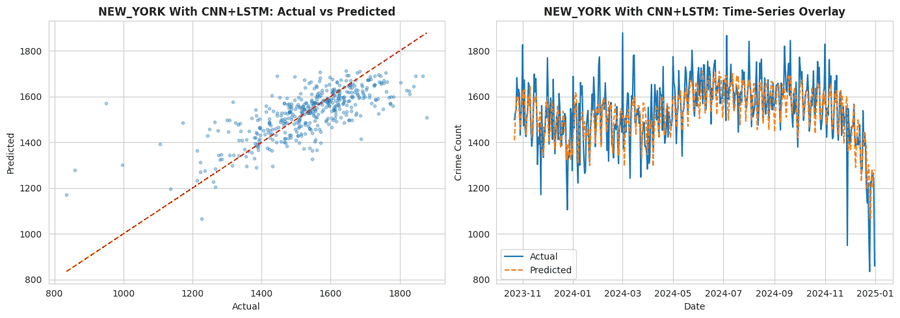


Hybrid Ablation: new_york — With CNN+GRU+Transformer
Epoch 1/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 2.0607 - val_loss: 0.3190 - learning_rate: 0.0010
Epoch 2/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.0752 - val_loss: 0.3380 - learning_rate: 0.0010
Epoch 3/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.3814 - val_loss: 0.3643 - learning_rate: 0.0010
Epoch 4/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.2698 - val_loss: 0.3956 - learning_rate: 0.0010
Epoch 5/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.3957 - val_loss: 0.3676 - learning_rate: 0.0010
Epoch 6/80
42/46 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.3569
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.3244 - val_loss: 0.4069 - learning_rate: 0.0010
Epoch 7/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0379 - val_loss: 0.3286 - learning_rate: 5.0000e-04
Epoch 8/80
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/st

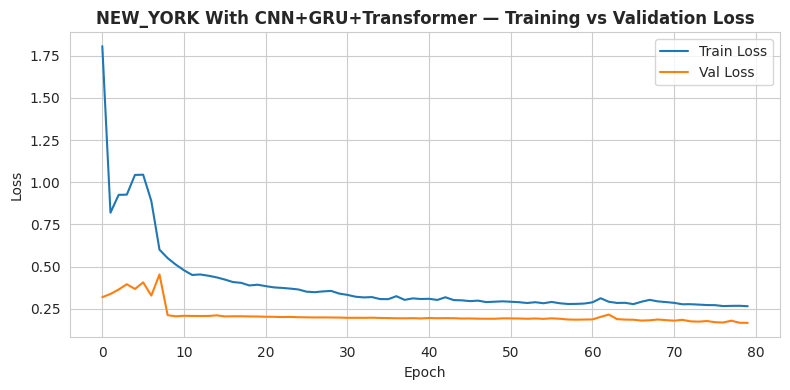

NEW_YORK With CNN+GRU+Transformer
Stopped at epoch 80
Final train loss: 0.265424
Final val loss: 0.166717
Ratio (val/train): 0.63
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


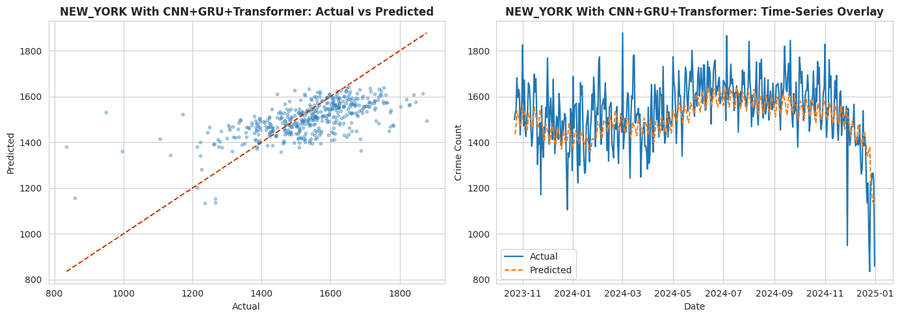


CNN Ablation: new_york — CNN_baseline_L14_2layers | look_back=14, conv_layers=2
Epoch 1/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 0.5778 - val_loss: 0.2118 - learning_rate: 0.0010
Epoch 2/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4338 - val_loss: 0.2412 - learning_rate: 0.0010
Epoch 3/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3673 - val_loss: 0.2132 - learning_rate: 0.0010
Epoch 4/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3491 - val_loss: 0.1979 - learning_rate: 0.0010
Epoch 5/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3515 - val_loss: 0.1990 - learning_rate: 0.0010
Epoch 6/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3517 - val_loss: 0.1873 - learning_rate: 0.0010
Epoch 7/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3412 - val_loss: 0.1845 - learning_rate: 0.0010
Epoch 8/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3503 - val_loss: 0.2050 - learning_rate: 0.0010
Epoch 9/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - lo

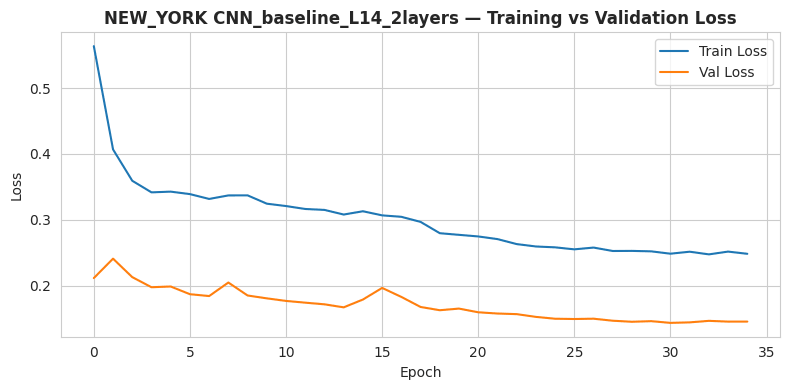

NEW_YORK CNN_baseline_L14_2layers
Stopped at epoch 35
Final train loss: 0.248589
Final val loss: 0.145840
Ratio (val/train): 0.59
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


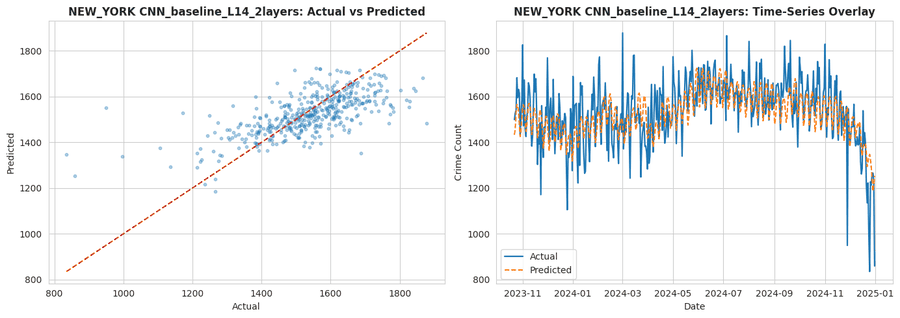


CNN Ablation: new_york — CNN_baseline_L30_2layers | look_back=30, conv_layers=2
Epoch 1/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.5976 - val_loss: 0.2451 - learning_rate: 0.0010
Epoch 2/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5206 - val_loss: 0.1959 - learning_rate: 0.0010
Epoch 3/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4071 - val_loss: 0.2317 - learning_rate: 0.0010
Epoch 4/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4036 - val_loss: 0.2081 - learning_rate: 0.0010
Epoch 5/35
24/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3711 
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3926 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 6/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3911 - val_loss: 0.2002 - learning_rate: 5.0000e-04
Epoch 7/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3930 - val_loss: 0.1960 - learning_rate: 5.0000e-04
Epoch 8/35
46/46 ━━━━━━

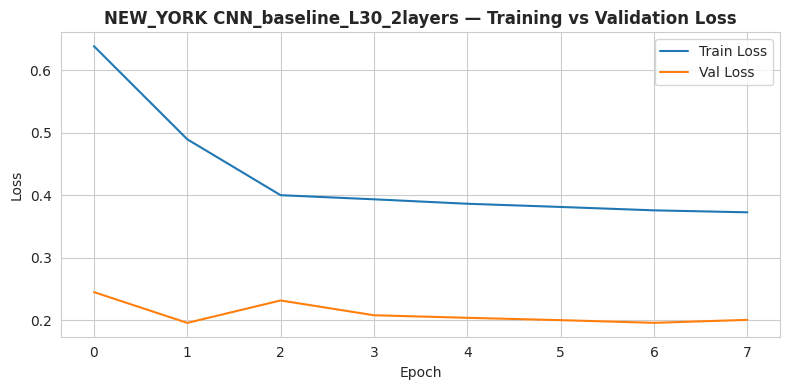

NEW_YORK CNN_baseline_L30_2layers
Stopped at epoch 8
Final train loss: 0.372777
Final val loss: 0.200676
Ratio (val/train): 0.54
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


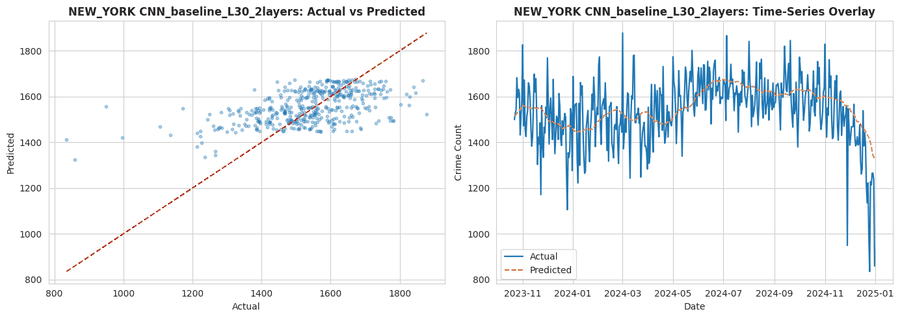


CNN Ablation: new_york — CNN_baseline_L60_2layers | look_back=60, conv_layers=2
Epoch 1/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.5983 - val_loss: 0.2184 - learning_rate: 0.0010
Epoch 2/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5887 - val_loss: 0.2486 - learning_rate: 0.0010
Epoch 3/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5087 - val_loss: 0.2597 - learning_rate: 0.0010
Epoch 4/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4864 - val_loss: 0.2073 - learning_rate: 0.0010
Epoch 5/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4760 - val_loss: 0.2236 - learning_rate: 0.0010
Epoch 6/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4661 - val_loss: 0.2489 - learning_rate: 0.0010
Epoch 7/35
23/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4425 
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4642 - val_loss: 0.2097 - learning_rate: 0.0010
Epoch 8/35
45/45 ━━━━━━━━━━━━━━

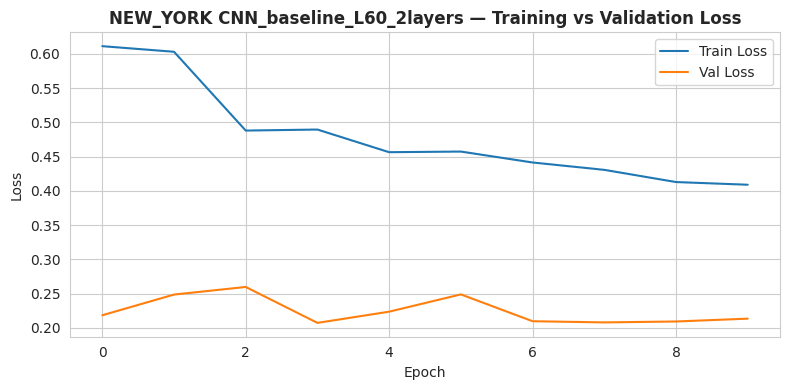

NEW_YORK CNN_baseline_L60_2layers
Stopped at epoch 10
Final train loss: 0.409010
Final val loss: 0.213461
Ratio (val/train): 0.52
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


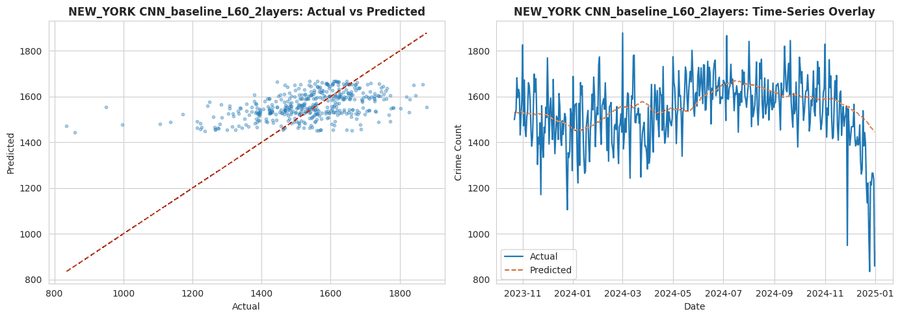


CNN Ablation: new_york — CNN_depth1_L30 | look_back=30, conv_layers=1
Epoch 1/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.6718 - val_loss: 0.2045 - learning_rate: 0.0010
Epoch 2/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4181 - val_loss: 0.2075 - learning_rate: 0.0010
Epoch 3/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4105 - val_loss: 0.2128 - learning_rate: 0.0010
Epoch 4/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4109 - val_loss: 0.2002 - learning_rate: 0.0010
Epoch 5/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4114 - val_loss: 0.2026 - learning_rate: 0.0010
Epoch 6/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3996 - val_loss: 0.1968 - learning_rate: 0.0010
Epoch 7/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3954 - val_loss: 0.1988 - learning_rate: 0.0010
Epoch 8/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4038 - val_loss: 0.1937 - learning_rate: 0.0010
Epoch 9/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3821

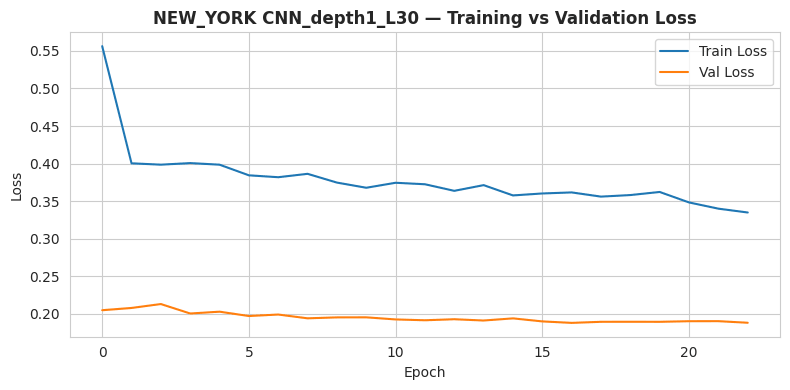

NEW_YORK CNN_depth1_L30
Stopped at epoch 23
Final train loss: 0.334748
Final val loss: 0.187830
Ratio (val/train): 0.56
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


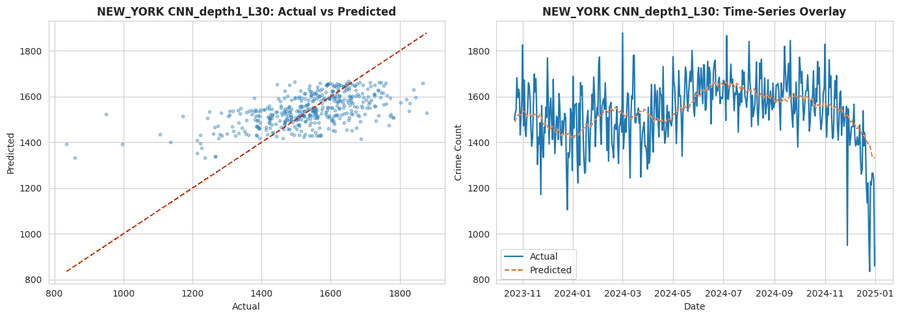


CNN Ablation: new_york — CNN_depth2_L30 | look_back=30, conv_layers=2
Epoch 1/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.6019 - val_loss: 0.2489 - learning_rate: 0.0010
Epoch 2/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5323 - val_loss: 0.2359 - learning_rate: 0.0010
Epoch 3/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4243 - val_loss: 0.2363 - learning_rate: 0.0010
Epoch 4/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4030 - val_loss: 0.2000 - learning_rate: 0.0010
Epoch 5/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3980 - val_loss: 0.1953 - learning_rate: 0.0010
Epoch 6/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4013 - val_loss: 0.1989 - learning_rate: 0.0010
Epoch 7/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3819 - val_loss: 0.2011 - learning_rate: 0.0010
Epoch 8/35
24/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3717 
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 

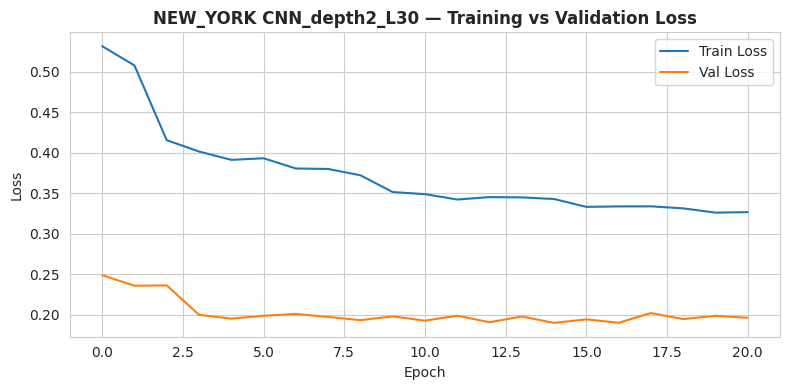

NEW_YORK CNN_depth2_L30
Stopped at epoch 21
Final train loss: 0.326638
Final val loss: 0.196387
Ratio (val/train): 0.60
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


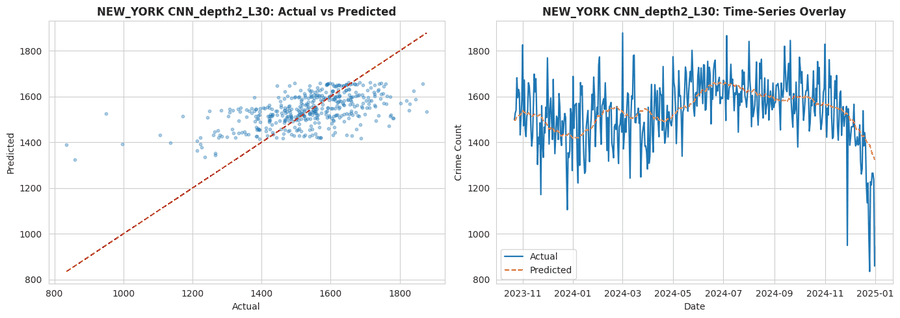


CNN Ablation: new_york — CNN_depth3_L30 | look_back=30, conv_layers=3
Epoch 1/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - loss: 0.8034 - val_loss: 0.1951 - learning_rate: 0.0010
Epoch 2/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6839 - val_loss: 0.2113 - learning_rate: 0.0010
Epoch 3/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4770 - val_loss: 0.2096 - learning_rate: 0.0010
Epoch 4/35
40/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4664
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4645 - val_loss: 0.2013 - learning_rate: 0.0010
Epoch 5/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4262 - val_loss: 0.1953 - learning_rate: 5.0000e-04
Epoch 6/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4094 - val_loss: 0.2024 - learning_rate: 5.0000e-04
Epoch 7/35
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4181 - val_loss: 0.1944 - learning_rate: 5.0000e-04
Epoch 8/35
46/46 ━━━━━━━━━━━━━

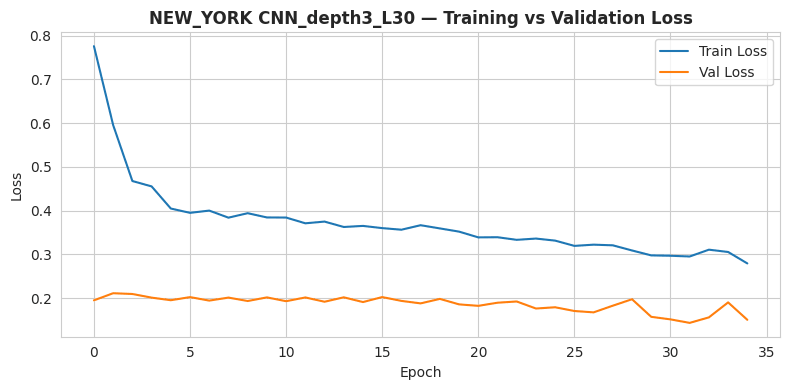

NEW_YORK CNN_depth3_L30
Stopped at epoch 35
Final train loss: 0.279402
Final val loss: 0.150560
Ratio (val/train): 0.54
Healthy: ratio should usually be reasonably close to 1 (not extremely tiny).


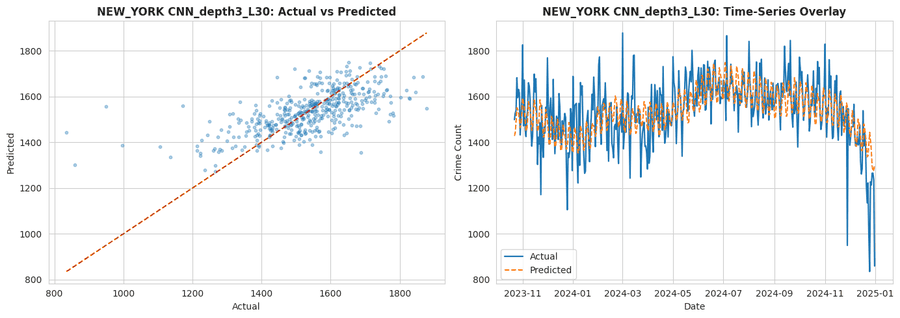


Saved ablation tables for new_york


,City,Model,Ablation_Group,Look_Back,Conv_Layers,RMSE,MAE,MedAE,R2,Explained_Variance,...,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,new_york,Without CNN (GRU+Transformer),Hybrid_Architecture,NaN,NaN,115.325617,86.198674,71.070679,0.354645,0.378318,...,7.508312,5.800816,5.737738,5.611993,0.830812,80,0.248987,0.155868,0.626008,Check overfitting/underfitting
1,new_york,With CNN+GRU,Hybrid_Architecture,NaN,NaN,96.782766,69.953222,52.632812,0.545491,0.545589,...,6.301074,4.765774,4.681144,4.554328,0.674233,51,0.174340,0.133154,0.763758,Healthy
2,new_york,With CNN+LSTM,Hybrid_Architecture,NaN,NaN,98.731668,71.191569,52.600098,0.527001,0.529965,...,6.427958,4.821085,4.746721,4.634951,0.686169,55,0.164194,0.129815,0.790621,Healthy
3,new_york,With CNN+GRU+Transformer,Hybrid_Architecture,NaN,NaN,116.943527,88.187110,68.679199,0.336411,0.391508,...,7.613647,5.876816,5.872343,5.741451,0.849977,80,0.265424,0.166717,0.628115,Check overfitting/underfitting
4,new_york,CNN_baseline_L14_2layers,CNN_Baseline,14.0,2.0,108.202652,79.121224,58.766235,0.431903,0.438670,...,7.044569,5.339751,5.257983,5.151213,0.762597,35,0.248589,0.145840,0.586671,Check overfitting/underfitting
5,new_york,CNN_baseline_L30_2layers,CNN_Baseline,30.0,2.0,123.127402,92.974044,76.064331,0.264375,0.281299,...,8.016250,6.397965,6.185348,6.053106,0.896116,8,0.372777,0.200676,0.538328,Check overfitting/underfitting
6,new_york,CNN_baseline_L60_2layers,CNN_Baseline,60.0,2.0,130.376065,98.417510,76.362549,0.175211,0.203638,...,8.488177,6.823185,6.546314,6.407505,0.948582,10,0.409010,0.213461,0.521897,Check overfitting/underfitting
7,new_york,CNN_depth1_L30,CNN_Baseline,30.0,1.0,118.455291,88.075477,69.833008,0.319143,0.319987,...,7.712071,6.020554,5.868926,5.734183,0.848901,23,0.334748,0.187830,0.561108,Check overfitting/underfitting
8,new_york,CNN_depth2_L30,CNN_Baseline,30.0,2.0,119.400026,89.175892,71.459351,0.308240,0.309071,...,7.773578,6.089712,5.940587,5.805826,0.859508,21,0.326638,0.196387,0.601235,Check overfitting/underfitting
9,new_york,CNN_depth3_L30,CNN_Baseline,30.0,3.0,110.651774,80.272442,59.892456,0.405894,0.406069,...,7.204020,5.474386,5.347057,5.226164,0.773693,35,0.279402,0.150560,0.538863,Check overfitting/underfitting


In [52]:
# CELL 47 — Run Ablation Study (OLD + NEW)

def run_hybrid_ablation_study(dl_pack, city_key):
    results = []

    for model_name, builder in HYBRID_ABLATION_MODELS.items():
        print(f"\nHybrid Ablation: {city_key} — {model_name}")

        metrics, model, pred, history = fit_predict_dl_model(
            builder,
            model_name,
            dl_pack,
            city_key
        )
        metrics["Ablation_Group"] = "Hybrid_Architecture"
        metrics["Look_Back"] = dl_pack.get("look_back", np.nan)
        metrics["Conv_Layers"] = np.nan
        results.append(metrics)

    hybrid_df = pd.DataFrame(results)
    return hybrid_df


def run_cnn_ablation_study(city_daily_feat_df, city_key, epochs=35, batch_size=32, patience=6):
    results = []

    for cfg in CNN_ONLY_ABLATION_CONFIGS:
        model_name = cfg["Model"]
        look_back = cfg["look_back"]
        n_conv_layers = cfg["n_conv_layers"]

        print(f"\nCNN Ablation: {city_key} — {model_name} | look_back={look_back}, conv_layers={n_conv_layers}")

        dl_pack = prepare_dl_data(city_daily_feat_df, look_back=look_back)
        dl_pack["look_back"] = look_back

        builder = make_cnn_builder(n_conv_layers=n_conv_layers)

        metrics, model, pred, history = fit_predict_dl_model(
            builder,
            model_name,
            dl_pack,
            city_key,
            epochs=epochs,
            batch_size=batch_size,
            patience=patience
        )

        metrics["Ablation_Group"] = "CNN_Baseline"
        metrics["Look_Back"] = look_back
        metrics["Conv_Layers"] = n_conv_layers
        results.append(metrics)

    cnn_df = pd.DataFrame(results)
    return cnn_df


def run_full_ablation_for_city(dl_pack_fixed, city_daily_feat_df, city_key):
    hybrid_df = run_hybrid_ablation_study(dl_pack_fixed, city_key)
    cnn_df = run_cnn_ablation_study(city_daily_feat_df, city_key)

    full_df = pd.concat([hybrid_df, cnn_df], ignore_index=True)

    ordered_cols = [
        "City", "Model", "Ablation_Group", "Look_Back", "Conv_Layers",
        "RMSE", "MAE", "MedAE", "R2", "Explained_Variance",
        "Mean_Actual", "NRMSE_pct", "CVRMSE_pct", "MAPE_safe",
        "sMAPE", "WAPE_pct", "MASE",
        "Stopped_Epoch", "Final_Train_Loss", "Final_Val_Loss",
        "Val_Train_Ratio", "Healthy_Comment"
    ]

    existing_cols = [c for c in ordered_cols if c in full_df.columns]
    full_df = full_df[existing_cols]

    full_df.to_csv(
        os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_full_ablation_results.csv"),
        index=False
    )

    hybrid_df.to_csv(
        os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_hybrid_ablation_results.csv"),
        index=False
    )

    cnn_df.to_csv(
        os.path.join(BASE_OUT, city_key, "tables", f"{city_key}_cnn_ablation_results.csv"),
        index=False
    )

    print(f"\nSaved ablation tables for {city_key}")
    display(full_df)

    return full_df, hybrid_df, cnn_df


# Hybrid part uses the same fixed dl_pack you were already using in notebook
chi_ablation, chi_hybrid_ablation, chi_cnn_ablation = run_full_ablation_for_city(chi_dl, chi_daily_feat, "chicago")
la_ablation, la_hybrid_ablation, la_cnn_ablation = run_full_ablation_for_city(la_dl, la_daily_feat, "los_angeles")
nyc_ablation, nyc_hybrid_ablation, nyc_cnn_ablation = run_full_ablation_for_city(nyc_dl, nyc_daily_feat, "new_york")

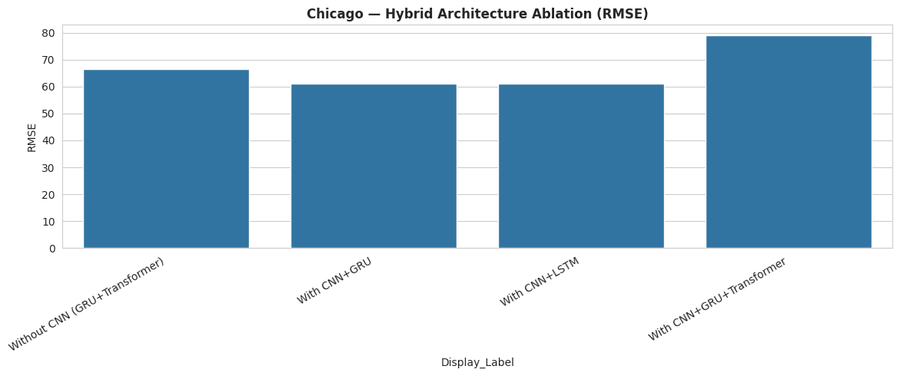

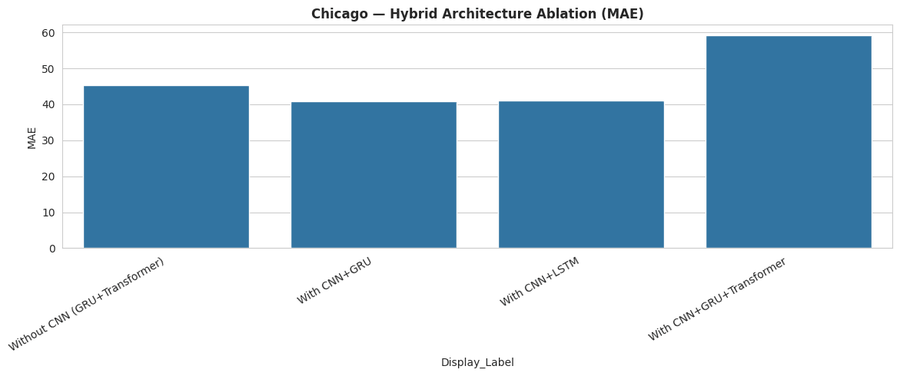

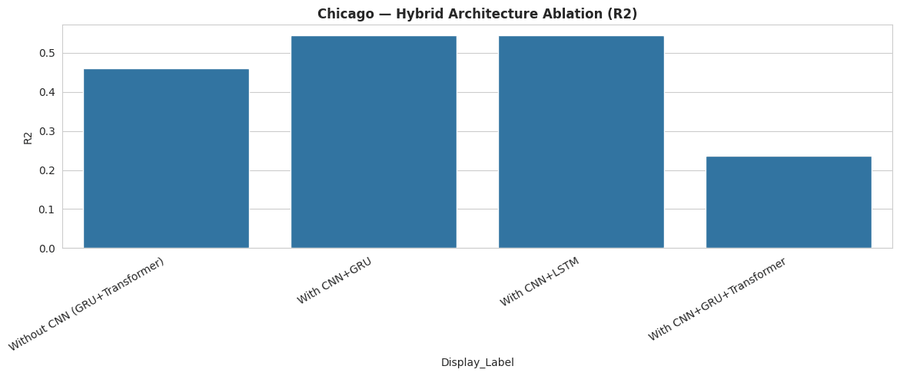

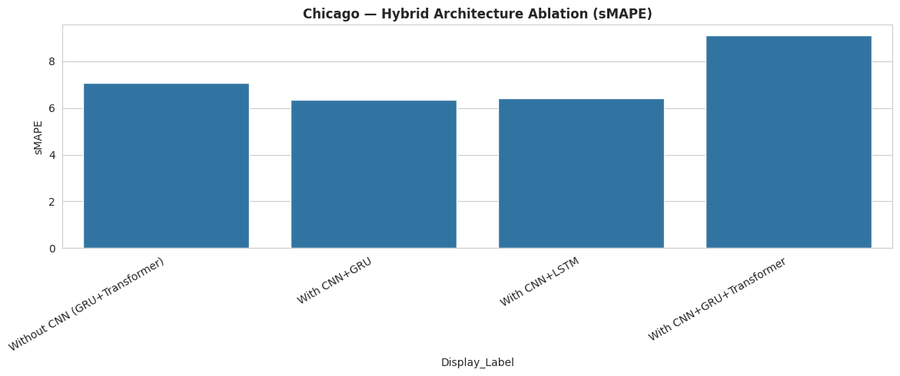

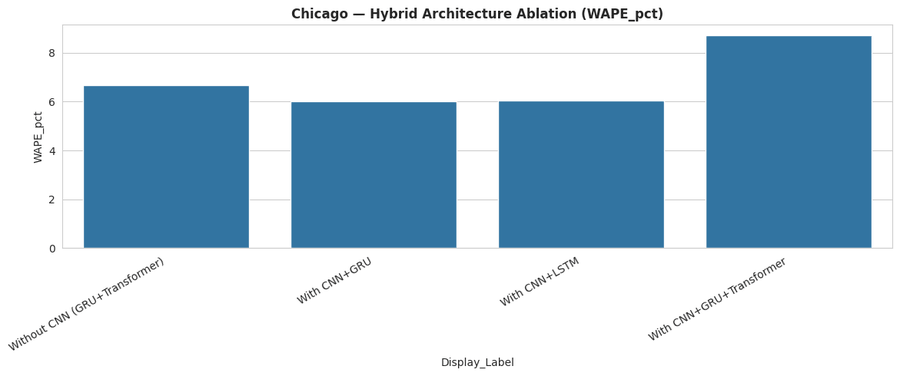

...

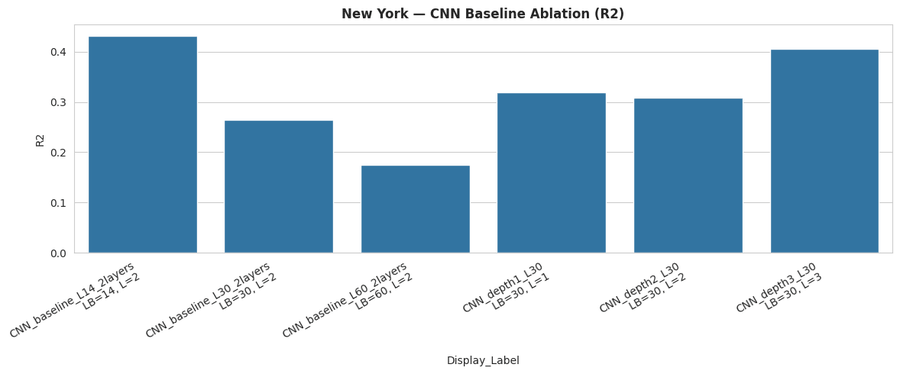

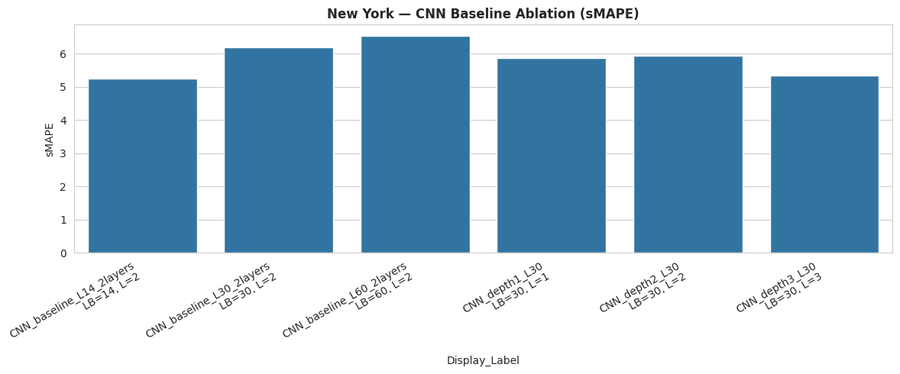

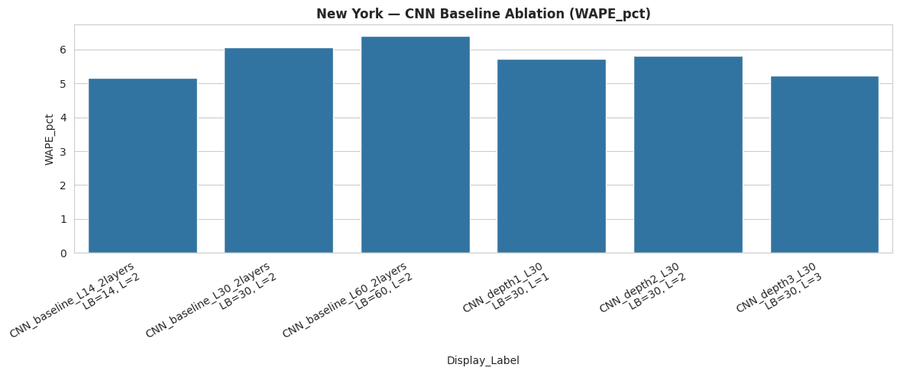

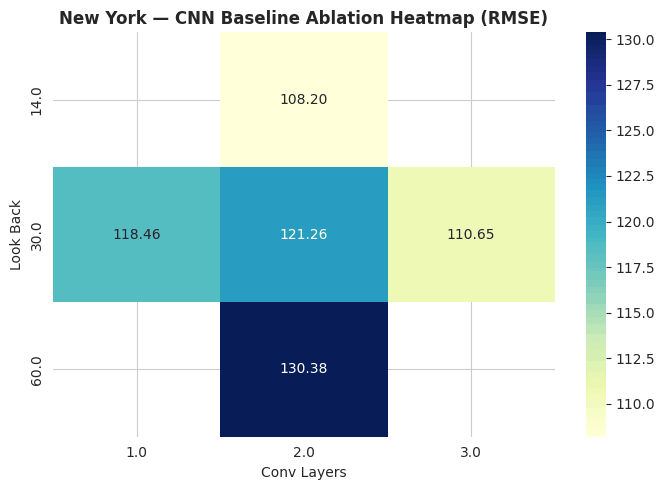

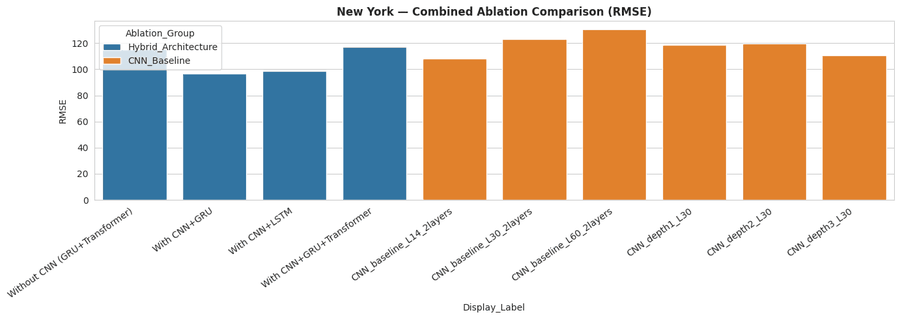

In [53]:
# CELL 48 — Plot Ablation Results (OLD + NEW)

def plot_ablation_group(ablation_df, city_key, city_title, group_name, file_tag):
    tmp = ablation_df[ablation_df["Ablation_Group"] == group_name].copy()

    if tmp.empty:
        print(f"No data found for {group_name} in {city_key}")
        return

    if group_name == "CNN_Baseline":
        tmp["Display_Label"] = (
            tmp["Model"].astype(str) +
            "\nLB=" + tmp["Look_Back"].astype("Int64").astype(str) +
            ", L=" + tmp["Conv_Layers"].astype("Int64").astype(str)
        )
    else:
        tmp["Display_Label"] = tmp["Model"].astype(str)

    for metric in ["RMSE", "MAE", "R2", "sMAPE", "WAPE_pct"]:
        plt.figure(figsize=(12, 5))
        sns.barplot(data=tmp, x="Display_Label", y=metric)
        plt.xticks(rotation=30, ha="right")
        plt.title(f"{city_title} — {group_name.replace('_', ' ')} Ablation ({metric})", fontweight="bold")
        plt.tight_layout()
        plt.savefig(
            os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_{file_tag}_{metric.lower()}.png"),
            dpi=300
        )
        plt.show()


def plot_cnn_ablation_heatmap(cnn_df, city_key, city_title):
    tmp = cnn_df[cnn_df["Ablation_Group"] == "CNN_Baseline"].copy()
    if tmp.empty:
        return

    rmse_pivot = tmp.pivot_table(
        index="Look_Back",
        columns="Conv_Layers",
        values="RMSE",
        aggfunc="mean"
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(rmse_pivot, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(f"{city_title} — CNN Baseline Ablation Heatmap (RMSE)", fontweight="bold")
    plt.xlabel("Conv Layers")
    plt.ylabel("Look Back")
    plt.tight_layout()
    plt.savefig(
        os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_cnn_ablation_rmse_heatmap.png"),
        dpi=300
    )
    plt.show()


def plot_combined_ablation_compare(ablation_df, city_key, city_title):
    tmp = ablation_df.copy()
    tmp["Display_Label"] = tmp["Model"].astype(str)

    plt.figure(figsize=(14, 5))
    sns.barplot(data=tmp, x="Display_Label", y="RMSE", hue="Ablation_Group")
    plt.xticks(rotation=35, ha="right")
    plt.title(f"{city_title} — Combined Ablation Comparison (RMSE)", fontweight="bold")
    plt.tight_layout()
    plt.savefig(
        os.path.join(BASE_OUT, city_key, "plots", f"{city_key}_combined_ablation_rmse.png"),
        dpi=300
    )
    plt.show()


# Chicago
plot_ablation_group(chi_ablation, "chicago", "Chicago", "Hybrid_Architecture", "hybrid_ablation")
plot_ablation_group(chi_ablation, "chicago", "Chicago", "CNN_Baseline", "cnn_ablation")
plot_cnn_ablation_heatmap(chi_ablation, "chicago", "Chicago")
plot_combined_ablation_compare(chi_ablation, "chicago", "Chicago")

# Los Angeles
plot_ablation_group(la_ablation, "los_angeles", "Los Angeles", "Hybrid_Architecture", "hybrid_ablation")
plot_ablation_group(la_ablation, "los_angeles", "Los Angeles", "CNN_Baseline", "cnn_ablation")
plot_cnn_ablation_heatmap(la_ablation, "los_angeles", "Los Angeles")
plot_combined_ablation_compare(la_ablation, "los_angeles", "Los Angeles")

# New York
plot_ablation_group(nyc_ablation, "new_york", "New York", "Hybrid_Architecture", "hybrid_ablation")
plot_ablation_group(nyc_ablation, "new_york", "New York", "CNN_Baseline", "cnn_ablation")
plot_cnn_ablation_heatmap(nyc_ablation, "new_york", "New York")
plot_combined_ablation_compare(nyc_ablation, "new_york", "New York")

# *PART 8 — FINAL COMPARATIVE TABLES*

In [54]:
#CELL 49 — Final Best-Model Summary
def best_row(df, metric="RMSE", ascending=True):
    return df.sort_values(metric, ascending=ascending).head(1)

best_hotspot = pd.concat([
    chi_all.sort_values(["ROC_AUC", "F1"], ascending=False).head(1),
    la_all.sort_values(["ROC_AUC", "F1"], ascending=False).head(1),
    nyc_all.sort_values(["ROC_AUC", "F1"], ascending=False).head(1)
], ignore_index=True)

best_total_forecast = pd.concat([
    chi_total_compare.sort_values("RMSE").head(1),
    la_total_compare.sort_values("RMSE").head(1),
    nyc_total_compare.sort_values("RMSE").head(1)
], ignore_index=True)

best_hotspot.to_csv(os.path.join(TABLE_DIR, "best_hotspot_models_all_cities.csv"), index=False)
best_total_forecast.to_csv(os.path.join(TABLE_DIR, "best_total_forecast_models_all_cities.csv"), index=False)

display(best_hotspot)
display(best_total_forecast)


,City,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Kappa
0,chicago,XGBoost,0.745479,0.743259,0.703233,0.725288,0.714090,0.824704,0.776322,0.485034,0.484846
1,los_angeles,XGBoost,0.784084,0.675174,0.675468,0.429874,0.525387,0.804233,0.636641,0.411318,0.394444
2,new_york,XGBoost,0.803096,0.803119,0.810001,0.793130,0.801476,0.886989,0.895724,0.606341,0.606209


,City,Model,RMSE,MAE,MedAE,R2,Explained_Variance,Mean_Actual,NRMSE_pct,CVRMSE_pct,MAPE_safe,sMAPE,WAPE_pct,MASE,Stopped_Epoch,Final_Train_Loss,Final_Val_Loss,Val_Train_Ratio,Healthy_Comment
0,chicago,LSTM,61.083530,40.913551,30.571655,0.542749,0.542856,678.906859,8.997336,8.997336,14.642355,6.358405,6.026386,0.824800,33,0.150056,0.136654,0.910688,Healthy
1,los_angeles,GRU,57.483354,38.857111,27.122070,0.164194,0.164216,613.629630,9.367761,9.367761,6.229956,6.196267,6.332339,0.730295,77,0.191117,0.279204,1.460902,Healthy
2,new_york,GRU,102.193937,73.301165,52.947266,0.493246,0.494093,1535.972540,6.653370,6.653370,4.952553,4.865619,4.772297,0.706502,46,0.210121,0.138989,0.661472,Check overfitting/underfitting


In [55]:
# CELL 50 — Save Final Notes / Interpretation File
final_notes = []
final_notes.append("Notebook successfully restructured into two parts: hotspot modelling and time-series / category forecasting.")
final_notes.append("All three datasets now use aligned preprocessing, richer EDA, and standardised evaluation.")
final_notes.append("All hotspot models now output the same metrics, including calibrated Linear SVM probabilities.")
final_notes.append("Best hotspot models are ensembled via soft voting.")
final_notes.append("SHAP analysis is added for interpretability.")
final_notes.append("DL forecasting is run on daily data; ARIMA/SARIMA on monthly data for stability.")
final_notes.append("Transformer model and ablation study are added.")
final_notes.append("Residual plots, error distributions, and actual-vs-predicted plots are included for all forecasting models.")

with open(os.path.join(REPORT_DIR, "final_notebook_notes.txt"), "w") as f:
    for line in final_notes:
        f.write(line + "\n")
print("Final notes saved.")

Final notes saved.
